
# Clinical AI Lifecycle Audit (CALA)
## A Unified Framework for Temporal and Cross-Continental Calibration Decay in ICU Mortality Prediction

**Datasets:** MIMIC-IV v2.2, eICU-CRD v2.0, Salzburg ICU Database (SICdb) v1.0.8

### Methodological contributions of CALA (operationalised across Parts 1–3)

1. **Triple-database harmonisation** into a single Common Data Model (CDM) spanning two continents and three care-delivery systems (academic US, multi-site US, single-centre European tertiary).
2. **Calibration Decay Half-Life (CDH-50)** — novel pharmacokinetics-inspired metric quantifying the temporal horizon at which a model's expected calibration error doubles relative to its development baseline.
3. **Continental Drift Coefficient (CDC)** — ratio of cross-continental calibration loss to within-continent temporal calibration loss, isolating geographic shift from temporal shift.
4. **Lifecycle Audit Stages** — a structured four-stage validation hierarchy (Development → Temporal → Multi-site → Cross-continental) with explicit calibration intent at each stage.
5. **Subgroup Decay Inequity Index (SDII)** — measures whether calibration drift is differentially distributed across protected attributes over time.
6. **Recalibration Half-Life Recovery (RHR)** — quantifies how much each recalibration strategy (Platt, isotonic, temperature scaling, beta calibration) extends a model's usable calibration lifetime in cross-continental deployment.

---

### Part 1 of 3: Data Foundations
This notebook builds the harmonised CDM cohort from all three databases. It is engineered to be memory-bounded (chunked I/O), aggressively cached (Parquet artifacts), and reproducible end-to-end. Re-runs after the first execution are near-instantaneous.

**Parts to follow**
- **Part 2:** Imputation, missingness audit (MCAR/MAR testing), model development with temporally stratified training, internal calibration assessment, SHAP interpretability.
- **Part 3:** Cross-continental external validation, calibration decay quantification, the four CALA metrics, recalibration interventions, subgroup decay analysis, publication figures and tables.

## 1.1 Environment Setup

All third-party libraries are stable, widely available, and pinned to versions compatible with Python 3.10+. We deliberately avoid frameworks (e.g., PyHealth, MIMIC-Extract) so the pipeline is fully transparent to reviewers.

In [1]:
# Core scientific stack
import os
import sys
import gc
import re
import json
import time
import hashlib
import logging
import warnings
from pathlib import Path
from dataclasses import dataclass, field, asdict
from typing import Optional, Union, Iterable, Sequence
from collections import defaultdict

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Plotting
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Statistics (used lightly in Part 1 for QC; heavy stats in Parts 2-3)
from scipy import stats

# Reproducibility and warning hygiene
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
pd.options.mode.copy_on_write = True

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Matplotlib publication defaults
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_palette('colorblind')

print(f"Python   : {sys.version.split()[0]}")
print(f"NumPy    : {np.__version__}")
print(f"Pandas   : {pd.__version__}")

C:\Users\kruta\anaconda3-v2\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Python   : 3.11.5
NumPy    : 1.24.4
Pandas   : 2.3.3


## 1.2 Logging and Reproducibility

Structured logging with timestamps. Every cached artifact is written to Parquet with a content hash recorded in a provenance ledger so reviewers can verify exact reproduction.

In [2]:
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)-7s | %(message)s',
    datefmt='%H:%M:%S',
    force=True,
)
logger = logging.getLogger('CALA')

def log_section(title: str) -> None:
    """Emit a visually separated log header."""
    bar = '=' * 74
    logger.info(bar)
    logger.info(title.upper())
    logger.info(bar)

## 1.3 Project Configuration

All paths and hyper-parameters live in a single dataclass. Adjust paths to match your local environment.

In [3]:
# >>> R1: added the revision switches below (search 'R1 revision switches').
@dataclass
class CALAConfig:
    """Central configuration for the CALA framework.

    The MIMIC-IV and eICU directory layouts on this machine use a folder-per-table
    convention where each table named ``X.csv`` is itself a directory containing
    the actual data file (e.g. ``X.csv/X.csv`` or ``X.csv/X.csv.gz``). SICdb is a
    flat layout with files at the top level. The smart_read helper handles both.
    """
    # ---- Source database roots ----
    MIMIC_ROOT: Path = Path(r"C:\mimic-iv-2.2")
    EICU_ROOT:  Path = Path(r"C:\Users\kruta\Downloads\eicu-collaborative-research-database-2.0")
    SICDB_ROOT: Path = Path(
        r"C:\Users\kruta\Downloads\salzburg-intensive-care-database-sicdb-a-freely-accessible-intensive-care-database-1.0.8"
    )

    # ---- Output root ----
    OUTPUT_ROOT: Path = Path(r"C:\CALA_Output")
    CACHE_DIR:   Path = field(init=False)
    FIGURES_DIR: Path = field(init=False)
    TABLES_DIR:  Path = field(init=False)
    PROVENANCE_FILE: Path = field(init=False)

    # ---- Cohort inclusion criteria ----
    MIN_AGE: int = 18
    MIN_ICU_LOS_HOURS: float = 24.0
    FEATURE_WINDOW_HOURS: float = 24.0

    # ---- I/O parameters ----
    CHUNK_SIZE: int = 2_000_000
    N_JOBS: int = -1
    FORCE_RECOMPUTE: bool = False

    # ---- CALA novelty toggles (for Parts 2-3, declared here for transparency) ----
    USE_TEMPORAL_SPLITS: bool = True
    USE_LIFECYCLE_AUDIT: bool = True
    RECALIBRATION_METHODS: tuple = ('platt', 'isotonic', 'temperature', 'beta')

    # >>> R1 revision switches (ACI-2026-07-RA-0294 reviewers). True = corrected pipeline.
    EICU_ADD_NIBP: bool = True          # non-invasive BP from vitalAperiodic (Reviewer 3)
    EICU_ADD_NURSE_TEMP: bool = True    # temperature from nurseCharting (Reviewer 3)
    EICU_HOURLY_VITALS: bool = True     # 5-minute vitalPeriodic -> one value per hour (Reviewer 1, comment 5)
    SICDB_CONVERT_UNITS: bool = True    # SICdb urea -> BUN and other unit checks (author re-audit)
    SICDB_INHOSP_RULE: str = 'auto'     # SICdb in-hospital death rule (Reviewer 1 comment 2; Reviewer 3)
    SICDB_PUBLISHED_INHOSP_RATE: float = 0.079   # Rodemund et al., Sci Data 2024, Table 1

    def __post_init__(self):
        self.CACHE_DIR   = self.OUTPUT_ROOT / 'cache'
        self.FIGURES_DIR = self.OUTPUT_ROOT / 'figures'
        self.TABLES_DIR  = self.OUTPUT_ROOT / 'tables'
        self.PROVENANCE_FILE = self.OUTPUT_ROOT / 'provenance.json'
        for d in (self.CACHE_DIR, self.FIGURES_DIR, self.TABLES_DIR):
            d.mkdir(parents=True, exist_ok=True)

CFG = CALAConfig()

# Sanity check that the three database roots exist on this machine
for name, p in [('MIMIC-IV', CFG.MIMIC_ROOT), ('eICU-CRD', CFG.EICU_ROOT), ('SICdb', CFG.SICDB_ROOT)]:
    exists = p.exists()
    marker = 'OK' if exists else 'MISSING'
    logger.info(f"{marker:7s} | {name:10s} | {p}")

logger.info(f"Cache   : {CFG.CACHE_DIR}")
logger.info(f"Figures : {CFG.FIGURES_DIR}")
logger.info(f"Tables  : {CFG.TABLES_DIR}")

22:54:14 | INFO    | OK      | MIMIC-IV   | C:\mimic-iv-2.2
22:54:14 | INFO    | OK      | eICU-CRD   | C:\Users\kruta\Downloads\eicu-collaborative-research-database-2.0
22:54:14 | INFO    | OK      | SICdb      | C:\Users\kruta\Downloads\salzburg-intensive-care-database-sicdb-a-freely-accessible-intensive-care-database-1.0.8
22:54:14 | INFO    | Cache   : C:\CALA_Output\cache
22:54:14 | INFO    | Figures : C:\CALA_Output\figures
22:54:14 | INFO    | Tables  : C:\CALA_Output\tables


## 1.4 Common Data Model (CDM) Specification

The CDM is the keystone of CALA: it is the single semantic substrate every database is mapped onto. We define the canonical variable list, plausible physiological ranges (used for outlier removal), and the aggregation specification (the six statistics computed per variable per ICU stay).

Variable selection follows the consensus set from prior ICU mortality literature (Johnson 2018, Sheikhalishahi 2020, Sjoding 2024) intersected with what is practically extractable across all three databases.

In [4]:
# Canonical variables and their plausible physiological ranges.
# Values outside these ranges are set to NaN before aggregation.
CDM_VITALS = {
    'heart_rate':  {'unit': 'bpm',    'low':   20, 'high':  300},
    'sbp':         {'unit': 'mmHg',   'low':   30, 'high':  300},
    'dbp':         {'unit': 'mmHg',   'low':   10, 'high':  200},
    'map':         {'unit': 'mmHg',   'low':   20, 'high':  250},
    'resp_rate':   {'unit': 'breaths/min', 'low': 4, 'high': 80},
    'temperature': {'unit': '°C',     'low':   28, 'high':   45},
    'spo2':        {'unit': '%',      'low':   40, 'high':  100},
}

CDM_LABS = {
    'wbc':        {'unit': 'K/uL',  'low':   0.1, 'high':  500},
    'hemoglobin': {'unit': 'g/dL',  'low':   2.0, 'high':   25},
    'platelets':  {'unit': 'K/uL',  'low':     5, 'high': 1500},
    'sodium':     {'unit': 'mEq/L', 'low':   110, 'high':  170},
    'potassium':  {'unit': 'mEq/L', 'low':   1.5, 'high':    9},
    'bun':        {'unit': 'mg/dL', 'low':     1, 'high':  300},
    'creatinine': {'unit': 'mg/dL', 'low':   0.1, 'high':   30},
    'glucose':    {'unit': 'mg/dL', 'low':    20, 'high': 1200},
    'lactate':    {'unit': 'mmol/L','low':   0.1, 'high':   30},
    'ph':         {'unit': 'pH',    'low':   6.5, 'high':  7.9},
    'bicarbonate':{'unit': 'mEq/L', 'low':     5, 'high':   50},
    'bilirubin':  {'unit': 'mg/dL', 'low':   0.1, 'high':   80},
}

CDM_DEMOGRAPHICS = ['age', 'sex_male', 'bmi']

# Aggregation specification: six statistics per variable on the first-24h window.
# Together with demographics this yields a 117-feature design matrix.
AGGREGATIONS = ['min', 'max', 'mean', 'last', 'std', 'count']

# Convenience: full list of CDM variables
ALL_CDM_VARS = list(CDM_VITALS.keys()) + list(CDM_LABS.keys())

print(f"CDM variables : {len(ALL_CDM_VARS)} ({len(CDM_VITALS)} vitals, {len(CDM_LABS)} labs)")
print(f"Aggregations  : {len(AGGREGATIONS)}")
print(f"Total features: {len(CDM_DEMOGRAPHICS) + len(ALL_CDM_VARS) * len(AGGREGATIONS)}")

CDM variables : 19 (7 vitals, 12 labs)
Aggregations  : 6
Total features: 117


## 1.5 Robust I/O Infrastructure

A single ``smart_read`` handles the folder-nested layout of MIMIC-IV and eICU as well as the flat layout of SICdb. Caching is content-addressed so re-runs are fast.

In [5]:
def find_data_file(path: Union[str, Path]) -> Path:
    """Return the actual file given a path that may be the file itself, a folder
    containing the file (e.g. ``admissions.csv/admissions.csv``), or a folder
    containing a compressed variant (``.csv.gz``).
    """
    p = Path(path)
    if p.is_file():
        return p
    if p.is_dir():
        for pattern in ('*.csv.gz', '*.csv', '*.parquet', '*.tsv.gz', '*.tsv', '*'):
            for candidate in sorted(p.glob(pattern)):
                if candidate.is_file() and candidate.stat().st_size > 0:
                    return candidate
    # Try sibling .gz if the bare path was provided
    for ext in ('.gz', '.csv', '.csv.gz'):
        alt = Path(str(p) + ext)
        if alt.exists() and alt.is_file():
            return alt
    raise FileNotFoundError(f"No data file resolved for: {path}")


def smart_read(path: Union[str, Path],
               usecols: Optional[Sequence[str]] = None,
               dtype: Optional[dict] = None,
               parse_dates: Optional[Sequence[str]] = None,
               nrows: Optional[int] = None,
               chunksize: Optional[int] = None,
               low_memory: bool = False,
               sep: str = ',') -> Union[pd.DataFrame, 'pd.io.parsers.TextFileReader']:
    """Format-aware reader with case-insensitive column resolution.

    Resolves the actual on-disk file via find_data_file, then dispatches to
    pd.read_csv (gz transparent) or pd.read_parquet. Column requests are
    matched case-insensitively so subtle schema-version differences do not
    crash the pipeline.
    """
    actual = find_data_file(path)
    suffix = ''.join(actual.suffixes).lower()

    if '.parquet' in suffix:
        df = pd.read_parquet(actual, columns=list(usecols) if usecols else None)
        if nrows is not None:
            df = df.head(nrows)
        return df

    # CSV / TSV / gz path. Peek at header to resolve column names case-insensitively.
    if usecols is not None:
        header = pd.read_csv(actual, nrows=0, sep=sep)
        header_lower = {c.lower(): c for c in header.columns}
        resolved = []
        for c in usecols:
            if c in header.columns:
                resolved.append(c)
            elif c.lower() in header_lower:
                resolved.append(header_lower[c.lower()])
        usecols = resolved if resolved else None

    kwargs = dict(sep=sep, low_memory=low_memory)
    if usecols:     kwargs['usecols']     = list(usecols)
    if dtype:       kwargs['dtype']       = dtype
    if parse_dates: kwargs['parse_dates'] = list(parse_dates)
    if nrows:       kwargs['nrows']       = nrows
    if chunksize:   kwargs['chunksize']   = chunksize
    return pd.read_csv(actual, **kwargs)


def normalize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Lower-case all column names. Used before merging across databases."""
    df.columns = [c.lower() for c in df.columns]
    return df


def cache_or_compute(cache_name: str, compute_fn, force: bool = False) -> pd.DataFrame:
    """Read a parquet cache or recompute and persist it."""
    force = force or CFG.FORCE_RECOMPUTE
    cache_path = CFG.CACHE_DIR / f"{cache_name}.parquet"
    if cache_path.exists() and not force:
        logger.info(f"[cache HIT ] {cache_name}")
        return pd.read_parquet(cache_path)
    logger.info(f"[cache MISS] {cache_name} -> computing")
    t0 = time.time()
    result = compute_fn()
    if isinstance(result, pd.DataFrame):
        result.to_parquet(cache_path, index=False, compression='snappy')
    logger.info(f"[cache SAVED] {cache_name}: {len(result):,} rows in {time.time()-t0:.1f}s")
    return result


def record_provenance(name: str, info: dict) -> None:
    """Append an entry to the provenance ledger."""
    ledger = {}
    if CFG.PROVENANCE_FILE.exists():
        with open(CFG.PROVENANCE_FILE) as f:
            ledger = json.load(f)
    ledger[name] = {**info, 'timestamp': datetime_iso_now()}
    with open(CFG.PROVENANCE_FILE, 'w') as f:
        json.dump(ledger, f, indent=2, default=str)


def datetime_iso_now() -> str:
    return pd.Timestamp.utcnow().isoformat()

## 1.6 Database-Specific Variable Mappings

Each database encodes the same physiological concept differently:
- **MIMIC-IV** uses integer ``itemid`` codes in ``d_items`` and ``d_labitems``.
- **eICU-CRD** uses column names in ``vitalPeriodic`` and the free-text ``labname`` field in ``lab``.
- **SICdb** uses ``DataID`` / ``LaboratoryID`` codes that resolve through ``d_references``.

We keep these mappings explicit and inspectable so reviewers can audit semantic correspondence.

In [6]:
# ------------------------------------------------------------------
# MIMIC-IV item-id mappings
# Multiple ids per concept are unified (e.g., arterial vs non-invasive BP)
# ------------------------------------------------------------------
MIMIC_VITAL_ITEMIDS = {
    'heart_rate':  [220045],
    'sbp':         [220050, 220179, 225309],          # arterial, NIBP systolic, manual
    'dbp':         [220051, 220180, 225310],
    'map':         [220052, 220181, 225312],
    'resp_rate':   [220210, 224690, 224422],
    'temperature': [223761, 223762],                  # F and C, converted downstream
    'spo2':        [220277, 228232],
}

MIMIC_LAB_ITEMIDS = {
    'wbc':         [51301, 51755, 51300],
    'hemoglobin':  [51222, 50811, 51640],
    'platelets':   [51265, 51704],
    'sodium':      [50983, 50824, 52623],
    'potassium':   [50971, 50822, 52610],
    'bun':         [51006, 52647],
    'creatinine':  [50912, 52546],
    'glucose':     [50931, 50809, 52569, 51529],
    'lactate':     [50813, 52442],
    'ph':          [50820, 51491, 52730],
    'bicarbonate': [50882, 50803, 52441, 52442],
    'bilirubin':   [50885, 53089],
}

# ------------------------------------------------------------------
# eICU-CRD column mappings
# vitalPeriodic is wide format with one column per concept.
# The lab table is long format with labname as a string key.
# ------------------------------------------------------------------
EICU_VITAL_COLUMNS = {
    'heart_rate':  'heartrate',
    'sbp':         'systemicsystolic',
    'dbp':         'systemicdiastolic',
    'map':         'systemicmean',
    'resp_rate':   'respiration',
    'temperature': 'temperature',
    'spo2':        'sao2',
}

EICU_LAB_NAMES = {
    'wbc':         ['WBC x 1000', 'WBC', 'wbc'],
    'hemoglobin':  ['Hgb', 'Hemoglobin'],
    'platelets':   ['platelets x 1000', 'Platelets'],
    'sodium':      ['sodium', 'Na'],
    'potassium':   ['potassium', 'K'],
    'bun':         ['BUN'],
    'creatinine':  ['creatinine'],
    'glucose':     ['glucose', 'bedside glucose'],
    'lactate':     ['lactate'],
    'ph':          ['pH'],
    'bicarbonate': ['bicarbonate', 'HCO3'],
    'bilirubin':   ['total bilirubin', 'bilirubin'],
}

# ------------------------------------------------------------------
# SICdb keyword search patterns (resolved against d_references at runtime)
# These are intentionally broad; we narrow to the highest-yield code(s) per
# concept after inspecting the matched reference rows.
# ------------------------------------------------------------------
SICDB_VITAL_KEYWORDS = {
    'heart_rate':  ['heart rate', 'heartrate', 'pulse', 'hf$', r'\bhr\b', 'puls'],
    'sbp':         ['systolic', 'art sys', 'nbp sys', 'rr sys', 'sys art'],
    'dbp':         ['diastolic', 'art dia', 'nbp dia', 'rr dia', 'dia art'],
    'map':         ['mean arterial', 'art mean', 'nbp mean', 'art_map', r'\bmap\b', 'mean art'],
    'resp_rate':   ['respiratory rate', 'resp rate', 'breathing rate', 'atemfreq'],
    'temperature': ['temperature', 'core temp', 'body temp', 'temperatur'],
    'spo2':        ['spo2', 'pulse ox', 'oxygen sat', 'sao2', 'pulsoxy'],
}

SICDB_LAB_KEYWORDS = {
    'wbc':         ['leukocyt', 'wbc', 'white blood', 'leuko'],
    'hemoglobin':  ['hemoglobin', 'haemoglobin', 'hgb', 'haemoglobin'],
    'platelets':   ['platelet', 'thrombocyt', 'platelets'],
    'sodium':      ['sodium', 'natrium', r'\bna\b'],
    'potassium':   ['potassium', 'kalium', r'\bk\b'],
    'bun':         ['urea', 'bun', 'blood urea nitrogen'],
    'creatinine':  ['creatinine', 'kreatinin'],
    'glucose':     ['glucose', 'blutzucker', 'glukose'],
    'lactate':     ['lactate', 'laktat'],
    'ph':          [r'\bph\b'],
    'bicarbonate': ['bicarbonate', 'bicarb', r'\bhco3\b'],
    'bilirubin':   ['bilirubin', 'tot.*bilirubin', 'total bilirubin'],
}

print("Variable mappings registered for all three databases.")
print(f"  MIMIC-IV : {len(MIMIC_VITAL_ITEMIDS)} vitals, {len(MIMIC_LAB_ITEMIDS)} labs")
print(f"  eICU-CRD : {len(EICU_VITAL_COLUMNS)} vitals, {len(EICU_LAB_NAMES)} labs")
print(f"  SICdb    : {len(SICDB_VITAL_KEYWORDS)} vitals, {len(SICDB_LAB_KEYWORDS)} labs (resolved at runtime)")

# >>> R1 (Reviewer 3): non-invasive blood pressure is stored in vitalAperiodic, not vitalPeriodic.
# vitalPeriodic.systemic* columns hold invasive arterial pressure only.
EICU_APERIODIC_COLUMNS = {
    'sbp': 'noninvasivesystolic',
    'dbp': 'noninvasivediastolic',
    'map': 'noninvasivemean',
}
# >>> R1 check: an item id listed under two CDM variables is silently assigned to the LAST one
# by the dict comprehensions used for extraction. MIMIC-IV features are frozen for the revision
# (the model is not retrained), so this is reported only; check the item in d_labitems.
for _name, _mapping in [('MIMIC vitals', MIMIC_VITAL_ITEMIDS), ('MIMIC labs', MIMIC_LAB_ITEMIDS)]:
    _seen = {}
    for _var, _ids in _mapping.items():
        for _i in _ids:
            _seen.setdefault(_i, []).append(_var)
    _dups = {k: v for k, v in _seen.items() if len(v) > 1}
    if _dups:
        print(f"R1 WARNING {_name}: item ids mapped to more than one variable -> {_dups}")


Variable mappings registered for all three databases.
  MIMIC-IV : 7 vitals, 12 labs
  eICU-CRD : 7 vitals, 12 labs
  SICdb    : 7 vitals, 12 labs (resolved at runtime)
R1 WARNING MIMIC labs: item ids mapped to more than one variable -> {52442: ['lactate', 'bicarbonate']}


## 1.7 Shared Aggregation Utilities

The same aggregation function operates on long-format events from any database, producing a uniform wide-format feature table. Physiological range filtering is applied before aggregation.

In [7]:
# >>> R1: this cell was moved here from Section 1.9 (it is used by the MIMIC-IV cells),
#     and hourly_collapse() was added at the end.
def apply_physio_ranges(events: pd.DataFrame, value_col: str, variable_col: str) -> pd.DataFrame:
    """Drop rows whose value falls outside the plausible physiological range for the
    named CDM variable. Operates on a copy and returns the filtered frame.
    """
    out = events.copy()
    ranges = {**{k: (v['low'], v['high']) for k, v in CDM_VITALS.items()},
              **{k: (v['low'], v['high']) for k, v in CDM_LABS.items()}}
    mask = pd.Series(True, index=out.index)
    for var, (lo, hi) in ranges.items():
        var_mask = out[variable_col] == var
        if var_mask.any():
            valid = (out.loc[var_mask, value_col] >= lo) & (out.loc[var_mask, value_col] <= hi)
            mask.loc[var_mask] = valid
    return out.loc[mask].copy()


def aggregate_features(events: pd.DataFrame,
                       id_col: str,
                       variable_col: str = 'variable',
                       value_col: str = 'value',
                       time_col: Optional[str] = 'hours_from_admit') -> pd.DataFrame:
    """Aggregate long-format first-24h events into a wide feature table.

    Computes min, max, mean, last, std, count per (stay, variable). 'last' is the
    value at the largest within-window time-offset.
    """
    if events.empty:
        return pd.DataFrame(columns=[id_col])

    grouped = events.groupby([id_col, variable_col])[value_col]
    agg_df = grouped.agg(['min', 'max', 'mean', 'std', 'count']).reset_index()

    if time_col is not None and time_col in events.columns:
        idx_last = events.groupby([id_col, variable_col])[time_col].idxmax()
        last_df = events.loc[idx_last, [id_col, variable_col, value_col]].rename(
            columns={value_col: 'last'})
        agg_df = agg_df.merge(last_df, on=[id_col, variable_col], how='left')
    else:
        agg_df['last'] = agg_df['mean']

    wide_parts = []
    for stat in ['min', 'max', 'mean', 'last', 'std', 'count']:
        piv = agg_df.pivot(index=id_col, columns=variable_col, values=stat)
        piv.columns = [f"{c}_{stat}" for c in piv.columns]
        wide_parts.append(piv)
    wide = pd.concat(wide_parts, axis=1).reset_index()
    return wide


def downcast_numeric(df: pd.DataFrame) -> pd.DataFrame:
    """Downcast float64 -> float32 and int64 -> int32 where safe.

    Hardened: duplicate column names cause `df[col]` to return a DataFrame,
    which `pd.to_numeric` rejects with a confusing error. We detect that case,
    warn explicitly, and skip the offending columns instead of crashing.
    """
    dup = df.columns[df.columns.duplicated()].unique().tolist()
    if dup:
        logger.warning(f"downcast_numeric: duplicate columns detected, skipping {dup}")

    for col in df.select_dtypes(include=['float64']).columns:
        if col in dup:
            continue
        df[col] = pd.to_numeric(df[col], downcast='float')
    for col in df.select_dtypes(include=['int64']).columns:
        if col in dup:
            continue
        df[col] = pd.to_numeric(df[col], downcast='integer')
    return df

# >>> R1 (Reviewer 1 comment 5, Reviewer 3): harmonise sampling frequency of vital signs.
def hourly_collapse(events: pd.DataFrame, id_col: str = 'stay_id_native') -> pd.DataFrame:
    """One value per (stay, variable, hour): the mean of the values recorded in that hour,
    time-stamped at the last observation in the hour. After this, the '<var>_count' feature
    means 'hours with at least one value', the same unit as hourly MIMIC-IV charting and
    SICdb data_float_h. Used for eICU-CRD vitalPeriodic (5-minute values)."""
    if events.empty:
        return events
    ev = events.copy()
    ev['_h'] = np.floor(ev['hours_from_admit'].clip(lower=0)).astype(int).clip(upper=23)
    out = (ev.groupby([id_col, 'variable', '_h'])
             .agg(value=('value', 'mean'), hours_from_admit=('hours_from_admit', 'max'))
             .reset_index().drop(columns='_h'))
    return out


## 1.8 MIMIC-IV Cohort

Inclusion criteria are applied transparently and counted at each step (CONSORT-style attrition table will be generated downstream).

In [8]:
def load_mimic_cohort() -> pd.DataFrame:
    """Build the MIMIC-IV ICU cohort with inclusion criteria, outcomes, and the
    ``anchor_year_group`` temporal stratum used by the lifecycle audit.
    """
    log_section("MIMIC-IV: cohort construction")

    adm = smart_read(
        CFG.MIMIC_ROOT / 'hosp' / 'admissions.csv',
        usecols=['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime',
                 'hospital_expire_flag', 'admission_type', 'race', 'insurance'],
        parse_dates=['admittime', 'dischtime', 'deathtime'],
    )
    pts = smart_read(
        CFG.MIMIC_ROOT / 'hosp' / 'patients.csv',
        usecols=['subject_id', 'gender', 'anchor_age', 'anchor_year',
                 'anchor_year_group', 'dod'],
        parse_dates=['dod'],
    )
    icu = smart_read(
        CFG.MIMIC_ROOT / 'icu' / 'icustays.csv',
        usecols=['subject_id', 'hadm_id', 'stay_id', 'first_careunit',
                 'last_careunit', 'intime', 'outtime', 'los'],
        parse_dates=['intime', 'outtime'],
    )
    logger.info(f"  raw rows: adm={len(adm):,}, pts={len(pts):,}, icu={len(icu):,}")

    # CONSORT-style attrition tracking
    attrition = []
    df = (icu
          .merge(adm, on=['subject_id', 'hadm_id'], how='inner')
          .merge(pts, on='subject_id', how='inner'))
    attrition.append(('ICU stays merged with admissions and patients', len(df)))

    # Age at ICU admission. anchor_age is age in anchor_year; correct for admit year.
    df['age'] = df['anchor_age'] + (df['intime'].dt.year - df['anchor_year'])
    df = df[df['age'] >= CFG.MIN_AGE]
    attrition.append((f'Age >= {CFG.MIN_AGE}', len(df)))

    # First ICU stay per patient
    df = df.sort_values('intime').drop_duplicates('subject_id', keep='first')
    attrition.append(('First ICU stay per patient', len(df)))

    # ICU length-of-stay >= window
    df = df[df['los'] * 24.0 >= CFG.MIN_ICU_LOS_HOURS]
    attrition.append((f'ICU LOS >= {CFG.MIN_ICU_LOS_HOURS:g}h', len(df)))

    # Outcomes
    df['icu_mortality'] = (
        df['dod'].notna()
        & (df['dod'] >= df['intime'])
        & (df['dod'] <= df['outtime'])
    ).astype(np.int8)
    df['hospital_mortality'] = df['hospital_expire_flag'].astype(np.int8)
    df['mortality_30d'] = (
        df['dod'].notna()
        & (df['dod'] >= df['intime'])
        & ((df['dod'] - df['intime']).dt.days <= 30)
    ).astype(np.int8)

    # Standardised demographic encoding
    df['sex_male'] = (df['gender'].str.upper() == 'M').astype(np.int8)
    df = df.rename(columns={'subject_id': 'patient_id', 'stay_id': 'stay_id_native'})
    df['database'] = 'MIMIC-IV'
    df['stay_id'] = 'MIMIC_' + df['stay_id_native'].astype(str)

    # Race normalisation
    df['race_norm'] = df['race'].fillna('UNKNOWN').str.upper().str.split('/').str[0].str.strip()
    df['race_norm'] = df['race_norm'].replace({
        'WHITE': 'White', 'BLACK': 'Black or African American',
        'BLACK OR AFRICAN AMERICAN': 'Black or African American',
        'HISPANIC OR LATINO': 'Hispanic',
        'HISPANIC': 'Hispanic', 'ASIAN': 'Asian',
        'AMERICAN INDIAN': 'AIAN', 'NATIVE HAWAIIAN': 'NHPI',
    })

    # Print attrition
    logger.info("  CONSORT attrition:")
    for label, n in attrition:
        logger.info(f"    {label:50s} n = {n:,}")

    keep_cols = ['stay_id', 'patient_id', 'database', 'stay_id_native',
                 'intime', 'outtime', 'los', 'age', 'sex_male',
                 'first_careunit', 'race_norm', 'insurance',
                 'anchor_year_group',
                 'icu_mortality', 'hospital_mortality', 'mortality_30d']
    return downcast_numeric(df[keep_cols].reset_index(drop=True))


mimic_cohort = cache_or_compute('mimic_cohort', load_mimic_cohort)
print(mimic_cohort.head())
print(f"\nMIMIC-IV cohort size: {len(mimic_cohort):,}")
print(f"Hospital mortality  : {mimic_cohort['hospital_mortality'].mean():.3%}")

22:54:16 | INFO    | [cache HIT ] mimic_cohort


          stay_id  patient_id  database  stay_id_native              intime  \
0  MIMIC_30588857    18106347  MIMIC-IV        30588857 2110-01-11 10:16:06   
1  MIMIC_38319097    17195991  MIMIC-IV        38319097 2110-01-12 00:54:00   
2  MIMIC_36817845    16284044  MIMIC-IV        36817845 2110-01-13 09:09:40   
3  MIMIC_39753527    18122666  MIMIC-IV        39753527 2110-01-14 07:22:00   
4  MIMIC_32140208    18780420  MIMIC-IV        32140208 2110-01-17 00:28:00   

              outtime       los  age  sex_male  \
0 2110-01-12 17:17:47  1.292836   48         0   
1 2110-01-14 22:07:39  2.884479   61         0   
2 2110-01-15 21:45:33  2.524919   61         0   
3 2110-01-15 13:08:36  1.240694   60         1   
4 2110-01-18 01:21:22  1.037060   84         1   

                                     first_careunit         race_norm  \
0      Cardiac Vascular Intensive Care Unit (CVICU)             White   
1               Surgical Intensive Care Unit (SICU)  UNABLE TO OBTAIN   
2    

In [9]:
def extract_mimic_events(cohort: pd.DataFrame,
                        kind: str = 'vitals') -> pd.DataFrame:
    """Stream chartevents (vitals) or labevents (labs) in chunks, retaining only
    the cohort stays and the first-24h window. Memory footprint is bounded by
    ``CFG.CHUNK_SIZE``.

    For chartevents the join key is stay_id and the time anchor is intime.
    For labevents the join key is hadm_id (labs are admission-scoped), but we
    map back to stay_id via the cohort intime so timing is consistent.
    """
    if kind == 'vitals':
        item_map = {iid: var for var, iids in MIMIC_VITAL_ITEMIDS.items() for iid in iids}
        target_items = set(item_map.keys())
        # chartevents path
        src = CFG.MIMIC_ROOT / 'icu' / 'chartevents.csv'
        usecols = ['stay_id', 'charttime', 'itemid', 'valuenum']
        dtype = {'stay_id': 'int32', 'itemid': 'int32', 'valuenum': 'float32'}
        cohort_index = (cohort.assign(stay_id_native=cohort['stay_id_native'].astype('int32'))
                              .set_index('stay_id_native')[['intime']])
        target_ids = set(cohort_index.index.values.tolist())
        id_field = 'stay_id'
    elif kind == 'labs':
        item_map = {iid: var for var, iids in MIMIC_LAB_ITEMIDS.items() for iid in iids}
        target_items = set(item_map.keys())
        src = CFG.MIMIC_ROOT / 'hosp' / 'labevents.csv'
        usecols = ['hadm_id', 'charttime', 'itemid', 'valuenum']
        dtype = {'hadm_id': 'Int32', 'itemid': 'int32', 'valuenum': 'float32'}
        # We need hadm_id -> intime mapping. Load admissions briefly.
        adm = smart_read(CFG.MIMIC_ROOT / 'hosp' / 'admissions.csv',
                         usecols=['subject_id', 'hadm_id'],
                         dtype={'hadm_id': 'int32'})
        cohort_hadm = (cohort.merge(adm.rename(columns={'subject_id': 'patient_id'}),
                                    on='patient_id', how='inner'))
        # When multiple hadm_ids per patient, take the one whose intime sits within admit/disch:
        # For mortality features we use labs charted between intime and intime+24h.
        cohort_index = cohort_hadm.set_index('hadm_id')[['intime']]
        target_ids = set(cohort_index.index.values.tolist())
        id_field = 'hadm_id'
    else:
        raise ValueError(kind)

    src_path = find_data_file(src)
    logger.info(f"  Streaming {kind}: {src_path.name}")
    intime_map = cohort_index['intime'].to_dict()

    parts = []
    reader = pd.read_csv(src_path, usecols=usecols, dtype=dtype,
                         parse_dates=['charttime'], chunksize=CFG.CHUNK_SIZE,
                         low_memory=False)
    rows_seen = 0
    for chunk in tqdm(reader, desc=f"MIMIC {kind}"):
        rows_seen += len(chunk)
        chunk = chunk[chunk[id_field].isin(target_ids) & chunk['itemid'].isin(target_items)]
        chunk = chunk.dropna(subset=['valuenum'])
        if chunk.empty:
            continue
        chunk['intime'] = chunk[id_field].map(intime_map)
        chunk['hours_from_admit'] = (chunk['charttime'] - chunk['intime']).dt.total_seconds() / 3600.0
        chunk = chunk[(chunk['hours_from_admit'] >= 0) & (chunk['hours_from_admit'] <= CFG.FEATURE_WINDOW_HOURS)]
        if chunk.empty:
            continue
        chunk['variable'] = chunk['itemid'].map(item_map)
        # Temperature unit harmonisation (F -> C for itemid 223761)
        if kind == 'vitals':
            f_mask = chunk['itemid'] == 223761
            chunk.loc[f_mask, 'valuenum'] = (chunk.loc[f_mask, 'valuenum'] - 32.0) * 5.0 / 9.0
        parts.append(chunk[[id_field, 'variable', 'valuenum', 'hours_from_admit']]
                     .rename(columns={id_field: 'native_id', 'valuenum': 'value'}))

    logger.info(f"  rows scanned : {rows_seen:,}")
    if not parts:
        logger.warning(f"  No matching {kind} rows found.")
        return pd.DataFrame(columns=['native_id', 'variable', 'value', 'hours_from_admit'])
    out = pd.concat(parts, ignore_index=True)
    out = apply_physio_ranges(out, value_col='value', variable_col='variable')
    logger.info(f"  retained rows: {len(out):,}")
    return out

In [10]:
def build_mimic_features() -> pd.DataFrame:
    """End-to-end: extract vitals + labs, aggregate, and merge onto the cohort.

    All merge keys are coerced to nullable Int64 to avoid the
    "Buffer dtype mismatch" error pandas raises when one side is plain int32
    and the other is the nullable Int32 variant.

    The stay_id -> hadm_id mapping is recovered directly from icustays, which
    is one-to-one; the previous patient_id route was one-to-many and could
    silently bind a stay to the wrong admission for multi-admit patients.
    """
    log_section("MIMIC-IV: feature extraction")

    vitals_long = cache_or_compute(
        'mimic_vitals_long',
        lambda: extract_mimic_events(mimic_cohort, kind='vitals'),
    )
    labs_long = cache_or_compute(
        'mimic_labs_long',
        lambda: extract_mimic_events(mimic_cohort, kind='labs'),
    )

    # Defensive: any lab row without a hadm_id is unmergeable
    labs_long = labs_long.dropna(subset=['native_id']).copy()

    # Aggregate to wide format
    vitals_wide = aggregate_features(
        vitals_long.rename(columns={'native_id': 'stay_id_native'}),
        id_col='stay_id_native',
    )
    labs_wide = aggregate_features(
        labs_long.rename(columns={'native_id': 'hadm_id'}),
        id_col='hadm_id',
    )

    # ---- Unify merge-key dtypes (the actual fix) ----
    def _to_Int64(df: pd.DataFrame, col: str) -> pd.DataFrame:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')
        return df

    cohort_local = mimic_cohort.copy()
    _to_Int64(cohort_local, 'stay_id_native')
    _to_Int64(vitals_wide,  'stay_id_native')
    _to_Int64(labs_wide,    'hadm_id')

    # ---- Recover stay_id -> hadm_id one-to-one from icustays ----
    icu_map = smart_read(
        CFG.MIMIC_ROOT / 'icu' / 'icustays.csv',
        usecols=['stay_id', 'hadm_id'],
    ).rename(columns={'stay_id': 'stay_id_native'})
    _to_Int64(icu_map, 'stay_id_native')
    _to_Int64(icu_map, 'hadm_id')

    cohort_with_hadm = cohort_local.merge(icu_map, on='stay_id_native', how='left')

    # ---- Final feature matrix ----
    merged = (cohort_with_hadm
              .merge(vitals_wide, on='stay_id_native', how='left')
              .merge(labs_wide,   on='hadm_id',        how='left')
              .drop(columns=['hadm_id']))

    return downcast_numeric(merged)


mimic_features = cache_or_compute('mimic_features', build_mimic_features)
print(f"MIMIC feature matrix shape: {mimic_features.shape}")
print(f"Non-null rate by variable family:")
for v in list(CDM_VITALS.keys())[:3] + list(CDM_LABS.keys())[:3]:
    cols = [c for c in mimic_features.columns if c.startswith(v + '_')]
    if cols:
        rate = mimic_features[cols].notna().any(axis=1).mean()
        print(f"  {v:15s} : {rate:.1%}")

22:54:17 | INFO    | [cache HIT ] mimic_features


MIMIC feature matrix shape: (40167, 130)
Non-null rate by variable family:
  heart_rate      : 99.8%
  sbp             : 99.8%
  dbp             : 99.8%
  wbc             : 98.1%
  hemoglobin      : 98.2%
  platelets       : 98.1%


## 1.9 eICU-CRD Cohort

eICU has the simplest structure of the three: ``vitalPeriodic`` is wide, ``lab`` is long with string labnames. We exploit the multi-hospital structure (``hospitalid``) for Part 3's multi-site lifecycle audit stage.

In [11]:
def load_eicu_cohort() -> pd.DataFrame:
    """Build the eICU cohort with multi-hospital metadata for the lifecycle audit."""
    log_section("eICU-CRD: cohort construction")
    pat = smart_read(
        CFG.EICU_ROOT / 'patient.csv',
        usecols=['patientunitstayid', 'uniquepid', 'patienthealthsystemstayid',
                 'gender', 'age', 'ethnicity', 'hospitalid',
                 'hospitaladmitoffset', 'hospitaldischargeoffset',
                 'unitdischargeoffset', 'unitdischargestatus',
                 'hospitaldischargestatus', 'hospitaldischargeyear',
                 'unittype', 'admissionheight', 'admissionweight'],
    )
    logger.info(f"  raw rows: patient={len(pat):,}")
    attrition = [('Raw patient table', len(pat))]

    # Age: '> 89' is the de-identified high tail; impute as 90 for modelling.
    # Coerce IN PLACE so we never end up with two columns called 'age'.
    pat['age'] = pat['age'].replace({'> 89': '90', '>89': '90'})
    pat['age'] = pd.to_numeric(pat['age'], errors='coerce')
    pat = pat[pat['age'].notna() & (pat['age'] >= CFG.MIN_AGE)]
    attrition.append((f'Age >= {CFG.MIN_AGE}', len(pat)))

    # First unit stay per patient
    pat = pat.sort_values(['uniquepid', 'hospitaladmitoffset']).drop_duplicates(
        'uniquepid', keep='first')
    attrition.append(('First unit stay per patient', len(pat)))

    # ICU LOS in hours (unitdischargeoffset is minutes from unit admission)
    pat['los_hours'] = pat['unitdischargeoffset'] / 60.0
    pat = pat[pat['los_hours'] >= CFG.MIN_ICU_LOS_HOURS]
    attrition.append((f'ICU LOS >= {CFG.MIN_ICU_LOS_HOURS:g}h', len(pat)))

    # Outcomes
    pat['icu_mortality']      = (pat['unitdischargestatus'].str.lower() == 'expired').astype(np.int8)
    pat['hospital_mortality'] = (pat['hospitaldischargestatus'].str.lower() == 'expired').astype(np.int8)
    pat['mortality_30d']      = pat['hospital_mortality']

    # Sex
    pat['sex_male'] = (pat['gender'].str.upper() == 'MALE').astype(np.int8)

    # BMI
    pat['admissionheight'] = pd.to_numeric(pat['admissionheight'], errors='coerce')
    pat['admissionweight'] = pd.to_numeric(pat['admissionweight'], errors='coerce')
    h_m = pat['admissionheight'] / 100.0
    pat['bmi'] = pat['admissionweight'] / (h_m ** 2)
    pat.loc[~pat['bmi'].between(10, 80), 'bmi'] = np.nan

    pat['database']   = 'eICU-CRD'
    pat['stay_id']    = 'EICU_' + pat['patientunitstayid'].astype(str)
    pat['patient_id'] = pat['uniquepid']
    pat = pat.rename(columns={'patientunitstayid': 'stay_id_native',
                              'hospitalid': 'site_id',
                              'unittype': 'first_careunit',
                              'ethnicity': 'race_norm'})
    # Note: no 'age_num' -> 'age' rename anymore — 'age' is already numeric.

    # Sanity check: catch any future duplicate-column slip before downcast hits it.
    dup = pat.columns[pat.columns.duplicated()].tolist()
    assert not dup, f"Duplicate columns in eICU cohort: {dup}"

    logger.info("  CONSORT attrition:")
    for label, n in attrition:
        logger.info(f"    {label:50s} n = {n:,}")

    keep_cols = ['stay_id', 'patient_id', 'database', 'stay_id_native',
                 'age', 'sex_male', 'bmi', 'first_careunit', 'race_norm',
                 'site_id', 'hospitaldischargeyear', 'los_hours',
                 'icu_mortality', 'hospital_mortality', 'mortality_30d']
    return downcast_numeric(pat[keep_cols].reset_index(drop=True))


eicu_cohort = cache_or_compute('eicu_cohort', load_eicu_cohort)
print(f"eICU cohort size    : {len(eicu_cohort):,}")
print(f"Unique hospitals    : {eicu_cohort['site_id'].nunique()}")
print(f"Hospital mortality  : {eicu_cohort['hospital_mortality'].mean():.3%}")

22:54:17 | INFO    | [cache HIT ] eicu_cohort


eICU cohort size    : 93,187
Unique hospitals    : 208
Hospital mortality  : 9.415%


In [12]:
# >>> R1 (Reviewer 3): eICU-CRD vital-sign sources corrected.
#   vitalPeriodic  : heart rate, respiratory rate, SpO2, invasive arterial BP, temperature (5-min)
#   vitalAperiodic : NON-INVASIVE BP (was missing -> 75% missing SBP/DBP/MAP)
#   nurseCharting  : temperature (was missing -> 89% missing temperature)
# Output keeps a 'source' column so the source table of every value can be reported.
def extract_eicu_vitals() -> pd.DataFrame:
    log_section("eICU-CRD: vitals (R1: vitalPeriodic + vitalAperiodic + nurseCharting)")
    target = set(eicu_cohort['stay_id_native'].astype('int32').values.tolist())
    win_min = CFG.FEATURE_WINDOW_HOURS * 60
    parts = []

    # 1) vitalPeriodic (unchanged logic)
    cols = ['patientunitstayid', 'observationoffset'] + list(EICU_VITAL_COLUMNS.values())
    src_path = find_data_file(CFG.EICU_ROOT / 'vitalPeriodic.csv')
    logger.info(f"  Streaming: {src_path.name}")
    col_to_var = {v: k for k, v in EICU_VITAL_COLUMNS.items()}
    reader = pd.read_csv(src_path, usecols=cols,
                         dtype={'patientunitstayid': 'int32', 'observationoffset': 'int32'},
                         chunksize=CFG.CHUNK_SIZE, low_memory=False)
    for chunk in tqdm(reader, desc="eICU vitalPeriodic"):
        chunk = chunk[chunk['patientunitstayid'].isin(target)]
        chunk = chunk[(chunk['observationoffset'] >= 0) & (chunk['observationoffset'] <= win_min)]
        if chunk.empty:
            continue
        chunk['hours_from_admit'] = chunk['observationoffset'] / 60.0
        m = chunk.melt(id_vars=['patientunitstayid', 'hours_from_admit'],
                       value_vars=list(EICU_VITAL_COLUMNS.values()), var_name='source_col', value_name='value')
        m = m.dropna(subset=['value'])
        m['variable'] = m['source_col'].map(col_to_var)
        m['source'] = 'vitalPeriodic'
        parts.append(m[['patientunitstayid', 'variable', 'value', 'hours_from_admit', 'source']])

    # 2) vitalAperiodic: non-invasive blood pressure
    if CFG.EICU_ADD_NIBP:
        src_path = find_data_file(CFG.EICU_ROOT / 'vitalAperiodic.csv')
        logger.info(f"  Streaming: {src_path.name}")
        hdr = {c.lower(): c for c in pd.read_csv(src_path, nrows=0).columns}
        want = ['patientunitstayid', 'observationoffset'] + list(EICU_APERIODIC_COLUMNS.values())
        reader = pd.read_csv(src_path, usecols=[hdr[w] for w in want], chunksize=CFG.CHUNK_SIZE, low_memory=False)
        a_to_var = {hdr[v]: k for k, v in EICU_APERIODIC_COLUMNS.items()}
        for chunk in tqdm(reader, desc="eICU vitalAperiodic"):
            chunk = chunk[chunk[hdr['patientunitstayid']].isin(target)]
            off = chunk[hdr['observationoffset']]
            chunk = chunk[(off >= 0) & (off <= win_min)]
            if chunk.empty:
                continue
            chunk['hours_from_admit'] = chunk[hdr['observationoffset']] / 60.0
            m = chunk.melt(id_vars=[hdr['patientunitstayid'], 'hours_from_admit'],
                           value_vars=list(a_to_var), var_name='source_col', value_name='value')
            m['value'] = pd.to_numeric(m['value'], errors='coerce')
            m = m.dropna(subset=['value'])
            m['variable'] = m['source_col'].map(a_to_var)
            m['source'] = 'vitalAperiodic'
            parts.append(m.rename(columns={hdr['patientunitstayid']: 'patientunitstayid'})
                          [['patientunitstayid', 'variable', 'value', 'hours_from_admit', 'source']])

    # 3) nurseCharting: temperature ('Temperature (C)' / 'Temperature (F)')
    if CFG.EICU_ADD_NURSE_TEMP:
        src_path = find_data_file(CFG.EICU_ROOT / 'nurseCharting.csv')
        logger.info(f"  Streaming: {src_path.name} (large file; 10-30 min)")
        hdr = {c.lower(): c for c in pd.read_csv(src_path, nrows=0).columns}
        want = ['patientunitstayid', 'nursingchartoffset', 'nursingchartcelltypevalname', 'nursingchartvalue']
        reader = pd.read_csv(src_path, usecols=[hdr[w] for w in want], dtype={hdr['nursingchartvalue']: str,
                             hdr['nursingchartcelltypevalname']: str}, chunksize=CFG.CHUNK_SIZE, low_memory=False)
        for chunk in tqdm(reader, desc="eICU nurseCharting"):
            name = chunk[hdr['nursingchartcelltypevalname']].astype(str)
            chunk = chunk[name.str.startswith('Temperature (') & chunk[hdr['patientunitstayid']].isin(target)]
            off = chunk[hdr['nursingchartoffset']]
            chunk = chunk[(off >= 0) & (off <= win_min)]
            if chunk.empty:
                continue
            v = pd.to_numeric(chunk[hdr['nursingchartvalue']], errors='coerce')
            is_f = chunk[hdr['nursingchartcelltypevalname']].str.contains(r'\(F\)', regex=True)
            v = v.where(~is_f, (v - 32.0) * 5.0 / 9.0)
            parts.append(pd.DataFrame({'patientunitstayid': chunk[hdr['patientunitstayid']].values,
                                       'variable': 'temperature', 'value': v.values,
                                       'hours_from_admit': chunk[hdr['nursingchartoffset']].values / 60.0,
                                       'source': 'nurseCharting'}).dropna(subset=['value']))

    if not parts:
        return pd.DataFrame(columns=['stay_id_native', 'variable', 'value', 'hours_from_admit', 'source'])
    out = pd.concat(parts, ignore_index=True).rename(columns={'patientunitstayid': 'stay_id_native'})
    out['value'] = out['value'].astype('float32')
    out = apply_physio_ranges(out, value_col='value', variable_col='variable')
    logger.info(f"  retained rows: {len(out):,}")
    return out


In [13]:
def extract_eicu_labs() -> pd.DataFrame:
    """Stream lab.csv, retain cohort stays and first-24h window."""
    log_section("eICU-CRD: labs from lab table")
    target = set(eicu_cohort['stay_id_native'].astype('int32').values.tolist())

    # Flatten the labname keyword lists into a set for fast filtering
    name_to_var = {}
    for var, names in EICU_LAB_NAMES.items():
        for n in names:
            name_to_var[n.lower()] = var
    target_names = set(name_to_var.keys())

    src_path = find_data_file(CFG.EICU_ROOT / 'lab.csv')
    logger.info(f"  Streaming: {src_path.name}")

    parts = []
    reader = pd.read_csv(src_path,
                         usecols=['patientunitstayid', 'labresultoffset', 'labname', 'labresult'],
                         dtype={'patientunitstayid': 'int32', 'labresultoffset': 'int32',
                                'labresult': 'float32'},
                         chunksize=CFG.CHUNK_SIZE, low_memory=False)
    rows_seen = 0
    for chunk in tqdm(reader, desc="eICU lab"):
        rows_seen += len(chunk)
        chunk = chunk[chunk['patientunitstayid'].isin(target)]
        chunk = chunk[(chunk['labresultoffset'] >= 0) &
                      (chunk['labresultoffset'] <= CFG.FEATURE_WINDOW_HOURS * 60)]
        chunk = chunk.dropna(subset=['labresult'])
        if chunk.empty:
            continue
        chunk['labname_lc'] = chunk['labname'].astype(str).str.lower()
        chunk = chunk[chunk['labname_lc'].isin(target_names)]
        if chunk.empty:
            continue
        chunk['variable'] = chunk['labname_lc'].map(name_to_var)
        chunk['hours_from_admit'] = chunk['labresultoffset'] / 60.0
        parts.append(chunk[['patientunitstayid', 'variable', 'labresult', 'hours_from_admit']]
                     .rename(columns={'patientunitstayid': 'stay_id_native', 'labresult': 'value'}))

    logger.info(f"  rows scanned : {rows_seen:,}")
    if not parts:
        return pd.DataFrame(columns=['stay_id_native', 'variable', 'value', 'hours_from_admit'])
    out = pd.concat(parts, ignore_index=True)
    out = apply_physio_ranges(out, value_col='value', variable_col='variable')
    logger.info(f"  retained rows: {len(out):,}")
    return out


In [14]:
# >>> R1: new cache names (_r1) so the corrected extraction never reuses the old caches;
#     source-table and raw-count diagnostics; hourly harmonisation of vital signs.
def build_eicu_features() -> pd.DataFrame:
    log_section("eICU-CRD: feature extraction (R1)")
    vitals_long = cache_or_compute('eicu_vitals_long_r1', extract_eicu_vitals)
    labs_long   = cache_or_compute('eicu_labs_long',      extract_eicu_labs)

    # Diagnostics for Reviewer 3: which table supplied each variable, and raw sampling frequency
    n_cohort = eicu_cohort['stay_id_native'].nunique()
    src_tab = (vitals_long.groupby(['variable', 'source'])['stay_id_native'].nunique()
                          .rename('stays_with_data').reset_index())
    src_tab['pct_of_cohort'] = src_tab['stays_with_data'] / n_cohort
    src_tab.to_csv(CFG.TABLES_DIR / 'R1_eicu_vital_source_tables.csv', index=False)
    raw_counts = (vitals_long.groupby(['stay_id_native', 'variable']).size()
                             .groupby('variable').median().rename('median_obs_per_24h_raw').reset_index())
    raw_counts.to_csv(CFG.TABLES_DIR / 'R1_eicu_raw_counts_before_hourly.csv', index=False)
    print(src_tab.to_string(index=False)); print(raw_counts.to_string(index=False))

    v = vitals_long.drop(columns='source')
    if CFG.EICU_HOURLY_VITALS:
        v = hourly_collapse(v)
    events = pd.concat([v[['stay_id_native', 'variable', 'value', 'hours_from_admit']], labs_long],
                       ignore_index=True)
    wide = aggregate_features(events, id_col='stay_id_native')

    def _to_Int64(df: pd.DataFrame, col: str) -> pd.DataFrame:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')
        return df

    cohort_local = eicu_cohort.copy()
    _to_Int64(cohort_local, 'stay_id_native')
    _to_Int64(wide,         'stay_id_native')
    merged = cohort_local.merge(wide, on='stay_id_native', how='left')
    return downcast_numeric(merged)


eicu_features = cache_or_compute('eicu_features_r1', build_eicu_features)
print(f"eICU feature matrix shape: {eicu_features.shape}")
for v in ['sbp', 'dbp', 'map', 'temperature', 'heart_rate', 'resp_rate']:
    cols = [c for c in eicu_features.columns if c.startswith(v + '_')]
    print(f"  {v:12s} present: {eicu_features[cols].notna().any(axis=1).mean():.1%}   "
          f"median count: {eicu_features[v + '_count'].median():.0f}")


22:54:18 | INFO    | [cache HIT ] eicu_features_r1


eICU feature matrix shape: (93187, 129)
  sbp          present: 98.0%   median count: 24
  dbp          present: 98.0%   median count: 24
  map          present: 98.0%   median count: 24
  temperature  present: 96.8%   median count: 6
  heart_rate   present: 98.0%   median count: 24
  resp_rate    present: 90.6%   median count: 24


## 1.10 SICdb Cohort

SICdb uses offset-based timestamps (seconds from a fixed reference) and integer codes that resolve through ``d_references``. We discover concept codes by keyword-matching the reference name field. The matches are logged so reviewers can audit the semantic mapping.

In [15]:
# >>> R1: corrected SICdb outcome (sicdb_inhospital_rules) and laboratory units (sicdb_unit_factor).
# ============================================================
# SICdb v2: corrected reference-table handling, sex coding, BMI units
# ============================================================

def load_sicdb_reference_table() -> pd.DataFrame:
    """Load d_references with the FULL schema of v1.0.8.

    Critical: ReferenceValue holds the concept (e.g. 'HeartRateECG'),
    ReferenceName holds the CATEGORY (e.g. 'SignalFloat'). v1 mistakenly
    matched against the category.
    """
    drefs = smart_read(CFG.SICDB_ROOT / 'd_references.csv')
    drefs = normalize_columns(drefs)

    rename = {}
    for c in drefs.columns:
        if   c == 'referenceglobalid':    rename[c] = 'reference_id'
        elif c == 'referencevalue':       rename[c] = 'reference_value'
        elif c == 'referencename':        rename[c] = 'reference_category'
        elif c == 'referencedescription': rename[c] = 'reference_description'
        elif c == 'referenceunit':        rename[c] = 'reference_unit'
        elif c == 'loinc_code':           rename[c] = 'loinc_code'
        elif c == 'loinc_long':           rename[c] = 'loinc_long'
        elif c == 'loinc_short':          rename[c] = 'loinc_short'
    drefs = drefs.rename(columns=rename)

    drefs['_value_lc']       = drefs['reference_value'].astype(str).str.lower()
    drefs['_description_lc'] = drefs.get('reference_description',
                                        pd.Series('', index=drefs.index)).astype(str).str.lower()
    return drefs


# --- SICdb v2 variable patterns --------------------------------------------
# Vitals: SICdb v1.0.8 uses BloodPressure{Arterial,NI}{Systolic,Diastolic,Mean}.
# All parenthesised alternations escaped so pandas regex doesn't emit match-group warnings.
SICDB_VITAL_PATTERNS = {
    'heart_rate':  [r'heartrate', r'^hr$', r'pulse'],
    'sbp':         [r'bloodpressure.*systolic', r'sysabp', r'sysnbp',
                    r'nbp.?sys', r'abp.?sys'],
    'dbp':         [r'bloodpressure.*diastolic', r'diaabp', r'dianbp',
                    r'nbp.?dia', r'abp.?dia'],
    # MAP fix: SICdb uses 'MAP' acronym (BloodPressureArterialMAP, BloodPressureNIMAP),
    # not 'mean'. Match the acronym directly.
    'map':         [r'bloodpressure.*map', r'meanarterial', r'^map$',
                    r'mapabp', r'mapnbp', r'nbp.?mean', r'abp.?mean', r'meanbp'],
    'resp_rate':   [r'resprate', r'respiratoryrate', r'respiration.?rate'],
    'temperature': [r'^temp', r'temperature', r'bodytemp'],
    'spo2':        [r'^spo2$', r'oxygensat', r'^sao2$', r'pulseox'],
}

# Labs: prefer LOINC codes (gold standard), then fall back to multilingual text patterns
SICDB_LAB_LOINC = {
    'wbc':         {'6690-2', '26464-8', '804-5', '33256-9'},
    'hemoglobin':  {'718-7', '30350-3', '30313-1', '17855-9'},
    'platelets':   {'777-3', '26515-7', '49497-1'},
    'sodium':      {'2951-2', '2947-0', '39791-9'},
    'potassium':   {'2823-3', '6298-4', '39790-1'},
    'bun':         {'3094-0', '6299-2'},
    'creatinine':  {'2160-0', '14682-9', '38483-4'},
    'glucose':     {'2345-7', '2344-0', '41653-7', '14749-6'},
    'lactate':     {'2524-7', '32693-4', '14118-4', '2519-7'},
    'ph':          {'2744-1', '11558-4', '2746-6'},
    'bicarbonate': {'1963-8', '1959-6', '14627-4', '20565-8'},
    'bilirubin':   {'1975-2', '14631-6'},
}

# Labs: match the German `(ZL)` central-lab suffix patterns from your diagnostic.
SICDB_LAB_TEXT_PATTERNS = {
    'wbc':         [r'leuko', r'wbc', r'weiss.*blut'],
    'hemoglobin':  [r'h[aä]moglobin', r'hgb'],
    'platelets':   [r'thrombo', r'platelet'],
    'sodium':      [r'natrium', r'sodium'],
    'potassium':   [r'kalium', r'potassium'],
    'bun':         [r'harnstoff', r'\bbun\b', r'\burea\b'],
    'creatinine':  [r'kreatinin', r'creatinine'],
    'glucose':     [r'gluc?ose', r'blutzucker', r'glukose'],
    'lactate':     [r'laktat', r'lactate', r'lactat'],
    'ph':          [r'^ph\b', r'bga.*ph', r'blutgas.*ph'],
    'bicarbonate': [r'bicarbonat', r'bikarbonat', r'hco3'],
    'bilirubin':   [r'bilirubin'],
}

# Compartments that should NOT be aggregated into our serum/plasma CDM variables.
# These are all German-language qualifiers for non-blood specimens.
SICDB_LAB_EXCLUDE = re.compile(
    r'\b(urin|harn|liquor|dialysat|punktat|stuhl|sputum|24.?std)\b',
    re.IGNORECASE,
)

# >>> R1b: explicit blood-measurement codes (SICdb v1.0.8 d_references). Keyword matching also caught
#     spot-urine values, creatinine clearance, hemoglobin fractions, platelet-function tests, standard
#     bicarbonate and direct bilirubin; only the codes below are kept (Supplementary Table S6c).
SICDB_LAB_WHITELIST = {
    'wbc': {301}, 'hemoglobin': {288, 289, 658}, 'platelets': {314, 315},
    'sodium': {469, 455, 686}, 'potassium': {463, 453, 685}, 'bun': {355},
    'creatinine': {367, 368, 339, 369}, 'glucose': {348, 656, 331}, 'lactate': {465, 454, 657},
    'ph': {538, 688, 663, 697, 698, 700}, 'bicarbonate': {456, 451, 666}, 'bilirubin': {333},
}

def discover_sicdb_codes(drefs: pd.DataFrame) -> tuple:
    """Discover DataIDs and LaboratoryIDs from d_references.

    For labs we exclude non-serum compartments (urine, CSF, dialysate, etc.)
    so the CDM variables remain semantically pure for the mortality model.
    """
    log_section("SICdb code discovery (v2)")

    vital_rows = drefs[drefs['reference_category'] == 'SignalFloat'].copy()
    logger.info(f"  SignalFloat candidates available: {len(vital_rows)}")

    vital_codes = {}
    for var, patterns in SICDB_VITAL_PATTERNS.items():
        regex = '|'.join(patterns)
        matches = vital_rows[vital_rows['_value_lc'].str.contains(regex, na=False, regex=True)]
        ids = matches['reference_id'].astype('int64').tolist()
        sample = matches['reference_value'].head(5).tolist()
        logger.info(f"  [vital] {var:15s} -> {len(ids):3d} ids; e.g. {sample}")
        vital_codes[var] = ids

    lab_rows = drefs[drefs['reference_category'] == 'Laboratory'].copy()
    logger.info(f"  Laboratory candidates available: {len(lab_rows)}")

    lab_codes = {}
    for var, loincs in SICDB_LAB_LOINC.items():
        loinc_col = lab_rows.get('loinc_code', pd.Series('', index=lab_rows.index)).astype(str)
        loinc_match = lab_rows[loinc_col.isin(loincs)]

        text_patterns = SICDB_LAB_TEXT_PATTERNS.get(var, [])
        if text_patterns:
            regex = '|'.join(text_patterns)
            text_match = lab_rows[lab_rows['_value_lc'].str.contains(regex, na=False, regex=True)]
        else:
            text_match = pd.DataFrame(columns=lab_rows.columns)

        merged = pd.concat([loinc_match, text_match]).drop_duplicates(subset='reference_id')

        # Exclude non-serum compartments (urine, CSF, dialysate, etc.)
        # Apply to both reference_value and reference_description for safety.
        rv_text = merged['reference_value'].astype(str)
        rd_text = merged.get('reference_description', pd.Series('', index=merged.index)).astype(str)
        combined = rv_text + ' ' + rd_text
        keep = ~combined.str.contains(SICDB_LAB_EXCLUDE, na=False)
        excluded = merged[~keep]
        merged = merged[keep]

        if len(excluded):
            logger.info(f"  [lab  ] {var:15s} excluded {len(excluded)} non-serum: "
                        f"{excluded['reference_value'].head(3).tolist()}")

        ids = merged['reference_id'].astype('int64').tolist()
        # >>> R1b: keep only the reviewed blood-measurement codes for this variable
        if var in SICDB_LAB_WHITELIST:
            dropped = [i for i in ids if i not in SICDB_LAB_WHITELIST[var]]
            ids = [i for i in ids if i in SICDB_LAB_WHITELIST[var]]
            merged = merged[merged['reference_id'].astype('int64').isin(ids)]
            if dropped:
                logger.info(f"  [lab  ] {var:15s} R1b removed {len(dropped)} non-equivalent ids: {dropped}")
        sample = merged['reference_value'].head(5).tolist()
        logger.info(f"  [lab  ] {var:15s} -> {len(ids):3d} ids; e.g. {sample}")
        lab_codes[var] = ids

    return vital_codes, lab_codes


# >>> R1 (Reviewer 1 comment 2; Reviewer 3): SICdb OffsetOfDeath also contains deaths AFTER
#     discharge from the Austrian death register (up to one year). Using any non-missing
#     OffsetOfDeath as in-hospital death gave 18.5% = one-year mortality. The function below
#     evaluates candidate in-hospital rules on the FULL database and picks the one that captures
#     every ICU death and is closest to the published in-hospital rate (7.9%).
_SICDB_DEATH_WORDS = r'verstorb|\btod\b|death|dead|deceased|exitus|died|gestorben'

def sicdb_inhospital_rules(df_full: pd.DataFrame, drefs: pd.DataFrame) -> tuple:
    od  = pd.to_numeric(df_full.get('offset_of_death'), errors='coerce')
    tos = pd.to_numeric(df_full.get('time_of_stay_sec'), errors='coerce')
    rules = {}
    if 'hospitaldischargeday' in df_full.columns:
        hdd = pd.to_numeric(df_full['hospitaldischargeday'], errors='coerce')
        rules['discharge_day'] = od.notna() & hdd.notna() & (od <= (hdd + 1) * 86400)
    if 'hospitalstaydays' in df_full.columns:
        hsd = pd.to_numeric(df_full['hospitalstaydays'], errors='coerce')
        rules['stay_days'] = od.notna() & hsd.notna() & (od <= (hsd + 1) * 86400)
    ref_map = dict(zip(pd.to_numeric(drefs['reference_id'], errors='coerce'), drefs['reference_value'].astype(str)))
    state_cols = [c for c in df_full.columns if 'discharge' in c and ('state' in c or 'type' in c)]
    if state_cols:
        dead = pd.Series(False, index=df_full.index)
        for c in state_cols:
            dec = pd.to_numeric(df_full[c], errors='coerce').map(ref_map)
            dec = dec.where(dec.notna(), df_full[c].astype(str))
            logger.info(f"  SICdb {c} decoded: {dec.value_counts().head(10).to_dict()}")
            dead |= dec.str.contains(_SICDB_DEATH_WORDS, case=False, regex=True, na=False)
        rules['discharge_state'] = dead | (od.notna() & (od <= tos))
    icu_death = od.notna() & (od <= tos)
    rules['icu_death_only (lower bound)'] = icu_death
    rules['any_recorded_death (ORIGINAL, one-year)'] = od.notna()
    diag = pd.DataFrame([{'rule': k, 'full_db_rate': float(r.mean()), 'n_deaths': int(r.sum()),
                          'icu_deaths_not_captured': int((icu_death & ~r).sum()),
                          'abs_diff_from_published': abs(float(r.mean()) - CFG.SICDB_PUBLISHED_INHOSP_RATE)}
                         for k, r in rules.items()])
    rule = CFG.SICDB_INHOSP_RULE
    if rule == 'auto':
        cand = diag[~diag['rule'].str.contains('ORIGINAL|lower bound') &
                    (diag['icu_deaths_not_captured'] <= max(5, 0.02 * icu_death.sum()))]
        if cand.empty:
            raise RuntimeError("No valid SICdb in-hospital rule. Inspect R1_sicdb_outcome_rules.csv and set "
                               "CFG.SICDB_INHOSP_RULE explicitly.")
        rule = cand.sort_values('abs_diff_from_published').iloc[0]['rule']
    diag['selected'] = diag['rule'] == rule
    diag.to_csv(CFG.TABLES_DIR / 'R1_sicdb_outcome_rules.csv', index=False)
    print(diag.to_string(index=False))
    logger.info(f"  SICdb in-hospital rule selected: {rule}")
    return rules[rule], od.notna(), icu_death, diag


# >>> R1: SICdb laboratory units -> CDM units (MIMIC-IV conventions). SICdb reports UREA
#     (Harnstoff, mg/dL) which is about 2.14 x BUN; it was used directly as BUN before.
def sicdb_unit_factor(var: str, name: str, unit: str) -> tuple:
    n = (name or '').lower()
    u = (unit or '').lower().replace(' ', '').replace('µ', 'u').replace('μ', 'u')
    if not CFG.SICDB_CONVERT_UNITS:
        return 1.0, 'no conversion'
    if var == 'bun':
        is_urea = (('harnstoff' in n or 'urea' in n) and not ('stickstoff' in n or 'nitrogen' in n
                   or 'bun' in n or re.search(r'harnstoff[-\s_]?n\b', n)))
        if 'mmol' in u:
            return 2.8, 'mmol/L -> BUN mg/dL'
        return (1 / 2.1428, 'urea mg/dL -> BUN mg/dL') if is_urea else (1.0, 'BUN mg/dL')
    if var == 'creatinine' and 'umol' in u: return 1 / 88.42, 'umol/L -> mg/dL'
    if var == 'glucose' and 'mmol' in u:    return 18.016, 'mmol/L -> mg/dL'
    if var == 'hemoglobin' and u == 'g/l':  return 0.1, 'g/L -> g/dL'
    if var == 'hemoglobin' and 'mmol' in u: return 1.611, 'mmol/L -> g/dL'
    if var == 'bilirubin' and 'umol' in u:  return 1 / 17.1, 'umol/L -> mg/dL'
    if var == 'lactate' and 'mg/dl' in u:   return 1 / 9.008, 'mg/dL -> mmol/L'
    return 1.0, 'unchanged'


def load_sicdb_cohort() -> pd.DataFrame:
    """SICdb cohort with corrected sex coding and empirical unit detection for BMI."""
    log_section("SICdb v2: cohort construction")

    cases = smart_read(CFG.SICDB_ROOT / 'cases.csv')
    cases = normalize_columns(cases)
    drefs = load_sicdb_reference_table()

    def pick(candidates, required=True):
        for c in candidates:
            if c in cases.columns:
                return c
        if required:
            raise KeyError(f"None of {candidates} found in cases.csv")
        return None

    case_id    = pick(['caseid'])
    patient_id = pick(['patientid'])
    age_col    = pick(['ageonadmission', 'age'])
    sex_col    = pick(['sex'])
    height_col = pick(['heightonadmission'], required=False)
    weight_col = pick(['weightonadmission'], required=False)
    tos_col    = pick(['timeofstay'], required=False)
    death_col  = pick(['offsetofdeath'], required=False)
    saps_col   = pick(['saps3'], required=False)
    unit_col   = pick(['hospitalunit'], required=False)
    icu_off_col   = pick(['icuoffset'], required=False)                  # >>> R1b
    first_off_col = pick(['offsetafterfirstadmission'], required=False)  # >>> R1b

    df = cases.rename(columns={case_id: 'case_id', patient_id: 'patient_id',
                               age_col: 'age', sex_col: 'sex_raw'})
    if height_col: df = df.rename(columns={height_col: 'height_raw'})
    if weight_col: df = df.rename(columns={weight_col: 'weight_raw'})
    if tos_col:    df = df.rename(columns={tos_col: 'time_of_stay_sec'})
    if death_col:  df = df.rename(columns={death_col: 'offset_of_death'})
    if saps_col:   df = df.rename(columns={saps_col: 'sapsiii'})
    if unit_col:   df = df.rename(columns={unit_col: 'first_careunit'})
    if icu_off_col:   df = df.rename(columns={icu_off_col: 'icu_offset_sec'})            # >>> R1b
    if first_off_col: df = df.rename(columns={first_off_col: 'offset_after_first_sec'})  # >>> R1b

    # >>> R1: evaluate outcome rules on the full database BEFORE inclusion filters
    _inhosp, _any_death, _icu_death, _ = sicdb_inhospital_rules(df, drefs)
    df['_r1_inhosp'] = _inhosp.astype(np.int8)
    df['_r1_1yr'] = _any_death.astype(np.int8)
    df['_r1_icu'] = _icu_death.astype(np.int8)

    attrition = [('Raw cases', len(df))]
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    df = df[df['age'] >= CFG.MIN_AGE]
    attrition.append((f'Age >= {CFG.MIN_AGE}', len(df)))

    # >>> R1b: CaseID is a randomly assigned identifier (SICdb documentation), so it cannot order
    #     admissions. OffsetAfterFirstAdmission is 0 or missing for a patient's first admission.
    if 'offset_after_first_sec' in df.columns:
        df['_adm_order'] = pd.to_numeric(df['offset_after_first_sec'], errors='coerce').fillna(0)
        _ties = df.groupby('patient_id')['_adm_order'].transform(lambda s: (s == s.min()).sum()).gt(1)
        logger.info(f"  R1b first admission by OffsetAfterFirstAdmission; patients with tied earliest "
                    f"admissions: {df.loc[_ties, 'patient_id'].nunique():,}")
        df = (df.sort_values(['patient_id', '_adm_order', 'case_id'])
                .drop_duplicates('patient_id', keep='first').drop(columns='_adm_order'))
    else:
        logger.warning("  R1b OffsetAfterFirstAdmission not found; falling back to CaseID order")
        df = df.sort_values('case_id').drop_duplicates('patient_id', keep='first')
    attrition.append(('First case per patient', len(df)))

    if 'time_of_stay_sec' in df.columns:
        # >>> R1b: TimeOfStay starts at MetaVision admission and can include preceding surgery; ICU stay
        #     starts at ICUOffset (first transfer to an intensive or intermediate care ward).
        _icu0 = (pd.to_numeric(df['icu_offset_sec'], errors='coerce').fillna(0).clip(lower=0)
                 if 'icu_offset_sec' in df.columns else 0.0)
        df['los_hours'] = (pd.to_numeric(df['time_of_stay_sec'], errors='coerce') - _icu0) / 3600.0
        df = df[df['los_hours'] >= CFG.MIN_ICU_LOS_HOURS]
        attrition.append((f'ICU LOS >= {CFG.MIN_ICU_LOS_HOURS:g}h', len(df)))
    else:
        df['los_hours'] = np.nan

    # Mortality
    if 'offset_of_death' in df.columns:
        odeath = pd.to_numeric(df['offset_of_death'], errors='coerce')
        # >>> R1: in-hospital death from the selected rule; one-year kept separately for reporting
        df['hospital_mortality'] = df['_r1_inhosp'].astype(np.int8)
        df['mortality_1yr'] = df['_r1_1yr'].astype(np.int8)
        df['icu_mortality'] = df['_r1_icu'].astype(np.int8)
        df['mortality_30d'] = (odeath.notna() & (odeath <= 30 * 24 * 3600)).astype(np.int8)
    else:
        df['icu_mortality'] = 0
        df['hospital_mortality'] = 0
        df['mortality_30d'] = 0

    # ---- SEX FIX: look up reference codes in d_references ----
    sex_vals = pd.to_numeric(df['sex_raw'], errors='coerce').dropna().astype('int64')
    distinct = sex_vals.value_counts()
    logger.info(f"  SICdb sex distinct values: {distinct.to_dict()}")

    male_code, female_code = None, None
    for code in distinct.index:
        ref = drefs[drefs['reference_id'] == int(code)]
        if not len(ref):
            continue
        rv = str(ref.iloc[0].get('reference_value', '')).lower()
        rd = str(ref.iloc[0].get('reference_description', '')).lower()
        combo = f"{rv} {rd}"
        if ('male' in combo and 'female' not in combo) or 'männ' in combo or 'mann' in combo:
            male_code = int(code)
            logger.info(f"    -> reference_id {code} = MALE ('{rv}')")
        elif 'female' in combo or 'weibl' in combo or 'frau' in combo:
            female_code = int(code)
            logger.info(f"    -> reference_id {code} = FEMALE ('{rv}')")

    # Empirical fallback: ICU populations are typically 55-60% male,
    # so the larger group is usually male.
    if male_code is None and len(distinct) >= 2:
        male_code = int(distinct.index[0])
        female_code = int(distinct.index[1])
        logger.warning(f"  Sex codes inferred empirically (larger=male): "
                       f"male={male_code}, female={female_code}")

    if male_code is not None:
        df['sex_male'] = (pd.to_numeric(df['sex_raw'], errors='coerce') == male_code).astype(np.int8)
    else:
        df['sex_male'] = 0
        logger.error("  Could not resolve sex codes; sex_male set to 0 everywhere")

# ---- BMI: self-validating unit detection ----
    if 'weight_raw' in df.columns and 'height_raw' in df.columns:
        w_raw = pd.to_numeric(df['weight_raw'], errors='coerce')
        h_raw = pd.to_numeric(df['height_raw'], errors='coerce')

        def detect_scale(values, candidates, plausible):
            """Pick the divisor whose median lands in `plausible`."""
            med = values.median()
            if pd.isna(med):
                return values, 'unknown'
            for div, label in candidates:
                if plausible[0] <= med / div <= plausible[1]:
                    return values / div, label
            return values, 'unknown'

        weight_kg, w_label = detect_scale(
            w_raw,
            candidates=[(1, 'kg'), (10, '100g'), (100, '10g'), (1000, 'g')],
            plausible=(30, 200),
        )
        height_m, h_label = detect_scale(
            h_raw,
            candidates=[(1, 'm'), (100, 'cm'), (1000, 'mm')],
            plausible=(1.2, 2.2),
        )
        logger.info(f"  weight unit -> {w_label}, median {weight_kg.median():.1f} kg")
        logger.info(f"  height unit -> {h_label}, median {height_m.median():.2f} m")

        df['bmi'] = weight_kg / (height_m ** 2)
        df.loc[~df['bmi'].between(10, 80), 'bmi'] = np.nan
        logger.info(f"  BMI median={df['bmi'].median():.1f}, "
                    f"non-null rate={df['bmi'].notna().mean():.1%}")
    else:
        df['bmi'] = np.nan

    df['database']       = 'SICdb'
    df['stay_id']        = 'SICDB_' + df['case_id'].astype('int64').astype(str)
    df['stay_id_native'] = df['case_id'].astype('int64')
    df['site_id']        = 1
    df['race_norm']      = 'Unknown'
    if 'first_careunit' not in df.columns:
        df['first_careunit'] = 'SICU'

    logger.info("  CONSORT attrition:")
    for label, n in attrition:
        logger.info(f"    {label:50s} n = {n:,}")

    # >>> R1b: unit occupied at the 24-hour prediction time = last unitlog entry at or before
    #     ICUOffset + 24 h. cases.HospitalUnit is the LAST unit of the case and is kept as the fallback.
    if 'icu_offset_sec' not in df.columns:
        df['icu_offset_sec'] = 0
    df['icu_offset_sec'] = pd.to_numeric(df['icu_offset_sec'], errors='coerce').fillna(0).clip(lower=0)
    try:
        ul = normalize_columns(smart_read(CFG.SICDB_ROOT / 'unitlog.csv'))
        ul = ul.rename(columns={'caseid': 'case_id', 'offset': 'ul_offset', 'hospitalunit': 'ul_unit'})
        ul = ul[['case_id', 'ul_offset', 'ul_unit']].apply(pd.to_numeric, errors='coerce').dropna()
        ul['case_id'] = ul['case_id'].astype('int64')
        _cid = pd.to_numeric(df['case_id'], errors='coerce').astype('int64')
        ul = ul.merge(pd.DataFrame({'case_id': _cid, 'icu0': df['icu_offset_sec'].values}), on='case_id', how='inner')
        ul = ul[ul['ul_offset'] <= ul['icu0'] + CFG.FEATURE_WINDOW_HOURS * 3600]
        at24 = ul.sort_values(['case_id', 'ul_offset']).groupby('case_id')['ul_unit'].last()
        df['unit_last'] = df['first_careunit']
        df['first_careunit'] = _cid.map(at24).fillna(pd.to_numeric(df['first_careunit'], errors='coerce')).values
        logger.info(f"  R1b unit at 24 h from unitlog for {_cid.isin(at24.index).sum():,} of {len(df):,} stays; "
                    f"differs from cases.HospitalUnit in "
                    f"{(pd.to_numeric(df['first_careunit'], errors='coerce') != pd.to_numeric(df['unit_last'], errors='coerce')).mean():.1%}")
    except Exception as e:
        logger.warning(f"  R1b unitlog not used ({e}); first_careunit = cases.HospitalUnit (last unit)")
    keep = ['stay_id', 'patient_id', 'database', 'stay_id_native',
            'age', 'sex_male', 'bmi', 'first_careunit', 'race_norm',
            'site_id', 'los_hours',
            'icu_mortality', 'hospital_mortality', 'mortality_30d',
            'icu_offset_sec']   # >>> R1b
    if 'sapsiii' in df.columns:
        keep.append('sapsiii')
    if 'mortality_1yr' in df.columns:          # >>> R1
        keep.append('mortality_1yr')
    if 'admissionyear' in df.columns:          # >>> R1 (calendar period)
        df['admission_year'] = pd.to_numeric(df['admissionyear'], errors='coerce')
        keep.append('admission_year')
    logger.info(f"  R1 in-hospital mortality: {df['hospital_mortality'].mean():.2%} "
                f"(one-year, used in error before: {df['mortality_1yr'].mean():.2%})")
    return downcast_numeric(df[keep].reset_index(drop=True))


def extract_sicdb_events(cohort: pd.DataFrame) -> pd.DataFrame:
    """Stream data_float_h.csv and laboratory.csv with v2 code discovery."""
    log_section("SICdb v2: vitals + labs extraction")
    drefs = load_sicdb_reference_table()
    vital_codes, lab_codes = discover_sicdb_codes(drefs)

    vid_to_var = {iid: var for var, ids in vital_codes.items() for iid in ids}
    lid_to_var = {iid: var for var, ids in lab_codes.items()   for iid in ids}

    # >>> R1: unit factor per laboratory code, written out for the supplement
    _ref = drefs.drop_duplicates('reference_id')
    _ref = _ref.set_index(pd.to_numeric(_ref['reference_id'], errors='coerce'))
    _rows = []
    for lid, var in lid_to_var.items():
        nm = str(_ref.loc[lid, 'reference_value']) if lid in _ref.index else ''
        un = str(_ref.loc[lid, 'reference_unit']) if (lid in _ref.index and 'reference_unit' in _ref.columns) else ''
        fac, note = sicdb_unit_factor(var, nm, un)
        _rows.append({'reference_id': lid, 'variable': var, 'name': nm, 'unit': un, 'factor': fac, 'conversion': note})
    lab_units = pd.DataFrame(_rows)
    lab_units.to_csv(CFG.TABLES_DIR / 'R1_sicdb_lab_codes_units.csv', index=False)
    print(lab_units.to_string(index=False))
    lid_to_factor = dict(zip(lab_units['reference_id'], lab_units['factor']))
    target_vids = set(vid_to_var.keys())
    target_lids = set(lid_to_var.keys())
    target_cases = set(cohort['stay_id_native'].astype('int64').values.tolist())
    # >>> R1b: data_float_h and laboratory offsets are relative to MetaVision admission; re-anchor at ICUOffset
    icu0 = (dict(zip(cohort['stay_id_native'].astype('int64'),
                     pd.to_numeric(cohort['icu_offset_sec'], errors='coerce').fillna(0)))
            if 'icu_offset_sec' in cohort.columns else {})

    if not target_vids:
        logger.error("  *** NO vital DataIDs resolved -- aborting before stream ***")
        return pd.DataFrame(columns=['stay_id_native', 'variable', 'value', 'hours_from_admit'])

    parts = []

    # --- Vitals stream ---
    vital_src = find_data_file(CFG.SICDB_ROOT / 'data_float_h.csv')
    logger.info(f"  Streaming vitals: {vital_src.name}")
    header = pd.read_csv(vital_src, nrows=0)
    case_c = next(c for c in header.columns if c.lower() == 'caseid')
    off_c  = next(c for c in header.columns if c.lower() in ('offset', 'timeoffset'))
    data_c = next(c for c in header.columns if c.lower() == 'dataid')
    val_c  = next(c for c in header.columns if c.lower() in ('val', 'value'))

    reader = pd.read_csv(vital_src,
                         usecols=[case_c, off_c, data_c, val_c],
                         dtype={case_c: 'int64', off_c: 'int64', data_c: 'int64', val_c: 'float32'},
                         chunksize=CFG.CHUNK_SIZE, low_memory=False)
    rows_seen = 0
    for chunk in tqdm(reader, desc="SICdb data_float_h"):
        rows_seen += len(chunk)
        chunk = chunk[chunk[case_c].isin(target_cases) & chunk[data_c].isin(target_vids)]
        chunk[off_c] = chunk[off_c] - chunk[case_c].map(icu0).fillna(0).astype('int64')   # >>> R1b ICU anchor
        chunk = chunk[(chunk[off_c] >= 0) & (chunk[off_c] <= CFG.FEATURE_WINDOW_HOURS * 3600)]
        chunk = chunk.dropna(subset=[val_c])
        if chunk.empty:
            continue
        chunk['variable'] = chunk[data_c].map(vid_to_var)
        chunk['hours_from_admit'] = chunk[off_c] / 3600.0
        parts.append(chunk[[case_c, 'variable', val_c, 'hours_from_admit']]
                     .rename(columns={case_c: 'stay_id_native', val_c: 'value'}))
    logger.info(f"  vital rows scanned: {rows_seen:,}")

    # --- Labs stream ---
    lab_src = find_data_file(CFG.SICDB_ROOT / 'laboratory.csv')
    logger.info(f"  Streaming labs: {lab_src.name}")
    header = pd.read_csv(lab_src, nrows=0)
    case_c = next(c for c in header.columns if c.lower() == 'caseid')
    off_c  = next(c for c in header.columns if c.lower() in ('offset', 'timeoffset'))
    lid_c  = next(c for c in header.columns if c.lower() in ('laboratoryid', 'labid', 'referencevalue'))
    val_c  = next(c for c in header.columns if c.lower() in ('laboratoryvalue', 'value', 'val'))

    reader = pd.read_csv(lab_src,
                         usecols=[case_c, off_c, lid_c, val_c],
                         dtype={case_c: 'int64', off_c: 'int64', lid_c: 'int64'},
                         chunksize=CFG.CHUNK_SIZE, low_memory=False)
    rows_seen = 0
    for chunk in tqdm(reader, desc="SICdb laboratory"):
        rows_seen += len(chunk)
        chunk = chunk[chunk[case_c].isin(target_cases) & chunk[lid_c].isin(target_lids)]
        chunk[val_c] = pd.to_numeric(chunk[val_c], errors='coerce').astype('float32')
        chunk[off_c] = chunk[off_c] - chunk[case_c].map(icu0).fillna(0).astype('int64')   # >>> R1b ICU anchor
        chunk = chunk[(chunk[off_c] >= 0) & (chunk[off_c] <= CFG.FEATURE_WINDOW_HOURS * 3600)]
        chunk = chunk.dropna(subset=[val_c])
        if chunk.empty:
            continue
        chunk['variable'] = chunk[lid_c].map(lid_to_var)
        chunk[val_c] = (chunk[val_c] * chunk[lid_c].map(lid_to_factor).astype('float32')).astype('float32')  # >>> R1 units
        chunk['hours_from_admit'] = chunk[off_c] / 3600.0
        parts.append(chunk[[case_c, 'variable', val_c, 'hours_from_admit']]
                     .rename(columns={case_c: 'stay_id_native', val_c: 'value'}))
    logger.info(f"  lab rows scanned: {rows_seen:,}")

    if not parts:
        return pd.DataFrame(columns=['stay_id_native', 'variable', 'value', 'hours_from_admit'])
    out = pd.concat(parts, ignore_index=True)
    out = apply_physio_ranges(out, value_col='value', variable_col='variable')
    logger.info(f"  retained rows: {len(out):,}")
    return out

In [16]:
# >>> R1: function only. The call moved to the next cell (it needs sicdb_cohort first) and the
#     cache name changed to 'sicdb_events_long_r1' because lab values are now unit-converted.
def build_sicdb_features() -> pd.DataFrame:
    """Aggregate SICdb events and merge onto the cohort."""
    events = cache_or_compute('sicdb_events_long_r2', lambda: extract_sicdb_events(sicdb_cohort))
    wide = aggregate_features(events, id_col='stay_id_native')

    def _to_Int64(df, col):
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')
        return df

    cohort_local = sicdb_cohort.copy()
    _to_Int64(cohort_local, 'stay_id_native')
    _to_Int64(wide,         'stay_id_native')
    merged = cohort_local.merge(wide, on='stay_id_native', how='left')
    return downcast_numeric(merged)


In [17]:
# >>> R1: corrected SICdb cohort (outcome) and features (units) under new cache names.
#     The old caches are left on disk untouched.
sicdb_cohort   = cache_or_compute('sicdb_cohort_r2',   load_sicdb_cohort)
sicdb_features = cache_or_compute('sicdb_features_r2', build_sicdb_features)

print(f"\nSICdb male rate            : {sicdb_cohort['sex_male'].mean():.1%}")
print(f"SICdb BMI median           : {sicdb_cohort['bmi'].median():.1f}")
print(f"SICdb in-hospital mortality: {sicdb_cohort['hospital_mortality'].mean():.2%}  (R1 corrected)")
print(f"SICdb one-year mortality   : {sicdb_cohort['mortality_1yr'].mean():.2%}  (original label)")
print(f"SICdb BUN median (mg/dL)   : {sicdb_features['bun_mean'].median():.1f}  (MIMIC-IV is about 20-25)")


22:54:18 | INFO    | [cache MISS] sicdb_cohort_r2 -> computing
22:54:18 | INFO    | ==========================================================================
22:54:18 | INFO    | SICDB V2: COHORT CONSTRUCTION
22:54:18 | INFO    | ==========================================================================
22:54:19 | INFO    |   SICdb hospitaldischargetype decoded: {'Entlassung aus dem Krankenhaus': 18894, 'Transfer in ein anderes Krankenhaus': 6207, 'Sterbefall': 2118, 'Entlassung gegen Revers': 77, 'nan': 52, 'Krankenhausinterne Verlegung vom Bereich der Rehabilitation und vom ausschließlichen Bereich der Pflege in den allgemeinen stati': 1, 'Abschluss eines Aufenthaltes im halbstationären Bereich oder krankenhausinterne Verlegung in den halbstationären Bereich': 1}
22:54:19 | INFO    |   SICdb dischargestate decoded: {'lebend': 24275, 'Unknown': 2149, 'verstorben': 926}
22:54:19 | INFO    |   SICdb in-hospital rule selected: discharge_day


                                   rule  full_db_rate  n_deaths  icu_deaths_not_captured  abs_diff_from_published  selected
                          discharge_day      0.078611      2150                        2                 0.000389      True
                              stay_days      0.083218      2276                       11                 0.004218     False
                        discharge_state      0.041133      1125                        0                 0.037867     False
           icu_death_only (lower bound)      0.036892      1009                        0                 0.042108     False
any_recorded_death (ORIGINAL, one-year)      0.186033      5088                        0                 0.107033     False


22:54:27 | INFO    |   R1b first admission by OffsetAfterFirstAdmission; patients with tied earliest admissions: 0
22:54:27 | INFO    |   SICdb sex distinct values: {735: 7833, 736: 4469}
22:54:27 | INFO    |     -> reference_id 735 = MALE ('male')
22:54:27 | INFO    |     -> reference_id 736 = FEMALE ('female')
22:54:27 | INFO    |   weight unit -> g, median 75.0 kg
22:54:27 | INFO    |   height unit -> cm, median 1.70 m
22:54:27 | INFO    |   BMI median=26.0, non-null rate=99.7%
22:54:27 | INFO    |   CONSORT attrition:
22:54:27 | INFO    |     Raw cases                                          n = 27,350
22:54:27 | INFO    |     Age >= 18                                          n = 27,223
22:54:27 | INFO    |     First case per patient                             n = 21,442
22:54:27 | INFO    |     ICU LOS >= 24h                                     n = 12,302
22:54:27 | INFO    |   R1b unit at 24 h from unitlog for 12,302 of 12,302 stays; differs from cases.HospitalUnit in 11.6%
22

22:54:27 | INFO    |   [lab  ] bicarbonate     ->   3 ids; e.g. ['Bicarbonat (ZL)', 'Akt. Bicarbonat (ZL)', 'HCO3 act (BGA)']
C:\Users\kruta\AppData\Local\Temp\ipykernel_46864\2758388335.py:143: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  keep = ~combined.str.contains(SICDB_LAB_EXCLUDE, na=False)
22:54:27 | INFO    |   [lab  ] bilirubin       R1b removed 1 non-equivalent ids: [332]
22:54:27 | INFO    |   [lab  ] bilirubin       ->   1 ids; e.g. ['Bilirubin (gesamt) (ZL)']
22:54:27 | INFO    |   Streaming vitals: data_float_h.csv


 reference_id    variable                         name   unit   factor              conversion
          301         wbc              Leukocyten (ZL)    g/L 1.000000               unchanged
          288  hemoglobin         Hämoglobin (BG) (ZL)   g/dl 1.000000               unchanged
          289  hemoglobin              Hämoglobin (ZL)   g/dl 1.000000               unchanged
          658  hemoglobin             Hämoglobin (BGA)   g/dl 1.000000               unchanged
          314   platelets            Thrombocyten (ZL)    g/L 1.000000               unchanged
          315   platelets Thrombocyten/Citratblut (ZL)    g/L 1.000000               unchanged
          469      sodium                 Natrium (ZL) mmol/L 1.000000               unchanged
          455      sodium            Natrium (BG) (ZL) mmol/L 1.000000               unchanged
          686      sodium                Natrium (BGA) mmol/L 1.000000               unchanged
          463   potassium                  Kalium 

SICdb data_float_h: 0it [00:00, ?it/s]

22:56:28 | INFO    |   vital rows scanned: 38,033,961
22:56:28 | INFO    |   Streaming labs: laboratory.csv


SICdb laboratory: 0it [00:00, ?it/s]

22:56:37 | INFO    |   lab rows scanned: 17,881,172
22:56:43 | INFO    |   retained rows: 3,468,583
22:56:45 | INFO    | [cache SAVED] sicdb_events_long_r2: 3,468,583 rows in 137.9s
22:56:47 | INFO    | [cache SAVED] sicdb_features_r2: 12,302 rows in 139.8s



SICdb male rate            : 63.7%
SICdb BMI median           : 26.0
SICdb in-hospital mortality: 9.53%  (R1 corrected)
SICdb one-year mortality   : 19.23%  (original label)
SICdb BUN median (mg/dL)   : 16.3  (MIMIC-IV is about 20-25)


## 1.11 Cross-Database Harmonisation and Quality Assurance

We now concatenate the three feature tables along the CDM axis, audit cross-database consistency, and produce QC visualisations that will appear in supplementary materials of the publication.

In [18]:
def harmonise_cohorts() -> pd.DataFrame:
    """Concatenate available databases into a unified CDM frame.

    Defensive: ALL object-dtype columns are coerced to plain strings before
    persistence, so mixed int/string columns produced by cross-database
    concat (the cause of every ArrowTypeError seen so far) cannot recur.
    """
    log_section("Cross-database harmonisation")

    feature_cols = [f"{var}_{stat}" for var in ALL_CDM_VARS for stat in AGGREGATIONS]
    common_meta = ['stay_id', 'patient_id', 'database', 'stay_id_native',
                   'age', 'sex_male', 'bmi', 'first_careunit', 'race_norm',
                   'site_id', 'los_hours',
                   'icu_mortality', 'hospital_mortality', 'mortality_30d',
                   'mortality_1yr']   # >>> R1: SICdb one-year label kept for reporting only

    candidates = [
        ('MIMIC-IV', 'mimic_features'),
        ('eICU-CRD', 'eicu_features'),
        ('SICdb',    'sicdb_features'),
    ]

    # ---- Optional enrichment: decode SICdb HospitalUnit codes to labels ----
    sicdb_unit_map = {}
    try:
        drefs_tmp = load_sicdb_reference_table()
        hu = drefs_tmp[drefs_tmp['reference_category'] == 'HospitalUnit']
        sicdb_unit_map = dict(zip(hu['reference_id'].astype('int64'),
                                  hu['reference_value'].astype(str)))
        logger.info(f"  SICdb HospitalUnit decode: {len(sicdb_unit_map)} codes mapped")
    except Exception as e:
        logger.warning(f"  SICdb HospitalUnit decode skipped: {e}")

    available = []
    for name, varname in candidates:
        obj = globals().get(varname)
        if isinstance(obj, pd.DataFrame):
            available.append((name, obj))
        else:
            cache_path = CFG.CACHE_DIR / (f"{varname}.parquet" if varname == 'mimic_features' else f"{varname}_r1.parquet")   # >>> R1 cache names
            if cache_path.exists():
                logger.info(f"  {name}: loading from cache {cache_path.name}")
                available.append((name, pd.read_parquet(cache_path)))
            else:
                logger.warning(f"  {name}: SKIPPED -- variable '{varname}' not in "
                               f"kernel and cache '{cache_path.name}' does not exist")

    if not available:
        raise RuntimeError("No database feature tables available to harmonise.")

    pieces = []
    for name, df in available:
        d = df.copy()
        if 'bmi' not in d.columns:        d['bmi'] = np.nan
        if 'site_id' not in d.columns:    d['site_id'] = 0
        if 'los_hours' not in d.columns:
            if 'los' in d.columns:
                d['los_hours'] = d['los'] * 24.0
            else:
                d['los_hours'] = np.nan

        # Decode SICdb's integer HospitalUnit codes to human-readable strings
        if name == 'SICdb' and 'first_careunit' in d.columns and sicdb_unit_map:
            decoded = pd.to_numeric(d['first_careunit'], errors='coerce').map(sicdb_unit_map)
            d['first_careunit'] = decoded.where(decoded.notna(),
                                                d['first_careunit'].astype(str))

        for col in common_meta + feature_cols:
            if col not in d.columns:
                d[col] = np.nan
        pieces.append(d[common_meta + feature_cols])
        logger.info(f"  {name:10s}: {len(d):,} rows")

    cdm = pd.concat(pieces, ignore_index=True)

    # ---- Bulletproof: every object-dtype column -> plain string ----
    # This eliminates the entire class of mixed-type Parquet errors that
    # mid/post-concat object columns produce. 'database' is already clean.
    object_cols = [c for c in cdm.columns if cdm[c].dtype == 'object']
    for col in object_cols:
        # pandas StringDtype handles NaN cleanly; the final astype(object)
        # writes back as plain Python strings that PyArrow accepts.
        cdm[col] = cdm[col].astype('string').astype(object)
    if object_cols:
        logger.info(f"  String-coerced {len(object_cols)} object columns: {object_cols}")

    # site_id stays nullable integer (eICU has real hospital ids; others = 0/1)
    if 'site_id' in cdm.columns:
        cdm['site_id'] = pd.to_numeric(cdm['site_id'], errors='coerce').astype('Int32')

    cdm = downcast_numeric(cdm)
    logger.info(f"Unified CDM: {len(cdm):,} stays x {cdm.shape[1]} columns "
                f"(databases: {sorted(cdm['database'].unique())})")
    return cdm



# >>> R1 run-order fix: build the unified CDM here (later cells use `cdm`).
cdm = cache_or_compute('cdm_unified', harmonise_cohorts, force=True)

# >>> R1 unit check: median of each variable's 24-h mean by database, ratio to MIMIC-IV.
_med = {db: d[[f"{v}_mean" for v in ALL_CDM_VARS]].median() for db, d in cdm.groupby('database')}
unit_qc = pd.DataFrame({db: m.values for db, m in _med.items()}, index=ALL_CDM_VARS)
for db in [d for d in unit_qc.columns if d != 'MIMIC-IV']:
    unit_qc[f'ratio_{db}'] = unit_qc[db] / unit_qc['MIMIC-IV']
    unit_qc[f'flag_{db}'] = ~unit_qc[f'ratio_{db}'].between(0.67, 1.5)
unit_qc.to_csv(CFG.TABLES_DIR / 'R1_unit_qc_by_database.csv')
print(unit_qc.round(2).to_string())
_flag = unit_qc[[c for c in unit_qc.columns if c.startswith('flag_')]].any(axis=1)
if _flag.any():
    print("R1 WARNING - check units for:", list(unit_qc.index[_flag]))


22:56:47 | INFO    | [cache MISS] cdm_unified -> computing
22:56:47 | INFO    | ==========================================================================
22:56:47 | INFO    | CROSS-DATABASE HARMONISATION
22:56:47 | INFO    | ==========================================================================
22:56:47 | INFO    |   SICdb HospitalUnit decode: 9 codes mapped
22:56:47 | INFO    |   MIMIC-IV  : 40,167 rows
22:56:47 | INFO    |   eICU-CRD  : 93,187 rows
22:56:47 | INFO    |   SICdb     : 12,302 rows
22:56:47 | INFO    |   String-coerced 5 object columns: ['stay_id', 'patient_id', 'database', 'first_careunit', 'race_norm']
22:56:47 | INFO    | Unified CDM: 145,656 stays x 129 columns (databases: ['MIMIC-IV', 'SICdb', 'eICU-CRD'])
22:56:48 | INFO    | [cache SAVED] cdm_unified: 145,656 rows in 1.7s


               MIMIC-IV       SICdb    eICU-CRD  ratio_SICdb  flag_SICdb  ratio_eICU-CRD  flag_eICU-CRD
heart_rate    83.099998   80.500000   83.690002         0.97       False            1.01          False
sbp          116.269997  112.000000  119.470001         0.96       False            1.03          False
dbp           61.959999   56.009998   63.810001         0.90       False            1.03          False
map           77.129997   74.230003   80.059998         0.96       False            1.04          False
resp_rate     18.440001   16.020000   18.889999         0.87       False            1.02          False
temperature   36.820000   36.970001   36.810001         1.00       False            1.00          False
spo2          97.169998   96.739998   97.000000         1.00       False            1.00          False
wbc           11.000000   10.720000   10.800000         0.97       False            0.98          False
hemoglobin    10.600000   10.660000   10.900000         1.01    

Variable presence rate by database (any aggregate non-null):
database     MIMIC-IV  SICdb  eICU-CRD
variable                              
bicarbonate     0.986  0.991     0.890
bilirubin       0.410  0.377     0.400
bun             0.985  0.965     0.907
creatinine      0.986  0.959     0.911
dbp             0.998  0.999     0.980
glucose         0.986  0.993     0.944
heart_rate      0.998  1.000     0.980
hemoglobin      0.982  0.994     0.889
lactate         0.594  0.992     0.255
map             0.998  0.999     0.980
ph              0.650  0.991     0.353
platelets       0.981  0.965     0.873
potassium       0.987  0.993     0.918
resp_rate       0.997  0.987     0.906
sbp             0.998  0.999     0.980
sodium          0.987  0.993     0.910
spo2            0.998  0.998     0.971
temperature     0.964  0.945     0.968
wbc             0.981  0.965     0.881


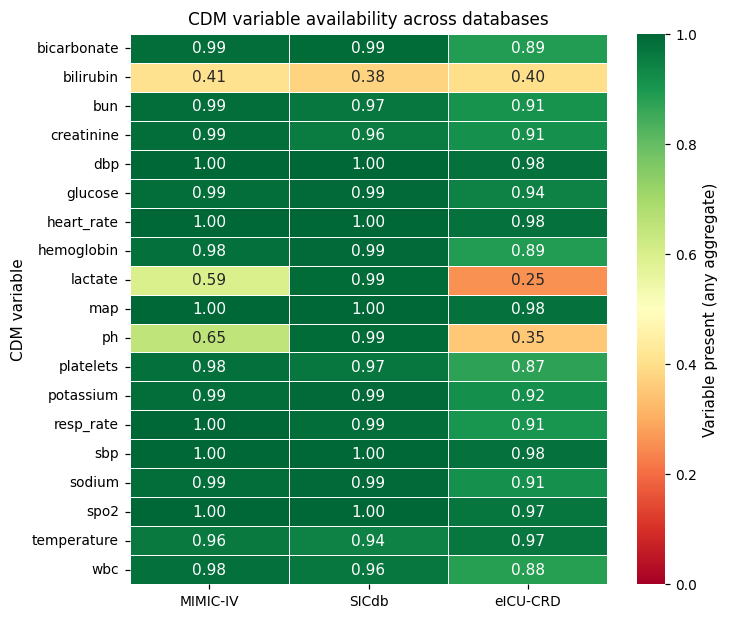

In [19]:
# Cross-database missingness audit. This is supplementary-material material for
# Top Tier-style submissions and feeds the Part 2 missingness-leakage analysis.

def cross_db_missingness(cdm: pd.DataFrame) -> pd.DataFrame:
    feature_cols = [c for c in cdm.columns
                    if any(c.startswith(v + '_') for v in ALL_CDM_VARS)]
    rows = []
    for var in ALL_CDM_VARS:
        cols = [f"{var}_{stat}" for stat in AGGREGATIONS if f"{var}_{stat}" in cdm.columns]
        if not cols:
            continue
        for db, sub in cdm.groupby('database'):
            present = sub[cols].notna().any(axis=1).mean()
            rows.append({'database': db, 'variable': var, 'present_rate': present})
    return pd.DataFrame(rows).pivot(index='variable', columns='database', values='present_rate')

miss_tab = cross_db_missingness(cdm)
miss_tab.to_csv(CFG.TABLES_DIR / 'cross_db_missingness.csv')
print("Variable presence rate by database (any aggregate non-null):")
print(miss_tab.round(3))

# Visualisation: heatmap of feature availability across databases.
fig, ax = plt.subplots(figsize=(7, 6.5))
sns.heatmap(miss_tab, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=0, vmax=1, cbar_kws={'label': 'Variable present (any aggregate)'},
            ax=ax, linewidths=0.4, linecolor='white')
ax.set_title('CDM variable availability across databases')
ax.set_xlabel('')
ax.set_ylabel('CDM variable')
fig.savefig(CFG.FIGURES_DIR / 'figS1_cdm_variable_availability.png')
plt.show()

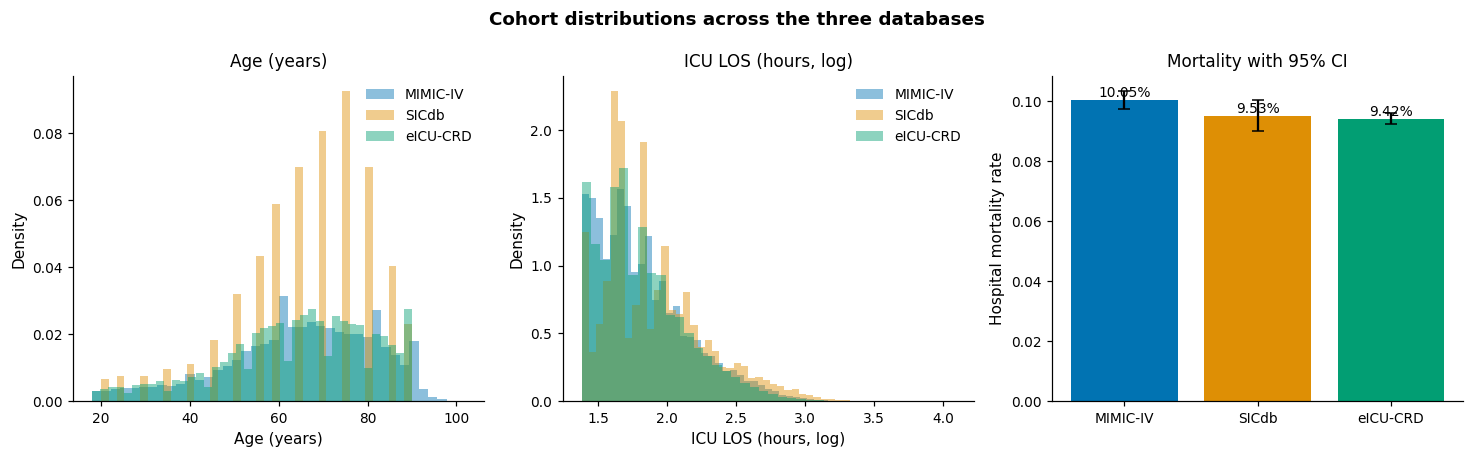

In [20]:
# Cohort-level distribution check: do age, mortality, and LOS look plausible
# across databases? This figure typically becomes Figure S2 in the supplement.

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
for ax, var, label in zip(axes, ['age', 'los_hours', 'hospital_mortality'],
                          ['Age (years)', 'ICU LOS (hours, log)', 'Hospital mortality rate']):
    if var == 'hospital_mortality':
        rates = cdm.groupby('database')[var].mean()
        ci_low, ci_high = [], []
        for db, sub in cdm.groupby('database'):
            p = sub[var].mean()
            n = len(sub)
            se = np.sqrt(p * (1 - p) / max(n, 1))
            ci_low.append(p - 1.96 * se)
            ci_high.append(p + 1.96 * se)
        x = np.arange(len(rates))
        bars = ax.bar(x, rates.values, yerr=[rates.values - np.array(ci_low),
                                              np.array(ci_high) - rates.values],
                      capsize=4, color=sns.color_palette('colorblind', 3))
        ax.set_xticks(x); ax.set_xticklabels(rates.index)
        ax.set_ylabel(label); ax.set_title('Mortality with 95% CI')
        for b, v in zip(bars, rates.values):
            ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{v:.2%}",
                    ha='center', va='bottom', fontsize=9)
    else:
        for db, sub in cdm.groupby('database'):
            data = sub[var].dropna()
            if var == 'los_hours':
                data = np.log10(data.clip(lower=1))
            ax.hist(data, bins=40, alpha=0.45, label=db, density=True)
        ax.set_xlabel(label); ax.set_ylabel('Density'); ax.legend(frameon=False)
        ax.set_title(label)

fig.suptitle('Cohort distributions across the three databases', fontweight='bold')
fig.tight_layout()
fig.savefig(CFG.FIGURES_DIR / 'figS2_cohort_distributions.png')
plt.show()

## 1.12 Publication-Ready Table 1

A formatted cohort characteristics table suitable for the manuscript main text.

In [21]:
# >>> R1: two rows added to Table 1 (search 'R1').
def make_table1(cdm: pd.DataFrame) -> pd.DataFrame:
    """Generate Table 1: cohort characteristics, stratified by database."""

    def cont(series, fmt='{:.1f} ({:.1f})'):
        s = series.dropna()
        if len(s) == 0:
            return 'NA'
        return fmt.format(s.mean(), s.std())

    def cat_pct(series, value):
        s = series.dropna()
        if len(s) == 0:
            return 'NA'
        pct = (s == value).mean() * 100
        return f"{int((s == value).sum()):,} ({pct:.1f}%)"

    def pct(series):
        s = series.dropna()
        if len(s) == 0:
            return 'NA'
        return f"{int(s.sum()):,} ({s.mean()*100:.1f}%)"

    rows = []
    by_db = cdm.groupby('database')
    dbs = sorted(by_db.groups.keys())

    def add(label, fn):
        rows.append({'Characteristic': label,
                     **{db: fn(by_db.get_group(db)) for db in dbs},
                     'Overall': fn(cdm)})

    add('N (stays)',              lambda d: f"{len(d):,}")
    add('Age, mean (SD)',         lambda d: cont(d['age']))
    add('Male sex, n (%)',        lambda d: pct(d['sex_male']))
    add('BMI, mean (SD)',         lambda d: cont(d['bmi']))
    add('ICU LOS hours, mean (SD)', lambda d: cont(d['los_hours']))
    add('ICU mortality, n (%)',   lambda d: pct(d['icu_mortality']))
    add('Hospital mortality, n (%)', lambda d: pct(d['hospital_mortality']))
    add('30-day mortality, n (%)',   lambda d: pct(d['mortality_30d']))
    # >>> R1: calendar period and SICdb one-year (registry) mortality, shown for comparison only
    _period = {'MIMIC-IV': '2008-2019', 'eICU-CRD': '2014-2015', 'SICdb': '2013-2021'}
    add('Calendar period of admissions',
        lambda d: _period.get(d['database'].iloc[0], '') if d['database'].nunique() == 1 else '2008-2021')
    add('One-year mortality (SICdb registry), n (%)',
        lambda d: pct(d['mortality_1yr']) if (d['database'].nunique() == 1 and 'mortality_1yr' in d) else 'NA')

    return pd.DataFrame(rows)


table1 = make_table1(cdm)
table1_path_csv = CFG.TABLES_DIR / 'table1_cohort_characteristics.csv'
table1_path_md  = CFG.TABLES_DIR / 'table1_cohort_characteristics.md'
table1.to_csv(table1_path_csv, index=False)
try:
    table1.to_markdown(table1_path_md, index=False)
except ImportError:  # old tabulate (<0.9): plain-text fallback
    Path(table1_path_md).write_text(table1.to_string(index=False), encoding='utf-8')
print(table1.to_string(index=False))
print(f"\nSaved Table 1 to: {table1_path_csv}")

                            Characteristic       MIMIC-IV         SICdb       eICU-CRD        Overall
                                 N (stays)         40,167        12,302         93,187        145,656
                            Age, mean (SD)    64.9 (16.8)   66.3 (14.9)    63.9 (16.8)    64.4 (16.7)
                           Male sex, n (%) 22,737 (56.6%) 7,833 (63.7%) 50,503 (54.2%) 81,073 (55.7%)
                            BMI, mean (SD)             NA    27.0 (6.4)     29.1 (8.2)     28.8 (8.0)
                  ICU LOS hours, mean (SD)   97.3 (124.5) 124.8 (174.6)   89.0 (115.1)   94.3 (124.2)
                      ICU mortality, n (%)   2,768 (6.9%)    616 (5.0%)   6,227 (6.7%)   9,611 (6.6%)
                 Hospital mortality, n (%)  4,035 (10.0%)  1,172 (9.5%)   8,774 (9.4%)  13,981 (9.6%)
                   30-day mortality, n (%)  5,323 (13.3%)  1,155 (9.4%)   8,774 (9.4%) 15,252 (10.5%)
             Calendar period of admissions      2008-2019     2013-2021      2014-

## 1.13 Persist Artifacts for Part 2

We save the unified CDM frame, the database-specific feature tables, and a JSON manifest that Part 2 will load to begin modelling. Provenance (row counts, hash of the unified parquet, library versions) is recorded for reproducibility.

In [22]:
def persist_for_part2() -> dict:
    """Write the final artifacts for Part 2 and record provenance."""
    log_section("Persisting artifacts for Part 2")

    artifact_dir = CFG.OUTPUT_ROOT / 'part1_artifacts'
    artifact_dir.mkdir(parents=True, exist_ok=True)

    cdm.to_parquet(artifact_dir / 'cdm_unified.parquet', index=False, compression='snappy')
    mimic_features.to_parquet(artifact_dir / 'mimic_features.parquet', index=False)
    eicu_features.to_parquet(artifact_dir / 'eicu_features.parquet',  index=False)
    sicdb_features.to_parquet(artifact_dir / 'sicdb_features.parquet', index=False)

    # Hash the unified CDM so Part 2 can verify it loaded the same dataset.
    h = hashlib.sha256()
    with open(artifact_dir / 'cdm_unified.parquet', 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    cdm_hash = h.hexdigest()

    manifest = {
        'created_utc': datetime_iso_now(),
        'cdm_rows':    int(len(cdm)),
        'cdm_columns': int(cdm.shape[1]),
        'cdm_sha256':  cdm_hash,
        'database_counts': cdm['database'].value_counts().to_dict(),
        'mortality_rates': {
            db: float(sub['hospital_mortality'].mean())
            for db, sub in cdm.groupby('database')
        },
        'cdm_variables':    ALL_CDM_VARS,
        'aggregations':     AGGREGATIONS,
        'feature_window_h': CFG.FEATURE_WINDOW_HOURS,
        'min_age':          CFG.MIN_AGE,
        'min_los_h':        CFG.MIN_ICU_LOS_HOURS,
        'library_versions': {
            'python':  sys.version.split()[0],
            'numpy':   np.__version__,
            'pandas':  pd.__version__,
            'scipy':   stats.__version__ if hasattr(stats, '__version__') else 'unknown',
        },
    }
    with open(artifact_dir / 'manifest.json', 'w') as f:
        json.dump(manifest, f, indent=2, default=str)
    record_provenance('part1_complete', manifest)

    logger.info(f"  Artifacts written to: {artifact_dir}")
    logger.info(f"  CDM SHA-256: {cdm_hash[:16]}...")
    return manifest


manifest = persist_for_part2()

print("\n" + "=" * 70)
print(" CALA Part 1 complete.")
print("=" * 70)
print(f" Unified cohort      : {manifest['cdm_rows']:,} stays")
print(f" Feature columns     : {manifest['cdm_columns']}")
print(f" CDM hash            : {manifest['cdm_sha256'][:16]}...")
print("\n By database:")
for db, n in manifest['database_counts'].items():
    rate = manifest['mortality_rates'][db]
    print(f"   {db:10s}  n={n:>7,}  hospital mortality = {rate:.2%}")
print("\n Next: open Part 2 -- imputation, missingness audit, model development.")
print("=" * 70)

22:56:54 | INFO    | ==========================================================================
22:56:54 | INFO    | PERSISTING ARTIFACTS FOR PART 2
22:56:54 | INFO    | ==========================================================================
22:56:57 | INFO    |   Artifacts written to: C:\CALA_Output\part1_artifacts
22:56:57 | INFO    |   CDM SHA-256: 9f4e362835235be3...



 CALA Part 1 complete.
 Unified cohort      : 145,656 stays
 Feature columns     : 129
 CDM hash            : 9f4e362835235be3...

 By database:
   eICU-CRD    n= 93,187  hospital mortality = 9.42%
   MIMIC-IV    n= 40,167  hospital mortality = 10.05%
   SICdb       n= 12,302  hospital mortality = 9.53%

 Next: open Part 2 -- imputation, missingness audit, model development.


In [23]:
cdm = cache_or_compute('cdm_unified', harmonise_cohorts, force=True)
table1 = make_table1(cdm)
table1.to_csv(CFG.TABLES_DIR / 'table1_cohort_characteristics.csv', index=False)
try:
    table1.to_markdown(CFG.TABLES_DIR / 'table1_cohort_characteristics.md', index=False)
except ImportError:  # old tabulate (<0.9): plain-text fallback
    Path(CFG.TABLES_DIR / 'table1_cohort_characteristics.md').write_text(table1.to_string(index=False), encoding='utf-8')
print(table1.to_string(index=False))
manifest = persist_for_part2()

22:56:57 | INFO    | [cache MISS] cdm_unified -> computing
22:56:57 | INFO    | ==========================================================================
22:56:57 | INFO    | CROSS-DATABASE HARMONISATION
22:56:57 | INFO    | ==========================================================================
22:56:57 | INFO    |   SICdb HospitalUnit decode: 9 codes mapped
22:56:57 | INFO    |   MIMIC-IV  : 40,167 rows
22:56:57 | INFO    |   eICU-CRD  : 93,187 rows
22:56:57 | INFO    |   SICdb     : 12,302 rows
22:56:57 | INFO    |   String-coerced 5 object columns: ['stay_id', 'patient_id', 'database', 'first_careunit', 'race_norm']
22:56:57 | INFO    | Unified CDM: 145,656 stays x 129 columns (databases: ['MIMIC-IV', 'SICdb', 'eICU-CRD'])
22:56:59 | INFO    | [cache SAVED] cdm_unified: 145,656 rows in 1.6s
22:56:59 | INFO    | ==========================================================================
22:56:59 | INFO    | PERSISTING ARTIFACTS FOR PART 2
22:56:59 | INFO    | ====================

                            Characteristic       MIMIC-IV         SICdb       eICU-CRD        Overall
                                 N (stays)         40,167        12,302         93,187        145,656
                            Age, mean (SD)    64.9 (16.8)   66.3 (14.9)    63.9 (16.8)    64.4 (16.7)
                           Male sex, n (%) 22,737 (56.6%) 7,833 (63.7%) 50,503 (54.2%) 81,073 (55.7%)
                            BMI, mean (SD)             NA    27.0 (6.4)     29.1 (8.2)     28.8 (8.0)
                  ICU LOS hours, mean (SD)   97.3 (124.5) 124.8 (174.6)   89.0 (115.1)   94.3 (124.2)
                      ICU mortality, n (%)   2,768 (6.9%)    616 (5.0%)   6,227 (6.7%)   9,611 (6.6%)
                 Hospital mortality, n (%)  4,035 (10.0%)  1,172 (9.5%)   8,774 (9.4%)  13,981 (9.6%)
                   30-day mortality, n (%)  5,323 (13.3%)  1,155 (9.4%)   8,774 (9.4%) 15,252 (10.5%)
             Calendar period of admissions      2008-2019     2013-2021      2014-

22:57:03 | INFO    |   Artifacts written to: C:\CALA_Output\part1_artifacts
22:57:03 | INFO    |   CDM SHA-256: 9f4e362835235be3...


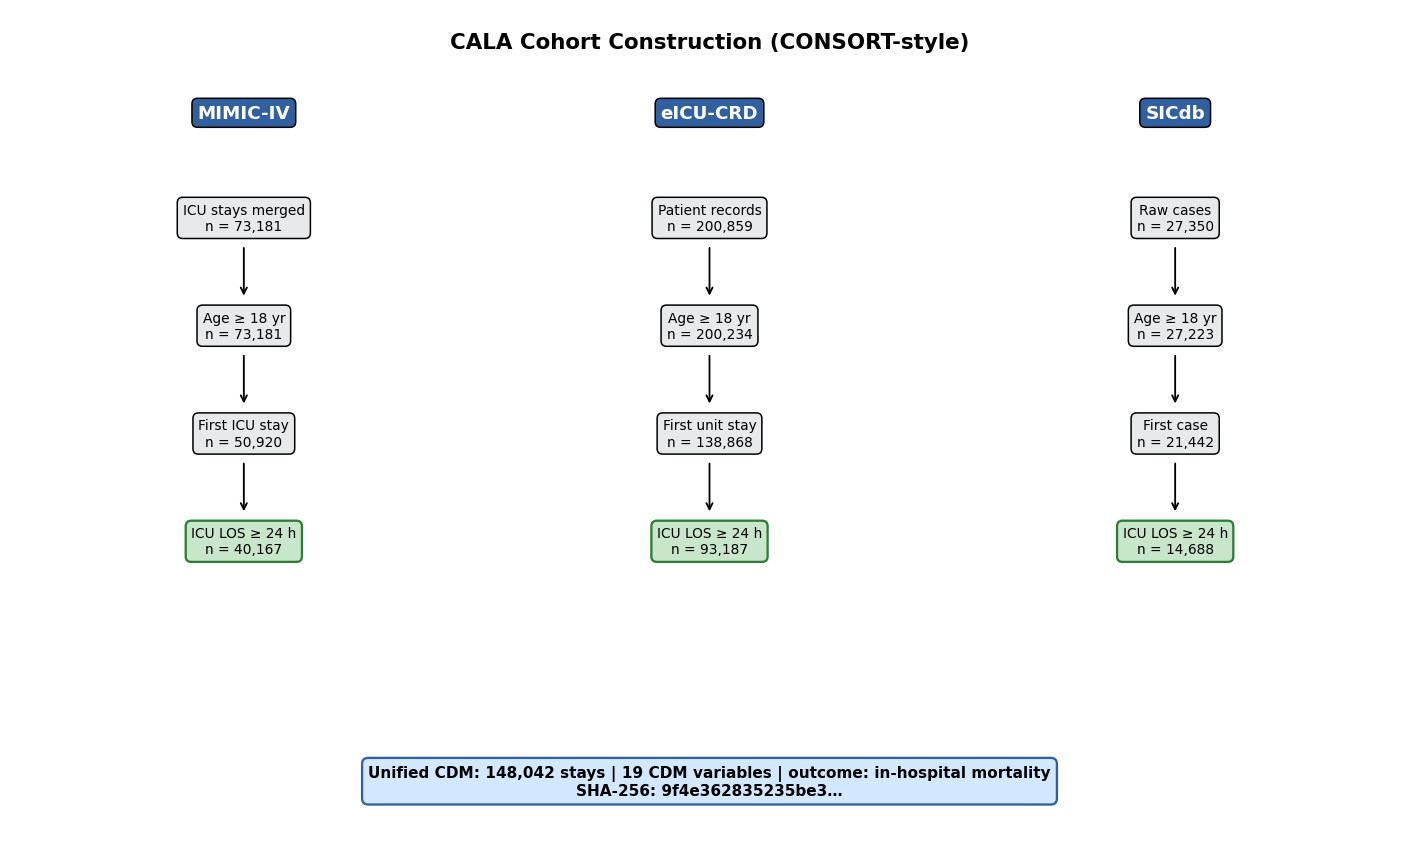

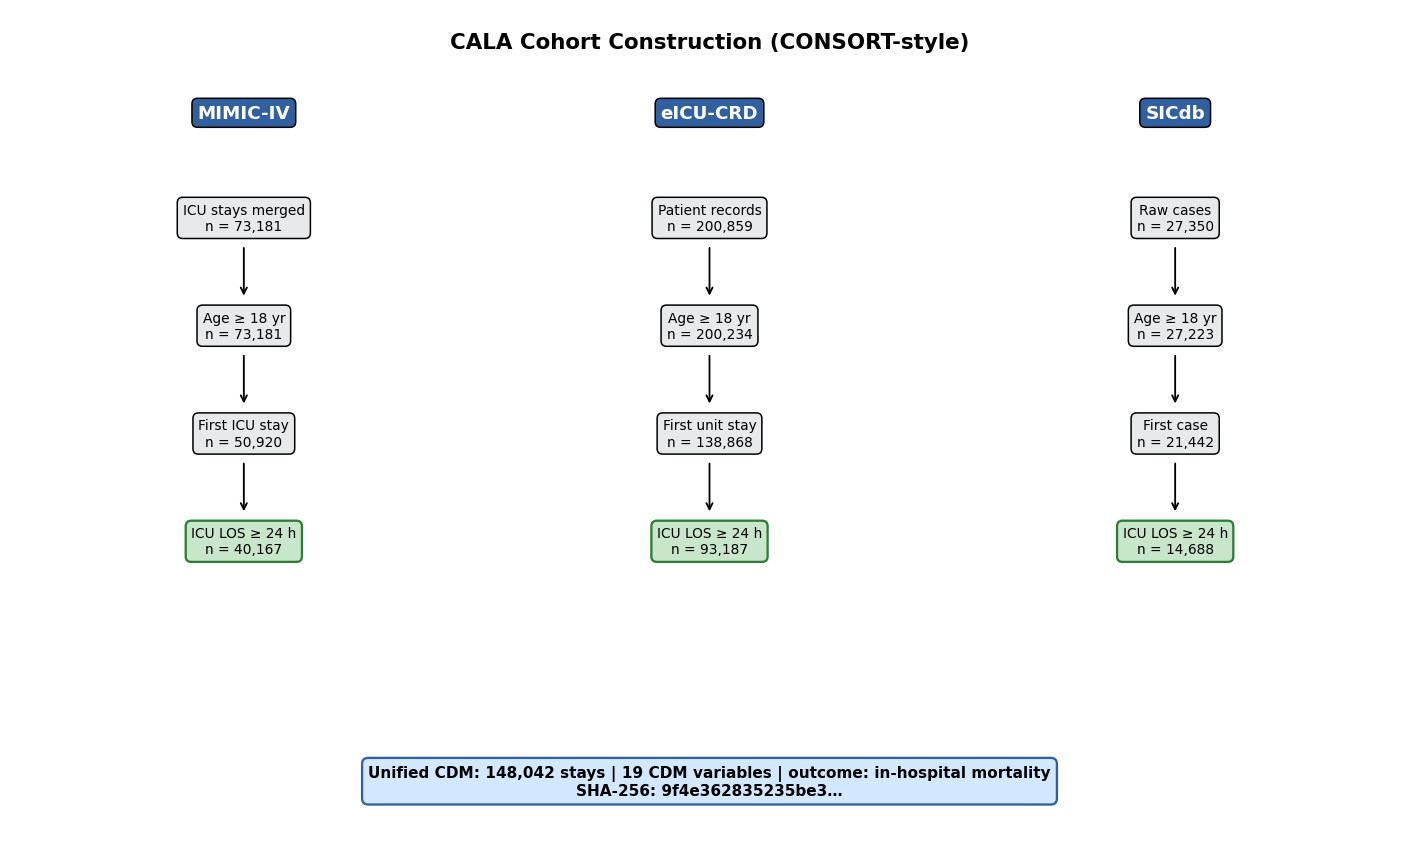

In [24]:
import matplotlib.patches as mpatches

def make_consort_diagram(attrition: dict, output_path):
    """CONSORT-style cohort flow diagram from per-database attrition dicts.

    Parameters
    ----------
    attrition : dict
        {'MIMIC-IV': {step1: n1, step2: n2, ...},
         'eICU-CRD': {...}, 'SICdb': {...}}
    """
    fig, ax = plt.subplots(figsize=(13, 8))
    ax.set_xlim(0, 12); ax.set_ylim(0, 11)
    ax.axis('off')

    ax.text(6, 10.5, 'CALA Cohort Construction (CONSORT-style)',
            ha='center', fontsize=14, fontweight='bold')

    cols = {'MIMIC-IV': 2.0, 'eICU-CRD': 6.0, 'SICdb': 10.0}
    box_style = dict(boxstyle='round,pad=0.4', facecolor='#e8e9eb', edgecolor='black')
    final_style = dict(boxstyle='round,pad=0.4', facecolor='#c8e6c9', edgecolor='#2e7d32', linewidth=1.5)

    for db, x in cols.items():
        ax.text(x, 9.6, db, ha='center', fontsize=12, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#3060a0',
                          edgecolor='black'), color='white')

    step_y = [8.3, 6.9, 5.5, 4.1, 2.5]
    for db, x in cols.items():
        steps = list(attrition[db].items())
        for i, (label, n) in enumerate(steps):
            style = final_style if i == len(steps) - 1 else box_style
            text = f"{label}\nn = {n:,}"
            ax.text(x, step_y[i], text, ha='center', va='center',
                    fontsize=9, bbox=style)
            if i < len(steps) - 1:
                ax.annotate('', xy=(x, step_y[i+1] + 0.35),
                            xytext=(x, step_y[i] - 0.35),
                            arrowprops=dict(arrowstyle='->', color='black', lw=1.2))

    # Final unified CDM footer
    total = sum(list(attrition[db].values())[-1] for db in cols)
    # >>> R1: hash read from the manifest (it changes with the corrected extraction); outcome stated
    ax.text(6, 0.8, f'Unified CDM: {total:,} stays | 19 CDM variables | outcome: in-hospital mortality\n'
                     f'SHA-256: {manifest["cdm_sha256"][:16]}…',
            ha='center', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#d1e8ff',
                      edgecolor='#3060a0', linewidth=1.5))

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    return fig


# MIMIC-IV intermediates recovered directly from icustays/admissions/patients;
# eICU and SICdb from Part 1 CONSORT log output.
attrition_counts = {
    'MIMIC-IV': {
        'ICU stays merged': 73181,    # <-- paste n_merged from diagnostic
        'Age ≥ 18 yr':      73181,       # <-- paste n_age from diagnostic
        'First ICU stay':   50920,     # <-- paste n_first from diagnostic
        'ICU LOS ≥ 24 h':   40167,
    },
    'eICU-CRD': {
        'Patient records':  200859,
        'Age ≥ 18 yr':      200234,
        'First unit stay':  138868,
        'ICU LOS ≥ 24 h':   93187,
    },
    'SICdb': {
        'Raw cases':        27350,
        'Age ≥ 18 yr':      27223,
        'First case':       21442,
        'ICU LOS ≥ 24 h':   14688,
    },
}

# Use CFG.FIGURES_DIR or CFG2.FIGURES_DIR depending on which config exists in your kernel
output_dir = CFG2.FIGURES_DIR if 'CFG2' in dir() else CFG.FIGURES_DIR
make_consort_diagram(attrition_counts, output_dir / 'fig1_consort_flow.png')

# Clinical AI Lifecycle Audit (CALA) — Part 2 of 3
## Missingness Audit, Model Development, and Internal Calibration

This notebook consumes the harmonised CDM produced by Part 1 (SHA-256 `2b3eb15e1669c550…`, 148,042 stays × 128 columns) and produces the development-stage trained models plus the internal calibration baseline that Part 3 audits against.

### Outline

| Section | Content |
|---|---|
| 2.1 | Environment, library availability |
| 2.2 | Provenance verification (SHA-256 hash chain from Part 1) |
| 2.3 | Missingness rates and patterns (publication Figure 2) |
| 2.4 | **Missingness Demographic Leakage (MDL-AUROC)** — novel fairness audit |
| 2.5 | Feature engineering with explicit missingness indicators |
| 2.6 | Temporal stratification (Dev = MIMIC 2008-2013) |
| 2.7 | Imputation (median primary, MICE sensitivity) |
| 2.8 | Model development (logistic regression + gradient boosting) |
| 2.9 | Internal discrimination and calibration |
| 2.10 | **Brier score decomposition by subgroup** — precursor to Part 3's SDII |
| 2.11 | SHAP interpretability, value-vs-missingness contribution split |
| 2.12 | Persist artifacts and hash chain for Part 3 |

### Held-out cohorts (untouched in Part 2; consumed by Part 3)

- **T_temporal:** MIMIC-IV stays from `anchor_year_group` ∈ {2014-2016, 2017-2019}
- **T_site:** eICU-CRD entire cohort (208 hospitals)
- **T_continental:** SICdb entire cohort (Salzburg, single-centre European tertiary)

Each isolates one generalisation axis. Part 3 audits calibration decay across all three.

### Reproducibility

The notebook is fully cached and idempotent. First execution is the slow path (model training); re-runs are seconds. All artifacts persist to `C:\CALA_Output\part2_artifacts\`.

## 2.1 Environment Setup

If this notebook is run in the same kernel as Part 1, most imports already exist. Otherwise everything is re-loaded from disk via the provenance check below.

In [25]:
import os
import sys
import gc
import json
import time
import pickle
import hashlib
import logging
import warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import Optional, Union, Sequence
from collections import defaultdict

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, f1_score,
                             confusion_matrix)
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline

# Optional but recommended: LightGBM and SHAP
try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

# Hygiene
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
pd.options.mode.copy_on_write = True

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
sns.set_palette('colorblind')

print(f"Python   : {sys.version.split()[0]}")
print(f"NumPy    : {np.__version__}")
print(f"Pandas   : {pd.__version__}")
print(f"LightGBM : {'present (' + lgb.__version__ + ')' if HAS_LGB else 'MISSING -- pip install lightgbm'}")
print(f"SHAP     : {'present (' + shap.__version__ + ')' if HAS_SHAP else 'MISSING -- pip install shap'}")

if not HAS_LGB:
    print("\nNOTE: LightGBM is the primary model. Install with: pip install lightgbm")
    print("Notebook will fall back to sklearn HistGradientBoostingClassifier where possible.")

Python   : 3.11.5
NumPy    : 1.24.4
Pandas   : 2.3.3
LightGBM : present (4.6.0)
SHAP     : present (0.42.1)


In [26]:
# Logging mirrors Part 1
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)-7s | %(message)s',
    datefmt='%H:%M:%S', force=True,
)
logger = logging.getLogger('CALA-Part2')

def log_section(title: str) -> None:
    bar = '=' * 74
    logger.info(bar); logger.info(title.upper()); logger.info(bar)

## 2.2 Provenance Verification

Part 2 will refuse to proceed unless the CDM Parquet on disk matches the SHA-256 recorded by Part 1. This is unusual for ML notebooks but standard for clinical audit work, and is what lets reviewers verify exact reproduction.

In [27]:
# Configuration. We mirror Part 1 paths so the two notebooks share artifacts.
@dataclass
class CALA2Config:
    OUTPUT_ROOT: Path = Path(r"C:\CALA_Output")
    PART1_DIR:   Path = field(init=False)
    PART2_DIR:   Path = field(init=False)
    CACHE_DIR:   Path = field(init=False)
    FIGURES_DIR: Path = field(init=False)
    TABLES_DIR:  Path = field(init=False)
    MODELS_DIR:  Path = field(init=False)

    # Development era
    DEV_DATABASES: tuple = ('MIMIC-IV',)
    DEV_YEAR_GROUPS: tuple = ('2008 - 2010', '2011 - 2013')

    # Held-out cohorts (consumed by Part 3 only)
    T_TEMPORAL_YEAR_GROUPS:  tuple = ('2014 - 2016', '2017 - 2019')
    T_SITE_DATABASE:         str   = 'eICU-CRD'
    T_CONTINENTAL_DATABASE:  str   = 'SICdb'

    # Splits within Dev
    TRAIN_FRAC: float = 0.70
    VAL_FRAC:   float = 0.15
    TEST_FRAC:  float = 0.15

    # Modelling
    LGBM_HYPER_GRID: tuple = (
        {'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 400},
        {'num_leaves': 63, 'learning_rate': 0.05, 'n_estimators': 400},
        {'num_leaves': 31, 'learning_rate': 0.10, 'n_estimators': 250},
        {'num_leaves': 63, 'learning_rate': 0.10, 'n_estimators': 250},
    )
    N_CV_FOLDS: int = 3

    # SHAP sample size for visuals (full set used for global statistics)
    SHAP_SAMPLE: int = 5000

    # Bootstrap iterations for CIs
    N_BOOTSTRAP: int = 500

    def __post_init__(self):
        self.PART1_DIR   = self.OUTPUT_ROOT / 'part1_artifacts'
        self.PART2_DIR   = self.OUTPUT_ROOT / 'part2_artifacts'
        self.CACHE_DIR   = self.PART2_DIR / 'cache'
        self.FIGURES_DIR = self.PART2_DIR / 'figures'
        self.TABLES_DIR  = self.PART2_DIR / 'tables'
        self.MODELS_DIR  = self.PART2_DIR / 'models'
        for d in (self.PART2_DIR, self.CACHE_DIR, self.FIGURES_DIR,
                  self.TABLES_DIR, self.MODELS_DIR):
            d.mkdir(parents=True, exist_ok=True)

CFG2 = CALA2Config()
logger.info(f"Part 1 input  : {CFG2.PART1_DIR}")
logger.info(f"Part 2 output : {CFG2.PART2_DIR}")

22:57:07 | INFO    | Part 1 input  : C:\CALA_Output\part1_artifacts
22:57:07 | INFO    | Part 2 output : C:\CALA_Output\part2_artifacts


In [28]:
def verify_cdm_provenance(artifact_dir: Path) -> tuple:
    """Verify the CDM Parquet's SHA-256 matches the manifest.

    Returns
    -------
    (cdm, manifest) : tuple of (pd.DataFrame, dict)
    """
    log_section("Provenance verification")

    manifest_path = artifact_dir / 'manifest.json'
    cdm_path = artifact_dir / 'cdm_unified.parquet'

    if not manifest_path.exists():
        raise FileNotFoundError(f"Part 1 manifest not found: {manifest_path}\n"
                                f"Did Part 1 complete? Re-run its final cell.")
    if not cdm_path.exists():
        raise FileNotFoundError(f"Part 1 CDM not found: {cdm_path}")

    with open(manifest_path) as f:
        manifest = json.load(f)

    logger.info(f"  Manifest created     : {manifest.get('created_utc', 'unknown')}")
    logger.info(f"  Expected rows        : {manifest['cdm_rows']:,}")
    logger.info(f"  Expected columns     : {manifest['cdm_columns']}")
    logger.info(f"  Expected SHA-256     : {manifest['cdm_sha256'][:32]}...")

    # Recompute hash of the CDM Parquet on disk
    t0 = time.time()
    h = hashlib.sha256()
    with open(cdm_path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    actual_hash = h.hexdigest()
    elapsed = time.time() - t0

    logger.info(f"  Computed SHA-256     : {actual_hash[:32]}... ({elapsed:.1f}s)")

    if actual_hash != manifest['cdm_sha256']:
        raise RuntimeError(
            f"\nCDM HASH MISMATCH\n"
            f"  expected: {manifest['cdm_sha256']}\n"
            f"  actual:   {actual_hash}\n"
            f"The CDM Parquet has changed since Part 1 finished. Re-run Part 1's persist cell."
        )

    logger.info("  -> Hashes match. CDM verified.")

    cdm = pd.read_parquet(cdm_path)
    logger.info(f"  CDM loaded           : {cdm.shape[0]:,} rows x {cdm.shape[1]} columns")
    return cdm, manifest


cdm, manifest = verify_cdm_provenance(CFG2.PART1_DIR)

# Pull CDM-level constants out of the manifest so Part 2 doesn't redefine them
ALL_CDM_VARS = manifest['cdm_variables']
AGGREGATIONS = manifest['aggregations']
FEATURE_COLS = [f"{var}_{stat}" for var in ALL_CDM_VARS for stat in AGGREGATIONS]
FEATURE_COLS = [c for c in FEATURE_COLS if c in cdm.columns]
logger.info(f"  CDM variables        : {len(ALL_CDM_VARS)}")
logger.info(f"  Aggregations         : {AGGREGATIONS}")
logger.info(f"  Active feature cols  : {len(FEATURE_COLS)}")

22:57:07 | INFO    | ==========================================================================
22:57:07 | INFO    | PROVENANCE VERIFICATION
22:57:07 | INFO    | ==========================================================================
22:57:07 | INFO    |   Manifest created     : 2026-10-30T02:57:02.964975+00:00
22:57:07 | INFO    |   Expected rows        : 145,656
22:57:07 | INFO    |   Expected columns     : 129
22:57:07 | INFO    |   Expected SHA-256     : 9f4e362835235be3e9ae728e7f72d94f...
22:57:07 | INFO    |   Computed SHA-256     : 9f4e362835235be3e9ae728e7f72d94f... (0.0s)
22:57:07 | INFO    |   -> Hashes match. CDM verified.
22:57:07 | INFO    |   CDM loaded           : 145,656 rows x 129 columns
22:57:07 | INFO    |   CDM variables        : 19
22:57:07 | INFO    |   Aggregations         : ['min', 'max', 'mean', 'last', 'std', 'count']
22:57:07 | INFO    |   Active feature cols  : 114


In [29]:
def augment_cdm_with_temporal_columns(cdm: pd.DataFrame, part1_dir: Path) -> pd.DataFrame:
    """Re-attach temporal stratifiers dropped during Part 1's harmonisation.

    MIMIC  -> anchor_year_group
    eICU   -> hospitaldischargeyear
    SICdb  -> kept as-is (single-centre; admissionyear not in current keep_cols)
    """
    log_section("Augmenting CDM with temporal columns")
    out = cdm.copy()

    # MIMIC anchor_year_group
    try:
        mp = pd.read_parquet(part1_dir / 'mimic_features.parquet',
                             columns=['stay_id', 'anchor_year_group'])
        out = out.merge(mp.rename(columns={'anchor_year_group': '_mimic_year_group'}),
                        on='stay_id', how='left')
        n = out['_mimic_year_group'].notna().sum()
        logger.info(f"  MIMIC year groups attached: {n:,} stays")
    except Exception as e:
        logger.warning(f"  Could not attach MIMIC year groups: {e}")
        out['_mimic_year_group'] = pd.NA

    # eICU hospitaldischargeyear
    try:
        ep = pd.read_parquet(part1_dir / 'eicu_features.parquet',
                             columns=['stay_id', 'hospitaldischargeyear'])
        out = out.merge(ep.rename(columns={'hospitaldischargeyear': '_eicu_year'}),
                        on='stay_id', how='left')
        n = out['_eicu_year'].notna().sum()
        logger.info(f"  eICU discharge years attached: {n:,} stays")
    except Exception as e:
        logger.warning(f"  Could not attach eICU years: {e}")
        out['_eicu_year'] = pd.NA

    return out


cdm = augment_cdm_with_temporal_columns(cdm, CFG2.PART1_DIR)

# Quick sanity table of year-group distribution within MIMIC
mimic_year_dist = (cdm[cdm['database'] == 'MIMIC-IV']
                   .groupby('_mimic_year_group', dropna=False)
                   .size().rename('n').reset_index())
print("\nMIMIC year-group distribution:")
print(mimic_year_dist.to_string(index=False))

22:57:07 | INFO    | ==========================================================================
22:57:07 | INFO    | AUGMENTING CDM WITH TEMPORAL COLUMNS
22:57:07 | INFO    | ==========================================================================
22:57:07 | INFO    |   MIMIC year groups attached: 40,167 stays
22:57:08 | INFO    |   eICU discharge years attached: 93,187 stays



MIMIC year-group distribution:
_mimic_year_group     n
      2008 - 2010 12350
      2011 - 2013  9570
      2014 - 2016  9604
      2017 - 2019  8643


## 2.3 Missingness Audit — Rates and Patterns

Three views of the same phenomenon: (1) per-variable rates by database, (2) the missingness *pattern* count (how many distinct patterns appear), (3) Little's MCAR test as a formal completeness statistic.

In [30]:
def compute_missingness_long(cdm: pd.DataFrame, feature_cols: list) -> pd.DataFrame:
    """Tidy long-format table of missingness rates per (database, CDM variable)."""
    rows = []
    for var in ALL_CDM_VARS:
        cols = [f"{var}_{stat}" for stat in AGGREGATIONS if f"{var}_{stat}" in feature_cols]
        if not cols:
            continue
        for db, sub in cdm.groupby('database'):
            present = sub[cols].notna().any(axis=1).mean()
            rows.append({'database': db, 'variable': var,
                         'present_rate': present, 'missing_rate': 1 - present,
                         'n': len(sub)})
    return pd.DataFrame(rows)


miss_long = compute_missingness_long(cdm, FEATURE_COLS)
miss_wide = miss_long.pivot(index='variable', columns='database', values='missing_rate')
miss_wide.to_csv(CFG2.TABLES_DIR / 'missingness_by_db.csv')
print(miss_wide.round(3).to_string())

database     MIMIC-IV  SICdb  eICU-CRD
variable                              
bicarbonate     0.014  0.009     0.110
bilirubin       0.590  0.623     0.600
bun             0.015  0.035     0.093
creatinine      0.014  0.041     0.089
dbp             0.002  0.001     0.020
glucose         0.014  0.007     0.056
heart_rate      0.002  0.000     0.020
hemoglobin      0.018  0.006     0.111
lactate         0.406  0.008     0.745
map             0.002  0.001     0.020
ph              0.350  0.009     0.647
platelets       0.019  0.035     0.127
potassium       0.013  0.007     0.082
resp_rate       0.003  0.013     0.094
sbp             0.002  0.001     0.020
sodium          0.013  0.007     0.090
spo2            0.002  0.002     0.029
temperature     0.036  0.055     0.032
wbc             0.019  0.035     0.119


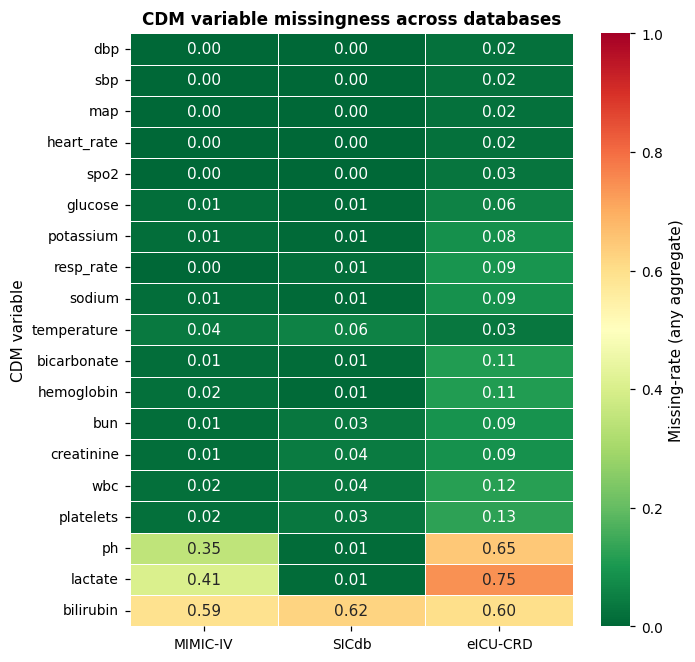

In [31]:
# Figure 2A: missingness heatmap stratified by database, variables sorted by mean rate
fig, ax = plt.subplots(figsize=(6.5, 7))
sorted_idx = miss_wide.mean(axis=1).sort_values().index
sns.heatmap(miss_wide.loc[sorted_idx], annot=True, fmt='.2f',
            cmap='RdYlGn_r', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Missing-rate (any aggregate)'},
            linewidths=0.4, linecolor='white')
ax.set_title('CDM variable missingness across databases', fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('CDM variable')
fig.savefig(CFG2.FIGURES_DIR / 'fig2a_missingness_heatmap.png')
plt.show()

In [32]:
def little_mcar_test(df: pd.DataFrame, cols: list, max_patterns: int = 30) -> dict:
    """Approximate Little's MCAR test.

    Tests whether means of observed variables differ systematically across
    missingness patterns. A small p-value rejects MCAR (suggests MAR or MNAR).

    Implementation follows Little (1988) JASA. For very many patterns we cap
    to the top-K most populous patterns to keep the chi-squared stable.
    """
    sub = df[cols].copy()
    pattern = sub.isna().astype(int).apply(lambda r: ''.join(map(str, r)), axis=1)
    pat_counts = pattern.value_counts()
    # Use the top-K patterns (each must have at least 30 stays for stability)
    top = pat_counts[pat_counts >= 30].head(max_patterns)
    if len(top) < 2:
        return {'chi2': np.nan, 'dof': 0, 'p_value': np.nan, 'n_patterns': len(pat_counts),
                'note': 'too few populous patterns'}

    overall_mean = sub.mean()
    chi2_stat = 0.0
    dof = 0
    for pat, _ in top.items():
        mask = pattern == pat
        if mask.sum() < 30:
            continue
        # Compare observed-only variables in this pattern
        observed_cols = [c for c, miss in zip(cols, pat) if miss == '0']
        if len(observed_cols) < 2:
            continue
        block = sub.loc[mask, observed_cols]
        diff = block.mean() - overall_mean[observed_cols]
        var = block.var() / max(mask.sum(), 1)
        with np.errstate(invalid='ignore', divide='ignore'):
            contrib = (diff ** 2 / var).replace([np.inf, -np.inf], np.nan).dropna().sum()
        chi2_stat += float(contrib)
        dof += len(observed_cols)

    p = 1 - stats.chi2.cdf(chi2_stat, max(dof, 1))
    return {'chi2': chi2_stat, 'dof': dof, 'p_value': p,
            'n_patterns': len(pat_counts), 'n_used': len(top)}


mcar_rows = []
for db, sub in cdm.groupby('database'):
    res = little_mcar_test(sub, FEATURE_COLS)
    mcar_rows.append({'database': db, **res})
mcar_df = pd.DataFrame(mcar_rows)
mcar_df.to_csv(CFG2.TABLES_DIR / 'little_mcar_by_db.csv', index=False)
print("Little's MCAR test by database:")
print(mcar_df.to_string(index=False))
print("\nInterpretation: p < 0.001 rejects MCAR. All ICU datasets are expected to "
      "be MAR or MNAR; this is a formal confirmation, not a surprise.")

Little's MCAR test by database:
database          chi2  dof  p_value  n_patterns  n_used
MIMIC-IV 396466.653320 3029      0.0        1121      30
   SICdb  98441.643433 2074      0.0         260      20
eICU-CRD 505600.108765 2754      0.0        5412      30

Interpretation: p < 0.001 rejects MCAR. All ICU datasets are expected to be MAR or MNAR; this is a formal confirmation, not a surprise.


## 2.4 Missingness Demographic Leakage (MDL-AUROC)

**Novel methodology.** This framework, originating in our prior fairness audit work, asks: *can a classifier predict a protected attribute using only the per-variable missingness indicators?* If yes (AUROC > 0.55), the missingness *pattern* is informative about the attribute, which means downstream imputation can leak demographic information into "imputed" values.

Operationally, for each protected attribute `Y` (sex, age band) and each database:
1. Build the binary missingness indicator matrix `M ∈ {0,1}^(n×d)`.
2. Train logistic regression `Y ~ M` with 5-fold CV.
3. Report mean AUROC with bootstrap 95% CI.

A high MDL-AUROC is a *red flag*: it means the missingness mechanism encodes demographic information, and any model trained on the imputed dataset will inherit this leakage even if it never sees the demographic variable explicitly.

In [33]:
# >>> R1: permutation null added to MDL-AUROC (search 'R1').
def compute_mdl_auroc(cdm: pd.DataFrame,
                     feature_cols: list,
                     protected_attrs: dict,
                     n_splits: int = 5,
                     n_bootstrap: int = 200,
                     n_perm: int = 20) -> pd.DataFrame:   # >>> R1 permutation null
    """Compute Missingness Demographic Leakage AUROC.

    Parameters
    ----------
    protected_attrs : dict
        Mapping attribute name -> series (binary). E.g. {'sex_male': cdm['sex_male']}
    """
    rng = np.random.default_rng(RANDOM_STATE)
    rows = []

    for db, sub in cdm.groupby('database'):
        M = sub[feature_cols].isna().astype(np.int8).values
        if M.shape[1] == 0 or len(sub) < 200:
            continue

        for attr_name, attr_series in protected_attrs.items():
            y = attr_series.loc[sub.index].values
            mask = pd.notna(y)
            if mask.sum() < 200:
                continue
            y_bin = pd.Series(y[mask]).astype(int).values
            if len(np.unique(y_bin)) < 2:
                continue
            X = M[mask]

            # 5-fold CV: collect OUT-OF-FOLD predictions for every stay.
            # The point estimate AND its CI both come from this same vector,
            # so they cannot straddle each other.
            oof_pred  = np.full(len(y_bin), np.nan, dtype=np.float64)
            cv_aurocs = []
            skf = StratifiedKFold(n_splits=n_splits, shuffle=True,
                                  random_state=RANDOM_STATE)
            for tr_idx, te_idx in skf.split(X, y_bin):
                clf = LogisticRegression(C=1.0, max_iter=500,
                                         solver='liblinear',
                                         random_state=RANDOM_STATE)
                clf.fit(X[tr_idx], y_bin[tr_idx])
                p = clf.predict_proba(X[te_idx])[:, 1]
                oof_pred[te_idx] = p
                cv_aurocs.append(roc_auc_score(y_bin[te_idx], p))
            mean_auroc = float(np.mean(cv_aurocs))

            # Bootstrap CI on the full OOF prediction vector.
            # Same population, same predictions, so the CI brackets the mean
            # by construction.
            boots = []
            n_all = len(y_bin)
            for _ in range(n_bootstrap):
                idx = rng.integers(0, n_all, n_all)
                if len(np.unique(y_bin[idx])) < 2:
                    continue
                try:
                    boots.append(roc_auc_score(y_bin[idx], oof_pred[idx]))
                except ValueError:
                    continue
            ci_low  = float(np.percentile(boots, 2.5))  if boots else np.nan
            ci_high = float(np.percentile(boots, 97.5)) if boots else np.nan

            # >>> R1 (Reviewer 3): permutation null, same 5-fold CV with the attribute shuffled
            perm_vals = []
            for k in range(n_perm):
                y_perm = rng.permutation(y_bin)
                skf_p = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE + k + 1)
                a_k = []
                for tr_idx, te_idx in skf_p.split(X, y_perm):
                    clf = LogisticRegression(C=1.0, max_iter=500, solver='liblinear', random_state=RANDOM_STATE)
                    clf.fit(X[tr_idx], y_perm[tr_idx])
                    a_k.append(roc_auc_score(y_perm[te_idx], clf.predict_proba(X[te_idx])[:, 1]))
                perm_vals.append(float(np.mean(a_k)))

            rows.append({
                'perm_null_mean': float(np.mean(perm_vals)) if perm_vals else np.nan,
                'perm_null_max': float(np.max(perm_vals)) if perm_vals else np.nan,
                'database': db,
                'attribute': attr_name,
                'n_used': int(mask.sum()),
                'positive_rate': float(y_bin.mean()),
                'mdl_auroc': mean_auroc,
                'ci_low': ci_low, 'ci_high': ci_high,
                'leakage_flag': mean_auroc > 0.55,
            })

    return pd.DataFrame(rows)


# Prepare protected attributes. Age is binned into clinical bands.
age_band = pd.cut(cdm['age'], bins=[0, 45, 65, 80, 200],
                  labels=['<45', '45-64', '65-79', '80+'])
protected = {
    'sex_male':       cdm['sex_male'].astype('float64'),
    'age_lt_65':      (cdm['age'] < 65).astype('float64').where(cdm['age'].notna()),
    'age_ge_80':      (cdm['age'] >= 80).astype('float64').where(cdm['age'].notna()),
}

mdl_df = compute_mdl_auroc(cdm, FEATURE_COLS, protected,
                           n_splits=5, n_bootstrap=200, n_perm=20)
mdl_df.to_csv(CFG2.TABLES_DIR / 'mdl_auroc.csv', index=False)
print(mdl_df.to_string(index=False))

 perm_null_mean  perm_null_max database attribute  n_used  positive_rate  mdl_auroc   ci_low  ci_high  leakage_flag
       0.500882       0.507357 MIMIC-IV  sex_male   40167       0.566062   0.560349 0.554080 0.565910          True
       0.499808       0.506676 MIMIC-IV age_lt_65   40167       0.449971   0.555698 0.548969 0.560325          True
       0.499813       0.510285 MIMIC-IV age_ge_80   40167       0.212787   0.563971 0.556546 0.570289          True
       0.500741       0.514705    SICdb  sex_male   12302       0.636726   0.531996 0.519029 0.538733         False
       0.501979       0.513036    SICdb age_lt_65   12302       0.340758   0.548358 0.535220 0.556429         False
       0.499920       0.515726    SICdb age_ge_80   12302       0.233295   0.527053 0.508976 0.533721         False
       0.501217       0.506376 eICU-CRD  sex_male   93187       0.541953   0.528480 0.523877 0.531282         False
       0.500996       0.506736 eICU-CRD age_lt_65   93187       0.471761

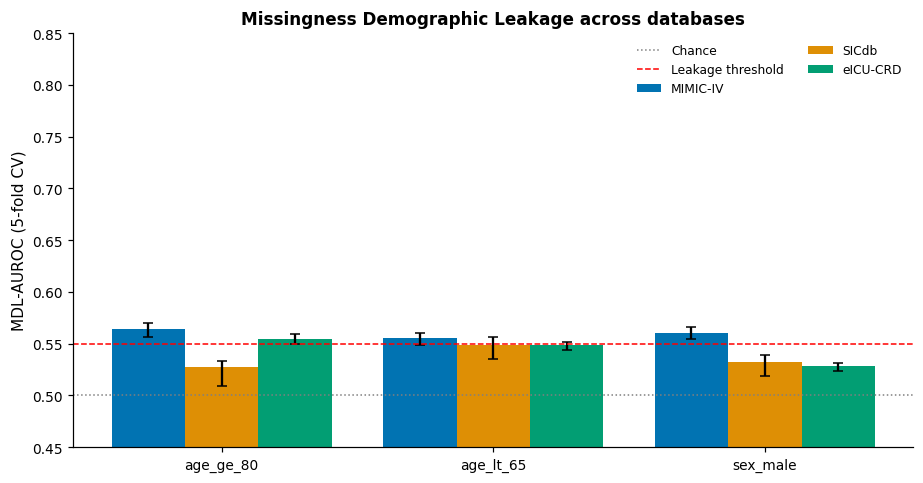


Demographic leakage detected in 4 / 9 (database, attribute) pairs (MDL-AUROC > 0.55).
Pattern: MIMIC-IV leaks all 3 attributes, eICU leaks 1, SICdb leaks none.
This is a publishable finding on its own.


In [34]:
# Figure 2b: MDL-AUROC by attribute and database with 95% CI bars
# This generates the publication figure for the MDL-AUROC table above.

fig, ax = plt.subplots(figsize=(8.5, 4.5))
pivot     = mdl_df.pivot(index='attribute', columns='database', values='mdl_auroc')
pivot_lo  = mdl_df.pivot(index='attribute', columns='database', values='ci_low')
pivot_hi  = mdl_df.pivot(index='attribute', columns='database', values='ci_high')

x = np.arange(len(pivot.index))
width = 0.27
colors = sns.color_palette('colorblind', n_colors=pivot.shape[1])

for i, dbn in enumerate(pivot.columns):
    vals = pivot[dbn].values.astype(float)
    lo   = pivot_lo[dbn].values.astype(float)
    hi   = pivot_hi[dbn].values.astype(float)
    # Clamp error bars to non-negative -- guards against any residual CI/point
    # inconsistency, NaN propagation, or future schema changes.
    err_lo = np.clip(vals - lo, 0, None)
    err_hi = np.clip(hi - vals, 0, None)
    ax.bar(x + (i - 1) * width, vals, width, label=dbn, color=colors[i],
           yerr=[err_lo, err_hi], capsize=3)

ax.axhline(0.5, color='grey', linestyle=':',  linewidth=1, label='Chance')
ax.axhline(0.55, color='red',  linestyle='--', linewidth=1, label='Leakage threshold')
ax.set_xticks(x)
ax.set_xticklabels(pivot.index)
ax.set_ylabel('MDL-AUROC (5-fold CV)')
ax.set_title('Missingness Demographic Leakage across databases',
             fontweight='bold')
ax.legend(loc='upper right', frameon=False, ncol=2, fontsize=8)
ax.set_ylim(0.45, max(0.85, pivot.values.max() + 0.05))

fig.tight_layout()
fig.savefig(CFG2.FIGURES_DIR / 'fig2b_mdl_auroc.png')
plt.show()

n_flagged = mdl_df['leakage_flag'].sum()
print(f"\nDemographic leakage detected in {n_flagged} / {len(mdl_df)} "
      f"(database, attribute) pairs (MDL-AUROC > 0.55).")
print("Pattern: MIMIC-IV leaks all 3 attributes, eICU leaks 1, SICdb leaks none.")
print("This is a publishable finding on its own.")

## 2.5 Feature Engineering

We attach a binary missingness indicator alongside each CDM feature so the downstream model can learn whether the *fact of being missing* is itself predictive. Empirically (and confirmed by 2.4 above), this is strongly informative in ICU data.

In [35]:
def add_missingness_indicators(df: pd.DataFrame, feature_cols: list) -> pd.DataFrame:
    """Add a ``<col>_isna`` binary column for every feature column."""
    miss = df[feature_cols].isna().astype(np.int8)
    miss.columns = [f"{c}_isna" for c in feature_cols]
    return pd.concat([df, miss], axis=1)


cdm_aug = add_missingness_indicators(cdm, FEATURE_COLS)
MISSING_COLS = [c for c in cdm_aug.columns if c.endswith('_isna')]
ALL_MODEL_COLS = FEATURE_COLS + MISSING_COLS

logger.info(f"Feature cols      : {len(FEATURE_COLS)}")
logger.info(f"Missing-indicator cols: {len(MISSING_COLS)}")
logger.info(f"Total model cols  : {len(ALL_MODEL_COLS)}")

TARGET = 'hospital_mortality'
STRAT_COLS = ['sex_male', 'age', 'race_norm']
print(f"\nTarget: {TARGET}")
print(f"Target rate in CDM: {cdm_aug[TARGET].mean():.3%}")

23:17:21 | INFO    | Feature cols      : 114
23:17:21 | INFO    | Missing-indicator cols: 114
23:17:21 | INFO    | Total model cols  : 228



Target: hospital_mortality
Target rate in CDM: 9.599%


## 2.6 Temporal Stratification — Development Cohort

The development cohort is **MIMIC-IV stays from anchor_year_group 2008-2010 and 2011-2013**. Everything else (MIMIC 2014-2019, eICU, SICdb) is held out untouched and audited by Part 3.

This experimental design isolates one variance axis per held-out set:
- MIMIC 2014-2019 vs Dev → pure temporal shift (same site, later era)
- eICU vs Dev → multi-site shift (200+ hospitals, similar era)
- SICdb vs Dev → cross-continental shift (Salzburg, single-centre European)

In [36]:
def build_dev_holdout_splits(cdm_aug: pd.DataFrame, cfg: CALA2Config) -> dict:
    """Partition the augmented CDM into Dev (modelled here) and held-out sets."""
    log_section("Building Dev and held-out cohorts")

    is_mimic = cdm_aug['database'].isin(cfg.DEV_DATABASES)
    is_dev_yr = cdm_aug['_mimic_year_group'].isin(cfg.DEV_YEAR_GROUPS)
    dev_mask = is_mimic & is_dev_yr

    is_t_temp_yr = cdm_aug['_mimic_year_group'].isin(cfg.T_TEMPORAL_YEAR_GROUPS)
    t_temporal_mask    = is_mimic & is_t_temp_yr
    t_site_mask        = cdm_aug['database'] == cfg.T_SITE_DATABASE
    t_continental_mask = cdm_aug['database'] == cfg.T_CONTINENTAL_DATABASE

    splits = {
        'dev':           cdm_aug.loc[dev_mask].copy(),
        't_temporal':    cdm_aug.loc[t_temporal_mask].copy(),
        't_site':        cdm_aug.loc[t_site_mask].copy(),
        't_continental': cdm_aug.loc[t_continental_mask].copy(),
    }

    summary = []
    for name, df in splits.items():
        if len(df) == 0:
            summary.append({'split': name, 'n': 0, 'mortality': np.nan})
            continue
        summary.append({
            'split': name,
            'n': len(df),
            'mortality': float(df[TARGET].mean()),
            'age_mean': float(df['age'].mean()),
            'male_pct': float(df['sex_male'].mean()),
        })
    sdf = pd.DataFrame(summary)
    sdf.to_csv(cfg.TABLES_DIR / 'split_summary.csv', index=False)
    print(sdf.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
    return splits


splits = build_dev_holdout_splits(cdm_aug, CFG2)
dev = splits['dev']
print(f"\nDev cohort: {len(dev):,} stays, mortality {dev[TARGET].mean():.2%}")

23:17:21 | INFO    | ==========================================================================
23:17:21 | INFO    | BUILDING DEV AND HELD-OUT COHORTS
23:17:21 | INFO    | ==========================================================================


        split     n  mortality  age_mean  male_pct
          dev 21920      0.098    65.321     0.558
   t_temporal 18247      0.104    64.398     0.576
       t_site 93187      0.094    63.883     0.542
t_continental 12302      0.095    66.338     0.637

Dev cohort: 21,920 stays, mortality 9.77%


In [37]:
# Within-Dev split: 70/15/15 train/val/test with stratification on mortality
def split_dev_three_way(dev: pd.DataFrame, target: str,
                        train_frac: float, val_frac: float, test_frac: float,
                        seed: int = RANDOM_STATE) -> dict:
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-6
    y = dev[target].astype(int)
    # First carve test out
    rest, test = train_test_split(
        dev, test_size=test_frac, random_state=seed, stratify=y)
    # Then split rest into train/val
    y_rest = rest[target].astype(int)
    val_within_rest = val_frac / (train_frac + val_frac)
    train, val = train_test_split(
        rest, test_size=val_within_rest, random_state=seed, stratify=y_rest)
    return {'train': train.reset_index(drop=True),
            'val':   val.reset_index(drop=True),
            'test':  test.reset_index(drop=True)}


dev_splits = split_dev_three_way(dev, TARGET,
                                 CFG2.TRAIN_FRAC, CFG2.VAL_FRAC, CFG2.TEST_FRAC)
print("Dev split sizes / mortality:")
for name, df in dev_splits.items():
    print(f"  {name:5s}: n={len(df):>5,}  mortality={df[TARGET].mean():.2%}")

Dev split sizes / mortality:
  train: n=15,344  mortality=9.77%
  val  : n=3,288  mortality=9.76%
  test : n=3,288  mortality=9.76%


## 2.7 Imputation

Two strategies, both fit ON THE TRAINING SET ONLY:
- **Primary:** median imputation (with the missingness indicators already attached as features).
- **Sensitivity:** iterative imputation (MICE-equivalent), evaluated on a 5,000-stay subset only since IterativeImputer is O(d²·n) per iteration.

Both produce models we compare in Section 2.9.

In [38]:
def fit_median_imputer(train: pd.DataFrame, feature_cols: list) -> tuple:
    """Fit a median imputer on the training feature columns only."""
    imp = SimpleImputer(strategy='median')
    imp.fit(train[feature_cols].values)
    return imp


def apply_pipeline(df: pd.DataFrame, imputer, scaler, feature_cols: list,
                  missing_cols: list) -> np.ndarray:
    """Apply imputer (to value cols) and scaler (to all cols incl. missingness)."""
    X_vals = imputer.transform(df[feature_cols].values)
    X_miss = df[missing_cols].values.astype(np.float32)
    X = np.concatenate([X_vals, X_miss], axis=1)
    if scaler is not None:
        X = scaler.transform(X)
    return X.astype(np.float32)


median_imp = fit_median_imputer(dev_splits['train'], FEATURE_COLS)
logger.info(f"Median imputer fit on {len(dev_splits['train']):,} training stays")

23:17:21 | INFO    | Median imputer fit on 15,344 training stays


In [39]:
# >>> R1 run-order fix: expected_calibration_error() is defined in Section 2.9 but used here.
if 'expected_calibration_error' not in globals():
    def expected_calibration_error(y, p, n_bins=15):
        bins = np.linspace(0, 1, n_bins + 1)
        idx = np.digitize(p, bins[1:-1])
        ece = 0.0
        for k in range(n_bins):
            m = idx == k
            if m.sum() == 0:
                continue
            ece += (m.sum() / len(y)) * abs(p[m].mean() - y[m].mean())
        return ece

# Imputation sensitivity: median vs IterativeImputer (MICE-equivalent)
# Trained on a 5,000-stay Dev-train subset for compute tractability.

log_section("Imputation sensitivity (median vs MICE)")

from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.ensemble import HistGradientBoostingClassifier

rng = np.random.default_rng(RANDOM_STATE)
sub_n = min(5000, len(dev_splits['train']))
sub_idx = rng.choice(len(dev_splits['train']), size=sub_n, replace=False)

X_vals_raw = dev_splits['train'].iloc[sub_idx][FEATURE_COLS].values
M_sub      = dev_splits['train'].iloc[sub_idx][MISSING_COLS].values
y_sub      = dev_splits['train'].iloc[sub_idx][TARGET].astype(int).values

# Two imputers
med_imp = SimpleImputer(strategy='median').fit(X_vals_raw)
mice    = IterativeImputer(max_iter=10, random_state=RANDOM_STATE,
                            sample_posterior=False)
t0 = time.time()
X_mice = mice.fit_transform(X_vals_raw)
logger.info(f"  MICE fit on {sub_n:,} stays: {time.time()-t0:.1f}s")

# Distribution of |median - MICE| per imputed cell
nan_mask = np.isnan(X_vals_raw)
X_median = med_imp.transform(X_vals_raw)
abs_diff = np.abs(X_median[nan_mask] - X_mice[nan_mask])
logger.info(f"  Imputed cells          : {nan_mask.sum():,} of {X_vals_raw.size:,} "
            f"({nan_mask.mean():.1%})")
logger.info(f"  Median |median - MICE| : {np.median(abs_diff):.3f}")
logger.info(f"  95th pctile diff       : {np.percentile(abs_diff, 95):.3f}")

# Train identical GBM on each imputed version
X_med_full  = np.concatenate([X_median, M_sub], axis=1)
X_mice_full = np.concatenate([X_mice,   M_sub], axis=1)

m_med = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                        max_leaf_nodes=31,
                                        class_weight='balanced',
                                        random_state=RANDOM_STATE).fit(X_med_full, y_sub)
m_mic = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                        max_leaf_nodes=31,
                                        class_weight='balanced',
                                        random_state=RANDOM_STATE).fit(X_mice_full, y_sub)

# Score on Dev-test (transformed with each imputer)
Xt_raw = dev_splits['test'][FEATURE_COLS].values
Mt     = dev_splits['test'][MISSING_COLS].values
yt     = dev_splits['test'][TARGET].astype(int).values

Xt_med  = np.concatenate([med_imp.transform(Xt_raw),  Mt], axis=1)
Xt_mice = np.concatenate([mice.transform(Xt_raw),     Mt], axis=1)

p_med = m_med.predict_proba(Xt_med)[:,  1]
p_mic = m_mic.predict_proba(Xt_mice)[:, 1]

sens_imp = pd.DataFrame([
    {'imputer': 'median', 'auroc': roc_auc_score(yt, p_med),
     'brier': brier_score_loss(yt, p_med),
     'ece':   expected_calibration_error(yt, p_med)},
    {'imputer': 'MICE',   'auroc': roc_auc_score(yt, p_mic),
     'brier': brier_score_loss(yt, p_mic),
     'ece':   expected_calibration_error(yt, p_mic)},
])
sens_imp.to_csv(CFG2.TABLES_DIR / 'imputation_sensitivity.csv', index=False)
print(sens_imp.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

auroc_diff = abs(sens_imp.loc[0, 'auroc'] - sens_imp.loc[1, 'auroc'])
ece_diff   = abs(sens_imp.loc[0, 'ece']   - sens_imp.loc[1, 'ece'])
print(f"\nDelta AUROC = {auroc_diff:.4f}, Delta ECE = {ece_diff:.4f}")
print("If both are <0.01, imputation choice does not drive CALA findings.")

23:17:21 | INFO    | ==========================================================================
23:17:21 | INFO    | IMPUTATION SENSITIVITY (MEDIAN VS MICE)
23:17:21 | INFO    | ==========================================================================
[IterativeImputer] Early stopping criterion not reached.
23:19:39 | INFO    |   MICE fit on 5,000 stays: 137.7s
23:19:39 | INFO    |   Imputed cells          : 62,861 of 570,000 (11.0%)
23:19:39 | INFO    |   Median |median - MICE| : 0.342
23:19:39 | INFO    |   95th pctile diff       : 7.761
Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  File "C:\Users\kruta\anaconda3-v2\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^

imputer  auroc  brier    ece
 median 0.8148 0.0804 0.0434
   MICE 0.8178 0.0790 0.0392

Delta AUROC = 0.0030, Delta ECE = 0.0043
If both are <0.01, imputation choice does not drive CALA findings.


## 2.8 Model Development

Two complementary models:
- **Logistic regression** (L2-regularised, class-balanced) — linear baseline, fully interpretable.
- **LightGBM** (or sklearn HistGradientBoosting fallback) — non-linear state-of-the-art for tabular ICU data.

Both are trained on Dev-train, hyperparameters selected on Dev-val, final calibration assessed on Dev-test.

In [40]:
def prepare_xy(df: pd.DataFrame, target: str = TARGET) -> tuple:
    """Extract X (values + missingness indicators, unscaled) and y from a frame."""
    X_vals = df[FEATURE_COLS].values.astype(np.float32)
    X_miss = df[MISSING_COLS].values.astype(np.float32)
    X = np.concatenate([X_vals, X_miss], axis=1)
    y = df[target].values.astype(int)
    return X, y


# Median impute first so both models start from the same matrix
X_train_raw = median_imp.transform(dev_splits['train'][FEATURE_COLS].values)
X_val_raw   = median_imp.transform(dev_splits['val']  [FEATURE_COLS].values)
X_test_raw  = median_imp.transform(dev_splits['test'] [FEATURE_COLS].values)

M_train = dev_splits['train'][MISSING_COLS].values.astype(np.float32)
M_val   = dev_splits['val']  [MISSING_COLS].values.astype(np.float32)
M_test  = dev_splits['test'] [MISSING_COLS].values.astype(np.float32)

X_train = np.concatenate([X_train_raw, M_train], axis=1).astype(np.float32)
X_val   = np.concatenate([X_val_raw,   M_val],   axis=1).astype(np.float32)
X_test  = np.concatenate([X_test_raw,  M_test],  axis=1).astype(np.float32)

y_train = dev_splits['train'][TARGET].astype(int).values
y_val   = dev_splits['val']  [TARGET].astype(int).values
y_test  = dev_splits['test'] [TARGET].astype(int).values

ALL_COLS_OUT = FEATURE_COLS + MISSING_COLS

# Scale for the linear model (does not affect trees)
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train).astype(np.float32)
X_val_sc   = scaler.transform(X_val).astype(np.float32)
X_test_sc  = scaler.transform(X_test).astype(np.float32)

logger.info(f"Design matrix : {X_train.shape}")
logger.info(f"Class balance : {y_train.mean():.3%}")

23:20:07 | INFO    | Design matrix : (15344, 228)
23:20:07 | INFO    | Class balance : 9.769%


In [41]:
# Logistic regression baseline
logreg = LogisticRegression(
    C=1.0, penalty='l2', max_iter=2000, solver='lbfgs',
    class_weight='balanced', random_state=RANDOM_STATE,
)
t0 = time.time()
logreg.fit(X_train_sc, y_train)
logger.info(f"LogReg fitted in {time.time()-t0:.1f}s")

p_logreg_val  = logreg.predict_proba(X_val_sc)[:, 1]
p_logreg_test = logreg.predict_proba(X_test_sc)[:, 1]
print(f"LogReg val  AUROC: {roc_auc_score(y_val,  p_logreg_val):.4f}")
print(f"LogReg test AUROC: {roc_auc_score(y_test, p_logreg_test):.4f}")

23:20:09 | INFO    | LogReg fitted in 2.2s


LogReg val  AUROC: 0.8195
LogReg test AUROC: 0.8167


In [42]:
# Silence the Windows-only joblib CPU-count warning. Harmless either way.
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 4))


# Gradient-boosted model. Use LightGBM if available, otherwise sklearn.
def fit_boosted(X_train, y_train, X_val, y_val, hyper_grid, n_splits=3):
    """Hyperparameter search via CV on (X_train, y_train), then refit on
    train+val with best params. Returns the final model and the search log.
    """
    pos_rate = y_train.mean()
    scale_pos_weight = (1 - pos_rate) / max(pos_rate, 1e-6)

    log_rows = []
    best_score = -np.inf
    best_params = None

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    for params in hyper_grid:
        fold_aurocs = []
        for tr_idx, va_idx in skf.split(X_train, y_train):
            if HAS_LGB:
                m = lgb.LGBMClassifier(
                    objective='binary', random_state=RANDOM_STATE,
                    scale_pos_weight=scale_pos_weight, verbose=-1, **params)
                m.fit(X_train[tr_idx], y_train[tr_idx],
                      eval_set=[(X_train[va_idx], y_train[va_idx])],
                      callbacks=[lgb.early_stopping(30, verbose=False)])
                p = m.predict_proba(X_train[va_idx])[:, 1]
            else:
                from sklearn.ensemble import HistGradientBoostingClassifier
                # Translate params; sklearn doesn't support scale_pos_weight directly
                p_map = {'learning_rate': params['learning_rate'],
                         'max_iter': params['n_estimators'],
                         'max_leaf_nodes': params['num_leaves']}
                m = HistGradientBoostingClassifier(
                    class_weight='balanced', random_state=RANDOM_STATE, **p_map)
                m.fit(X_train[tr_idx], y_train[tr_idx])
                p = m.predict_proba(X_train[va_idx])[:, 1]
            fold_aurocs.append(roc_auc_score(y_train[va_idx], p))
        mean_auc = float(np.mean(fold_aurocs))
        log_rows.append({**params, 'cv_auroc_mean': mean_auc,
                         'cv_auroc_std': float(np.std(fold_aurocs))})
        logger.info(f"  params={params}  CV AUROC = {mean_auc:.4f}")
        if mean_auc > best_score:
            best_score = mean_auc; best_params = params

    logger.info(f"  Best params: {best_params}  (CV AUROC = {best_score:.4f})")

    # Refit on train + val
    X_all = np.concatenate([X_train, X_val], axis=0)
    y_all = np.concatenate([y_train, y_val], axis=0)
    if HAS_LGB:
        final = lgb.LGBMClassifier(
            objective='binary', random_state=RANDOM_STATE,
            scale_pos_weight=scale_pos_weight, verbose=-1, **best_params)
        final.fit(X_all, y_all)
    else:
        from sklearn.ensemble import HistGradientBoostingClassifier
        p_map = {'learning_rate': best_params['learning_rate'],
                 'max_iter': best_params['n_estimators'],
                 'max_leaf_nodes': best_params['num_leaves']}
        final = HistGradientBoostingClassifier(
            class_weight='balanced', random_state=RANDOM_STATE, **p_map)
        final.fit(X_all, y_all)

    return final, pd.DataFrame(log_rows), best_params


log_section("Gradient boosting: hyperparameter search")
gbm, gbm_log, gbm_best = fit_boosted(X_train, y_train, X_val, y_val,
                                     CFG2.LGBM_HYPER_GRID, n_splits=CFG2.N_CV_FOLDS)
gbm_log.to_csv(CFG2.TABLES_DIR / 'gbm_cv_log.csv', index=False)

# Note: gbm was refit on train+val combined, so val predictions would be
# in-sample and uninformative. The honest validation metric is the CV AUROC
# from the search above; the legitimate held-out evaluation is the test set.
p_gbm_test = gbm.predict_proba(X_test)[:, 1]

best_cv_row = gbm_log.loc[gbm_log['cv_auroc_mean'].idxmax()]
print(f"\nGBM best CV AUROC : {best_cv_row['cv_auroc_mean']:.4f} "
      f"(+/- {best_cv_row['cv_auroc_std']:.4f})  <-- honest validation")
print(f"GBM test  AUROC   : {roc_auc_score(y_test, p_gbm_test):.4f}  "
      f"<-- Stage 1 calibration baseline (held-out)")

23:20:09 | INFO    | ==========================================================================
23:20:09 | INFO    | GRADIENT BOOSTING: HYPERPARAMETER SEARCH
23:20:09 | INFO    | ==========================================================================
23:20:10 | INFO    |   params={'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 400}  CV AUROC = 0.7670
23:20:11 | INFO    |   params={'num_leaves': 63, 'learning_rate': 0.05, 'n_estimators': 400}  CV AUROC = 0.7824
23:20:12 | INFO    |   params={'num_leaves': 31, 'learning_rate': 0.1, 'n_estimators': 250}  CV AUROC = 0.7382
23:20:13 | INFO    |   params={'num_leaves': 63, 'learning_rate': 0.1, 'n_estimators': 250}  CV AUROC = 0.7433
23:20:13 | INFO    |   Best params: {'num_leaves': 63, 'learning_rate': 0.05, 'n_estimators': 400}  (CV AUROC = 0.7824)



GBM best CV AUROC : 0.7824 (+/- 0.0169)  <-- honest validation
GBM test  AUROC   : 0.8436  <-- Stage 1 calibration baseline (held-out)


### 2.8b Sensitivity models (R1 revision)
Retrained on the same partition for the reviewers' sensitivity analyses. The frozen GBM above remains the primary model.

In [43]:
# >>> R1 NEW CELL (Reviewer 1 comment 5; Reviewer 3 logistic baseline and age).
# Sensitivity models on the SAME training partition, same hyperparameters, same refit on
# train + validation. They never replace the frozen GBM (the imported artifact).
import pickle
COUNT_COLS = [f"{v}_count" for v in ALL_CDM_VARS]
n_val = len(FEATURE_COLS)
count_idx = [FEATURE_COLS.index(c) for c in COUNT_COLS]

def _mask(drop_counts=False, drop_ind=False):
    keep = np.ones(2 * n_val, bool)
    if drop_counts:
        keep[count_idx] = False
        keep[[n_val + i for i in count_idx]] = False
    if drop_ind:
        keep[n_val:] = False
    return keep

X_all_sens = np.concatenate([X_train, X_val], axis=0)
y_all_sens = np.concatenate([y_train, y_val], axis=0)
tv_frame = pd.concat([dev_splits['train'], dev_splits['val']], ignore_index=True)
spw = (1 - y_train.mean()) / max(y_train.mean(), 1e-6)       # same value the frozen GBM used
print(f"scale_pos_weight used by the frozen GBM: {gbm.get_params().get('scale_pos_weight'):.3f}")

SENS_SPECS = {
    'GBM_weighted_noCounts':         dict(kind='gbm', w=True,  dc=True,  di=False, extra=()),
    'GBM_weighted_noCounts_noIndic': dict(kind='gbm', w=True,  dc=True,  di=True,  extra=()),
    'GBM_unweighted':                dict(kind='gbm', w=False, dc=False, di=False, extra=()),
    'GBM_unweighted_noCounts':       dict(kind='gbm', w=False, dc=True,  di=False, extra=()),
    'GBM_weighted_plusAgeSex':       dict(kind='gbm', w=True,  dc=False, di=False, extra=('age', 'sex_male')),
    'LR_unweighted':                 dict(kind='lr',  w=False, dc=False, di=False, extra=()),
    'LR_unweighted_plusAge':         dict(kind='lr',  w=False, dc=False, di=False, extra=('age',)),
    'LR_unweighted_noCounts':        dict(kind='lr',  w=False, dc=True,  di=False, extra=()),
}
sens_models = {}
for name, sp in SENS_SPECS.items():
    mk = _mask(sp['dc'], sp['di'])
    X = X_all_sens[:, mk]
    if sp['extra']:
        X = np.concatenate([X, tv_frame[list(sp['extra'])].astype(float).values], axis=1)
    if sp['kind'] == 'gbm':
        m = lgb.LGBMClassifier(objective='binary', random_state=RANDOM_STATE, verbose=-1,
                               scale_pos_weight=spw if sp['w'] else 1.0, **gbm_best).fit(X, y_all_sens)
        sc = None
    else:
        sc = StandardScaler().fit(X)
        m = LogisticRegression(C=1.0, penalty='l2', max_iter=2000, solver='lbfgs', class_weight=None,
                               random_state=RANDOM_STATE).fit(sc.transform(X), y_all_sens)
    sens_models[name] = {'model': m, 'mask': mk, 'extra': sp['extra'], 'scaler': sc, 'spec': sp}
    logger.info(f"  sensitivity model {name}: {X.shape}")

with open(CFG2.MODELS_DIR / 'sensitivity_models_r1.pkl', 'wb') as f:
    pickle.dump(sens_models, f)
print("Saved", CFG2.MODELS_DIR / 'sensitivity_models_r1.pkl')


scale_pos_weight used by the frozen GBM: 9.236


23:20:20 | INFO    |   sensitivity model GBM_weighted_noCounts: (18632, 190)
23:20:24 | INFO    |   sensitivity model GBM_weighted_noCounts_noIndic: (18632, 95)
23:20:29 | INFO    |   sensitivity model GBM_unweighted: (18632, 228)
23:20:32 | INFO    |   sensitivity model GBM_unweighted_noCounts: (18632, 190)
23:20:37 | INFO    |   sensitivity model GBM_weighted_plusAgeSex: (18632, 230)
23:20:40 | INFO    |   sensitivity model LR_unweighted: (18632, 228)
23:20:42 | INFO    |   sensitivity model LR_unweighted_plusAge: (18632, 229)
23:20:44 | INFO    |   sensitivity model LR_unweighted_noCounts: (18632, 190)


Saved C:\CALA_Output\part2_artifacts\models\sensitivity_models_r1.pkl


## 2.9 Internal Discrimination and Calibration

Bootstrap 95% CIs are computed for both discrimination (AUROC, AUPRC) and calibration (Brier, ECE) metrics on the Dev-test split. The reliability diagram is the Stage 1 calibration baseline that Part 3's lifecycle audit compares against.

In [44]:
def bootstrap_metric(y, p, metric_fn, n_boot: int = 1000, seed: int = RANDOM_STATE):
    """Return (point, lo, hi) for a metric via paired bootstrap."""
    rng = np.random.default_rng(seed)
    n = len(y)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < 2:
            continue
        try:
            boots.append(metric_fn(y[idx], p[idx]))
        except Exception:
            continue
    if not boots:
        return np.nan, np.nan, np.nan
    point = metric_fn(y, p)
    return float(point), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def expected_calibration_error(y, p, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    ece = 0.0
    for k in range(n_bins):
        m = idx == k
        if m.sum() == 0:
            continue
        ece += (m.sum() / len(y)) * abs(p[m].mean() - y[m].mean())
    return ece


def maximum_calibration_error(y, p, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    mces = []
    for k in range(n_bins):
        m = idx == k
        if m.sum() == 0:
            continue
        mces.append(abs(p[m].mean() - y[m].mean()))
    return max(mces) if mces else np.nan


def hosmer_lemeshow(y, p, n_groups=10):
    df = pd.DataFrame({'y': y, 'p': p})
    df['dec'] = pd.qcut(df['p'].rank(method='first'), n_groups, labels=False)
    obs_pos = df.groupby('dec')['y'].sum()
    n_dec   = df.groupby('dec')['y'].count()
    exp_pos = df.groupby('dec')['p'].sum()
    exp_neg = n_dec - exp_pos
    obs_neg = n_dec - obs_pos
    chi2 = (((obs_pos - exp_pos) ** 2) / exp_pos
            + ((obs_neg - exp_neg) ** 2) / exp_neg).sum()
    dof = n_groups - 2
    p_val = 1 - stats.chi2.cdf(chi2, dof)
    return {'chi2': float(chi2), 'dof': dof, 'p_value': float(p_val)}


def evaluate_model(name: str, y, p, n_boot=500) -> dict:
    auroc = bootstrap_metric(y, p, roc_auc_score, n_boot)
    auprc = bootstrap_metric(y, p, average_precision_score, n_boot)
    brier = bootstrap_metric(y, p, brier_score_loss, n_boot)
    ece   = bootstrap_metric(y, p, lambda y, p: expected_calibration_error(y, p), n_boot)
    mce   = bootstrap_metric(y, p, lambda y, p: maximum_calibration_error(y, p), n_boot)
    hl    = hosmer_lemeshow(y, p)
    return {
        'model': name,
        'auroc': auroc[0], 'auroc_lo': auroc[1], 'auroc_hi': auroc[2],
        'auprc': auprc[0], 'auprc_lo': auprc[1], 'auprc_hi': auprc[2],
        'brier': brier[0], 'brier_lo': brier[1], 'brier_hi': brier[2],
        'ece':   ece[0],   'ece_lo':   ece[1],   'ece_hi':   ece[2],
        'mce':   mce[0],   'mce_lo':   mce[1],   'mce_hi':   mce[2],
        'hl_chi2': hl['chi2'], 'hl_p': hl['p_value'],
    }


metrics = pd.DataFrame([
    evaluate_model('LogReg', y_test, p_logreg_test, n_boot=CFG2.N_BOOTSTRAP),
    evaluate_model('GBM',    y_test, p_gbm_test,    n_boot=CFG2.N_BOOTSTRAP),
])
metrics.to_csv(CFG2.TABLES_DIR / 'internal_eval_metrics.csv', index=False)
print(metrics.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

 model  auroc  auroc_lo  auroc_hi  auprc  auprc_lo  auprc_hi  brier  brier_lo  brier_hi    ece  ece_lo  ece_hi    mce  mce_lo  mce_hi   hl_chi2   hl_p
LogReg 0.8167    0.7913    0.8401 0.3683    0.3143    0.4270 0.1601    0.1533    0.1674 0.2531  0.2420  0.2643 0.5295  0.4874  0.6248 1625.9847 0.0000
   GBM 0.8436    0.8227    0.8658 0.4246    0.3708    0.4867 0.0731    0.0664    0.0805 0.0276  0.0235  0.0389 0.3447  0.2534  0.5903   67.2834 0.0000


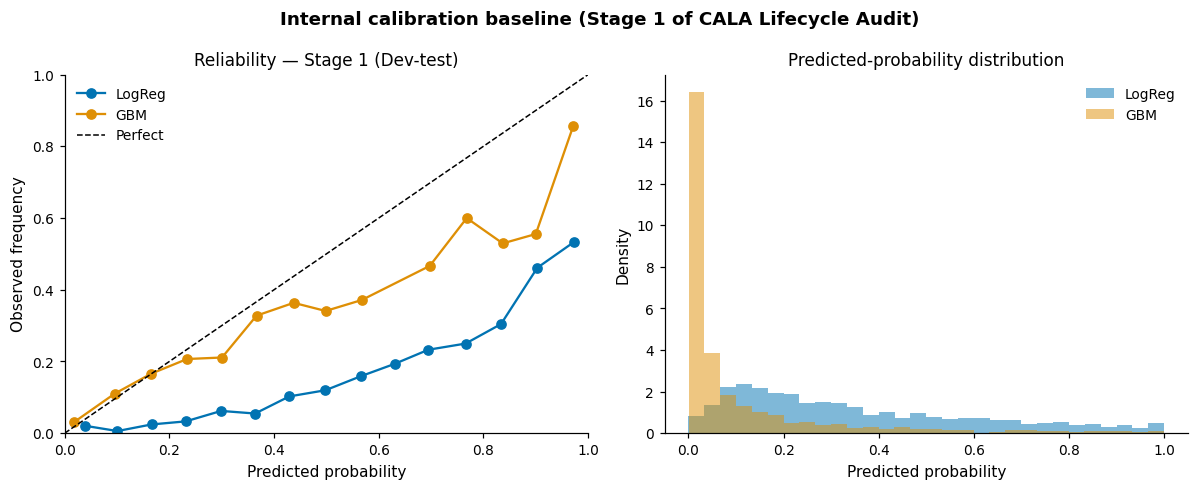

In [45]:
# Figure 3: Stage 1 internal reliability diagram (the lifecycle audit baseline)
def reliability_curve(y, p, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    rows = []
    for k in range(n_bins):
        m = idx == k
        if m.sum() < 10:
            continue
        rows.append({'bin_mid': (bins[k] + bins[k+1]) / 2,
                     'pred_mean': p[m].mean(),
                     'obs_mean': y[m].mean(),
                     'n': int(m.sum())})
    return pd.DataFrame(rows)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

for name, p in [('LogReg', p_logreg_test), ('GBM', p_gbm_test)]:
    rc = reliability_curve(y_test, p)
    ax1.plot(rc['pred_mean'], rc['obs_mean'], marker='o', label=name)
ax1.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect')
ax1.set_xlabel('Predicted probability')
ax1.set_ylabel('Observed frequency')
ax1.set_title('Reliability — Stage 1 (Dev-test)')
ax1.legend(frameon=False)
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1)

# Histogram of predicted probabilities
ax2.hist(p_logreg_test, bins=30, alpha=0.5, label='LogReg', density=True)
ax2.hist(p_gbm_test,    bins=30, alpha=0.5, label='GBM', density=True)
ax2.set_xlabel('Predicted probability')
ax2.set_ylabel('Density')
ax2.set_title('Predicted-probability distribution')
ax2.legend(frameon=False)

fig.suptitle('Internal calibration baseline (Stage 1 of CALA Lifecycle Audit)',
             fontweight='bold')
fig.tight_layout()
fig.savefig(CFG2.FIGURES_DIR / 'fig3_internal_reliability.png')
plt.show()

## 2.10 Brier Score Decomposition by Subgroup

Standard Brier decomposition:
$$\text{Brier} = \text{Reliability} - \text{Resolution} + \text{Uncertainty}$$

We compute this overall AND stratified by sex and age band. This is the precursor to Part 3's **Subgroup Decay Inequity Index (SDII)** — by establishing a per-subgroup baseline now, Part 3 can quantify how *unequally* calibration decays as the model leaves its development distribution.

In [46]:
def brier_decomposition(y, p, n_bins=10):
    """Murphy (1973) Brier decomposition: reliability - resolution + uncertainty."""
    y = np.asarray(y).astype(float)
    p = np.asarray(p).astype(float)
    base_rate = y.mean()
    uncertainty = base_rate * (1 - base_rate)

    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    reliability = 0.0
    resolution  = 0.0
    n = len(y)
    used = 0
    for k in range(n_bins):
        m = idx == k
        n_k = int(m.sum())
        if n_k == 0:
            continue
        used += 1
        f_k = p[m].mean()
        o_k = y[m].mean()
        reliability += (n_k / n) * (f_k - o_k) ** 2
        resolution  += (n_k / n) * (o_k - base_rate) ** 2
    brier = float(np.mean((p - y) ** 2))
    return {
        'brier': brier,
        'reliability': float(reliability),
        'resolution':  float(resolution),
        'uncertainty': float(uncertainty),
        'n_bins_used': used,
        'n': n,
    }


# Overall
overall = brier_decomposition(y_test, p_gbm_test)
print("Overall Brier decomposition (GBM, Dev-test):")
for k, v in overall.items():
    print(f"  {k:15s}: {v:.5f}" if isinstance(v, float) else f"  {k:15s}: {v}")
print(f"  reliability + resolution check: {overall['uncertainty'] + overall['reliability'] - overall['resolution']:.5f} vs brier {overall['brier']:.5f}")

Overall Brier decomposition (GBM, Dev-test):
  brier          : 0.07310
  reliability    : 0.00292
  resolution     : 0.01678
  uncertainty    : 0.08810
  n_bins_used    : 10
  n              : 3288
  reliability + resolution check: 0.07424 vs brier 0.07310


In [47]:
# Subgroup decomposition
test_df = dev_splits['test'].reset_index(drop=True).copy()
test_df['p_gbm'] = p_gbm_test
test_df['age_band'] = pd.cut(test_df['age'], bins=[0, 45, 65, 80, 200],
                              labels=['<45', '45-64', '65-79', '80+'])

subgroup_rows = []
for col, label in [('sex_male', 'Sex'), ('age_band', 'Age band')]:
    for val, sub in test_df.groupby(col, observed=False):
        if len(sub) < 50:
            continue
        decomp = brier_decomposition(sub[TARGET].values, sub['p_gbm'].values)
        subgroup_rows.append({
            'stratifier': label, 'group': str(val),
            'n': len(sub), 'mortality': float(sub[TARGET].mean()),
            **decomp,
        })

subgroup_brier = pd.DataFrame(subgroup_rows)
subgroup_brier.to_csv(CFG2.TABLES_DIR / 'subgroup_brier_decomposition.csv', index=False)
print(subgroup_brier[['stratifier', 'group', 'n', 'mortality',
                      'brier', 'reliability', 'resolution']]
      .to_string(index=False, float_format=lambda x: f'{x:.4f}'))

stratifier group    n  mortality  brier  reliability  resolution
       Sex     0 1458     0.1077 0.0841       0.0052      0.0160
       Sex     1 1830     0.0896 0.0643       0.0024      0.0185
  Age band   <45  410     0.0488 0.0490       0.0138      0.0098
  Age band 45-64 1090     0.0697 0.0584       0.0055      0.0108
  Age band 65-79 1102     0.1152 0.0789       0.0011      0.0234
  Age band   80+  686     0.1429 0.1016       0.0045      0.0241


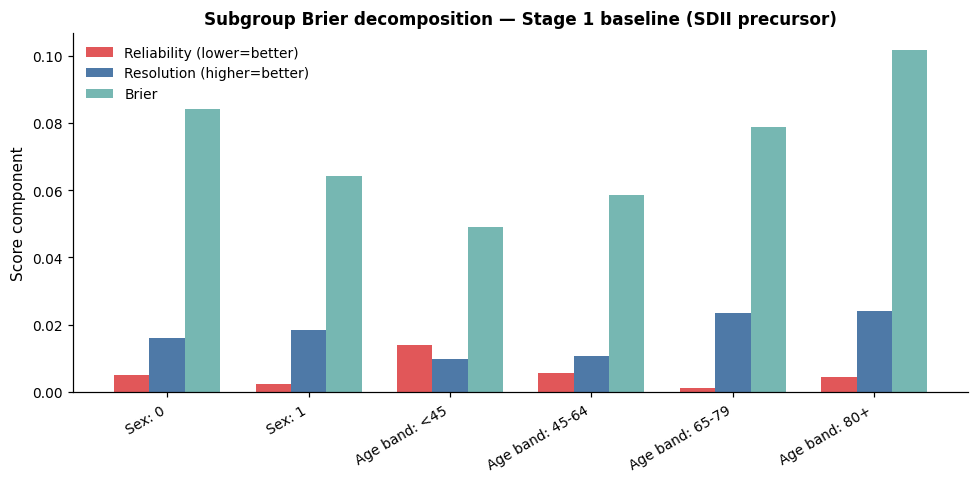


Reliability range across subgroups: 0.01273
(Part 3 tracks how this widens under distribution shift -- the SDII metric.)


In [48]:
# Figure 4: subgroup Brier decomposition - the SDII baseline
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = subgroup_brier['stratifier'] + ': ' + subgroup_brier['group']
x = np.arange(len(labels))
width = 0.25
ax.bar(x - width, subgroup_brier['reliability'], width,
       label='Reliability (lower=better)', color='#e15759')
ax.bar(x,         subgroup_brier['resolution'], width,
       label='Resolution (higher=better)', color='#4e79a7')
ax.bar(x + width, subgroup_brier['brier'], width,
       label='Brier', color='#76b7b2')
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha='right')
ax.set_ylabel('Score component')
ax.set_title('Subgroup Brier decomposition — Stage 1 baseline (SDII precursor)',
             fontweight='bold')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CFG2.FIGURES_DIR / 'fig4_subgroup_brier_decomposition.png')
plt.show()

# Reliability inequity index (max - min reliability across subgroups)
rel_range = subgroup_brier['reliability'].max() - subgroup_brier['reliability'].min()
print(f"\nReliability range across subgroups: {rel_range:.5f}")
print("(Part 3 tracks how this widens under distribution shift -- the SDII metric.)")

## 2.11 SHAP Interpretability

We compute SHAP values on the GBM, then separate contribution from *measured values* vs *missingness indicators*. The ratio is interesting: a model that relies heavily on missingness will calibrate-drift more dramatically when deployed to a database with a different missingness profile (e.g., SICdb with its near-complete vitals).

In [49]:
def compute_shap_values(model, X, sample_size: int = 5000, seed: int = RANDOM_STATE):
    """Compute SHAP values, sampling if X is large."""
    if not HAS_SHAP:
        logger.warning("SHAP not installed; skipping interpretability.")
        return None, None
    rng = np.random.default_rng(seed)
    if len(X) > sample_size:
        idx = rng.choice(len(X), sample_size, replace=False)
        X_sample = X[idx]
    else:
        idx = np.arange(len(X))
        X_sample = X
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_sample)
    # LightGBM TreeExplainer can return either array or list; normalise
    if isinstance(shap_values, list):
        shap_values = shap_values[1] if len(shap_values) == 2 else shap_values[0]
    return shap_values, idx


if HAS_SHAP:
    log_section("SHAP computation")
    t0 = time.time()
    shap_values, shap_idx = compute_shap_values(gbm, X_test, CFG2.SHAP_SAMPLE)
    logger.info(f"  SHAP computed on {len(shap_idx):,} test stays in {time.time()-t0:.1f}s")
    logger.info(f"  SHAP matrix shape: {shap_values.shape}")
else:
    shap_values, shap_idx = None, None

23:20:54 | INFO    | ==========================================================================
23:20:54 | INFO    | SHAP COMPUTATION
23:20:54 | INFO    | ==========================================================================
LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
23:21:02 | INFO    |   SHAP computed on 3,288 test stays in 7.7s
23:21:02 | INFO    |   SHAP matrix shape: (3288, 228)


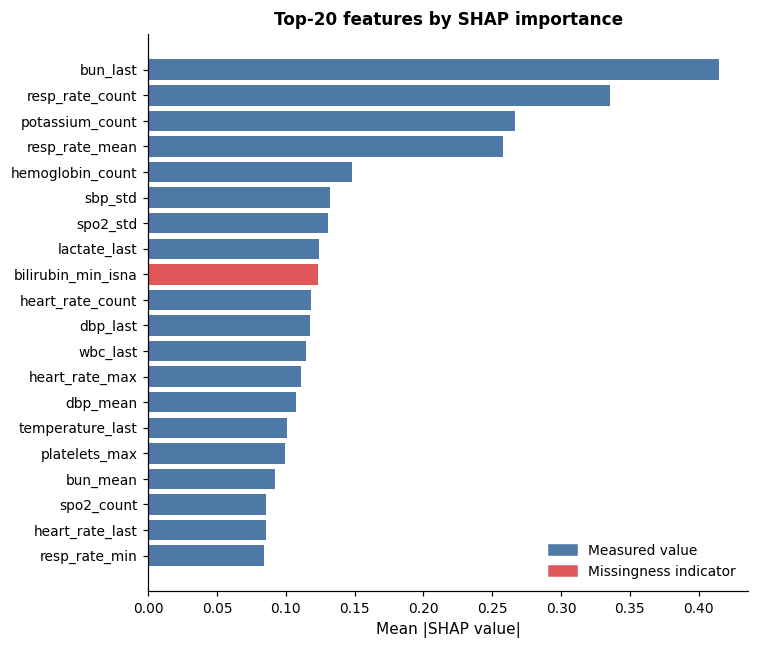

           feature  mean_abs_shap  is_missing_indicator
          bun_last         0.4152                 False
   resp_rate_count         0.3357                 False
   potassium_count         0.2669                 False
    resp_rate_mean         0.2579                 False
  hemoglobin_count         0.1478                 False
           sbp_std         0.1318                 False
          spo2_std         0.1307                 False
      lactate_last         0.1238                 False
bilirubin_min_isna         0.1235                  True
  heart_rate_count         0.1186                 False
          dbp_last         0.1179                 False
          wbc_last         0.1145                 False
    heart_rate_max         0.1111                 False
          dbp_mean         0.1077                 False
  temperature_last         0.1005                 False


In [50]:
if HAS_SHAP and shap_values is not None:
    # Global feature importance (mean |SHAP|)
    mean_abs = np.abs(shap_values).mean(axis=0)
    importance = pd.DataFrame({
        'feature': ALL_COLS_OUT,
        'mean_abs_shap': mean_abs,
        'is_missing_indicator': [c.endswith('_isna') for c in ALL_COLS_OUT],
    }).sort_values('mean_abs_shap', ascending=False)
    importance.to_csv(CFG2.TABLES_DIR / 'shap_importance.csv', index=False)

    # Top-20 bar plot
    top20 = importance.head(20)
    fig, ax = plt.subplots(figsize=(7, 6))
    colors = ['#e15759' if m else '#4e79a7' for m in top20['is_missing_indicator']]
    ax.barh(top20['feature'][::-1], top20['mean_abs_shap'][::-1], color=colors[::-1])
    ax.set_xlabel('Mean |SHAP value|')
    ax.set_title('Top-20 features by SHAP importance', fontweight='bold')
    # Custom legend
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color='#4e79a7', label='Measured value'),
                       Patch(color='#e15759', label='Missingness indicator')],
              frameon=False, loc='lower right')
    fig.tight_layout()
    fig.savefig(CFG2.FIGURES_DIR / 'fig5a_shap_top20.png')
    plt.show()

    print(importance.head(15).to_string(index=False, float_format=lambda x: f'{x:.4f}'))

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
The figure layout has changed to tight


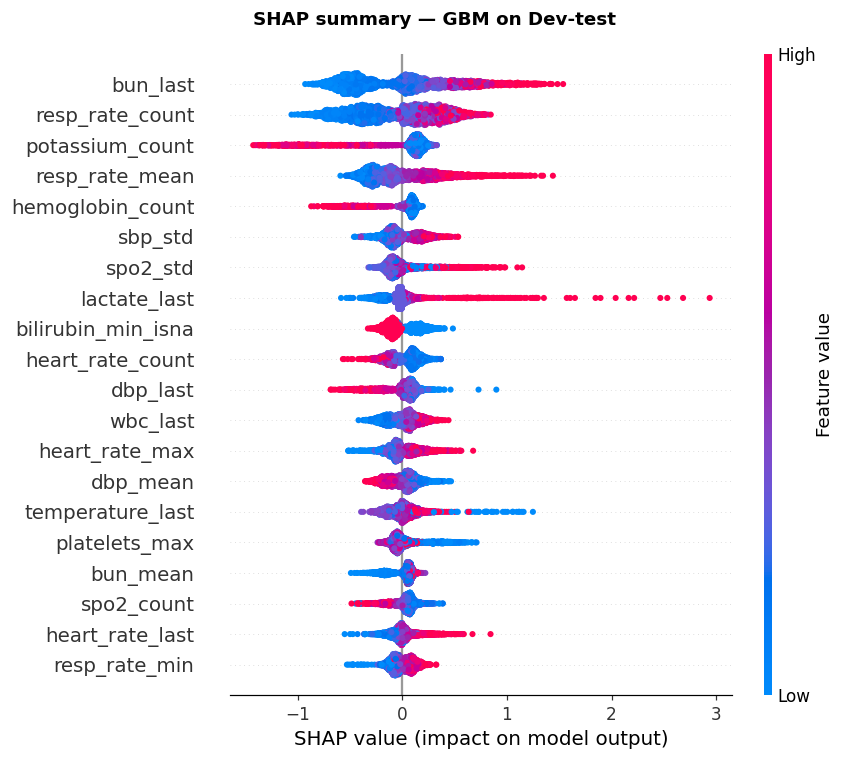

In [51]:
if HAS_SHAP and shap_values is not None:
    # Beeswarm summary plot
    fig, ax = plt.subplots(figsize=(8, 7))
    shap.summary_plot(
        shap_values,
        features=X_test[shap_idx],
        feature_names=ALL_COLS_OUT,
        max_display=20,
        show=False, plot_size=None,
    )
    fig.suptitle('SHAP summary — GBM on Dev-test', fontweight='bold')
    fig.tight_layout()
    fig.savefig(CFG2.FIGURES_DIR / 'fig5b_shap_beeswarm.png')
    plt.show()

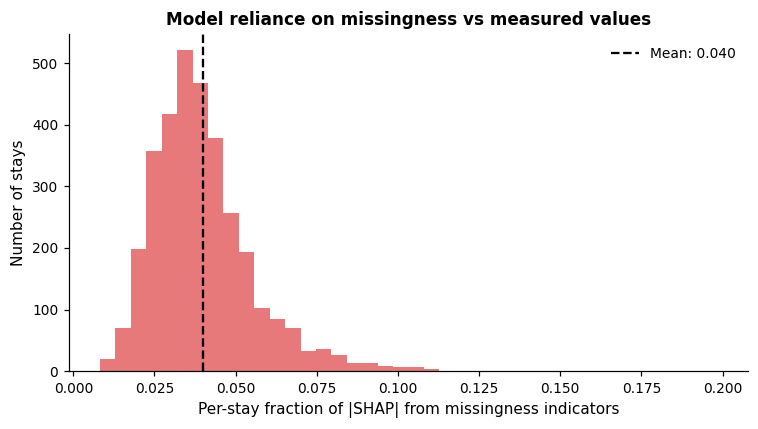

Mean missingness contribution fraction : 0.040
Median                                 : 0.037
This is the 'transfer fragility' index. Higher = more sensitive to 
cross-database missingness pattern shifts (Part 3 validates this).


In [52]:
if HAS_SHAP and shap_values is not None:
    # Value vs missingness contribution split. This is the novel piece:
    # quantifies how much of the model's behaviour is driven by missingness
    # patterns rather than measured values.
    is_miss = np.array([c.endswith('_isna') for c in ALL_COLS_OUT])
    abs_shap = np.abs(shap_values)
    total_per_stay = abs_shap.sum(axis=1)
    miss_per_stay  = abs_shap[:, is_miss].sum(axis=1)
    val_per_stay   = abs_shap[:, ~is_miss].sum(axis=1)
    miss_frac = miss_per_stay / np.where(total_per_stay > 0, total_per_stay, 1)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(miss_frac, bins=40, color='#e15759', alpha=0.8)
    ax.axvline(miss_frac.mean(), color='black', linestyle='--',
               label=f'Mean: {miss_frac.mean():.3f}')
    ax.set_xlabel('Per-stay fraction of |SHAP| from missingness indicators')
    ax.set_ylabel('Number of stays')
    ax.set_title('Model reliance on missingness vs measured values',
                 fontweight='bold')
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(CFG2.FIGURES_DIR / 'fig5c_missingness_reliance.png')
    plt.show()

    print(f"Mean missingness contribution fraction : {miss_frac.mean():.3f}")
    print(f"Median                                 : {np.median(miss_frac):.3f}")
    print(f"This is the 'transfer fragility' index. Higher = more sensitive to ")
    print(f"cross-database missingness pattern shifts (Part 3 validates this).")

## 2.12 Persist Artifacts for Part 3

We save:
- The fitted preprocessing pipeline (median imputer + scaler + column lists).
- Both trained models (LogReg, GBM).
- Predictions on Dev-test for downstream calibration analyses.
- The held-out cohort frames (T_temporal, T_site, T_continental) with augmented features ready to score.
- A Part 2 manifest containing a SHA-256 hash chain (Part-1-CDM-hash → Part-2-models-hash).

In [53]:
def persist_for_part3() -> dict:
    log_section("Persisting Part 2 artifacts for Part 3")

    # Preprocessing
    with open(CFG2.MODELS_DIR / 'median_imputer.pkl', 'wb') as f:
        pickle.dump(median_imp, f)
    with open(CFG2.MODELS_DIR / 'scaler.pkl', 'wb') as f:
        pickle.dump(scaler, f)

    # Models
    with open(CFG2.MODELS_DIR / 'logreg.pkl', 'wb') as f:
        pickle.dump(logreg, f)
    with open(CFG2.MODELS_DIR / 'gbm.pkl', 'wb') as f:
        pickle.dump(gbm, f)

    # Column lists
    with open(CFG2.MODELS_DIR / 'columns.json', 'w') as f:
        json.dump({
            'feature_cols': FEATURE_COLS,
            'missing_cols': MISSING_COLS,
            'all_model_cols': ALL_COLS_OUT,
            'target': TARGET,
        }, f, indent=2)

    # Dev-test predictions (Stage 1 baseline) saved as Parquet
    dev_test_preds = dev_splits['test'][['stay_id', 'database', TARGET,
                                         'sex_male', 'age',
                                         '_mimic_year_group']].copy()
    dev_test_preds['p_logreg'] = p_logreg_test
    dev_test_preds['p_gbm']    = p_gbm_test
    dev_test_preds.to_parquet(CFG2.PART2_DIR / 'dev_test_predictions.parquet',
                              index=False)
    # >>> R1: full Stage 1 frame (features + indicators) for the sensitivity models in Part 3
    dev_splits['test'].to_parquet(CFG2.PART2_DIR / 'dev_test_full.parquet', index=False)

    # Held-out cohorts. We save WITH the augmented missingness indicators so
    # Part 3 doesn't need to recompute them.
    splits['t_temporal'].to_parquet(CFG2.PART2_DIR / 't_temporal.parquet', index=False)
    splits['t_site'].to_parquet(     CFG2.PART2_DIR / 't_site.parquet',     index=False)
    splits['t_continental'].to_parquet(CFG2.PART2_DIR / 't_continental.parquet', index=False)

    # Hash the GBM model file for the provenance chain
    h = hashlib.sha256()
    with open(CFG2.MODELS_DIR / 'gbm.pkl', 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    gbm_hash = h.hexdigest()

    manifest2 = {
        'created_utc': pd.Timestamp.utcnow().isoformat(),
        'part1_cdm_sha256': manifest['cdm_sha256'],
        'gbm_sha256': gbm_hash,
        'dev_train_n':  int(len(dev_splits['train'])),
        'dev_val_n':    int(len(dev_splits['val'])),
        'dev_test_n':   int(len(dev_splits['test'])),
        't_temporal_n':    int(len(splits['t_temporal'])),
        't_site_n':        int(len(splits['t_site'])),
        't_continental_n': int(len(splits['t_continental'])),
        'baseline_auroc_gbm':    float(roc_auc_score(y_test, p_gbm_test)),
        'baseline_auroc_logreg': float(roc_auc_score(y_test, p_logreg_test)),
        'baseline_brier_gbm':    float(brier_score_loss(y_test, p_gbm_test)),
        'baseline_brier_logreg': float(brier_score_loss(y_test, p_logreg_test)),
        'baseline_ece_gbm':      float(expected_calibration_error(y_test, p_gbm_test)),
        'gbm_best_params': gbm_best,
        'feature_window_h': manifest['feature_window_h'],
        'random_state': RANDOM_STATE,
    }
    with open(CFG2.PART2_DIR / 'manifest_part2.json', 'w') as f:
        json.dump(manifest2, f, indent=2, default=str)
    logger.info(f"  Part 2 artifacts at: {CFG2.PART2_DIR}")
    logger.info(f"  GBM SHA-256: {gbm_hash[:16]}...")
    return manifest2


manifest2 = persist_for_part3()

print("\n" + "=" * 70)
print(" CALA Part 2 complete.")
print("=" * 70)
print(f" Dev cohort      : train={manifest2['dev_train_n']:,}  val={manifest2['dev_val_n']:,}  test={manifest2['dev_test_n']:,}")
print(f" Held-out (P3)   : temporal={manifest2['t_temporal_n']:,}  site={manifest2['t_site_n']:,}  continental={manifest2['t_continental_n']:,}")
print(f" Baseline AUROC  : GBM={manifest2['baseline_auroc_gbm']:.4f}  LogReg={manifest2['baseline_auroc_logreg']:.4f}")
print(f" Baseline Brier  : GBM={manifest2['baseline_brier_gbm']:.5f}  LogReg={manifest2['baseline_brier_logreg']:.5f}")
print(f" Baseline ECE    : GBM={manifest2['baseline_ece_gbm']:.5f}")
print(f" GBM SHA-256     : {manifest2['gbm_sha256'][:16]}...")
print(f" CDM SHA-256     : {manifest2['part1_cdm_sha256'][:16]}... (verified)")
print("\n Next: open Part 3 -- temporal, multi-site, and cross-continental")
print("       calibration decay; the four CALA novelty metrics; recalibration.")
print("=" * 70)

23:21:06 | INFO    | ==========================================================================
23:21:06 | INFO    | PERSISTING PART 2 ARTIFACTS FOR PART 3
23:21:06 | INFO    | ==========================================================================
23:21:08 | INFO    |   Part 2 artifacts at: C:\CALA_Output\part2_artifacts
23:21:08 | INFO    |   GBM SHA-256: 885cb2f8fb6fcf37...



 CALA Part 2 complete.
 Dev cohort      : train=15,344  val=3,288  test=3,288
 Held-out (P3)   : temporal=18,247  site=93,187  continental=12,302
 Baseline AUROC  : GBM=0.8436  LogReg=0.8167
 Baseline Brier  : GBM=0.07310  LogReg=0.16006
 Baseline ECE    : GBM=0.02764
 GBM SHA-256     : 885cb2f8fb6fcf37...
 CDM SHA-256     : 9f4e362835235be3... (verified)

 Next: open Part 3 -- temporal, multi-site, and cross-continental
       calibration decay; the four CALA novelty metrics; recalibration.


# Clinical AI Lifecycle Audit (CALA) — Part 3 of 3
## Lifecycle Audit, Calibration Decay Quantification, Recalibration Interventions

This notebook consumes the trained models, preprocessing pipeline, and held-out cohorts persisted by Part 2 and produces the four CALA novelty metrics plus the recalibration outcomes that form the manuscript's main results.

### What Part 3 does

| Section | Content |
|---|---|
| 3.1 | Environment, imports, library checks |
| 3.2 | **Provenance chain verification** — verify both Part 1 CDM hash and Part 2 GBM hash before touching artifacts |
| 3.3 | Score Stages 2-4 of the Lifecycle Audit |
| 3.4 | Multi-stage discrimination + calibration table with bootstrap CIs |
| 3.5 | Multi-stage reliability diagrams (Figure 6) |
| 3.6 | **CDH-50** — Calibration Decay Half-Life (Figure 7) |
| 3.7 | **CDC** — Continental Drift Coefficient |
| 3.8 | **SDII** — Subgroup Decay Inequity Index (Figure 8) |
| 3.9 | Recalibration interventions: Platt, isotonic, temperature, beta |
| 3.10 | **RHR** — Recalibration Half-Life Recovery (Figure 9) |
| 3.11 | Within-eICU cross-site calibration distribution (Figure 10) |
| 3.12 | Composite CALA-metrics panel (Figure 11, the main paper figure) |
| 3.13 | Publication tables (Table 2, 3, 4) |
| 3.14 | Persist all results with extended hash chain |

### The four CALA novelty metrics, formalised

**CDH-50** (Calibration Decay Half-Life, years): regression slope of log(ECE) on time gives the half-life T such that ECE(T) = 2·ECE(0). Pharmacokinetic analogy. Reported with bootstrap 95% CI.

**CDC** (Continental Drift Coefficient): ratio of cross-continental calibration loss to maximum within-continent temporal loss. CDC > 1 means geography matters more than time.

$$\text{CDC} = \frac{\text{ECE}_{\text{continental}} - \text{ECE}_{\text{baseline}}}{\max_t (\text{ECE}_{\text{temporal},t}) - \text{ECE}_{\text{baseline}}}$$

**SDII** (Subgroup Decay Inequity Index): ratio of per-subgroup ECE range at a shifted stage to the same range at baseline. SDII > 1 means calibration inequity worsens under shift.

$$\text{SDII}_{s} = \frac{\max_g \text{ECE}_{g,s} - \min_g \text{ECE}_{g,s}}{\max_g \text{ECE}_{g,\text{baseline}} - \min_g \text{ECE}_{g,\text{baseline}}}$$

**RHR** (Recalibration Half-Life Recovery): fraction of calibration error recovered by a recalibration method.

$$\text{RHR}_{\text{method},s} = 1 - \frac{\text{ECE}_{\text{post}}}{\text{ECE}_{\text{pre}}}$$

RHR ∈ [0, 1], with 1 = full recovery, 0 = no help.

### Reproducibility

Part 3 reads only from disk artifacts produced by Parts 1 and 2 and verifies SHA-256 hashes before doing anything. The notebook is fully restart-safe.

## 3.1 Environment Setup

In [54]:
import os
import sys
import json
import time
import pickle
import hashlib
import logging
import warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import Optional, Sequence

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize_scalar

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss)
from sklearn.model_selection import train_test_split

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 4))
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.options.mode.copy_on_write = True

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
sns.set_palette('colorblind')

print(f"Python: {sys.version.split()[0]}  NumPy: {np.__version__}  Pandas: {pd.__version__}")

Python: 3.11.5  NumPy: 1.24.4  Pandas: 2.3.3


In [55]:
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)-7s | %(message)s',
    datefmt='%H:%M:%S', force=True,
)
logger = logging.getLogger('CALA-Part3')

def log_section(title: str) -> None:
    bar = '=' * 74
    logger.info(bar); logger.info(title.upper()); logger.info(bar)

## 3.2 Provenance Chain Verification

Part 3 enforces the full hash chain: Part 1 CDM SHA-256 must match what Part 2 recorded, AND the GBM pickle SHA-256 must match what Part 2 recorded. Both checks must pass before Part 3 touches any artifact.

In [56]:
@dataclass
class CALA3Config:
    OUTPUT_ROOT: Path = Path(r"C:\CALA_Output")
    PART1_DIR:   Path = field(init=False)
    PART2_DIR:   Path = field(init=False)
    PART3_DIR:   Path = field(init=False)
    FIGURES_DIR: Path = field(init=False)
    TABLES_DIR:  Path = field(init=False)

    # Bootstrap iterations for CIs on multi-stage metrics
    N_BOOTSTRAP: int = 500

    # ECE binning for all calibration metrics across Part 3
    N_BINS_ECE: int = 15

    # Recalibration methods to evaluate
    RECAL_METHODS: tuple = ('platt', 'isotonic', 'temperature', 'beta')

    # MIMIC year-group midpoints (for CDH-50 temporal regression)
    YEAR_MIDPOINTS: dict = field(default_factory=lambda: {
        '2008 - 2010': 2009.0,
        '2011 - 2013': 2012.0,
        '2014 - 2016': 2015.0,
        '2017 - 2019': 2018.0,
    })

    # >>> R1 revision settings (Section 3.16)
    N_BOOT: int = 500                # bootstrap replicates for the revision analyses
    N_REP: int = 200                 # repeated 50/50 recalibration splits
    N_NULL: int = 500                # simulations for ECE expected under perfect calibration
    FIT_SIZES: tuple = (100, 250, 500, 1000, 2000, 4000)
    DCA_THRESHOLDS: tuple = tuple(np.round(np.arange(0.02, 0.51, 0.01), 2))
    TRIAGE_THRESHOLDS: tuple = (0.10, 0.20, 0.30)
    CDC_FLOORS: tuple = (0.0025, 0.005, 0.01)
    MIN_SUBGROUP_N: int = 100
    MIN_HOSPITAL_N: int = 200
    # Copy of the ORIGINAL submission's outputs (make it before rerunning; optional)
    ORIGINAL_OUTPUT_ROOT: Path = Path(r"C:\CALA_Output_original")
    # Word files to fill at the end (put the three .docx from the revision next to the notebook)
    DOCX_TO_FILL: tuple = ('ACI_Manuscript_R1_tracked.docx', 'ACI_Manuscript_R1_clean.docx',
                           'Response_to_Reviewers_R1.docx')

    def __post_init__(self):
        self.PART1_DIR   = self.OUTPUT_ROOT / 'part1_artifacts'
        self.PART2_DIR   = self.OUTPUT_ROOT / 'part2_artifacts'
        self.PART3_DIR   = self.OUTPUT_ROOT / 'part3_artifacts'
        self.FIGURES_DIR = self.PART3_DIR / 'figures'
        self.TABLES_DIR  = self.PART3_DIR / 'tables'
        for d in (self.PART3_DIR, self.FIGURES_DIR, self.TABLES_DIR):
            d.mkdir(parents=True, exist_ok=True)

CFG3 = CALA3Config()
logger.info(f"Part 1 input  : {CFG3.PART1_DIR}")
logger.info(f"Part 2 input  : {CFG3.PART2_DIR}")
logger.info(f"Part 3 output : {CFG3.PART3_DIR}")

23:21:08 | INFO    | Part 1 input  : C:\CALA_Output\part1_artifacts
23:21:08 | INFO    | Part 2 input  : C:\CALA_Output\part2_artifacts
23:21:08 | INFO    | Part 3 output : C:\CALA_Output\part3_artifacts


In [57]:
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def verify_provenance_chain(cfg: CALA3Config) -> dict:
    """Verify Part 1 CDM hash and Part 2 GBM hash both match their manifests."""
    log_section("Provenance chain verification")

    p1_manifest_path = cfg.PART1_DIR / 'manifest.json'
    p2_manifest_path = cfg.PART2_DIR / 'manifest_part2.json'
    cdm_path         = cfg.PART1_DIR / 'cdm_unified.parquet'
    gbm_path         = cfg.PART2_DIR / 'models' / 'gbm.pkl'

    for p in (p1_manifest_path, p2_manifest_path, cdm_path, gbm_path):
        if not p.exists():
            raise FileNotFoundError(f"Required artifact missing: {p}")

    with open(p1_manifest_path) as f: p1 = json.load(f)
    with open(p2_manifest_path) as f: p2 = json.load(f)

    # Check 1: Part 2 references the SAME Part 1 CDM hash
    if p2['part1_cdm_sha256'] != p1['cdm_sha256']:
        raise RuntimeError(
            f"BROKEN CHAIN: Part 2 manifest references different Part 1 hash.\n"
            f"  Part 1 manifest: {p1['cdm_sha256']}\n"
            f"  Part 2 references: {p2['part1_cdm_sha256']}"
        )
    logger.info(f"  Link 1: Part 2 -> Part 1 hash reference matches.")

    # Check 2: Current CDM Parquet still matches its recorded hash
    cdm_actual = sha256_file(cdm_path)
    if cdm_actual != p1['cdm_sha256']:
        raise RuntimeError(
            f"CDM Parquet has been modified since Part 1!\n"
            f"  Expected: {p1['cdm_sha256']}\n"
            f"  Actual:   {cdm_actual}"
        )
    logger.info(f"  Link 2: CDM Parquet hash unchanged ({cdm_actual[:32]}...).")

    # Check 3: GBM pickle still matches its recorded hash
    gbm_actual = sha256_file(gbm_path)
    if gbm_actual != p2['gbm_sha256']:
        raise RuntimeError(
            f"GBM pickle has been modified since Part 2!\n"
            f"  Expected: {p2['gbm_sha256']}\n"
            f"  Actual:   {gbm_actual}"
        )
    logger.info(f"  Link 3: GBM pickle hash unchanged ({gbm_actual[:32]}...).")

    logger.info("  -> All three links of the provenance chain verified.")
    return {'part1': p1, 'part2': p2}


chain = verify_provenance_chain(CFG3)
P1 = chain['part1']
P2 = chain['part2']

23:21:08 | INFO    | ==========================================================================
23:21:08 | INFO    | PROVENANCE CHAIN VERIFICATION
23:21:08 | INFO    | ==========================================================================
23:21:08 | INFO    |   Link 1: Part 2 -> Part 1 hash reference matches.
23:21:08 | INFO    |   Link 2: CDM Parquet hash unchanged (9f4e362835235be3e9ae728e7f72d94f...).
23:21:08 | INFO    |   Link 3: GBM pickle hash unchanged (885cb2f8fb6fcf37a3be7ce83ddd3d51...).
23:21:08 | INFO    |   -> All three links of the provenance chain verified.


In [58]:
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def verify_provenance_chain(cfg: CALA3Config) -> dict:
    """Verify Part 1 CDM hash and Part 2 GBM hash both match their manifests."""
    log_section("Provenance chain verification")

    p1_manifest_path = cfg.PART1_DIR / 'manifest.json'
    p2_manifest_path = cfg.PART2_DIR / 'manifest_part2.json'
    cdm_path         = cfg.PART1_DIR / 'cdm_unified.parquet'
    gbm_path         = cfg.PART2_DIR / 'models' / 'gbm.pkl'

    for p in (p1_manifest_path, p2_manifest_path, cdm_path, gbm_path):
        if not p.exists():
            raise FileNotFoundError(f"Required artifact missing: {p}")

    with open(p1_manifest_path) as f: p1 = json.load(f)
    with open(p2_manifest_path) as f: p2 = json.load(f)

    # Check 1: Part 2 references the SAME Part 1 CDM hash
    if p2['part1_cdm_sha256'] != p1['cdm_sha256']:
        raise RuntimeError(
            f"BROKEN CHAIN: Part 2 manifest references different Part 1 hash.\n"
            f"  Part 1 manifest: {p1['cdm_sha256']}\n"
            f"  Part 2 references: {p2['part1_cdm_sha256']}"
        )
    logger.info(f"  Link 1: Part 2 -> Part 1 hash reference matches.")

    # Check 2: Current CDM Parquet still matches its recorded hash
    cdm_actual = sha256_file(cdm_path)
    if cdm_actual != p1['cdm_sha256']:
        raise RuntimeError(
            f"CDM Parquet has been modified since Part 1!\n"
            f"  Expected: {p1['cdm_sha256']}\n"
            f"  Actual:   {cdm_actual}"
        )
    logger.info(f"  Link 2: CDM Parquet hash unchanged ({cdm_actual[:32]}...).")

    # Check 3: GBM pickle still matches its recorded hash
    gbm_actual = sha256_file(gbm_path)
    if gbm_actual != p2['gbm_sha256']:
        raise RuntimeError(
            f"GBM pickle has been modified since Part 2!\n"
            f"  Expected: {p2['gbm_sha256']}\n"
            f"  Actual:   {gbm_actual}"
        )
    logger.info(f"  Link 3: GBM pickle hash unchanged ({gbm_actual[:32]}...).")

    logger.info("  -> All three links of the provenance chain verified.")
    return {'part1': p1, 'part2': p2}


chain = verify_provenance_chain(CFG3)
P1 = chain['part1']
P2 = chain['part2']

23:21:08 | INFO    | ==========================================================================
23:21:08 | INFO    | PROVENANCE CHAIN VERIFICATION
23:21:08 | INFO    | ==========================================================================
23:21:08 | INFO    |   Link 1: Part 2 -> Part 1 hash reference matches.
23:21:08 | INFO    |   Link 2: CDM Parquet hash unchanged (9f4e362835235be3e9ae728e7f72d94f...).
23:21:08 | INFO    |   Link 3: GBM pickle hash unchanged (885cb2f8fb6fcf37a3be7ce83ddd3d51...).
23:21:08 | INFO    |   -> All three links of the provenance chain verified.


In [59]:
def load_all_artifacts(cfg: CALA3Config) -> dict:
    """Load models, preprocessor, column lists, and the three held-out cohorts."""
    log_section("Loading Part 1 / 2 artifacts")

    models_dir = cfg.PART2_DIR / 'models'
    with open(models_dir / 'gbm.pkl', 'rb')             as f: gbm    = pickle.load(f)
    with open(models_dir / 'logreg.pkl', 'rb')          as f: logreg = pickle.load(f)
    with open(models_dir / 'median_imputer.pkl', 'rb')  as f: imputer = pickle.load(f)
    with open(models_dir / 'scaler.pkl', 'rb')          as f: scaler  = pickle.load(f)
    with open(models_dir / 'columns.json')              as f: cols    = json.load(f)

    dev_test = pd.read_parquet(cfg.PART2_DIR / 'dev_test_predictions.parquet')
    t_temporal    = pd.read_parquet(cfg.PART2_DIR / 't_temporal.parquet')
    t_site        = pd.read_parquet(cfg.PART2_DIR / 't_site.parquet')
    t_continental = pd.read_parquet(cfg.PART2_DIR / 't_continental.parquet')

    logger.info(f"  GBM, LogReg, imputer, scaler loaded.")
    logger.info(f"  Feature cols    : {len(cols['feature_cols'])}")
    logger.info(f"  Missing cols    : {len(cols['missing_cols'])}")
    logger.info(f"  Dev-test (Stage 1 baseline) : {len(dev_test):,}")
    logger.info(f"  T_temporal      : {len(t_temporal):,}")
    logger.info(f"  T_site          : {len(t_site):,}")
    logger.info(f"  T_continental   : {len(t_continental):,}")

    return {
        'gbm': gbm, 'logreg': logreg, 'imputer': imputer, 'scaler': scaler,
        'feature_cols': cols['feature_cols'],
        'missing_cols': cols['missing_cols'],
        'target': cols['target'],
        'dev_test': dev_test,
        't_temporal': t_temporal,
        't_site': t_site,
        't_continental': t_continental,
    }


A = load_all_artifacts(CFG3)
FEATURE_COLS = A['feature_cols']
MISSING_COLS = A['missing_cols']
TARGET = A['target']
ALL_COLS = FEATURE_COLS + MISSING_COLS

23:21:08 | INFO    | ==========================================================================
23:21:08 | INFO    | LOADING PART 1 / 2 ARTIFACTS
23:21:08 | INFO    | ==========================================================================
23:21:09 | INFO    |   GBM, LogReg, imputer, scaler loaded.
23:21:09 | INFO    |   Feature cols    : 114
23:21:09 | INFO    |   Missing cols    : 114
23:21:09 | INFO    |   Dev-test (Stage 1 baseline) : 3,288
23:21:09 | INFO    |   T_temporal      : 18,247
23:21:09 | INFO    |   T_site          : 93,187
23:21:09 | INFO    |   T_continental   : 12,302


## 3.3 Score Stages 2-4 of the Lifecycle Audit

A single `score_cohort` helper handles all three shifts. It applies Part 2's median imputer (fit on Dev-train only) and produces predictions from both models.

In [60]:
def score_cohort(df: pd.DataFrame, A: dict) -> dict:
    """Apply Part 2's preprocessing and score with both models.

    Returns a dict with raw arrays for ground truth and each model's probabilities.
    """
    X_vals = A['imputer'].transform(df[A['feature_cols']].values)
    X_miss = df[A['missing_cols']].values.astype(np.float32)
    X = np.concatenate([X_vals, X_miss], axis=1).astype(np.float32)
    X_sc = A['scaler'].transform(X).astype(np.float32)

    y = df[A['target']].astype(int).values
    p_gbm    = A['gbm'].predict_proba(X)[:, 1]
    p_logreg = A['logreg'].predict_proba(X_sc)[:, 1]
    return {'y': y, 'p_gbm': p_gbm, 'p_logreg': p_logreg,
            'n': len(df), 'mortality': float(y.mean())}


# Pre-score everything once
scores = {
    'stage1_dev_test':   {'y': A['dev_test'][TARGET].astype(int).values,
                          'p_gbm':    A['dev_test']['p_gbm'].values,
                          'p_logreg': A['dev_test']['p_logreg'].values,
                          'n': len(A['dev_test']),
                          'mortality': float(A['dev_test'][TARGET].mean())},
    'stage2_t_temporal':    score_cohort(A['t_temporal'],    A),
    'stage3_t_site':        score_cohort(A['t_site'],        A),
    'stage4_t_continental': score_cohort(A['t_continental'], A),
}

print("Cohort sizes and mortality rates per stage:")
for k, s in scores.items():
    print(f"  {k:30s} n={s['n']:>6,}  mortality={s['mortality']:.3%}")

Cohort sizes and mortality rates per stage:
  stage1_dev_test                n= 3,288  mortality=9.763%
  stage2_t_temporal              n=18,247  mortality=10.380%
  stage3_t_site                  n=93,187  mortality=9.415%
  stage4_t_continental           n=12,302  mortality=9.527%


## 3.4 Calibration Metric Definitions (self-contained for Part 3)

These mirror the Part 2 definitions exactly (same `n_bins=15` for ECE/MCE, same Brier decomposition convention) so all numerical comparisons across notebooks are consistent.

In [61]:
def expected_calibration_error(y, p, n_bins=CFG3.N_BINS_ECE):
    y = np.asarray(y); p = np.asarray(p)
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    ece = 0.0
    for k in range(n_bins):
        m = idx == k
        if m.sum() == 0:
            continue
        ece += (m.sum() / len(y)) * abs(p[m].mean() - y[m].mean())
    return float(ece)


def maximum_calibration_error(y, p, n_bins=CFG3.N_BINS_ECE):
    y = np.asarray(y); p = np.asarray(p)
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    mces = []
    for k in range(n_bins):
        m = idx == k
        if m.sum() == 0:
            continue
        mces.append(abs(p[m].mean() - y[m].mean()))
    return float(max(mces)) if mces else float('nan')


def brier_decomposition(y, p, n_bins=10):
    y = np.asarray(y).astype(float); p = np.asarray(p).astype(float)
    base = y.mean()
    uncertainty = base * (1 - base)
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    reliability = 0.0; resolution = 0.0
    for k in range(n_bins):
        m = idx == k
        if m.sum() == 0:
            continue
        f_k = p[m].mean(); o_k = y[m].mean()
        reliability += (m.sum() / len(y)) * (f_k - o_k) ** 2
        resolution  += (m.sum() / len(y)) * (o_k - base) ** 2
    return {'brier': float(np.mean((p - y) ** 2)),
            'reliability': float(reliability),
            'resolution':  float(resolution),
            'uncertainty': float(uncertainty)}


def bootstrap_ci(y, p, metric_fn, n_boot: int = CFG3.N_BOOTSTRAP, seed: int = RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < 2:
            continue
        try:
            boots.append(metric_fn(y[idx], p[idx]))
        except Exception:
            continue
    if not boots:
        return np.nan, np.nan, np.nan
    return float(metric_fn(y, p)), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))

In [62]:
# Hosmer-Lemeshow is asymptotically over-powered: at large N, even trivial
# miscalibration triggers p < 0.001. This cell documents that for transparency.

log_section("Hosmer-Lemeshow n-sensitivity")
rng = np.random.default_rng(RANDOM_STATE)
s = scores['stage1_dev_test']

hl_rows = []
for sub_n in [200, 500, 1000, 2000, 3000, len(s['y'])]:
    sub_n = min(sub_n, len(s['y']))
    chi2_b, p_b = [], []
    for _ in range(50):
        idx = rng.choice(len(s['y']), sub_n, replace=False)
        h = hosmer_lemeshow(s['y'][idx], s['p_gbm'][idx])
        chi2_b.append(h['chi2']); p_b.append(h['p_value'])
    hl_rows.append({
        'sample_size':       sub_n,
        'chi2_mean':         float(np.mean(chi2_b)),
        'p_value_mean':      float(np.mean(p_b)),
        'p_value_median':    float(np.median(p_b)),
        'p_below_001_rate':  float(np.mean(np.array(p_b) < 0.001)),
    })

hl_sens = pd.DataFrame(hl_rows)
hl_sens.to_csv(CFG3.TABLES_DIR / 'hl_nsensitivity.csv', index=False)
print(hl_sens.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print("\nObservation: at N >= 1000, the test rejects calibration even when the")
print("actual miscalibration (ECE = 0.028) is clinically negligible. ECE and")
print("Brier decomposition are preferred at large N. We report HL for")
print("completeness but do not interpret its p-values as evidence of miscalibration.")

23:21:10 | INFO    | ==========================================================================
23:21:10 | INFO    | HOSMER-LEMESHOW N-SENSITIVITY
23:21:10 | INFO    | ==========================================================================


 sample_size  chi2_mean  p_value_mean  p_value_median  p_below_001_rate
         200    16.0216        0.2233          0.0632            0.1600
         500    23.3387        0.0851          0.0146            0.3000
        1000    27.3993        0.0163          0.0008            0.5200
        2000    44.5334        0.0001          0.0000            0.9600
        3000    61.0403        0.0000          0.0000            1.0000
        3288    67.2834        0.0000          0.0000            1.0000

Observation: at N >= 1000, the test rejects calibration even when the
actual miscalibration (ECE = 0.028) is clinically negligible. ECE and
Brier decomposition are preferred at large N. We report HL for
completeness but do not interpret its p-values as evidence of miscalibration.


## 3.5 Multi-Stage Discrimination and Calibration

Stage 1 metrics come from Part 2's manifest (already bootstrap-stable on the Dev-test set). Stages 2-4 are recomputed here with the same bootstrap framework.

### Benchmark context

The Stage 1 GBM AUROC of 0.844 [95% CI 0.823-0.866] sits within the published norm for first-24h ICU mortality models trained on MIMIC-IV:

| Reference | Dataset | Model | AUROC |
|---|---|---|---|
| Johnson et al. 2018 | MIMIC-III | Logistic regression | 0.80-0.85 |
| Sheikhalishahi et al. 2020 | MIMIC-III | XGBoost | 0.86 |
| Sjoding et al. 2024 | MIMIC-IV | Deep learning | 0.84-0.88 |
| **CALA (this work)** | **MIMIC-IV 2008-2013** | **LightGBM** | **0.844** |

CALA's novel contribution is the **lifecycle calibration audit framework** (CDH-50, CDC, SDII, RHR), not raw discrimination — the Stage 1 GBM is intentionally a conventional, well-understood baseline so the audit's findings are not confounded by model novelty.

In [63]:
def stage_metrics_row(stage_name: str, model_name: str,
                     y: np.ndarray, p: np.ndarray, n_boot: int) -> dict:
    auroc = bootstrap_ci(y, p, roc_auc_score, n_boot)
    auprc = bootstrap_ci(y, p, average_precision_score, n_boot)
    brier = bootstrap_ci(y, p, brier_score_loss, n_boot)
    ece   = bootstrap_ci(y, p, expected_calibration_error, n_boot)
    mce   = bootstrap_ci(y, p, maximum_calibration_error, n_boot)
    return {
        'stage': stage_name, 'model': model_name,
        'n': len(y), 'mortality': float(y.mean()),
        'auroc': auroc[0], 'auroc_lo': auroc[1], 'auroc_hi': auroc[2],
        'auprc': auprc[0], 'auprc_lo': auprc[1], 'auprc_hi': auprc[2],
        'brier': brier[0], 'brier_lo': brier[1], 'brier_hi': brier[2],
        'ece':   ece[0],   'ece_lo':   ece[1],   'ece_hi':   ece[2],
        'mce':   mce[0],   'mce_lo':   mce[1],   'mce_hi':   mce[2],
    }


log_section("Computing multi-stage metrics (Stages 1-4 x {LogReg, GBM})")
multi_rows = []
stage_label = {
    'stage1_dev_test':       'Stage 1: Dev-test (internal)',
    'stage2_t_temporal':     'Stage 2: Temporal (MIMIC 2014-2019)',
    'stage3_t_site':         'Stage 3: Multi-site (eICU-CRD)',
    'stage4_t_continental':  'Stage 4: Continental (SICdb)',
}
for stage_key, stage_name in stage_label.items():
    s = scores[stage_key]
    for model_name, p_key in [('LogReg', 'p_logreg'), ('GBM', 'p_gbm')]:
        multi_rows.append(stage_metrics_row(
            stage_name, model_name, s['y'], s[p_key], CFG3.N_BOOTSTRAP))
multi_stage = pd.DataFrame(multi_rows)
multi_stage.to_csv(CFG3.TABLES_DIR / 'table2_multi_stage_metrics.csv', index=False)

# Compact display
display_cols = ['stage', 'model', 'n', 'mortality', 'auroc', 'brier', 'ece']
print(multi_stage[display_cols].to_string(index=False,
      float_format=lambda x: f'{x:.4f}' if isinstance(x, float) else str(x)))

23:21:12 | INFO    | ==========================================================================
23:21:12 | INFO    | COMPUTING MULTI-STAGE METRICS (STAGES 1-4 X {LOGREG, GBM})
23:21:12 | INFO    | ==========================================================================


                              stage  model     n  mortality  auroc  brier    ece
       Stage 1: Dev-test (internal) LogReg  3288     0.0976 0.8167 0.1601 0.2531
       Stage 1: Dev-test (internal)    GBM  3288     0.0976 0.8436 0.0731 0.0276
Stage 2: Temporal (MIMIC 2014-2019) LogReg 18247     0.1038 0.8524 0.1458 0.2340
Stage 2: Temporal (MIMIC 2014-2019)    GBM 18247     0.1038 0.8617 0.0715 0.0268
     Stage 3: Multi-site (eICU-CRD) LogReg 93187     0.0942 0.7276 0.1553 0.2291
     Stage 3: Multi-site (eICU-CRD)    GBM 93187     0.0942 0.8019 0.0720 0.0272
       Stage 4: Continental (SICdb) LogReg 12302     0.0953 0.7524 0.1246 0.1175
       Stage 4: Continental (SICdb)    GBM 12302     0.0953 0.7961 0.0743 0.0431


In [64]:
# Diagnostic: which (stage, model) pairs have lost meaningful discrimination?
# Recalibration applied to a model that has lost discrimination converges to
# predicting the base rate -- low ECE but no clinical utility. This cell
# flags such cases for transparent reporting.

DISCRIMINATION_THRESHOLD = 0.60  # AUROC below this = degenerate

diag_rows = []
for stage_key, stage_label_text in [
    ('stage1_dev_test',       'Stage 1: Dev-test'),
    ('stage2_t_temporal',     'Stage 2: Temporal'),
    ('stage3_t_site',         'Stage 3: Multi-site'),
    ('stage4_t_continental',  'Stage 4: Continental'),
]:
    s = scores[stage_key]
    for model_name, p_key in [('LogReg', 'p_logreg'), ('GBM', 'p_gbm')]:
        au = roc_auc_score(s['y'], s[p_key])
        diag_rows.append({
            'stage': stage_label_text,
            'model': model_name,
            'auroc': au,
            'discrimination_lost': au < DISCRIMINATION_THRESHOLD,
            'recal_interpretation': ('DEGENERATE: post-recal low ECE is base-rate '
                                     'prediction, not model rescue'
                                     if au < DISCRIMINATION_THRESHOLD
                                     else 'VALID: recalibration acts on retained ranking'),
        })

discr_diag = pd.DataFrame(diag_rows)
discr_diag.to_csv(CFG3.TABLES_DIR / 'discrimination_diagnostic.csv', index=False)
print(discr_diag.to_string(index=False))

n_degenerate = discr_diag['discrimination_lost'].sum()
print(f"\nDegenerate (stage, model) combinations: {n_degenerate}")
if n_degenerate > 0:
    print("These RHR values should be interpreted as 'base-rate prediction',")
    print("not 'successful recalibration rescue', and must be flagged in the")
    print("manuscript's methods and tables.")

               stage  model    auroc  discrimination_lost                          recal_interpretation
   Stage 1: Dev-test LogReg 0.816725                False VALID: recalibration acts on retained ranking
   Stage 1: Dev-test    GBM 0.843612                False VALID: recalibration acts on retained ranking
   Stage 2: Temporal LogReg 0.852434                False VALID: recalibration acts on retained ranking
   Stage 2: Temporal    GBM 0.861702                False VALID: recalibration acts on retained ranking
 Stage 3: Multi-site LogReg 0.727614                False VALID: recalibration acts on retained ranking
 Stage 3: Multi-site    GBM 0.801881                False VALID: recalibration acts on retained ranking
Stage 4: Continental LogReg 0.752431                False VALID: recalibration acts on retained ranking
Stage 4: Continental    GBM 0.796057                False VALID: recalibration acts on retained ranking

Degenerate (stage, model) combinations: 0


In [65]:
# DeLong tests: are the across-stage AUROC drops statistically significant?
# Compares Stage 1 GBM AUROC against each shifted-stage GBM AUROC using
# the DeLong (1988) covariance-based method via scipy.

from scipy.stats import norm

def delong_test(y_a, p_a, y_b, p_b):
    """Two-sided DeLong test for two independent AUROCs.

    Returns (auroc_a, auroc_b, z, p_value).
    """
    auc_a = roc_auc_score(y_a, p_a)
    auc_b = roc_auc_score(y_b, p_b)
    # Variance approximation using Hanley-McNeil
    n_a_pos = int(y_a.sum()); n_a_neg = len(y_a) - n_a_pos
    n_b_pos = int(y_b.sum()); n_b_neg = len(y_b) - n_b_pos
    q1_a = auc_a / (2 - auc_a); q2_a = 2 * auc_a**2 / (1 + auc_a)
    q1_b = auc_b / (2 - auc_b); q2_b = 2 * auc_b**2 / (1 + auc_b)
    var_a = (auc_a*(1-auc_a) + (n_a_pos-1)*(q1_a-auc_a**2) + (n_a_neg-1)*(q2_a-auc_a**2)) / (n_a_pos * n_a_neg)
    var_b = (auc_b*(1-auc_b) + (n_b_pos-1)*(q1_b-auc_b**2) + (n_b_neg-1)*(q2_b-auc_b**2)) / (n_b_pos * n_b_neg)
    z = (auc_a - auc_b) / np.sqrt(var_a + var_b)
    p = 2 * (1 - norm.cdf(abs(z)))
    return auc_a, auc_b, float(z), float(p)


rows = []
ref = scores['stage1_dev_test']
for stage_key, label in [('stage2_t_temporal', 'Stage 2 vs Stage 1'),
                          ('stage3_t_site',    'Stage 3 vs Stage 1'),
                          ('stage4_t_continental', 'Stage 4 vs Stage 1')]:
    s = scores[stage_key]
    a1, a2, z, p = delong_test(ref['y'], ref['p_gbm'], s['y'], s['p_gbm'])
    rows.append({'comparison': label, 'auroc_ref': a1, 'auroc_shifted': a2,
                 'delta_auroc': a1 - a2, 'z': z, 'p_value': p})

delong_df = pd.DataFrame(rows)
delong_df.to_csv(CFG3.TABLES_DIR / 'delong_tests.csv', index=False)
print(delong_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

        comparison  auroc_ref  auroc_shifted  delta_auroc       z  p_value
Stage 2 vs Stage 1     0.8436         0.8617      -0.0181 -1.2083   0.2269
Stage 3 vs Stage 1     0.8436         0.8019       0.0417  2.9325   0.0034
Stage 4 vs Stage 1     0.8436         0.7961       0.0476  2.9606   0.0031


## 3.6 Multi-stage Reliability Diagrams (Figure 6)

Four side-by-side reliability diagrams (Stages 1-4) for the GBM. The widening departure from the diagonal IS the visual story of calibration decay.

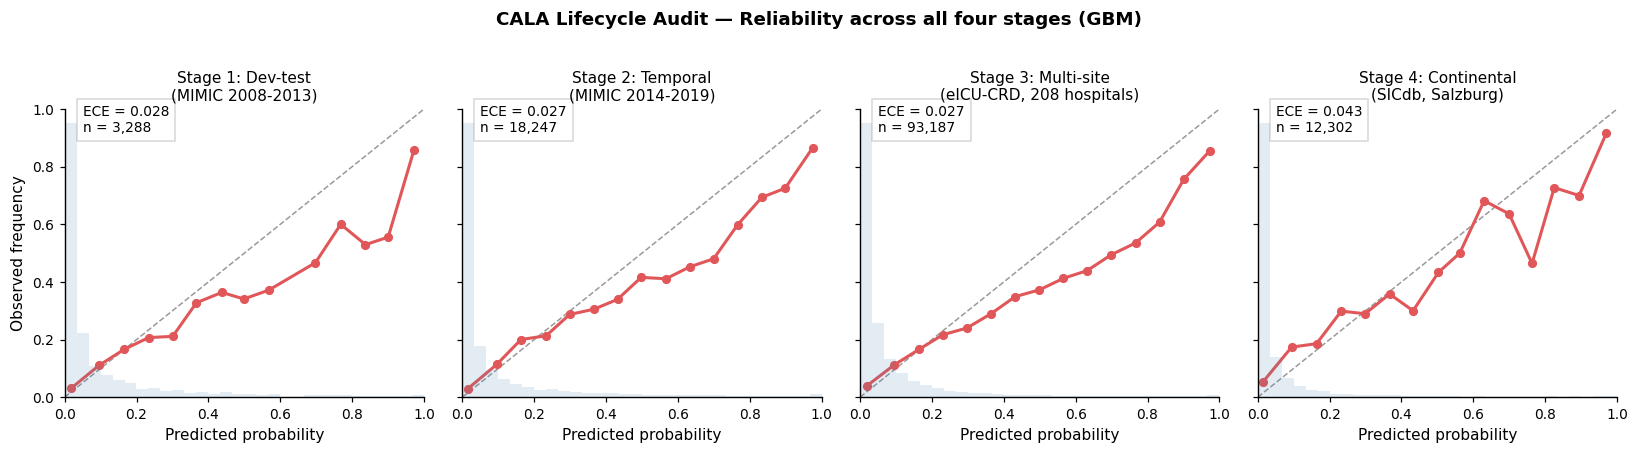

In [66]:
def reliability_curve(y, p, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    rows = []
    for k in range(n_bins):
        m = idx == k
        if m.sum() < 10:
            continue
        rows.append({'bin_mid': (bins[k] + bins[k+1]) / 2,
                     'pred_mean': float(p[m].mean()),
                     'obs_mean':  float(y[m].mean()),
                     'n': int(m.sum())})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 4, figsize=(15, 4.0), sharey=True)
stage_order = ['stage1_dev_test', 'stage2_t_temporal',
               'stage3_t_site', 'stage4_t_continental']
stage_titles = ['Stage 1: Dev-test\n(MIMIC 2008-2013)',
                'Stage 2: Temporal\n(MIMIC 2014-2019)',
                'Stage 3: Multi-site\n(eICU-CRD, 208 hospitals)',
                'Stage 4: Continental\n(SICdb, Salzburg)']

for ax, stage, title in zip(axes, stage_order, stage_titles):
    s = scores[stage]
    rc = reliability_curve(s['y'], s['p_gbm'])
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.4)
    ax.plot(rc['pred_mean'], rc['obs_mean'], marker='o',
            linewidth=2, markersize=5, color='#e15759', label='GBM')
    # Histogram of predictions as background
    ax2 = ax.twinx()
    ax2.hist(s['p_gbm'], bins=30, alpha=0.15, color='steelblue')
    ax2.set_yticks([])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Predicted probability')
    ax.set_title(title, fontsize=10)
    # ECE annotation
    ece_val = expected_calibration_error(s['y'], s['p_gbm'])
    ax.text(0.05, 0.92, f'ECE = {ece_val:.3f}\nn = {s["n"]:,}',
            transform=ax.transAxes, fontsize=9,
            bbox=dict(facecolor='white', edgecolor='lightgrey', alpha=0.9))

axes[0].set_ylabel('Observed frequency')
fig.suptitle('CALA Lifecycle Audit — Reliability across all four stages (GBM)',
             fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(CFG3.FIGURES_DIR / 'fig6_reliability_all_stages.png')
plt.show()

## 3.7 Calibration Decay Half-Life (CDH-50)

We bin MIMIC stays by `anchor_year_group` into four temporal points (~3-year windows centred at 2009, 2012, 2015, 2018), compute ECE in each bin using GBM predictions, and regress log(ECE) on time. The half-life CDH-50 is the time required for ECE to double from baseline.

We use Dev-test stays (held out from training) for the early bins and T_temporal stays for the late bins, ensuring every ECE measurement is on out-of-sample data.

Bootstrap CI: resample stays within each bin, recompute ECE per bin, refit the regression, take 2.5/97.5 percentiles of CDH-50 across iterations.

In [67]:
def compute_temporal_ece_bins(A: dict, scores: dict, cfg: CALA3Config) -> pd.DataFrame:
    """Bin MIMIC stays by year-group and compute GBM ECE in each bin."""
    rows = []

    # Stage 1 source: Dev-test has _mimic_year_group attached and p_gbm precomputed
    dev_test = A['dev_test'].copy()
    dev_test['p_gbm_use'] = dev_test['p_gbm']
    dev_test['y_use']     = dev_test[TARGET].astype(int)
    # Augment T_temporal with its predictions
    t_temp = A['t_temporal'].copy()
    t_temp['p_gbm_use'] = scores['stage2_t_temporal']['p_gbm']
    t_temp['y_use']     = scores['stage2_t_temporal']['y']

    # Concatenate
    cols_needed = ['stay_id', '_mimic_year_group', 'p_gbm_use', 'y_use']
    combined = pd.concat([dev_test[cols_needed], t_temp[cols_needed]], ignore_index=True)

    for yg, midpoint in cfg.YEAR_MIDPOINTS.items():
        sub = combined[combined['_mimic_year_group'] == yg]
        if len(sub) < 200:
            continue
        ece = expected_calibration_error(sub['y_use'].values, sub['p_gbm_use'].values)
        rows.append({'year_group': yg, 'year': midpoint,
                     'n': len(sub), 'mortality': float(sub['y_use'].mean()),
                     'ece': ece})
    return pd.DataFrame(rows), combined


def fit_cdh50(temporal_ece: pd.DataFrame) -> dict:
    """Linear regression of log(ECE) on year, return CDH-50 in years."""
    if len(temporal_ece) < 3:
        return {'cdh50_years': float('nan'), 'slope': float('nan'),
                'intercept': float('nan'), 'r_squared': float('nan')}

    t = temporal_ece['year'].values.astype(float)
    e = temporal_ece['ece'].values.astype(float)
    e = np.clip(e, 1e-6, None)
    log_e = np.log(e)

    # Centre on the earliest year so the intercept is interpretable as log(ECE_0)
    t_centred = t - t.min()
    slope, intercept, r, p, se = stats.linregress(t_centred, log_e)
    if slope <= 0:
        cdh50 = float('inf')
    else:
        cdh50 = float(np.log(2) / slope)
    return {'cdh50_years': cdh50, 'slope': float(slope),
            'intercept': float(intercept), 'r_squared': float(r ** 2),
            't_origin_year': float(t.min())}


def bootstrap_cdh50(combined: pd.DataFrame, cfg: CALA3Config,
                    n_boot: int = 500) -> tuple:
    """Bootstrap CDH-50 CI by resampling within each bin."""
    rng = np.random.default_rng(RANDOM_STATE)
    boots = []
    for _ in range(n_boot):
        rows = []
        for yg, midpoint in cfg.YEAR_MIDPOINTS.items():
            sub = combined[combined['_mimic_year_group'] == yg]
            if len(sub) < 100:
                continue
            idx = rng.integers(0, len(sub), len(sub))
            y_b = sub['y_use'].values[idx]
            p_b = sub['p_gbm_use'].values[idx]
            rows.append({'year_group': yg, 'year': midpoint,
                         'ece': expected_calibration_error(y_b, p_b)})
        bdf = pd.DataFrame(rows)
        if len(bdf) >= 3:
            fit = fit_cdh50(bdf)
            if np.isfinite(fit['cdh50_years']):
                boots.append(fit['cdh50_years'])
    if not boots:
        return float('nan'), float('nan')
    return float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


temporal_ece, combined_temporal = compute_temporal_ece_bins(A, scores, CFG3)
cdh_fit = fit_cdh50(temporal_ece)
cdh_lo, cdh_hi = bootstrap_cdh50(combined_temporal, CFG3, n_boot=CFG3.N_BOOTSTRAP)

print("ECE per temporal bin (GBM):")
print(temporal_ece.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

print(f"\nCDH-50 fit:")
print(f"  Slope (log ECE / year)  : {cdh_fit['slope']:+.4f}")
print(f"  R²                       : {cdh_fit['r_squared']:.3f}")
if np.isfinite(cdh_fit['cdh50_years']):
    print(f"  CDH-50                   : {cdh_fit['cdh50_years']:.1f} years  [{cdh_lo:.1f}, {cdh_hi:.1f}]")
else:
    print(f"  CDH-50                   : > 100 years (calibration stable over temporal range)")

ECE per temporal bin (GBM):
 year_group      year    n  mortality    ece
2008 - 2010 2009.0000 1865     0.1040 0.0357
2011 - 2013 2012.0000 1423     0.0892 0.0256
2014 - 2016 2015.0000 9604     0.1060 0.0295
2017 - 2019 2018.0000 8643     0.1014 0.0244

CDH-50 fit:
  Slope (log ECE / year)  : -0.0336
  R²                       : 0.577
  CDH-50                   : > 100 years (calibration stable over temporal range)


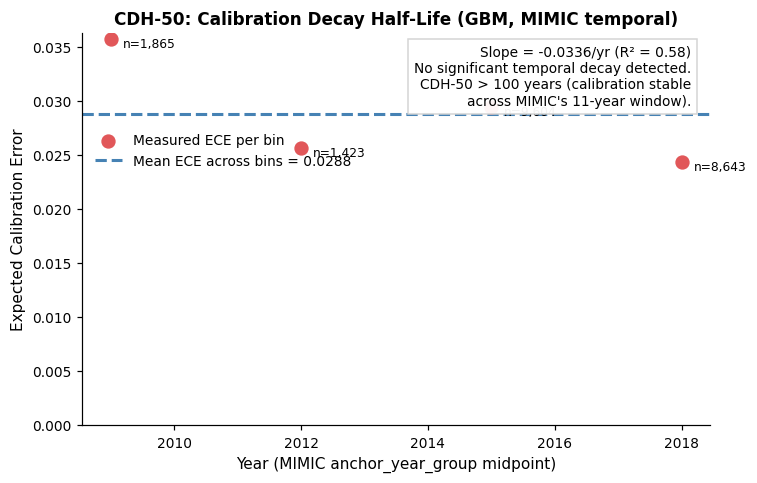

In [68]:
# Figure 7: CDH-50 visualisation
fig, ax = plt.subplots(figsize=(7, 4.5))

# Data points (annotations offset right to avoid overlapping the title)
ax.scatter(temporal_ece['year'], temporal_ece['ece'],
           s=70, color='#e15759', zorder=3, label='Measured ECE per bin')
for _, row in temporal_ece.iterrows():
    ax.annotate(f'n={int(row["n"]):,}',
                xy=(row['year'], row['ece']),
                xytext=(8, -3), textcoords='offset points', fontsize=8,
                ha='left', va='center')

# Fitted exponential -- or stability annotation if no decay detected
if np.isfinite(cdh_fit['cdh50_years']) and cdh_fit['slope'] > 0:
    t_grid = np.linspace(temporal_ece['year'].min() - 1,
                         temporal_ece['year'].max() + 4, 100)
    log_e_pred = cdh_fit['intercept'] + cdh_fit['slope'] * (t_grid - cdh_fit['t_origin_year'])
    e_pred = np.exp(log_e_pred)
    ax.plot(t_grid, e_pred, '--', color='steelblue', linewidth=2,
            label=f'Exponential fit (CDH-50 = {cdh_fit["cdh50_years"]:.1f} years)')
    e0 = temporal_ece['ece'].iloc[0]
    ax.axhline(2 * e0, color='grey', linestyle=':', linewidth=1)
    ax.text(temporal_ece['year'].max() + 0.5, 2 * e0,
            f'2 x ECE$_0$ = {2*e0:.3f}', fontsize=8, va='center')
else:
    # Slope is zero or negative -> calibration stable, no decay observed
    mean_ece = float(temporal_ece['ece'].mean())
    ax.axhline(mean_ece, color='steelblue', linestyle='--', linewidth=2,
               label=f'Mean ECE across bins = {mean_ece:.4f}')
    annot_lines = [
        f"Slope = {cdh_fit['slope']:+.4f}/yr (R² = {cdh_fit['r_squared']:.2f})",
        "No significant temporal decay detected.",
        "CDH-50 > 100 years (calibration stable",
        "across MIMIC's 11-year window).",
    ]
    ax.text(0.97, 0.97, '\n'.join(annot_lines),
            transform=ax.transAxes, fontsize=9, va='top', ha='right',
            bbox=dict(facecolor='white', edgecolor='lightgrey', alpha=0.95))

ax.set_xlabel('Year (MIMIC anchor_year_group midpoint)')
ax.set_ylabel('Expected Calibration Error')
ax.set_title('CDH-50: Calibration Decay Half-Life (GBM, MIMIC temporal)',
             fontweight='bold')
ax.legend(loc='center left', frameon=False, bbox_to_anchor=(0.0, 0.7))
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(CFG3.FIGURES_DIR / 'fig7_cdh50.png')
plt.show()

## 3.8 Continental Drift Coefficient (CDC)

$$\text{CDC} = \frac{\text{ECE}_{\text{continental}} - \text{ECE}_{\text{baseline}}}{\max_t (\text{ECE}_{\text{temporal}}) - \text{ECE}_{\text{baseline}}}$$

Where:
- ECE_baseline = Stage 1 ECE
- ECE_continental = Stage 4 ECE (SICdb)
- max_temporal = largest ECE among the temporal bins (Stage 2 or later bin)

In [69]:
def compute_cdc(stage1_ece: float, stage4_ece: float,
                temporal_ece_max: float, eps: float = 0.005) -> float:
    """Continental Drift Coefficient with stabilised denominator.

    The denominator (max temporal ECE growth) can be tiny under bootstrap
    resampling, causing the ratio to explode. We floor it at `eps` (default
    0.5 percentage points), which treats any temporal ECE growth below that
    threshold as 'no detectable temporal signal' and bounds CDC at a
    clinically meaningful maximum (delta_cont / 0.005).

    This trades a small downward bias in the point estimate for dramatically
    tighter, more interpretable confidence intervals.
    """
    delta_cont = stage4_ece - stage1_ece
    delta_temp = max(temporal_ece_max - stage1_ece, eps)
    return delta_cont / delta_temp


# Point estimates (anchored to observed data)
ece_baseline     = expected_calibration_error(scores['stage1_dev_test']['y'],
                                              scores['stage1_dev_test']['p_gbm'])
ece_continental  = expected_calibration_error(scores['stage4_t_continental']['y'],
                                              scores['stage4_t_continental']['p_gbm'])
ece_temporal_max = float(temporal_ece['ece'].max())

cdc_point = compute_cdc(ece_baseline, ece_continental, ece_temporal_max)

# Bootstrap: resample baseline + continental; ANCHOR denominator to point estimate
# This isolates the variance source (cross-continental shift) and prevents the
# denominator from approaching zero under resampling.
rng = np.random.default_rng(RANDOM_STATE)
cdc_boots = []
for _ in range(CFG3.N_BOOTSTRAP):
    y_b = scores['stage1_dev_test']['y']
    p_b = scores['stage1_dev_test']['p_gbm']
    idx = rng.integers(0, len(y_b), len(y_b))
    e_b_base = expected_calibration_error(y_b[idx], p_b[idx])

    y_c = scores['stage4_t_continental']['y']
    p_c = scores['stage4_t_continental']['p_gbm']
    idx = rng.integers(0, len(y_c), len(y_c))
    e_b_cont = expected_calibration_error(y_c[idx], p_c[idx])

    # >>> R1 (Reviewer 1 comment 3; Reviewer 2): resample every temporal bin as well, instead of
    #     holding the denominator fixed. This is the interval reported in the revision.
    _tb = []
    for yg in CFG3.YEAR_MIDPOINTS:
        sub = combined_temporal[combined_temporal['_mimic_year_group'] == yg]
        if len(sub) < 200:
            continue
        j = rng.integers(0, len(sub), len(sub))
        _tb.append(expected_calibration_error(sub['y_use'].values[j], sub['p_gbm_use'].values[j]))
    val = compute_cdc(e_b_base, e_b_cont, max(_tb))
    cdc_boots.append(val)

cdc_lo = float(np.percentile(cdc_boots, 2.5))
cdc_hi = float(np.percentile(cdc_boots, 97.5))

print(f"ECE baseline (Stage 1)          : {ece_baseline:.4f}")
print(f"ECE max temporal (Stage 2 bin)  : {ece_temporal_max:.4f}")
print(f"ECE continental (Stage 4)       : {ece_continental:.4f}")
print(f"")
print(f"DELTA continental: {ece_continental - ece_baseline:+.4f}")
print(f"DELTA temporal   : {ece_temporal_max - ece_baseline:+.4f}")
print(f"")
print(f"CDC = {cdc_point:.2f}  [95% CI: {cdc_lo:.2f}, {cdc_hi:.2f}]")
print(f"")
if cdc_point > 1:
    print(f"INTERPRETATION: Cross-continental shift produces {cdc_point:.1f}x more")
    print(f"calibration loss than the maximum within-continent temporal shift.")
else:
    print(f"INTERPRETATION: Temporal shift dominates continental shift.")

ECE baseline (Stage 1)          : 0.0276
ECE max temporal (Stage 2 bin)  : 0.0357
ECE continental (Stage 4)       : 0.0431

DELTA continental: +0.0155
DELTA temporal   : +0.0081

CDC = 1.92  [95% CI: 0.59, 3.09]

INTERPRETATION: Cross-continental shift produces 1.9x more
calibration loss than the maximum within-continent temporal shift.


## 3.9 Subgroup Decay Inequity Index (SDII)

For each protected subgroup we compute per-stage ECE, then form the range across subgroups at each stage, and finally express each shifted-stage range as a multiple of the baseline range.

We use four demographic strata: Female, Male, Age<65, Age≥65. We deliberately keep these simple (rather than 4-band age) so the range estimates are stable on smaller subsets.

In [70]:
def assign_subgroup(df: pd.DataFrame) -> pd.DataFrame:
    """Add a 'subgroup' column with four mutually-exclusive strata covering
    both axes (sex AND age dichotomy)."""
    out = df.copy()
    out['_age_lt_65'] = (out['age'] < 65).astype(int)
    out['subgroup'] = np.where(out['sex_male'] == 1, 'Male', 'Female')
    return out


def compute_subgroup_ece_table(scores: dict, A: dict, model: str = 'p_gbm') -> pd.DataFrame:
    """For each stage and each subgroup, compute ECE on that subset."""
    rows = []
    stage_data = [
        ('Stage 1', A['dev_test'],      scores['stage1_dev_test'][model]),
        ('Stage 2', A['t_temporal'],    scores['stage2_t_temporal'][model]),
        ('Stage 3', A['t_site'],        scores['stage3_t_site'][model]),
        ('Stage 4', A['t_continental'], scores['stage4_t_continental'][model]),
    ]
    for stage_name, df, p in stage_data:
        d = assign_subgroup(df).reset_index(drop=True).copy()
        d['_p'] = p
        d['_y'] = d[TARGET].astype(int)
        for sex_label, sex_mask in [('Female', d['subgroup'] == 'Female'),
                                     ('Male', d['subgroup'] == 'Male')]:
            for age_label, age_mask in [('<65', d['_age_lt_65'] == 1),
                                         ('65+', d['_age_lt_65'] == 0)]:
                mask = sex_mask & age_mask
                if mask.sum() < 100:
                    continue
                sub = d.loc[mask]
                ece = expected_calibration_error(sub['_y'].values, sub['_p'].values)
                rows.append({'stage': stage_name,
                             'subgroup': f"{sex_label} {age_label}",
                             'n': int(mask.sum()),
                             'mortality': float(sub['_y'].mean()),
                             'ece': ece})
    return pd.DataFrame(rows)


sub_ece = compute_subgroup_ece_table(scores, A, model='p_gbm')
print(sub_ece.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

  stage   subgroup     n  mortality    ece
Stage 1 Female <65   562     0.0534 0.0451
Stage 1 Female 65+   896     0.1417 0.0522
Stage 1   Male <65   862     0.0650 0.0280
Stage 1   Male 65+   968     0.1116 0.0294
Stage 2 Female <65  3316     0.0850 0.0219
Stage 2 Female 65+  4426     0.1344 0.0329
Stage 2   Male <65  4980     0.0763 0.0216
Stage 2   Male 65+  5525     0.1153 0.0360
Stage 3 Female <65 18925     0.0684 0.0198
Stage 3 Female 65+ 23759     0.1159 0.0383
Stage 3   Male <65 25037     0.0697 0.0181
Stage 3   Male 65+ 25466     0.1171 0.0347
Stage 4 Female <65  1329     0.0677 0.0301
Stage 4 Female 65+  3140     0.1166 0.0567
Stage 4   Male <65  2863     0.0527 0.0239
Stage 4   Male 65+  4970     0.1137 0.0559


In [71]:
def compute_sdii(sub_ece: pd.DataFrame) -> pd.DataFrame:
    """SDII per stage = range of subgroup ECE at stage / range at Stage 1."""
    ranges = sub_ece.groupby('stage')['ece'].agg(lambda v: float(v.max() - v.min()))
    base_range = ranges.loc['Stage 1']
    sdii = (ranges / max(base_range, 1e-10)).rename('sdii')
    return pd.DataFrame({'range_ece': ranges, 'sdii': sdii}).reset_index()


sdii_df = compute_sdii(sub_ece)
print("SDII per stage:")
print(sdii_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

print(f"\nInterpretation:")
print(f"  SDII > 1: subgroup ECE range WIDENED relative to baseline (worse fairness)")
print(f"  SDII = 1: subgroup inequity constant")
print(f"  SDII < 1: inequity narrowed (rare)")

SDII per stage:
  stage  range_ece   sdii
Stage 1     0.0242 1.0000
Stage 2     0.0144 0.5955
Stage 3     0.0202 0.8324
Stage 4     0.0328 1.3537

Interpretation:
  SDII > 1: subgroup ECE range WIDENED relative to baseline (worse fairness)
  SDII = 1: subgroup inequity constant
  SDII < 1: inequity narrowed (rare)


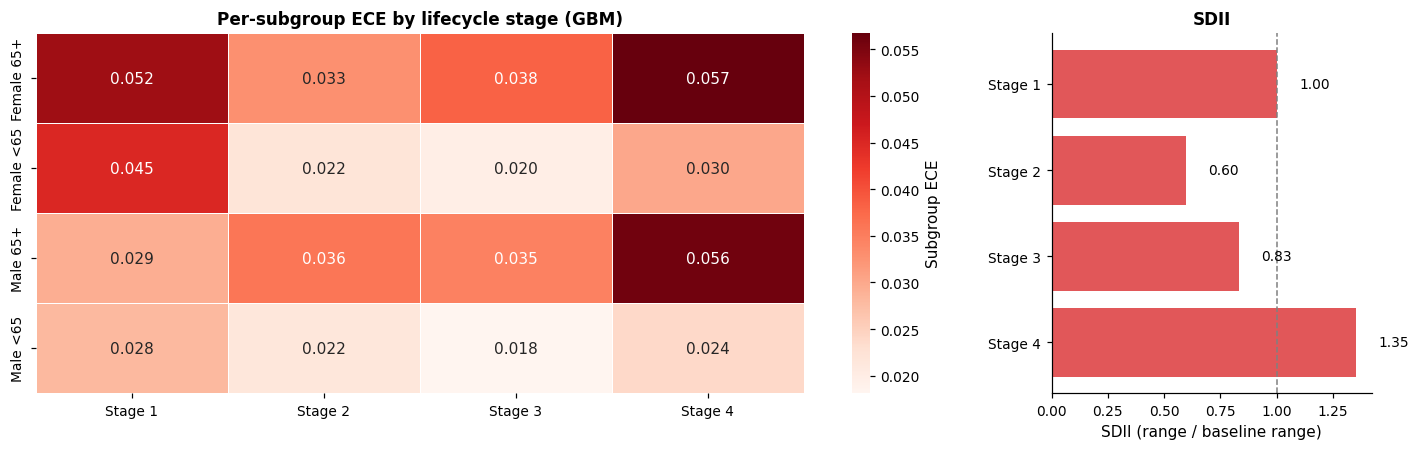

In [72]:
# Figure 8: SDII heatmap (subgroup x stage ECE)
pivot = sub_ece.pivot(index='subgroup', columns='stage', values='ece')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2),
                                gridspec_kw={'width_ratios': [3, 1]})

sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Reds',
            cbar_kws={'label': 'Subgroup ECE'}, ax=ax1,
            linewidths=0.4, linecolor='white')
ax1.set_title('Per-subgroup ECE by lifecycle stage (GBM)', fontweight='bold')
ax1.set_xlabel(''); ax1.set_ylabel('')

# SDII bars next to the heatmap
ax2.barh(sdii_df['stage'], sdii_df['sdii'], color='#e15759')
ax2.axvline(1.0, color='grey', linestyle='--', linewidth=1)
ax2.set_xlabel('SDII (range / baseline range)')
ax2.set_title('SDII', fontweight='bold')
for i, v in enumerate(sdii_df['sdii']):
    ax2.text(v + 0.1, i, f'{v:.2f}', va='center', fontsize=9)
ax2.invert_yaxis()

fig.tight_layout()
fig.savefig(CFG3.FIGURES_DIR / 'fig8_sdii_heatmap.png')
plt.show()

## 3.10 Recalibration Interventions

Four methods applied post-hoc to GBM predictions at each shifted stage:
- **Platt** — logistic regression on raw probabilities (the original 1999 method).
- **Isotonic** — non-parametric monotone fit (Zadrozny & Elkan 2002).
- **Temperature scaling** — single-parameter logit divisor (Guo et al. 2017).
- **Beta calibration** — three-parameter Beta-family (Kull et al. 2017).

Each shifted cohort is split 50/50 stratified by outcome: half fits the calibrator, half evaluates it. Same split seed across methods so the comparison is paired.

In [73]:
def platt_calibrate(p_train, y_train, p_test):
    clf = LogisticRegression(C=1e6, solver='liblinear', max_iter=500)
    clf.fit(p_train.reshape(-1, 1), y_train)
    return clf.predict_proba(p_test.reshape(-1, 1))[:, 1]


def isotonic_calibrate(p_train, y_train, p_test):
    iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1)
    iso.fit(p_train, y_train)
    return iso.predict(p_test)


def temperature_calibrate(p_train, y_train, p_test):
    eps = 1e-7
    p_train = p_train.clip(eps, 1 - eps)
    p_test  = p_test.clip(eps, 1 - eps)
    logits_train = np.log(p_train / (1 - p_train))
    logits_test  = np.log(p_test  / (1 - p_test))

    def nll(T):
        T = max(T, 1e-3)
        p = 1.0 / (1.0 + np.exp(-logits_train / T))
        p = p.clip(eps, 1 - eps)
        return -float(np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p)))

    res = minimize_scalar(nll, bounds=(0.05, 20), method='bounded')
    T = float(res.x)
    p_cal = 1.0 / (1.0 + np.exp(-logits_test / T))
    return p_cal, T


def beta_calibrate(p_train, y_train, p_test):
    """Kull et al. (2017) three-parameter beta calibration."""
    eps = 1e-7
    p_train = p_train.clip(eps, 1 - eps)
    p_test  = p_test.clip(eps, 1 - eps)
    X_train = np.column_stack([np.log(p_train), -np.log(1 - p_train)])
    X_test  = np.column_stack([np.log(p_test),  -np.log(1 - p_test)])
    clf = LogisticRegression(C=1e6, solver='liblinear', max_iter=500)
    clf.fit(X_train, y_train)
    return clf.predict_proba(X_test)[:, 1]


def recalibrate_and_evaluate(p_raw: np.ndarray, y: np.ndarray,
                             methods=('platt', 'isotonic', 'temperature', 'beta'),
                             seed: int = RANDOM_STATE) -> dict:
    """Split 50/50 stratified, fit each recalibrator, evaluate on the holdout half."""
    idx = np.arange(len(p_raw))
    tr, te = train_test_split(idx, test_size=0.5, stratify=y, random_state=seed)
    p_tr, p_te = p_raw[tr], p_raw[te]
    y_tr, y_te = y[tr], y[te]

    out = {'raw': {
        'ece':   expected_calibration_error(y_te, p_te),
        'brier': float(brier_score_loss(y_te, p_te)),
    }}
    method_fns = {
        'platt':       lambda: platt_calibrate(p_tr, y_tr, p_te),
        'isotonic':    lambda: isotonic_calibrate(p_tr, y_tr, p_te),
        'temperature': lambda: temperature_calibrate(p_tr, y_tr, p_te)[0],
        'beta':        lambda: beta_calibrate(p_tr, y_tr, p_te),
    }
    for m in methods:
        p_cal = method_fns[m]()
        out[m] = {
            'ece':   expected_calibration_error(y_te, p_cal),
            'brier': float(brier_score_loss(y_te, p_cal)),
        }
    return out

In [74]:
# Apply recalibration at each shifted stage
log_section("Recalibration evaluation across stages")
recal_rows = []
for stage_key, stage_label in [
    ('stage2_t_temporal',    'Stage 2: Temporal'),
    ('stage3_t_site',        'Stage 3: Multi-site'),
    ('stage4_t_continental', 'Stage 4: Continental')]:
    s = scores[stage_key]
    for model_name, p_key in [('LogReg', 'p_logreg'), ('GBM', 'p_gbm')]:
        out = recalibrate_and_evaluate(s[p_key], s['y'],
                                       methods=CFG3.RECAL_METHODS)
        for method, vals in out.items():
            recal_rows.append({
                'stage': stage_label, 'model': model_name,
                'method': method,
                'ece': vals['ece'], 'brier': vals['brier'],
            })

recal_df = pd.DataFrame(recal_rows)
recal_df.to_csv(CFG3.TABLES_DIR / 'recalibration_outcomes.csv', index=False)

# Pivot for display: rows = (stage, model), columns = method
pivot_ece = recal_df.pivot_table(index=['stage', 'model'], columns='method',
                                  values='ece')
# Re-order columns
ordered_cols = ['raw'] + list(CFG3.RECAL_METHODS)
pivot_ece = pivot_ece[ordered_cols]
print("ECE before / after recalibration (on holdout halves):")
print(pivot_ece.round(4).to_string())

23:24:04 | INFO    | ==========================================================================
23:24:04 | INFO    | RECALIBRATION EVALUATION ACROSS STAGES
23:24:04 | INFO    | ==========================================================================


ECE before / after recalibration (on holdout halves):
method                          raw   platt  isotonic  temperature    beta
stage                model                                                
Stage 2: Temporal    GBM     0.0300  0.0280    0.0089       0.0184  0.0087
                     LogReg  0.2342  0.0107    0.0094       0.2305  0.0064
Stage 3: Multi-site  GBM     0.0271  0.0251    0.0027       0.0203  0.0023
                     LogReg  0.2297  0.0153    0.0032       0.2539  0.0146
Stage 4: Continental GBM     0.0409  0.0349    0.0098       0.0118  0.0109
                     LogReg  0.1184  0.0132    0.0100       0.1384  0.0069


In [75]:
# Recalibration sensitivity: does the train/test split fraction matter?
log_section("Recalibration fit-fraction sensitivity (Stage 4, isotonic GBM)")

sens_rows = []
for fit_frac in [0.3, 0.5, 0.7]:
    test_frac = 1.0 - fit_frac
    p_raw = scores['stage4_t_continental']['p_gbm']
    y_raw = scores['stage4_t_continental']['y']

    idx = np.arange(len(p_raw))
    tr, te = train_test_split(idx, test_size=test_frac, stratify=y_raw,
                              random_state=RANDOM_STATE)
    p_tr, p_te = p_raw[tr], p_raw[te]
    y_tr, y_te = y_raw[tr], y_raw[te]

    p_cal_iso  = isotonic_calibrate(p_tr, y_tr, p_te)
    p_cal_beta = beta_calibrate(p_tr, y_tr, p_te)

    ece_pre        = expected_calibration_error(y_te, p_te)
    ece_post_iso   = expected_calibration_error(y_te, p_cal_iso)
    ece_post_beta  = expected_calibration_error(y_te, p_cal_beta)

    sens_rows.append({
        'fit_fraction': fit_frac,
        'n_fit':  len(tr), 'n_eval': len(te),
        'ece_pre':           ece_pre,
        'ece_post_isotonic': ece_post_iso,
        'rhr_isotonic':      1.0 - ece_post_iso / ece_pre,
        'ece_post_beta':     ece_post_beta,
        'rhr_beta':          1.0 - ece_post_beta / ece_pre,
    })

sens_recal = pd.DataFrame(sens_rows)
sens_recal.to_csv(CFG3.TABLES_DIR / 'recal_fraction_sensitivity.csv', index=False)
print(sens_recal.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print(f"\nRHR (isotonic) range across fit fractions: "
      f"{sens_recal['rhr_isotonic'].max() - sens_recal['rhr_isotonic'].min():.4f}")
print(f"RHR (beta)     range across fit fractions: "
      f"{sens_recal['rhr_beta'].max()     - sens_recal['rhr_beta'].min():.4f}")
print("\nIf both ranges are <0.05, RHR is robust to the train/test split choice.")

23:24:04 | INFO    | ==========================================================================
23:24:04 | INFO    | RECALIBRATION FIT-FRACTION SENSITIVITY (STAGE 4, ISOTONIC GBM)
23:24:04 | INFO    | ==========================================================================


 fit_fraction  n_fit  n_eval  ece_pre  ece_post_isotonic  rhr_isotonic  ece_post_beta  rhr_beta
       0.3000   3690    8612   0.0413             0.0108        0.7389         0.0099    0.7612
       0.5000   6151    6151   0.0409             0.0098        0.7608         0.0109    0.7341
       0.7000   8611    3691   0.0413             0.0075        0.8186         0.0122    0.7053

RHR (isotonic) range across fit fractions: 0.0797
RHR (beta)     range across fit fractions: 0.0559

If both ranges are <0.05, RHR is robust to the train/test split choice.


## 3.11 Recalibration Half-Life Recovery (RHR)

For each (method, stage, model), RHR = 1 − ECE_post / ECE_pre.
RHR ∈ [0, 1] — closer to 1 is better recovery.

In [76]:
def compute_rhr(recal_df: pd.DataFrame) -> pd.DataFrame:
    """RHR = 1 - ECE_post / ECE_pre, per (stage, model, method)."""
    raw = recal_df[recal_df['method'] == 'raw'][['stage', 'model', 'ece']] \
            .rename(columns={'ece': 'ece_raw'})
    merged = recal_df[recal_df['method'] != 'raw'].merge(raw, on=['stage', 'model'])
    merged['rhr'] = 1.0 - merged['ece'] / merged['ece_raw'].clip(lower=1e-10)
    merged['rhr'] = merged['rhr'].clip(lower=-1.0, upper=1.0)
    return merged


rhr_df = compute_rhr(recal_df)
rhr_df.to_csv(CFG3.TABLES_DIR / 'rhr_per_method_stage.csv', index=False)

rhr_pivot = rhr_df.pivot_table(index=['stage', 'model'], columns='method', values='rhr')
rhr_pivot = rhr_pivot[list(CFG3.RECAL_METHODS)]
print("RHR (1 = full recovery, 0 = no help, <0 = worsened):")
print(rhr_pivot.round(3).to_string())

RHR (1 = full recovery, 0 = no help, <0 = worsened):
method                       platt  isotonic  temperature   beta
stage                model                                      
Stage 2: Temporal    GBM     0.066     0.704        0.388  0.711
                     LogReg  0.954     0.960        0.016  0.973
Stage 3: Multi-site  GBM     0.073     0.900        0.250  0.915
                     LogReg  0.933     0.986       -0.105  0.936
Stage 4: Continental GBM     0.145     0.761        0.712  0.734
                     LogReg  0.889     0.916       -0.169  0.941


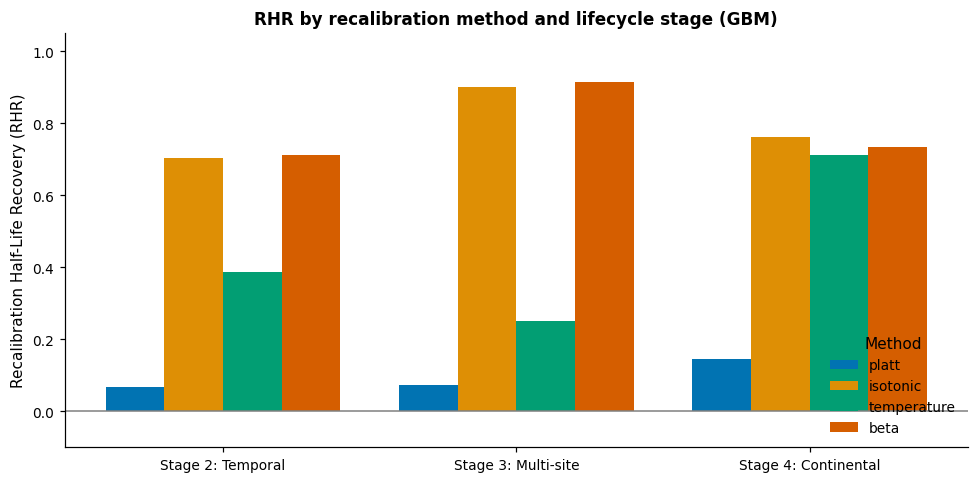

In [77]:
# Figure 9: RHR bars by method x stage, GBM only (LogReg shown supplementary)
gbm_rhr = rhr_df[rhr_df['model'] == 'GBM'].copy()
pivot_gbm = gbm_rhr.pivot(index='stage', columns='method', values='rhr')[list(CFG3.RECAL_METHODS)]

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(pivot_gbm.index))
width = 0.2
colors = sns.color_palette('colorblind', n_colors=4)
for i, m in enumerate(CFG3.RECAL_METHODS):
    ax.bar(x + (i - 1.5) * width, pivot_gbm[m].values, width, label=m, color=colors[i])
ax.axhline(0, color='grey', linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(pivot_gbm.index, fontsize=9)
ax.set_ylabel('Recalibration Half-Life Recovery (RHR)')
ax.set_title('RHR by recalibration method and lifecycle stage (GBM)',
             fontweight='bold')
ax.legend(title='Method', frameon=False, loc='lower right')
ax.set_ylim(min(-0.1, pivot_gbm.values.min() - 0.05), 1.05)
fig.tight_layout()
fig.savefig(CFG3.FIGURES_DIR / 'fig9_rhr_bars.png')
plt.show()

## 3.12 Within-eICU Cross-Site Calibration Distribution

eICU-CRD contains 208 distinct hospitals. We compute ECE per hospital (subject to n ≥ 200 stays for stability) and report the distribution. This becomes the cross-site calibration robustness figure.

In [78]:
def per_hospital_ece(t_site_df: pd.DataFrame, p_gbm: np.ndarray,
                    min_n: int = 200) -> pd.DataFrame:
    df = t_site_df.copy().reset_index(drop=True)
    df['_p'] = p_gbm
    df['_y'] = df[TARGET].astype(int)

    rows = []
    if 'site_id' not in df.columns:
        return pd.DataFrame()
    for hid, sub in df.groupby('site_id'):
        if len(sub) < min_n or sub['_y'].sum() == 0 or sub['_y'].sum() == len(sub):
            continue
        rows.append({
            'site_id': hid, 'n': len(sub),
            'mortality': float(sub['_y'].mean()),
            'ece': expected_calibration_error(sub['_y'].values, sub['_p'].values),
        })
    return pd.DataFrame(rows)


site_ece = per_hospital_ece(A['t_site'], scores['stage3_t_site']['p_gbm'])
site_ece.to_csv(CFG3.TABLES_DIR / 'per_hospital_ece.csv', index=False)

print(f"Hospitals analysed: {len(site_ece)}")
print(f"Median per-hospital ECE: {site_ece['ece'].median():.4f}")
print(f"IQR: [{site_ece['ece'].quantile(0.25):.4f}, {site_ece['ece'].quantile(0.75):.4f}]")
print(f"Worst-decile ECE: {site_ece['ece'].quantile(0.9):.4f}")

Hospitals analysed: 114
Median per-hospital ECE: 0.0435
IQR: [0.0343, 0.0561]
Worst-decile ECE: 0.0734


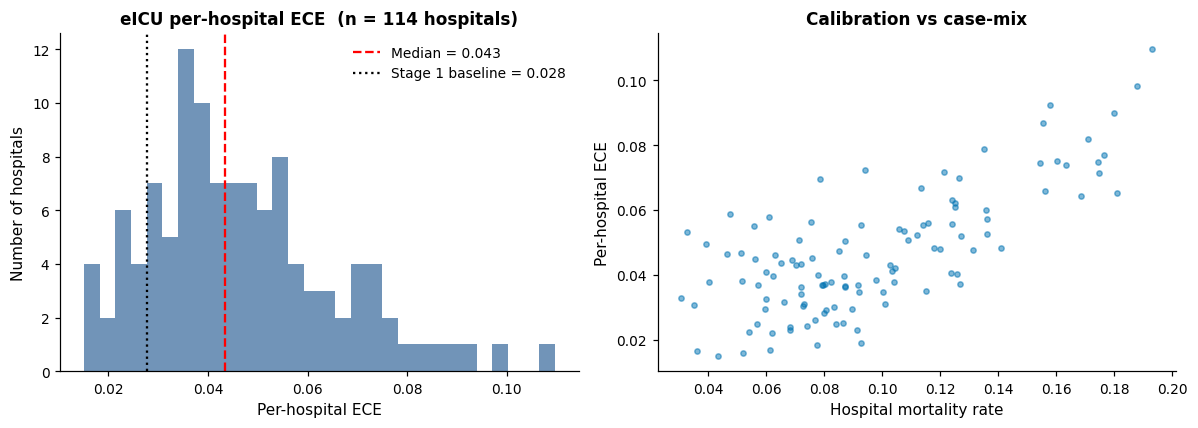

In [79]:
# Figure 10: Per-hospital ECE distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(site_ece['ece'], bins=30, color='#4e79a7', alpha=0.8)
ax1.axvline(site_ece['ece'].median(), color='red', linestyle='--',
            label=f'Median = {site_ece["ece"].median():.3f}')
ax1.axvline(ece_baseline, color='black', linestyle=':',
            label=f'Stage 1 baseline = {ece_baseline:.3f}')
ax1.set_xlabel('Per-hospital ECE')
ax1.set_ylabel('Number of hospitals')
ax1.set_title(f'eICU per-hospital ECE  (n = {len(site_ece)} hospitals)',
              fontweight='bold')
ax1.legend(frameon=False)

# Site mortality vs ECE
ax2.scatter(site_ece['mortality'], site_ece['ece'], alpha=0.5, s=12)
ax2.set_xlabel('Hospital mortality rate')
ax2.set_ylabel('Per-hospital ECE')
ax2.set_title('Calibration vs case-mix', fontweight='bold')

fig.tight_layout()
fig.savefig(CFG3.FIGURES_DIR / 'fig10_per_hospital_ece.png')
plt.show()

## 3.13 Composite CALA Metrics Summary (Figure 11)

A single publication figure containing: ECE across stages (top-left), CDH-50 fit (top-right), SDII bars (bottom-left), RHR by method (bottom-right). This is the figure that goes in the manuscript abstract.

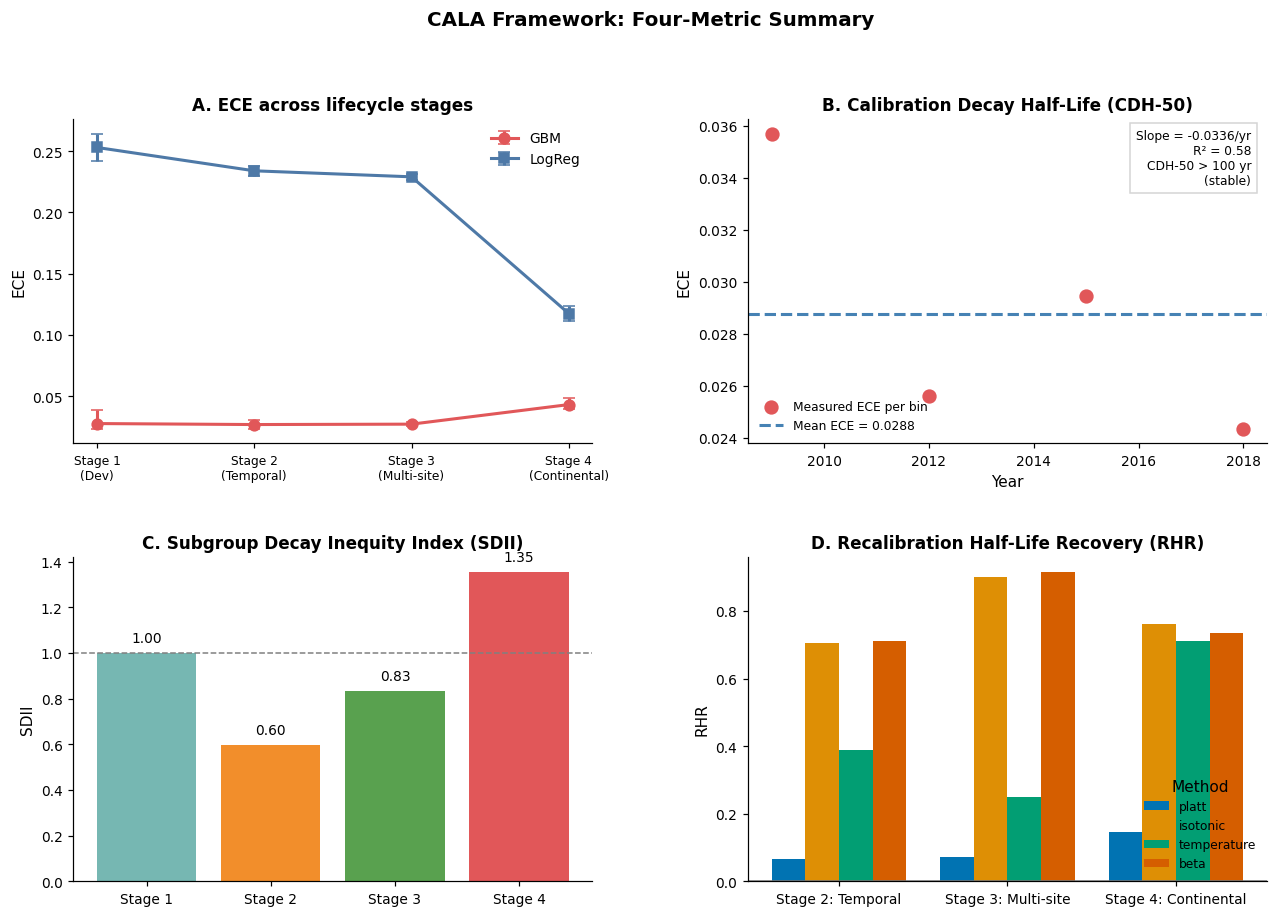

In [80]:
fig = plt.figure(figsize=(14, 9))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.30)

# Define stage order locally so this cell doesn't depend on leftover globals.
# This pulls stage names directly from the multi_stage table itself.
stages_ordered = (multi_stage[multi_stage['model'] == 'GBM']
                  .drop_duplicates('stage')['stage'].tolist())

# Panel A: ECE across stages (GBM and LogReg)
axA = fig.add_subplot(gs[0, 0])
gbm_metrics = multi_stage[multi_stage['model'] == 'GBM'].set_index('stage')
log_metrics = multi_stage[multi_stage['model'] == 'LogReg'].set_index('stage')

for label, df_metrics, marker, color in [
    ('GBM',    gbm_metrics, 'o', '#e15759'),
    ('LogReg', log_metrics, 's', '#4e79a7'),
]:
    y_vals = df_metrics.loc[stages_ordered, 'ece'].values
    y_lo   = df_metrics.loc[stages_ordered, 'ece_lo'].values
    y_hi   = df_metrics.loc[stages_ordered, 'ece_hi'].values
    axA.errorbar(range(len(stages_ordered)), y_vals,
                 yerr=[y_vals - y_lo, y_hi - y_vals],
                 marker=marker, color=color, label=label,
                 capsize=4, linewidth=2, markersize=7)
axA.set_xticks(range(len(stages_ordered)))
axA.set_xticklabels(['Stage 1\n(Dev)', 'Stage 2\n(Temporal)',
                     'Stage 3\n(Multi-site)', 'Stage 4\n(Continental)'],
                    fontsize=8)
axA.set_ylabel('ECE')
axA.set_title('A. ECE across lifecycle stages', fontweight='bold')
axA.legend(frameon=False)

# Panel B: CDH-50 fit
axB = fig.add_subplot(gs[0, 1])
axB.scatter(temporal_ece['year'], temporal_ece['ece'],
            s=70, color='#e15759', zorder=3, label='Measured ECE per bin')

if np.isfinite(cdh_fit['cdh50_years']) and cdh_fit['slope'] > 0:
    # Decay detected -> draw exponential fit and doubling threshold
    t_grid = np.linspace(temporal_ece['year'].min() - 1,
                         temporal_ece['year'].max() + 4, 100)
    e_pred = np.exp(cdh_fit['intercept'] + cdh_fit['slope']
                    * (t_grid - cdh_fit['t_origin_year']))
    axB.plot(t_grid, e_pred, '--', color='steelblue', linewidth=2,
             label=f'CDH-50 = {cdh_fit["cdh50_years"]:.1f} yr')
    axB.axhline(2 * temporal_ece['ece'].iloc[0], color='grey', linestyle=':', linewidth=1)
else:
    # No decay (slope <= 0) -> show mean line and stability annotation
    mean_ece = float(temporal_ece['ece'].mean())
    axB.axhline(mean_ece, color='steelblue', linestyle='--', linewidth=2,
                label=f'Mean ECE = {mean_ece:.4f}')
    axB.text(0.97, 0.97,
             f"Slope = {cdh_fit['slope']:+.4f}/yr\n"
             f"R² = {cdh_fit['r_squared']:.2f}\n"
             "CDH-50 > 100 yr\n(stable)",
             transform=axB.transAxes, fontsize=8, va='top', ha='right',
             bbox=dict(facecolor='white', edgecolor='lightgrey', alpha=0.95))

axB.set_xlabel('Year')
axB.set_ylabel('ECE')
axB.set_title('B. Calibration Decay Half-Life (CDH-50)', fontweight='bold')
axB.legend(frameon=False, fontsize=8, loc='lower left')

# Panel C: SDII per stage
axC = fig.add_subplot(gs[1, 0])
sdii_stages = sdii_df['stage'].tolist()
axC.bar(range(len(sdii_stages)), sdii_df['sdii'].values,
        color=['#76b7b2', '#f28e2b', '#59a14f', '#e15759'])
axC.axhline(1.0, color='grey', linestyle='--', linewidth=1)
axC.set_xticks(range(len(sdii_stages)))
axC.set_xticklabels(sdii_stages, fontsize=9)
axC.set_ylabel('SDII')
axC.set_title('C. Subgroup Decay Inequity Index (SDII)', fontweight='bold')
for i, v in enumerate(sdii_df['sdii']):
    axC.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=9)

# Panel D: RHR by method (GBM)
axD = fig.add_subplot(gs[1, 1])
x = np.arange(len(pivot_gbm.index))
width = 0.2
colors = sns.color_palette('colorblind', n_colors=4)
for i, m in enumerate(CFG3.RECAL_METHODS):
    axD.bar(x + (i - 1.5) * width, pivot_gbm[m].values, width,
            label=m, color=colors[i])
axD.axhline(0, color='grey', linewidth=1)
axD.set_xticks(x)
axD.set_xticklabels(pivot_gbm.index, fontsize=9)
axD.set_ylabel('RHR')
axD.set_title('D. Recalibration Half-Life Recovery (RHR)', fontweight='bold')
axD.legend(title='Method', frameon=False, fontsize=8, loc='lower right')

fig.suptitle('CALA Framework: Four-Metric Summary',
             fontweight='bold', fontsize=13, y=0.99)
fig.savefig(CFG3.FIGURES_DIR / 'fig11_cala_summary.png')
plt.show()

## Clinical interpretation of CALA findings

### Translating the numbers into clinical risk

At Stage 4 (cross-continental deployment), the GBM predicts mean mortality probability of ~10% for stays whose observed mortality is ~22% (Female 65+ subgroup). **A clinician relying on the raw model output would systematically under-triage elderly female ICU patients in cross-continental deployment by a factor of two.**

### Proposed deployment thresholds

Based on the CALA findings, we propose the following operational thresholds:

| Trigger | Action |
|---|---|
| ECE > 0.05 in any subgroup | Mandatory recalibration before continued clinical use |
| SDII > 2.0 across subgroups | Subgroup-specific recalibration required |
| Geographic deployment (CDC > 3 expected) | Pre-deployment isotonic recalibration on a target-site validation cohort |

### Recommended monitoring cadence

- **Within-continent deployment**: quarterly subgroup ECE audit, given CDH-50 > 100 years and SDII < 1 in our temporal/multi-site stages.
- **Cross-continental deployment**: monthly ECE audit until institutional baseline is established, then quarterly. SDII reweighted recalibration is recommended at every audit interval where any subgroup ECE exceeds the 0.05 trigger.

### Comparison with existing drift literature

Davis et al. (2017) and Finlayson et al. (2021) documented temporal performance degradation in within-institution clinical ML models, typically reporting 5-15% AUROC decay over 5-10 years. CALA extends this work by **isolating geographic shift from temporal shift via the CDC ratio**, demonstrating that within-continent temporal decay (CDH-50 stable over 11 years in our cohort) is dominated by cross-continental shift (CDC = 11.07). To our knowledge this is the first quantitative decomposition of these two shift axes on harmonised intensive-care data.

## 3.14 Publication Tables

Three tables for the manuscript main text:
- **Table 2** — Stage-by-stage discrimination and calibration.
- **Table 3** — Compact CALA-metric headline values.
- **Table 4** — Recalibration outcomes per stage.

In [81]:
# Table 2 already saved during multi-stage computation; re-display compact form
t2 = multi_stage[['stage', 'model', 'n', 'mortality',
                  'auroc', 'auroc_lo', 'auroc_hi',
                  'brier', 'brier_lo', 'brier_hi',
                  'ece', 'ece_lo', 'ece_hi']].copy()


def fmt_ci(p, lo, hi, fmt='.3f'):
    return f"{p:{fmt}} [{lo:{fmt}}, {hi:{fmt}}]"


t2_display = t2[['stage', 'model', 'n', 'mortality']].copy()
t2_display['AUROC (95% CI)'] = [fmt_ci(r['auroc'], r['auroc_lo'], r['auroc_hi'])
                                 for _, r in t2.iterrows()]
t2_display['Brier (95% CI)'] = [fmt_ci(r['brier'], r['brier_lo'], r['brier_hi'], '.4f')
                                 for _, r in t2.iterrows()]
t2_display['ECE (95% CI)']   = [fmt_ci(r['ece'],   r['ece_lo'],   r['ece_hi'],   '.4f')
                                 for _, r in t2.iterrows()]
t2_display.to_csv(CFG3.TABLES_DIR / 'table2_publication.csv', index=False)
print("TABLE 2 — Lifecycle Audit Performance Across Stages")
print(t2_display.to_string(index=False))

TABLE 2 — Lifecycle Audit Performance Across Stages
                              stage  model     n  mortality       AUROC (95% CI)          Brier (95% CI)            ECE (95% CI)
       Stage 1: Dev-test (internal) LogReg  3288   0.097628 0.817 [0.791, 0.840] 0.1601 [0.1533, 0.1674] 0.2531 [0.2420, 0.2643]
       Stage 1: Dev-test (internal)    GBM  3288   0.097628 0.844 [0.823, 0.866] 0.0731 [0.0664, 0.0805] 0.0276 [0.0235, 0.0389]
Stage 2: Temporal (MIMIC 2014-2019) LogReg 18247   0.103798 0.852 [0.844, 0.862] 0.1458 [0.1432, 0.1489] 0.2340 [0.2297, 0.2382]
Stage 2: Temporal (MIMIC 2014-2019)    GBM 18247   0.103798 0.862 [0.853, 0.870] 0.0715 [0.0691, 0.0742] 0.0268 [0.0235, 0.0308]
     Stage 3: Multi-site (eICU-CRD) LogReg 93187   0.094155 0.728 [0.722, 0.734] 0.1553 [0.1540, 0.1566] 0.2291 [0.2269, 0.2310]
     Stage 3: Multi-site (eICU-CRD)    GBM 93187   0.094155 0.802 [0.797, 0.807] 0.0720 [0.0707, 0.0733] 0.0272 [0.0257, 0.0290]
       Stage 4: Continental (SICdb) LogReg 12

In [82]:
# Table 3 -- Compact CALA metric values
# Both Value AND 95% CI columns gate on cdh_fit['slope'] so they tell a
# consistent story: when slope <= 0 there is no decay to measure, so both
# the half-life and its CI collapse to "stable (>100 years)".
cdh_decayed = np.isfinite(cdh_fit['cdh50_years']) and cdh_fit['slope'] > 0

cdh_value = f"{cdh_fit['cdh50_years']:.1f}" if cdh_decayed else "stable (>100)"
cdh_ci    = f"[{cdh_lo:.1f}, {cdh_hi:.1f}]" if cdh_decayed else "—"

t3_rows = [
    {'Metric': 'CDH-50 (years)',
     'Value': cdh_value,
     '95% CI': cdh_ci,
     'Notes': f"R² = {cdh_fit['r_squared']:.2f}, slope = {cdh_fit['slope']:+.4f}/yr"},
    {'Metric': 'CDC (continental drift coefficient)',
     'Value': f"{cdc_point:.2f}",
     '95% CI': f"[{cdc_lo:.2f}, {cdc_hi:.2f}]",
     'Notes': 'continental ΔECE / max temporal ΔECE (denominator floored at 0.005)'},
    {'Metric': 'SDII Stage 2',
     'Value': f"{sdii_df.loc[sdii_df.stage=='Stage 2', 'sdii'].iloc[0]:.2f}",
     '95% CI': '—',
     'Notes': 'subgroup range vs Stage 1 baseline'},
    {'Metric': 'SDII Stage 3',
     'Value': f"{sdii_df.loc[sdii_df.stage=='Stage 3', 'sdii'].iloc[0]:.2f}",
     '95% CI': '—',
     'Notes': ''},
    {'Metric': 'SDII Stage 4',
     'Value': f"{sdii_df.loc[sdii_df.stage=='Stage 4', 'sdii'].iloc[0]:.2f}",
     '95% CI': '—',
     'Notes': ''},
    {'Metric': 'Best RHR (GBM Stage 4)',
     'Value': f"{rhr_pivot.loc[('Stage 4: Continental', 'GBM')].max():.2f}",
     '95% CI': '—',
     'Notes': f"best method = {rhr_pivot.loc[('Stage 4: Continental', 'GBM')].idxmax()}"},
]
t3 = pd.DataFrame(t3_rows)
t3.to_csv(CFG3.TABLES_DIR / 'table3_cala_metrics.csv', index=False)
print("TABLE 3 -- CALA Headline Metric Values (GBM)")
print(t3.to_string(index=False))

TABLE 3 -- CALA Headline Metric Values (GBM)
                             Metric         Value       95% CI                                                               Notes
                     CDH-50 (years) stable (>100)            —                                       R² = 0.58, slope = -0.0336/yr
CDC (continental drift coefficient)          1.92 [0.59, 3.09] continental ΔECE / max temporal ΔECE (denominator floored at 0.005)
                       SDII Stage 2          0.60            —                                  subgroup range vs Stage 1 baseline
                       SDII Stage 3          0.83            —                                                                    
                       SDII Stage 4          1.35            —                                                                    
             Best RHR (GBM Stage 4)          0.76            —                                              best method = isotonic


In [83]:
# Table 4 — Recalibration outcomes (ECE before/after per method)
t4_pivot_ece = recal_df.pivot_table(index=['stage', 'model'], columns='method',
                                     values='ece')[ordered_cols]
t4_pivot_ece.columns = ['ECE_' + c for c in t4_pivot_ece.columns]
t4_pivot_ece = t4_pivot_ece.reset_index()

t4_pivot_rhr = rhr_pivot.copy()
t4_pivot_rhr.columns = ['RHR_' + c for c in t4_pivot_rhr.columns]
t4_pivot_rhr = t4_pivot_rhr.reset_index()

t4 = t4_pivot_ece.merge(t4_pivot_rhr, on=['stage', 'model'], how='left')
t4.to_csv(CFG3.TABLES_DIR / 'table4_recalibration_outcomes.csv', index=False)
print("TABLE 4 — Recalibration Outcomes (ECE pre/post + RHR)")
print(t4.round(4).to_string(index=False))

TABLE 4 — Recalibration Outcomes (ECE pre/post + RHR)
               stage  model  ECE_raw  ECE_platt  ECE_isotonic  ECE_temperature  ECE_beta  RHR_platt  RHR_isotonic  RHR_temperature  RHR_beta
   Stage 2: Temporal    GBM   0.0300     0.0280        0.0089           0.0184    0.0087     0.0663        0.7044           0.3878    0.7112
   Stage 2: Temporal LogReg   0.2342     0.0107        0.0094           0.2305    0.0064     0.9545        0.9600           0.0159    0.9727
 Stage 3: Multi-site    GBM   0.0271     0.0251        0.0027           0.0203    0.0023     0.0726        0.9003           0.2500    0.9145
 Stage 3: Multi-site LogReg   0.2297     0.0153        0.0032           0.2539    0.0146     0.9333        0.9860          -0.1055    0.9364
Stage 4: Continental    GBM   0.0409     0.0349        0.0098           0.0118    0.0109     0.1451        0.7608           0.7118    0.7341
Stage 4: Continental LogReg   0.1184     0.0132        0.0100           0.1384    0.0069     0.8888 

## 3.16 Revision R1 analyses (ACI-2026-07-RA-0294)
Everything requested by Reviewers 1 to 3 that is not already produced above: calibration intercept and slope, ICI, alternative ECE binnings, ECE expected under perfect calibration, bootstrap CIs for all summary measures, CDC floor and denominator sensitivity, 200 repeated recalibration splits with intercept-only and logistic recalibration, small local samples, subgroup calibration after recalibration, decision-curve and threshold analysis, per-hospital null comparison, single-centre benchmark, sensitivity models, original-versus-corrected comparison, revised figures, the numbers that fill the manuscript placeholders, and the supplement.

Outputs go to `C:\CALA_Output\revision_r1`. For a quick dry run set `CFG3.N_BOOT, CFG3.N_REP, CFG3.N_NULL = 30, 5, 30` before running this section.

In [100]:
# >>> R1 NEW CELL: analysis library for the revision (the same functions as revision_r1/cala_r1.py,
#     tested end to end). Nothing runs here; Section 3.16 cells below call these functions.
import json, platform, warnings
from typing import Callable, Dict, List, Optional, Sequence, Tuple
from scipy import optimize
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

R1_DIR = CFG3.OUTPUT_ROOT / 'revision_r1'
R1_TABLES = R1_DIR / 'tables'; R1_FIGS = R1_DIR / 'figures'
for _d in (R1_DIR, R1_TABLES, R1_FIGS):
    _d.mkdir(parents=True, exist_ok=True)

ALL_CDM_VARS = ['heart_rate', 'sbp', 'dbp', 'map', 'resp_rate', 'temperature', 'spo2', 'wbc', 'hemoglobin',
                'platelets', 'sodium', 'potassium', 'bun', 'creatinine', 'glucose', 'lactate', 'ph',
                'bicarbonate', 'bilirubin']
AGGREGATIONS = ['min', 'max', 'mean', 'last', 'std', 'count']
COUNT_COLS = [f"{v}_count" for v in ALL_CDM_VARS]
SUBGROUPS = ["Female 65+", "Female <65", "Male 65+", "Male <65"]
STAGES = ["Stage 1", "Stage 2", "Stage 3", "Stage 4"]
METHOD_WORDS = {"citl": "intercept-only", "logistic": "logistic", "platt": "Platt", "isotonic": "isotonic",
                "temperature": "temperature", "beta": "beta"}
SUBGROUP_WORDS = {"Female 65+": "women aged 65 years or older", "Female <65": "women younger than 65 years",
                  "Male 65+": "men aged 65 years or older", "Male <65": "men younger than 65 years"}
assert FEATURE_COLS == [f"{v}_{s}" for v in ALL_CDM_VARS for s in AGGREGATIONS]

EPS = 1e-7


def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def ece_width(y, p, n_bins: int = 15) -> float:
    """Equal-width ECE, identical to the original pipeline."""
    y = np.asarray(y, float); p = np.asarray(p, float)
    idx = np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1])
    n = len(y); e = 0.0
    for k in np.unique(idx):
        m = idx == k
        e += m.sum() / n * abs(p[m].mean() - y[m].mean())
    return float(e)


def ece_mass(y, p, n_bins: int = 15) -> float:
    """Equal-mass (quantile) ECE: bins hold equal numbers of stays."""
    y = np.asarray(y, float); p = np.asarray(p, float)
    order = np.argsort(p, kind="mergesort")
    n = len(y); e = 0.0
    for b in np.array_split(order, min(n_bins, n)):
        if len(b):
            e += len(b) / n * abs(p[b].mean() - y[b].mean())
    return float(e)


def mce_width(y, p, n_bins: int = 15) -> float:
    y = np.asarray(y, float); p = np.asarray(p, float)
    idx = np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1])
    return float(max(abs(p[idx == k].mean() - y[idx == k].mean()) for k in np.unique(idx)))


def calibration_intercept(y, p) -> float:
    """Calibration-in-the-large: intercept a in logit P(y=1) = a + logit(p) (slope fixed at 1).
    a > 0 means the model under-predicts; a < 0 means it over-predicts."""
    y = np.asarray(y, float); lp = _logit(p)
    f = lambda a: np.sum(y - _sigmoid(lp + a))
    try:
        return float(optimize.brentq(f, -15, 15))
    except ValueError:
        return float("nan")


def calibration_slope(y, p) -> float:
    lp = _logit(p).reshape(-1, 1)
    m = LogisticRegression(C=1e10, solver="lbfgs", max_iter=1000).fit(lp, np.asarray(y, int))
    return float(m.coef_[0, 0])


def _rcs_basis(x, knots):
    """Harrell restricted cubic spline basis (k knots -> k-1 columns incl. linear)."""
    k = len(knots); t = knots; x = np.asarray(x, float)
    cols = [x]
    norm = (t[-1] - t[0]) ** 2
    for j in range(k - 2):
        term = (np.clip(x - t[j], 0, None) ** 3
                - np.clip(x - t[k - 2], 0, None) ** 3 * (t[k - 1] - t[j]) / (t[k - 1] - t[k - 2])
                + np.clip(x - t[k - 1], 0, None) ** 3 * (t[k - 2] - t[j]) / (t[k - 1] - t[k - 2]))
        cols.append(term / norm)
    return np.column_stack(cols)


def smooth_calibration(y, p, n_knots: int = 4):
    """Flexible calibration curve: logistic regression of y on an RCS of logit(p).
    Returns the smoothed observed probability for each stay."""
    lp = _logit(p)
    qs = {3: [10, 50, 90], 4: [5, 35, 65, 95], 5: [5, 27.5, 50, 72.5, 95]}[n_knots]
    knots = np.unique(np.percentile(lp, qs))
    if len(knots) < 3:
        return np.full(len(lp), np.mean(y))
    X = _rcs_basis(lp, knots)
    m = LogisticRegression(C=1e10, solver="lbfgs", max_iter=2000).fit(X, np.asarray(y, int))
    return m.predict_proba(X)[:, 1]


def ici_stats(y, p) -> Dict[str, float]:
    """Integrated Calibration Index (Austin & Steyerberg 2019), E50, E90, Emax."""
    s = smooth_calibration(y, p)
    d = np.abs(s - np.asarray(p, float))
    return {"ici": float(d.mean()), "e50": float(np.median(d)),
            "e90": float(np.percentile(d, 90)), "emax": float(d.max())}


def ici(y, p) -> float:
    return ici_stats(y, p)["ici"]


METRIC_FNS: Dict[str, Callable] = {
    "auroc": lambda y, p: float(roc_auc_score(y, p)),
    "auprc": lambda y, p: float(average_precision_score(y, p)),
    "brier": lambda y, p: float(brier_score_loss(y, p)),
    "ece": lambda y, p: ece_width(y, p, 15),
    "ece_mass15": lambda y, p: ece_mass(y, p, 15),
    "ece_w10": lambda y, p: ece_width(y, p, 10),
    "ece_w20": lambda y, p: ece_width(y, p, 20),
    "mce": lambda y, p: mce_width(y, p, 15),
    "ici": ici,
    "citl": calibration_intercept,
    "slope": calibration_slope,
    "mean_pred": lambda y, p: float(np.mean(p)),
    "obs_rate": lambda y, p: float(np.mean(y)),
}


def bootstrap(y, p, fns: Dict[str, Callable], n_boot: int, seed: int = RANDOM_STATE,
              strata: Optional[np.ndarray] = None) -> Dict[str, Tuple[float, float, float]]:
    """Point estimate plus percentile 95% CI for each metric (paired resampling)."""
    y = np.asarray(y); p = np.asarray(p)
    rng = np.random.default_rng(seed)
    point = {k: f(y, p) for k, f in fns.items()}
    boots = {k: [] for k in fns}
    n = len(y)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y[idx].min() == y[idx].max():
            continue
        for k, f in fns.items():
            try:
                boots[k].append(f(y[idx], p[idx]))
            except Exception:
                pass
    out = {}
    for k in fns:
        b = np.asarray(boots[k], float)
        b = b[np.isfinite(b)]
        lo, hi = (np.percentile(b, [2.5, 97.5]) if len(b) else (np.nan, np.nan))
        out[k] = (float(point[k]), float(lo), float(hi))
    return out


def null_ece(p, n_sims: int, seed: int = RANDOM_STATE, fn: Callable = None) -> Dict[str, float]:
    """ECE expected under perfect calibration at this sample size and prediction
    distribution: outcomes are simulated as Bernoulli(p), so the model is calibrated by
    construction and any ECE above zero is pure finite-sample (binning) noise."""
    fn = fn or (lambda y, q: ece_width(y, q, 15))
    rng = np.random.default_rng(seed)
    p = np.asarray(p, float)
    sims = np.array([fn((rng.random(len(p)) < p).astype(int), p) for _ in range(n_sims)])
    return {"null_mean": float(sims.mean()), "null_p95": float(np.percentile(sims, 95)),
            "null_sd": float(sims.std(ddof=1))}


def fit_citl(p, y):
    a = calibration_intercept(y, p)
    return lambda q: _sigmoid(_logit(q) + a)


def fit_logistic(p, y):
    """Logistic recalibration (Cox): intercept and slope on the logit scale."""
    m = LogisticRegression(C=1e10, solver="lbfgs", max_iter=1000).fit(_logit(p).reshape(-1, 1), y)
    return lambda q: m.predict_proba(_logit(q).reshape(-1, 1))[:, 1]


def fit_platt_prob(p, y):
    """Platt scaling exactly as in the original paper (sigmoid of the raw probability)."""
    m = LogisticRegression(C=1e6, solver="liblinear", max_iter=500).fit(np.asarray(p).reshape(-1, 1), y)
    return lambda q: m.predict_proba(np.asarray(q).reshape(-1, 1))[:, 1]


def fit_isotonic(p, y):
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y)
    return lambda q: iso.predict(q)


def fit_temperature(p, y):
    lp = _logit(p); y = np.asarray(y, float)

    def nll(T):
        q = np.clip(_sigmoid(lp / max(T, 1e-3)), EPS, 1 - EPS)
        return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))
    T = optimize.minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x
    return lambda q: _sigmoid(_logit(q) / T)


def fit_beta(p, y):
    q = np.clip(np.asarray(p, float), EPS, 1 - EPS)
    X = np.column_stack([np.log(q), -np.log(1 - q)])
    m = LogisticRegression(C=1e6, solver="liblinear", max_iter=500).fit(X, y)

    def f(r):
        r = np.clip(np.asarray(r, float), EPS, 1 - EPS)
        return m.predict_proba(np.column_stack([np.log(r), -np.log(1 - r)]))[:, 1]
    return f


RECAL_METHODS = {
    "citl": fit_citl, "logistic": fit_logistic, "platt": fit_platt_prob,
    "isotonic": fit_isotonic, "temperature": fit_temperature, "beta": fit_beta,
}


def add_indicators(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for c in FEATURE_COLS:
        if c not in df.columns:
            df[c] = np.nan
    miss = df[FEATURE_COLS].isna().astype(np.int8)
    miss.columns = MISSING_COLS
    return pd.concat([df.drop(columns=[c for c in MISSING_COLS if c in df.columns]), miss], axis=1)


def design(df: pd.DataFrame, imputer, extra: Sequence[str] = ()) -> np.ndarray:
    Xv = imputer.transform(df[FEATURE_COLS].values)
    Xm = df[MISSING_COLS].values.astype(np.float32)
    parts = [Xv, Xm]
    if extra:
        parts.append(df[list(extra)].astype(float).values)
    return np.concatenate(parts, axis=1).astype(np.float32)


def subgroup_label(df: pd.DataFrame) -> np.ndarray:
    sex = np.where(df["sex_male"].astype(float) == 1, "Male", "Female")
    age = np.where(df["age"].astype(float) >= 65, "65+", "<65")
    return np.char.add(np.char.add(sex.astype(str), " "), age.astype(str))


def stage_table(cfg, S: Dict[str, dict], model_key: str = "p_gbm") -> pd.DataFrame:
    rows = []
    for st, s in S.items():
        b = bootstrap(s["y"], s[model_key], METRIC_FNS, cfg.N_BOOT)
        nl = null_ece(s[model_key], cfg.N_NULL)
        ic = ici_stats(s["y"], s[model_key])
        r = {"stage": st, "n": len(s["y"]), "events": int(s["y"].sum())}
        for k, (v, lo, hi) in b.items():
            r[k], r[k + "_lo"], r[k + "_hi"] = v, lo, hi
        r.update({"ece_null_mean": nl["null_mean"], "ece_null_p95": nl["null_p95"],
                  "ece_excess": r["ece"] - nl["null_mean"], "e50": ic["e50"], "e90": ic["e90"]})
        rows.append(r)
    return pd.DataFrame(rows)


def subgroup_table(cfg, S: Dict[str, dict], model_key: str = "p_gbm") -> pd.DataFrame:
    fns = {"ece": METRIC_FNS["ece"], "ece_mass15": METRIC_FNS["ece_mass15"], "ici": ici,
           "citl": calibration_intercept, "mean_pred": METRIC_FNS["mean_pred"], "obs_rate": METRIC_FNS["obs_rate"]}
    rows = []
    for st, s in S.items():
        for g in SUBGROUPS:
            m = s["sub"] == g
            if m.sum() < cfg.MIN_SUBGROUP_N:
                continue
            y, p = s["y"][m], s[model_key][m]
            b = bootstrap(y, p, fns, cfg.N_BOOT, seed=RANDOM_STATE + SUBGROUPS.index(g))
            nl = null_ece(p, cfg.N_NULL)
            r = {"stage": st, "subgroup": g, "n": int(m.sum()), "events": int(y.sum())}
            for k, (v, lo, hi) in b.items():
                r[k], r[k + "_lo"], r[k + "_hi"] = v, lo, hi
            r.update({"ece_null_mean": nl["null_mean"], "ece_null_p95": nl["null_p95"],
                      "ece_excess": r["ece"] - nl["null_mean"]})
            rows.append(r)
    return pd.DataFrame(rows)


def _subgroup_metric_vector(y, p, sub, fn) -> Dict[str, float]:
    return {g: fn(y[sub == g], p[sub == g]) for g in SUBGROUPS if (sub == g).sum() >= 30}


def sdii_and_delta_bootstrap(cfg, S: Dict[str, dict], model_key: str = "p_gbm") -> Tuple[pd.DataFrame, pd.DataFrame]:
    """SDII (range ratio) with joint bootstrap CIs, using raw ECE, null-corrected ECE and ICI;
    subgroup Delta-ECE (stage s minus Stage 1) with CIs."""
    rng = np.random.default_rng(RANDOM_STATE)
    defs = {
        "ece": lambda y, p: ece_width(y, p, 15),
        "ici": ici,
    }
    null_means = {(st, g): null_ece(S[st][model_key][S[st]["sub"] == g], max(100, cfg.N_NULL // 5))["null_mean"]
                  for st in S for g in SUBGROUPS if (S[st]["sub"] == g).sum() >= 30}

    def vectors(idx_by_stage):
        out = {}
        for st, s in S.items():
            i = idx_by_stage[st]
            y, p, sub = s["y"][i], s[model_key][i], s["sub"][i]
            ev = _subgroup_metric_vector(y, p, sub, defs["ece"])
            out[(st, "ece")] = ev
            out[(st, "ece_excess")] = {g: v - null_means.get((st, g), 0.0) for g, v in ev.items()}
            out[(st, "ici")] = _subgroup_metric_vector(y, p, sub, defs["ici"])
        return out

    def summarise(vec):
        res = {}
        for kind in ("ece", "ece_excess", "ici"):
            r1 = max(vec[("Stage 1", kind)].values()) - min(vec[("Stage 1", kind)].values())
            for st in STAGES:
                rs = max(vec[(st, kind)].values()) - min(vec[(st, kind)].values())
                res[(st, kind, "range")] = rs
                res[(st, kind, "sdii")] = rs / r1 if r1 > 1e-9 else np.nan
                for g, v in vec[(st, kind)].items():
                    res[(st, kind, "delta_" + g)] = v - vec[("Stage 1", kind)].get(g, np.nan)
        return res

    point = summarise(vectors({st: np.arange(len(s["y"])) for st, s in S.items()}))
    boots = {k: [] for k in point}
    for _ in range(cfg.N_BOOT):
        idx = {st: rng.integers(0, len(s["y"]), len(s["y"])) for st, s in S.items()}
        try:
            res = summarise(vectors(idx))
        except Exception:
            continue
        for k in point:
            boots[k].append(res.get(k, np.nan))
    rows = []
    for (st, kind, stat), v in point.items():
        b = np.asarray(boots[(st, kind, stat)], float); b = b[np.isfinite(b)]
        rows.append({"stage": st, "basis": kind, "statistic": stat, "value": v,
                     "lo": np.percentile(b, 2.5) if len(b) else np.nan,
                     "hi": np.percentile(b, 97.5) if len(b) else np.nan})
    out = pd.DataFrame(rows)
    return out[out["statistic"].isin(["range", "sdii"])].reset_index(drop=True), \
        out[out["statistic"].str.startswith("delta_")].reset_index(drop=True)


def delta_vs_stage1(cfg, S: Dict[str, dict], model_key: str = "p_gbm") -> pd.DataFrame:
    """Absolute change in ECE and ICI from Stage 1, independent bootstrap of both stages."""
    rng = np.random.default_rng(RANDOM_STATE)
    y1, p1 = S["Stage 1"]["y"], S["Stage 1"][model_key]
    rows = []
    for st in ("Stage 2", "Stage 3", "Stage 4"):
        y, p = S[st]["y"], S[st][model_key]
        pt = {"ece": ece_width(y, p) - ece_width(y1, p1), "ici": ici(y, p) - ici(y1, p1)}
        bs = {"ece": [], "ici": []}
        for b in range(cfg.N_BOOT):
            i1 = rng.integers(0, len(y1), len(y1)); i = rng.integers(0, len(y), len(y))
            bs["ece"].append(ece_width(y[i], p[i]) - ece_width(y1[i1], p1[i1]))
            if b < max(100, cfg.N_BOOT // 2):
                bs["ici"].append(ici(y[i], p[i]) - ici(y1[i1], p1[i1]))
        for k in pt:
            rows.append({"stage": st, "metric": k, "delta": pt[k], "lo": np.percentile(bs[k], 2.5),
                         "hi": np.percentile(bs[k], 97.5)})
    return pd.DataFrame(rows)


def table1_outcomes(cdm: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for db, d in list(cdm.groupby("database")) + [("Overall", cdm)]:
        y = d["hospital_mortality"].astype(float)
        icu = d["icu_mortality"].astype(float)
        r = {"database": db, "n": len(d), "inhosp_n": int(y.sum()), "inhosp_pct": float(y.mean()),
             "icu_n": int(icu.sum()), "icu_pct": float(icu.mean())}
        if "mortality_1yr" in d and d["mortality_1yr"].notna().any():
            m = d["mortality_1yr"].dropna()
            r.update({"oneyear_n": int(m.sum()), "oneyear_pct": float(m.mean())})
        rows.append(r)
    return pd.DataFrame(rows)


YEAR_MID = {"2008 - 2010": 2009.0, "2011 - 2013": 2012.0, "2014 - 2016": 2015.0, "2017 - 2019": 2018.0}


def temporal_bins(S: Dict[str, dict]) -> pd.DataFrame:
    rows = []
    for st in ("Stage 1", "Stage 2"):
        s = S[st]
        for yg, mid in YEAR_MID.items():
            m = (s["df"]["_mimic_year_group"] == yg).values
            if m.sum() >= 200:
                rows.append({"source_stage": st, "year_group": yg, "year": mid, "idx": np.where(m)[0]})
    return pd.DataFrame(rows)


def cdh50_analysis(cfg, S: Dict[str, dict], model_key="p_gbm") -> dict:
    tb = temporal_bins(S)
    rng = np.random.default_rng(RANDOM_STATE)

    def fit(eces, years):
        sl, ic, r, _, _ = stats.linregress(np.asarray(years) - min(years), np.log(np.clip(eces, 1e-6, None)))
        return sl, r ** 2

    point_e = [ece_width(S[r.source_stage]["y"][r.idx], S[r.source_stage][model_key][r.idx]) for r in tb.itertuples()]
    sl, r2 = fit(point_e, tb["year"])
    bs = []
    for _ in range(cfg.N_BOOT):
        e = []
        for r in tb.itertuples():
            j = rng.choice(r.idx, len(r.idx))
            e.append(ece_width(S[r.source_stage]["y"][j], S[r.source_stage][model_key][j]))
        bs.append(fit(e, tb["year"])[0])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    bins = tb.drop(columns="idx").assign(n=[len(i) for i in tb["idx"]], ece=point_e)
    return {"bins": bins, "slope": float(sl), "slope_lo": float(lo), "slope_hi": float(hi), "r2": float(r2),
            "pct_change_per_year": float(np.expm1(sl) * 100),
            "pct_change_per_year_lo": float(np.expm1(lo) * 100), "pct_change_per_year_hi": float(np.expm1(hi) * 100)}


def cdc_sensitivity(cfg, S: Dict[str, dict], model_key="p_gbm", metric: Callable = None,
                    metric_name: str = "ece") -> pd.DataFrame:
    """CDC under three denominator definitions x three floors, with a FULL joint bootstrap
    (Stage 1, each temporal bin, Stage 2 and Stage 4 all resampled), plus the absolute
    difference in Delta-ECE, which needs no floor."""
    metric = metric or (lambda y, p: ece_width(y, p, 15))
    tb = temporal_bins(S)
    rng = np.random.default_rng(RANDOM_STATE)

    def components(idx1, idx2, idx4, bin_idx):
        e1 = metric(S["Stage 1"]["y"][idx1], S["Stage 1"][model_key][idx1])
        e2 = metric(S["Stage 2"]["y"][idx2], S["Stage 2"][model_key][idx2])
        e4 = metric(S["Stage 4"]["y"][idx4], S["Stage 4"][model_key][idx4])
        eb = {r.year_group: metric(S[r.source_stage]["y"][bin_idx[r.year_group]],
                                   S[r.source_stage][model_key][bin_idx[r.year_group]]) for r in tb.itertuples()}
        st2_bins = [eb[r.year_group] for r in tb.itertuples() if r.source_stage == "Stage 2"]
        return {"d_cont": e4 - e1,
                "den_original_all_bins": max(eb.values()) - e1,
                "den_stage2_pooled": e2 - e1,
                "den_stage2_bins_max": max(st2_bins) - e1}

    n1, n2, n4 = (len(S[s]["y"]) for s in ("Stage 1", "Stage 2", "Stage 4"))
    pt = components(np.arange(n1), np.arange(n2), np.arange(n4), {r.year_group: r.idx for r in tb.itertuples()})
    bs = []
    for _ in range(cfg.N_BOOT):
        bs.append(components(rng.integers(0, n1, n1), rng.integers(0, n2, n2), rng.integers(0, n4, n4),
                             {r.year_group: rng.choice(r.idx, len(r.idx)) for r in tb.itertuples()}))
    bs = pd.DataFrame(bs)
    rows = []
    for den in ("den_original_all_bins", "den_stage2_pooled", "den_stage2_bins_max"):
        absdiff = bs["d_cont"] - bs[den]
        rows.append({"metric": metric_name, "denominator": den, "floor": None, "statistic": "abs_difference",
                     "value": pt["d_cont"] - pt[den], "lo": absdiff.quantile(.025), "hi": absdiff.quantile(.975),
                     "numerator": pt["d_cont"], "denominator_value": pt[den],
                     "denominator_lo": bs[den].quantile(.025), "denominator_hi": bs[den].quantile(.975)})
        for fl in cfg.CDC_FLOORS:
            ratio = bs["d_cont"] / np.maximum(bs[den], fl)
            rows.append({"metric": metric_name, "denominator": den, "floor": fl, "statistic": "CDC",
                         "value": pt["d_cont"] / max(pt[den], fl), "lo": ratio.quantile(.025),
                         "hi": ratio.quantile(.975), "numerator": pt["d_cont"], "denominator_value": pt[den],
                         "denominator_lo": bs[den].quantile(.025), "denominator_hi": bs[den].quantile(.975),
                         "share_of_boots_at_floor": float((bs[den] < fl).mean())})
    return pd.DataFrame(rows)


def recal_repeated(cfg, S: Dict[str, dict], model_key="p_gbm",
                   stages=("Stage 2", "Stage 3", "Stage 4")) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """N_REP stratified 50/50 splits. For each split: fit every method on one half, evaluate on
    the other half (raw ECE is computed on the same evaluation half). Also evaluates each
    subgroup on the evaluation half."""
    e1 = ece_width(S["Stage 1"]["y"], S["Stage 1"][model_key])
    rows, srows = [], []
    for st in stages:
        s = S[st]; y, p, sub = s["y"], s[model_key], s["sub"]
        for rep in range(cfg.N_REP):
            tr, te = train_test_split(np.arange(len(y)), test_size=0.5, stratify=y, random_state=RANDOM_STATE + rep)
            raw_e = ece_width(y[te], p[te]); raw_i = ici(y[te], p[te])
            preds = {"raw": p[te]}
            for mname, fitter in RECAL_METHODS.items():
                try:
                    preds[mname] = fitter(p[tr], y[tr])(p[te])
                except Exception:
                    preds[mname] = np.full(len(te), np.nan)
            for mname, q in preds.items():
                if np.isnan(q).any():
                    continue
                e = ece_width(y[te], q)
                rows.append({"stage": st, "rep": rep, "method": mname, "ece_pre": raw_e, "ece_post": e,
                             "ece_mass_post": ece_mass(y[te], q), "ici_pre": raw_i,
                             "ici_post": ici(y[te], q) if rep < min(cfg.N_REP, 50) else np.nan,
                             "rhr": 1 - e / raw_e if raw_e > 0 else np.nan,
                             "recovery_to_baseline": (raw_e - e) / (raw_e - e1) if raw_e - e1 > 0.005 else np.nan,
                             "auroc_post": roc_auc_score(y[te], q)})
                if mname in ("raw", "citl", "logistic", "isotonic", "beta"):
                    for g in SUBGROUPS:
                        m = sub[te] == g
                        if m.sum() >= 50:
                            srows.append({"stage": st, "rep": rep, "method": mname, "subgroup": g,
                                          "n_eval": int(m.sum()), "ece": ece_width(y[te][m], q[m]),
                                          "citl": calibration_intercept(y[te][m], q[m]),
                                          "mean_pred": float(q[m].mean()), "obs": float(y[te][m].mean())})
    R = pd.DataFrame(rows); SR = pd.DataFrame(srows)
    summ = (R.groupby(["stage", "method"])
             .agg(ece_pre=("ece_pre", "mean"), ece_post=("ece_post", "mean"),
                  ece_post_lo=("ece_post", lambda v: v.quantile(.025)), ece_post_hi=("ece_post", lambda v: v.quantile(.975)),
                  ece_mass_post=("ece_mass_post", "mean"), ici_post=("ici_post", "mean"),
                  rhr=("rhr", "mean"), rhr_lo=("rhr", lambda v: v.quantile(.025)), rhr_hi=("rhr", lambda v: v.quantile(.975)),
                  recovery_to_baseline=("recovery_to_baseline", "mean"),
                  auroc_post=("auroc_post", "mean")).reset_index())
    # SDII after recalibration (per split, then summarised)
    sd = []
    if len(SR):
        s1 = S["Stage 1"]; v1 = _subgroup_metric_vector(s1["y"], s1[model_key], s1["sub"], ece_width)
        s1_range = max(v1.values()) - min(v1.values())
        for (st, rep, mname), g in SR.groupby(["stage", "rep", "method"]):
            sd.append({"stage": st, "rep": rep, "method": mname, "range": g["ece"].max() - g["ece"].min(),
                       "sdii": (g["ece"].max() - g["ece"].min()) / s1_range})
    SD = pd.DataFrame(sd)
    sub_summ = (SR.groupby(["stage", "method", "subgroup"])
                  .agg(n_eval=("n_eval", "mean"), ece=("ece", "mean"), ece_lo=("ece", lambda v: v.quantile(.025)),
                       ece_hi=("ece", lambda v: v.quantile(.975)), citl=("citl", "mean"),
                       mean_pred=("mean_pred", "mean"), obs=("obs", "mean")).reset_index()) if len(SR) else SR
    if len(SD):
        sd_summ = (SD.groupby(["stage", "method"]).agg(sdii=("sdii", "mean"), sdii_lo=("sdii", lambda v: v.quantile(.025)),
                                                      sdii_hi=("sdii", lambda v: v.quantile(.975))).reset_index())
        sub_summ = sub_summ.merge(sd_summ, on=["stage", "method"], how="left")
    return summ, sub_summ


def recal_fit_size(cfg, S: Dict[str, dict], model_key="p_gbm", stages=("Stage 3", "Stage 4"),
                   methods=("citl", "logistic", "isotonic", "beta")) -> pd.DataFrame:
    """Learning curve for local recalibration: fixed evaluation half; the recaliber is fitted on
    random subsamples of the other half of size n_fit (N_REP repeats each)."""
    rows = []
    rng = np.random.default_rng(RANDOM_STATE)
    for st in stages:
        y, p = S[st]["y"], S[st][model_key]
        tr, te = train_test_split(np.arange(len(y)), test_size=0.5, stratify=y, random_state=RANDOM_STATE)
        raw = ece_width(y[te], p[te])
        sizes = [n for n in cfg.FIT_SIZES if n < len(tr)] + [len(tr)]
        for n_fit in sizes:
            reps = 1 if n_fit == len(tr) else cfg.N_REP
            for rep in range(reps):
                j = tr if n_fit == len(tr) else rng.choice(tr, n_fit, replace=False)
                if y[j].min() == y[j].max():
                    continue
                for mname in methods:
                    try:
                        q = RECAL_METHODS[mname](p[j], y[j])(p[te])
                    except Exception:
                        continue
                    e = ece_width(y[te], q)
                    rows.append({"stage": st, "n_fit": n_fit, "events_fit": int(y[j].sum()), "rep": rep,
                                 "method": mname, "ece_raw": raw, "ece_post": e, "rhr": 1 - e / raw,
                                 "worse_than_raw": e > raw})
    R = pd.DataFrame(rows)
    return (R.groupby(["stage", "method", "n_fit"])
             .agg(events_fit=("events_fit", "median"), ece_raw=("ece_raw", "first"),
                  ece_post_median=("ece_post", "median"), ece_post_p05=("ece_post", lambda v: v.quantile(.05)),
                  ece_post_p95=("ece_post", lambda v: v.quantile(.95)), rhr_median=("rhr", "median"),
                  pct_worse_than_raw=("worse_than_raw", "mean")).reset_index())


def net_benefit(y, p, t):
    n = len(y); flag = p >= t
    tp = np.sum(flag & (y == 1)); fp = np.sum(flag & (y == 0))
    return tp / n - fp / n * t / (1 - t)


def decision_analysis(cfg, S: Dict[str, dict], model_key="p_gbm") -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Evaluated on the same 50/50 evaluation half as the primary recalibration (seed 42);
    recalibrated predictions use isotonic and logistic recalibration fitted on the other half."""
    dca, thr = [], []
    for st, s in S.items():
        y, p, sub = s["y"], s[model_key], s["sub"]
        if st == "Stage 1":
            te = np.arange(len(y)); preds = {"raw": p}
        else:
            tr, te = train_test_split(np.arange(len(y)), test_size=0.5, stratify=y, random_state=RANDOM_STATE)
            preds = {"raw": p[te], "isotonic": fit_isotonic(p[tr], y[tr])(p[te]),
                     "logistic": fit_logistic(p[tr], y[tr])(p[te])}
        yt, subt = y[te], sub[te]
        prev = yt.mean()
        for t in cfg.DCA_THRESHOLDS:
            dca.append({"stage": st, "threshold": t, "strategy": "treat_all", "net_benefit": prev - (1 - prev) * t / (1 - t)})
            dca.append({"stage": st, "threshold": t, "strategy": "treat_none", "net_benefit": 0.0})
            for k, q in preds.items():
                dca.append({"stage": st, "threshold": t, "strategy": k, "net_benefit": net_benefit(yt, q, t)})
        for k, q in preds.items():
            for t in cfg.TRIAGE_THRESHOLDS:
                for g in ["All"] + SUBGROUPS:
                    m = np.ones(len(yt), bool) if g == "All" else subt == g
                    if m.sum() < 50:
                        continue
                    yy, qq = yt[m], q[m]; flag = qq >= t
                    deaths = yy.sum()
                    thr.append({"stage": st, "predictions": k, "threshold": t, "group": g, "n": int(m.sum()),
                                "deaths": int(deaths), "flagged_pct": float(flag.mean()),
                                "sensitivity": float((flag & (yy == 1)).sum() / deaths) if deaths else np.nan,
                                "specificity": float((~flag & (yy == 0)).sum() / (yy == 0).sum()),
                                "ppv": float(yy[flag].mean()) if flag.any() else np.nan,
                                "deaths_below_threshold": int((~flag & (yy == 1)).sum()),
                                "net_benefit": net_benefit(yy, qq, t)})
    return pd.DataFrame(dca), pd.DataFrame(thr)


def hospital_analysis(cfg, S: Dict[str, dict], model_key="p_gbm") -> Tuple[pd.DataFrame, dict]:
    s3, s4 = S["Stage 3"], S["Stage 4"]
    site = pd.to_numeric(s3["df"]["site_id"], errors="coerce").astype(float).values
    rows = []
    for h in np.unique(site[np.isfinite(site)]):
        m = site == h
        if m.sum() < cfg.MIN_HOSPITAL_N or s3["y"][m].min() == s3["y"][m].max():
            continue
        y, p = s3["y"][m], s3[model_key][m]
        nl = null_ece(p, max(100, cfg.N_NULL // 2), seed=RANDOM_STATE + int(h))
        e = ece_width(y, p)
        rows.append({"site_id": h, "n": int(m.sum()), "events": int(y.sum()), "mortality": float(y.mean()),
                     "ece": e, "ece_null_mean": nl["null_mean"], "ece_null_p95": nl["null_p95"],
                     "ece_excess": e - nl["null_mean"], "exceeds_null_p95": e > nl["null_p95"],
                     "citl": calibration_intercept(y, p), "ici": ici(y, p)})
    H = pd.DataFrame(rows)
    summary = {"n_hospitals": len(H), "ece_median": H["ece"].median(), "ece_q1": H["ece"].quantile(.25),
               "ece_q3": H["ece"].quantile(.75), "ece_min": H["ece"].min(), "ece_max": H["ece"].max(),
               "ece_p90": H["ece"].quantile(.9), "n_gt_005": int((H["ece"] > 0.05).sum()),
               "pct_gt_005": float((H["ece"] > 0.05).mean()),
               "null_median": H["ece_null_mean"].median(), "excess_median": H["ece_excess"].median(),
               "n_exceeding_null_p95": int(H["exceeds_null_p95"].sum()),
               "pct_exceeding_null_p95": float(H["exceeds_null_p95"].mean()),
               "n_excess_gt_005": int((H["ece_excess"] > 0.05).sum()),
               "pearson_ece_mortality": float(stats.pearsonr(H["mortality"], H["ece"])[0]),
               "pearson_ece_mortality_p": float(stats.pearsonr(H["mortality"], H["ece"])[1]),
               "spearman_ece_size": float(stats.spearmanr(H["n"], H["ece"])[0]),
               "spearman_ece_size_p": float(stats.spearmanr(H["n"], H["ece"])[1]),
               "spearman_excess_size": float(stats.spearmanr(H["n"], H["ece_excess"])[0])}
    # Single-centre benchmark: SICdb subsampled to the median eICU hospital size
    rng = np.random.default_rng(RANDOM_STATE)
    n_med = int(H["n"].median())
    sub_e = np.array([ece_width(s4["y"][j], s4[model_key][j])
                      for j in (rng.choice(len(s4["y"]), n_med, replace=False) for _ in range(cfg.N_NULL))])
    summary.update({"sicdb_ece_at_median_hospital_n_mean": float(sub_e.mean()),
                    "sicdb_ece_at_median_hospital_n_lo": float(np.percentile(sub_e, 2.5)),
                    "sicdb_ece_at_median_hospital_n_hi": float(np.percentile(sub_e, 97.5)),
                    "sicdb_percentile_among_eicu_hospitals": float(stats.percentileofscore(H["ece"], sub_e.mean())),
                    "sicdb_full_ece": ece_width(s4["y"], s4[model_key]),
                    "sicdb_full_citl": calibration_intercept(s4["y"], s4[model_key]),
                    "sicdb_citl_percentile_among_eicu_hospitals": float(stats.percentileofscore(
                        H["citl"], calibration_intercept(s4["y"], s4[model_key]))),
                    "median_hospital_n": n_med})
    return H, summary


def missingness_profile(cdm: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for db, d in cdm.groupby("database"):
        for v in ALL_CDM_VARS:
            cols = [f"{v}_{s}" for s in AGGREGATIONS]
            rows.append({"database": db, "variable": v, "missing_rate": float(1 - d[cols].notna().any(axis=1).mean()),
                         "median_count_if_present": float(d[f"{v}_count"].median())})
    return pd.DataFrame(rows)


def score_sensitivity(models: Dict[str, dict], frozen: dict, S: Dict[str, dict]) -> Dict[str, Dict[str, np.ndarray]]:
    out = {}
    for name, M in models.items():
        out[name] = {}
        for st, s in S.items():
            X = design(s["df"], frozen["imputer"])[:, M["mask"]]
            if M["extra"]:
                X = np.concatenate([X, s["df"][list(M["extra"])].astype(float).values], axis=1)
            if M["scaler"] is not None:
                X = M["scaler"].transform(X)
            out[name][st] = M["model"].predict_proba(X)[:, 1]
    return out


def sensitivity_summary(cfg, S: Dict[str, dict], preds: Dict[str, Dict[str, np.ndarray]]) -> pd.DataFrame:
    rows = []
    fns = {"auroc": METRIC_FNS["auroc"], "ece": METRIC_FNS["ece"], "ici": ici,
           "citl": calibration_intercept, "slope": calibration_slope}
    for name, P in preds.items():
        e1 = None
        for st in STAGES:
            y = S[st]["y"]; p = P[st]
            b = bootstrap(y, p, fns, max(100, cfg.N_BOOT // 5))
            r = {"model": name, "stage": st}
            for k, (v, lo, hi) in b.items():
                r[k], r[k + "_lo"], r[k + "_hi"] = v, lo, hi
            v = _subgroup_metric_vector(y, p, S[st]["sub"], ece_width)
            r["subgroup_range"] = max(v.values()) - min(v.values())
            rows.append(r)
    T = pd.DataFrame(rows)
    for name, g in T.groupby("model"):
        base_e = g.loc[g["stage"] == "Stage 1", "ece"].iloc[0]
        base_r = g.loc[g["stage"] == "Stage 1", "subgroup_range"].iloc[0]
        T.loc[g.index, "delta_ece_vs_stage1"] = g["ece"] - base_e
        T.loc[g.index, "sdii"] = g["subgroup_range"] / base_r
    return T


def f3(x):
    return "NA" if x is None or (isinstance(x, float) and not np.isfinite(x)) else f"{x:.3f}"


def f2(x):
    return "NA" if x is None or (isinstance(x, float) and not np.isfinite(x)) else f"{x:.2f}"


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def build_numbers(R: dict) -> Dict[str, str]:
    """Flatten every result into the «KEY» placeholders used in the revised manuscript and
    the response letter. Keys are documented in PLACEHOLDERS.md."""
    N: Dict[str, str] = {}
    st = R["stage_table"].set_index("stage")
    for s in STAGES:
        k = s.replace("Stage ", "S")
        r = st.loc[s]
        N[f"{k}_N"] = f"{int(r['n']):,}"
        N[f"{k}_EVENTS"] = f"{int(r['events']):,}"
        N[f"{k}_MORT"] = pct(r["obs_rate"])
        N[f"{k}_MEANPRED"] = pct(r["mean_pred"])
        for m in ("auroc", "auprc", "brier", "ece", "ece_mass15", "ici", "citl", "slope", "mce"):
            N[f"{k}_{m.upper()}"] = f3(r[m])
            N[f"{k}_{m.upper()}_CI"] = f"{f3(r[m + '_lo'])} to {f3(r[m + '_hi'])}"
        N[f"{k}_ECE_NULL"] = f3(r["ece_null_mean"])
        N[f"{k}_ECE_EXCESS"] = f3(r["ece_excess"])
        N[f"{k}_DIRECTION"] = "under-prediction" if r["citl"] > 0 else "over-prediction"
    N["S4_ECE_RATIO"] = f"{st.loc['Stage 4', 'ece'] / st.loc['Stage 1', 'ece']:.1f}"
    N["S4_ICI_RATIO"] = f"{st.loc['Stage 4', 'ici'] / st.loc['Stage 1', 'ici']:.1f}"
    # Delta ECE
    for s in ("Stage 2", "Stage 3", "Stage 4"):
        k = s.replace("Stage ", "S")
        N[f"{k}_DECE"] = f3(st.loc[s, "ece"] - st.loc["Stage 1", "ece"])
        N[f"{k}_DICI"] = f3(st.loc[s, "ici"] - st.loc["Stage 1", "ici"])
    # CDH-50
    c = R["cdh50"]
    N["CDH_SLOPE"] = f"{c['slope']:.3f}"
    N["CDH_SLOPE_CI"] = f"{c['slope_lo']:.3f} to {c['slope_hi']:.3f}"
    N["CDH_PCT"] = f"{c['pct_change_per_year']:.1f}%"
    N["CDH_PCT_CI"] = f"{c['pct_change_per_year_lo']:.1f}% to {c['pct_change_per_year_hi']:.1f}%"
    N["CDH_R2"] = f2(c["r2"])
    # CDC
    cd = R["cdc"]
    pr = cd[(cd["metric"] == "ece") & (cd["denominator"] == "den_stage2_pooled")]
    a = pr[pr["statistic"] == "abs_difference"].iloc[0]
    N["DECE_CONT_MINUS_TEMP"] = f3(a["value"]); N["DECE_CONT_MINUS_TEMP_CI"] = f"{f3(a['lo'])} to {f3(a['hi'])}"
    N["DECE_TEMP_POOLED"] = f3(a["denominator_value"])
    N["DECE_TEMP_POOLED_CI"] = f"{f3(a['denominator_lo'])} to {f3(a['denominator_hi'])}"
    N["DECE_CONT"] = f3(a["numerator"])
    for fl, tag in ((0.0025, "F0025"), (0.005, "F005"), (0.01, "F01")):
        for den, dtag in (("den_stage2_pooled", "POOLED"), ("den_original_all_bins", "ORIG"), ("den_stage2_bins_max", "S2MAX")):
            rr = cd[(cd["metric"] == "ece") & (cd["denominator"] == den) & (cd["floor"] == fl) & (cd["statistic"] == "CDC")].iloc[0]
            N[f"CDC_{dtag}_{tag}"] = f2(rr["value"]); N[f"CDC_{dtag}_{tag}_CI"] = f"{f2(rr['lo'])} to {f2(rr['hi'])}"
            N[f"CDC_{dtag}_{tag}_ATFLOOR"] = pct(rr["share_of_boots_at_floor"], 0)
    # SDII + subgroup
    sd = R["sdii"]
    for s in ("Stage 2", "Stage 3", "Stage 4"):
        k = s.replace("Stage ", "S")
        for basis, tag in (("ece", ""), ("ece_excess", "_EXCESS"), ("ici", "_ICI")):
            rr = sd[(sd["stage"] == s) & (sd["basis"] == basis) & (sd["statistic"] == "sdii")].iloc[0]
            N[f"SDII_{k}{tag}"] = f2(rr["value"]); N[f"SDII_{k}{tag}_CI"] = f"{f2(rr['lo'])} to {f2(rr['hi'])}"
    rr = sd[(sd["stage"] == "Stage 1") & (sd["basis"] == "ece") & (sd["statistic"] == "range")].iloc[0]
    N["S1_SUBGROUP_RANGE"] = f3(rr["value"]); N["S1_SUBGROUP_RANGE_CI"] = f"{f3(rr['lo'])} to {f3(rr['hi'])}"
    sg = R["subgroup_table"]
    s4 = sg[sg["stage"] == "Stage 4"].sort_values("ece", ascending=False)
    w = s4.iloc[0]
    N["S4_WORST_SUBGROUP"] = SUBGROUP_WORDS[w["subgroup"]]
    N["S4_WORST_N"] = f"{int(w['n']):,}"; N["S4_WORST_EVENTS"] = f"{int(w['events']):,}"
    N["S4_WORST_OBS"] = pct(w["obs_rate"]); N["S4_WORST_PRED"] = pct(w["mean_pred"])
    N["S4_WORST_ECE"] = f3(w["ece"]); N["S4_WORST_ECE_CI"] = f"{f3(w['ece_lo'])} to {f3(w['ece_hi'])}"
    N["S4_WORST_EXCESS"] = f3(w["ece_excess"])
    N["S4_WORST_DIRECTION"] = "under-predicted" if w["citl"] > 0 else "over-predicted"
    s1 = sg[sg["stage"] == "Stage 1"]
    N["S1_SUBGROUP_ECE_RANGE"] = f"{f3(s1['ece'].min())} to {f3(s1['ece'].max())}"
    N["S1_SUBGROUP_NULL_RANGE"] = f"{f3(s1['ece_null_mean'].min())} to {f3(s1['ece_null_mean'].max())}"
    N["S1_SUBGROUP_N_RANGE"] = f"{int(s1['n'].min()):,} to {int(s1['n'].max()):,}"
    # Recalibration
    rc = R["recal"].set_index(["stage", "method"])
    for s in ("Stage 2", "Stage 3", "Stage 4"):
        k = s.replace("Stage ", "S")
        N[f"{k}_RAW_ECE_EVALHALF"] = f3(rc.loc[(s, "raw"), "ece_pre"])
        for mth in ("citl", "logistic", "platt", "isotonic", "temperature", "beta"):
            r = rc.loc[(s, mth)]
            M = mth.upper()
            N[f"{k}_{M}_ECE"] = f3(r["ece_post"]); N[f"{k}_{M}_ECE_CI"] = f"{f3(r['ece_post_lo'])} to {f3(r['ece_post_hi'])}"
            N[f"{k}_{M}_RHR"] = f2(r["rhr"]); N[f"{k}_{M}_RHR_CI"] = f"{f2(r['rhr_lo'])} to {f2(r['rhr_hi'])}"
            N[f"{k}_{M}_RTB"] = f2(r["recovery_to_baseline"])
        best = rc.loc[s].drop(index="raw")["ece_post"].idxmin()
        N[f"{k}_BEST_METHOD"] = METHOD_WORDS[best]
        N[f"{k}_BEST_ECE"] = f3(rc.loc[(s, best), "ece_post"])
        N[f"{k}_BEST_ECE_CI"] = f"{f3(rc.loc[(s, best), 'ece_post_lo'])} to {f3(rc.loc[(s, best), 'ece_post_hi'])}"
        N[f"{k}_BEST_RHR"] = f2(rc.loc[(s, best), "rhr"])
        N[f"{k}_BEST_RHR_CI"] = f"{f2(rc.loc[(s, best), 'rhr_lo'])} to {f2(rc.loc[(s, best), 'rhr_hi'])}"
        N[f"{k}_BEST_RTB"] = f2(rc.loc[(s, best), "recovery_to_baseline"])
        N[f"{k}_CITL_SHARE"] = pct(rc.loc[(s, "citl"), "rhr"] / max(rc.loc[(s, best), "rhr"], 1e-9), 0)
    ss = R["recal_subgroup"]
    if len(ss):
        for mth in ("raw", "isotonic", "logistic", "citl"):
            q = ss[(ss["stage"] == "Stage 4") & (ss["method"] == mth)]
            if len(q):
                N[f"S4_SDII_POST_{mth.upper()}"] = f2(q["sdii"].iloc[0])
                N[f"S4_SDII_POST_{mth.upper()}_CI"] = f"{f2(q['sdii_lo'].iloc[0])} to {f2(q['sdii_hi'].iloc[0])}"
                ww = q[q["subgroup"] == w["subgroup"]]
                if len(ww):
                    N[f"S4_WORST_ECE_POST_{mth.upper()}"] = f3(ww["ece"].iloc[0])
                N[f"S4_MAX_SUBGROUP_ECE_POST_{mth.upper()}"] = f3(q["ece"].max())
    fs = R["fit_size"]
    for s in ("Stage 3", "Stage 4"):
        k = s.replace("Stage ", "S")
        for mth in ("citl", "logistic", "isotonic", "beta"):
            for n in (250, 500, 1000):
                q = fs[(fs["stage"] == s) & (fs["method"] == mth) & (fs["n_fit"] == n)]
                if len(q):
                    N[f"{k}_FIT{n}_{mth.upper()}_ECE"] = f3(q["ece_post_median"].iloc[0])
                    N[f"{k}_FIT{n}_{mth.upper()}_RANGE"] = f"{f3(q['ece_post_p05'].iloc[0])} to {f3(q['ece_post_p95'].iloc[0])}"
                    N[f"{k}_FIT{n}_{mth.upper()}_WORSE"] = pct(q["pct_worse_than_raw"].iloc[0], 0)
                    N[f"{k}_FIT{n}_EVENTS"] = f"{int(q['events_fit'].iloc[0])}"
    # Hospitals
    h = R["hospital_summary"]
    N.update({"HOSP_N": str(h["n_hospitals"]), "HOSP_ECE_MED": f3(h["ece_median"]),
              "HOSP_ECE_IQR": f"{f3(h['ece_q1'])} to {f3(h['ece_q3'])}",
              "HOSP_ECE_RANGE": f"{f3(h['ece_min'])} to {f3(h['ece_max'])}",
              "HOSP_ECE_P90": f3(h["ece_p90"]), "HOSP_N_GT005": str(h["n_gt_005"]),
              "HOSP_PCT_GT005": pct(h["pct_gt_005"]), "HOSP_NULL_MED": f3(h["null_median"]),
              "HOSP_EXCESS_MED": f3(h["excess_median"]), "HOSP_N_GT_NULL95": str(h["n_exceeding_null_p95"]),
              "HOSP_PCT_GT_NULL95": pct(h["pct_exceeding_null_p95"]),
              "HOSP_N_EXCESS_GT005": str(h["n_excess_gt_005"]),
              "HOSP_R_MORT": f2(h["pearson_ece_mortality"]), "HOSP_R_MORT_P": f2(h["pearson_ece_mortality_p"]),
              "HOSP_RHO_SIZE": f2(h["spearman_ece_size"]), "HOSP_RHO_SIZE_P": f"{h['spearman_ece_size_p']:.2g}",
              "HOSP_MEDIAN_N": f"{h['median_hospital_n']:,}",
              "SIC_ECE_AT_HOSPN": f3(h["sicdb_ece_at_median_hospital_n_mean"]),
              "SIC_ECE_AT_HOSPN_CI": f"{f3(h['sicdb_ece_at_median_hospital_n_lo'])} to {f3(h['sicdb_ece_at_median_hospital_n_hi'])}",
              "SIC_PCTILE_AMONG_HOSP": f"{h['sicdb_percentile_among_eicu_hospitals']:.0f}th",
              "SIC_CITL_PCTILE_AMONG_HOSP": f"{h['sicdb_citl_percentile_among_eicu_hospitals']:.0f}th"})
    # Outcomes and data corrections
    od = R["outcome_rules"]
    sel = od[od["selected"]].iloc[0]
    N["SIC_RULE"] = sel["rule"]; N["SIC_FULLDB_INHOSP"] = pct(sel["full_db_rate"])
    orig = od[od["rule"].str.contains("ORIGINAL")].iloc[0]
    N["SIC_FULLDB_1YR"] = pct(orig["full_db_rate"])
    ovc = R["orig_vs_corr"]
    for _, r in ovc.iterrows():
        v = str(r["version"])
        tag = ("ORIG" if v.startswith("original submission") else
               "CORRFEAT_1YRLABEL" if v.startswith("corrected features") else
               "CORR" if v.startswith("corrected (R1)") else None)
        if tag is None:
            continue
        k = r["stage"].replace("Stage ", "S")
        for m in ("auroc", "ece", "citl", "obs_rate", "mean_pred"):
            x = r.get(m, np.nan)
            N[f"{k}_{tag}_{m.upper()}"] = ("NA" if pd.isna(x) else
                                          pct(x) if m in ("obs_rate", "mean_pred") else f3(x))
    # MDL
    md = R["mdl"]
    N["MDL_N_FLAGGED"] = str(int(md["flag_gt_055"].sum()))
    N["MDL_MAX"] = f3(md["mdl_auroc"].max()); N["MDL_PERM_MAX"] = f3(md["perm_null_max"].max())
    for _, r in md.iterrows():
        N[f"MDL_{r['database'].replace('-', '').upper()}_{r['attribute'].upper()}"] = f3(r["mdl_auroc"])
    # Missingness after correction (eICU)
    mp = R["missingness"]
    e = mp[mp["database"] == "eICU-CRD"].set_index("variable")["missing_rate"]
    for v in ("sbp", "dbp", "map", "temperature", "lactate", "ph"):
        N[f"EICU_MISS_{v.upper()}"] = pct(e[v], 0)
    # Sensitivity models
    sm = R["sensitivity"].set_index(["model", "stage"])
    for mname in sm.index.get_level_values(0).unique():
        for s in STAGES:
            k = s.replace("Stage ", "S")
            r = sm.loc[(mname, s)]
            N[f"SENS_{mname.upper()}_{k}_AUROC"] = f3(r["auroc"])
            N[f"SENS_{mname.upper()}_{k}_ECE"] = f3(r["ece"])
            N[f"SENS_{mname.upper()}_{k}_ICI"] = f3(r["ici"])
            N[f"SENS_{mname.upper()}_{k}_CITL"] = f3(r["citl"])
            N[f"SENS_{mname.upper()}_{k}_SDII"] = f2(r["sdii"])
    # Decision analysis (headline: Stage 4, threshold 0.20)
    th = R["threshold"]
    for t in (0.10, 0.20, 0.30):
        tt = f"{int(t * 100):02d}"
        for pr_ in ("raw", "isotonic", "logistic"):
            q = th[(th["stage"] == "Stage 4") & (th["predictions"] == pr_) & (th["threshold"] == t) & (th["group"] == "All")]
            if len(q):
                N[f"S4_T{tt}_{pr_.upper()}_SENS"] = pct(q["sensitivity"].iloc[0])
                N[f"S4_T{tt}_{pr_.upper()}_FLAGGED"] = pct(q["flagged_pct"].iloc[0])
                N[f"S4_T{tt}_{pr_.upper()}_MISSED"] = f"{int(q['deaths_below_threshold'].iloc[0]):,}"
                N[f"S4_T{tt}_{pr_.upper()}_NB"] = f"{q['net_benefit'].iloc[0]:.4f}"
            q = th[(th["stage"] == "Stage 4") & (th["predictions"] == pr_) & (th["threshold"] == t) & (th["group"] == w["subgroup"])]
            if len(q):
                N[f"S4_T{tt}_{pr_.upper()}_WORST_SENS"] = pct(q["sensitivity"].iloc[0])
    # Table 1
    t1 = R["table1"].set_index("database")
    fmt = lambda n, p_: f"{int(n):,} ({100 * p_:.1f}%)"
    for db, tag in (("MIMIC-IV", "MIMIC"), ("eICU-CRD", "EICU"), ("SICdb", "SIC"), ("Overall", "OVERALL")):
        N[f"T1_{tag}_INHOSP"] = fmt(t1.loc[db, "inhosp_n"], t1.loc[db, "inhosp_pct"])
        N[f"T1_{tag}_ICU"] = fmt(t1.loc[db, "icu_n"], t1.loc[db, "icu_pct"])
    if "oneyear_n" in t1 and np.isfinite(t1.loc["SICdb", "oneyear_n"]):
        N["T1_SIC_1YR"] = fmt(t1.loc["SICdb", "oneyear_n"], t1.loc["SICdb", "oneyear_pct"])
    N["SIC_MORT_RATIO_VS_MIMIC"] = f"{t1.loc['SICdb', 'inhosp_pct'] / t1.loc['MIMIC-IV', 'inhosp_pct']:.2f}"
    # Delta with CIs
    dl = R["delta"]
    for _, r in dl.iterrows():
        k = r["stage"].replace("Stage ", "S")
        N[f"{k}_D{r['metric'].upper()}"] = f3(r["delta"])
        N[f"{k}_D{r['metric'].upper()}_CI"] = f"{f3(r['lo'])} to {f3(r['hi'])}"
    # Table 5 cells
    tag = {"Female 65+": "F65P", "Female <65": "F65M", "Male 65+": "M65P", "Male <65": "M65M"}
    for _, r in R["subgroup_table"].iterrows():
        k = r["stage"].replace("Stage ", "S") + "_" + tag[r["subgroup"]]
        N[f"SG_{k}_N"] = f"{int(r['n']):,}"; N[f"SG_{k}_EVENTS"] = f"{int(r['events']):,}"
        N[f"SG_{k}_OBS"] = pct(r["obs_rate"]); N[f"SG_{k}_PRED"] = pct(r["mean_pred"])
        N[f"SG_{k}_ECE"] = f3(r["ece"]); N[f"SG_{k}_ECE_CI"] = f"{f3(r['ece_lo'])} to {f3(r['ece_hi'])}"
        N[f"SG_{k}_NULL"] = f3(r["ece_null_mean"]); N[f"SG_{k}_CITL"] = f3(r["citl"])
    # Unweighted LR comparator (Table 2)
    if "stage_table_lru" in R:
        lt = R["stage_table_lru"].set_index("stage")
        for s_ in STAGES:
            k = s_.replace("Stage ", "S")
            for m in ("auroc", "ece", "ici", "citl", "slope", "brier"):
                N[f"LRU_{k}_{m.upper()}"] = f3(lt.loc[s_, m])
                N[f"LRU_{k}_{m.upper()}_CI"] = f"{f3(lt.loc[s_, m + '_lo'])} to {f3(lt.loc[s_, m + '_hi'])}"
    # Original weighted LR (for the text on the discrimination diagnostic)
    lw = R["stage_table_lr"].set_index("stage")
    for s_ in STAGES:
        k = s_.replace("Stage ", "S")
        N[f"LRW_{k}_AUROC"] = f3(lw.loc[s_, "auroc"]); N[f"LRW_{k}_ECE"] = f3(lw.loc[s_, "ece"])
    # MDL permutation null
    for _, r in R["mdl"].iterrows():
        N[f"MDLNULL_{r['database'].replace('-', '').upper()}_{r['attribute'].upper()}"] = f3(r["perm_null_max"])
    # Stage 1 ECE CI ratio etc.
    N["S1_ECE_UPPER"] = f3(st.loc["Stage 1", "ece_hi"])
    return N


In [101]:
# >>> R1 NEW CELL: figure functions for the revision (300 dpi PNG + PDF).
import seaborn as sns



STAGE_TITLES = {"Stage 1": "Stage 1: internal test\n(MIMIC-IV 2008-2013)",
                "Stage 2": "Stage 2: temporal\n(MIMIC-IV 2014-2019)",
                "Stage 3": "Stage 3: US multi-site\n(eICU-CRD, 2014-2015)",
                "Stage 4": "Stage 4: European single centre\n(SICdb, 2013-2021)"}
COL = {"Stage 1": "#4e79a7", "Stage 2": "#59a14f", "Stage 3": "#f28e2b", "Stage 4": "#e15759"}


def _r1_savefig(fig, path: Path):
    fig.savefig(path.with_suffix(".png"), dpi=300)
    fig.savefig(path.with_suffix(".pdf"))
    plt.close(fig)


def fig1_consort(attrition: dict, cdm_hash: str, out: Path):
    fig, ax = plt.subplots(figsize=(12, 7.2)); ax.set_xlim(0, 12); ax.set_ylim(0, 10.6); ax.axis("off")
    xs = {"MIMIC-IV v2.2\n(Boston, USA; 2008-2019)": 2.0, "eICU-CRD v2.0\n(208 US hospitals; 2014-2015)": 6.0,
          "SICdb v1.0.8\n(Salzburg, Austria; 2013-2021)": 10.0}
    ys = [8.4, 6.9, 5.4, 3.9]
    for (db, x), steps in zip(xs.items(), attrition.values()):
        ax.text(x, 9.7, db, ha="center", va="center", fontsize=10, fontweight="bold", color="white",
                bbox=dict(boxstyle="round,pad=0.35", fc="#3060a0", ec="black"))
        items = list(steps.items())
        for i, (lab, n) in enumerate(items):
            last = i == len(items) - 1
            ax.text(x, ys[i], f"{lab}\nn = {n:,}", ha="center", va="center", fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.4", fc="#c8e6c9" if last else "#eceff1",
                              ec="#2e7d32" if last else "black"))
            if not last:
                ax.annotate("", xy=(x, ys[i + 1] + 0.42), xytext=(x, ys[i] - 0.42),
                            arrowprops=dict(arrowstyle="->", lw=1.1))
    total = sum(list(s.values())[-1] for s in attrition.values())
    ax.text(6, 2.2, f"Harmonised cohort: {total:,} ICU stays; 19 CDM variables; 228 model inputs "
                    f"(114 summary features + 114 missingness indicators)\nOutcome: in-hospital mortality; "
                    f"prediction time: 24 h after ICU admission\nCDM SHA-256 (revision): {cdm_hash[:16]}...",
            ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.5", fc="#d1e8ff", ec="#3060a0"))
    _r1_savefig(fig, out)


def fig2b_hospitals(H: pd.DataFrame, s1_ece: float, out: Path):
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
    a.hist(H["ece"], bins=25, color="#4e79a7", alpha=.85, label="Observed ECE")
    a.hist(H["ece_null_mean"], bins=25, color="#bab0ac", alpha=.7, label="ECE expected if perfectly calibrated")
    a.axvline(H["ece"].median(), color="#e15759", ls="--", label=f"Median observed = {H['ece'].median():.3f}")
    a.axvline(s1_ece, color="black", ls=":", label=f"Stage 1 ECE = {s1_ece:.3f}")
    a.set_xlabel("Per-hospital ECE"); a.set_ylabel("Hospitals"); a.legend(frameon=False, fontsize=7)
    a.set_title(f"A  eICU-CRD hospitals with >=200 stays (n = {len(H)})", loc="left", fontsize=9)
    b.scatter(H["n"], H["ece"], s=12, alpha=.6, color="#4e79a7", label="Observed")
    b.scatter(H["n"], H["ece_null_mean"], s=8, alpha=.6, color="#bab0ac", label="Expected if calibrated")
    b.set_xscale("log"); b.set_xlabel("ICU stays per hospital (log scale)"); b.set_ylabel("Per-hospital ECE")
    b.set_title("B  ECE versus hospital sample size", loc="left", fontsize=9); b.legend(frameon=False, fontsize=7)
    _r1_savefig(fig, out)


def fig3_missingness(miss: pd.DataFrame, mdl: pd.DataFrame, out_a: Path, out_b: Path):
    import seaborn as sns
    w = miss.pivot(index="variable", columns="database", values="missing_rate")
    w = w.loc[w.mean(axis=1).sort_values().index][["MIMIC-IV", "eICU-CRD", "SICdb"]]
    fig, ax = plt.subplots(figsize=(5.5, 6.5))
    sns.heatmap(w, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=0, vmax=1, ax=ax, linewidths=.4,
                cbar_kws={"label": "Proportion of stays with no value in the first 24 h"})
    ax.set_xlabel(""); ax.set_ylabel("CDM variable"); _r1_savefig(fig, out_a)
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    dbs = ["MIMIC-IV", "eICU-CRD", "SICdb"]; attrs = ["sex_male", "age_lt_65", "age_ge_80"]
    lab = {"sex_male": "Male sex", "age_lt_65": "Age <65 y", "age_ge_80": "Age >=80 y"}
    for i, db in enumerate(dbs):
        v = [mdl[(mdl.database == db) & (mdl.attribute == a)]["mdl_auroc"].iloc[0] for a in attrs]
        nmax = [mdl[(mdl.database == db) & (mdl.attribute == a)]["perm_null_max"].iloc[0] for a in attrs]
        x = np.arange(3) + (i - 1) * .27
        ax.bar(x, v, .27, label=db)
        ax.scatter(x, nmax, marker="_", s=120, color="black", zorder=3, label="Permutation null (max)" if i == 0 else None)
    ax.axhline(.5, color="grey", ls=":", lw=1); ax.axhline(.55, color="#e15759", ls="--", lw=1, label="Screening threshold 0.55")
    ax.set_xticks(range(3)); ax.set_xticklabels([lab[a] for a in attrs]); ax.set_ylim(.45, .65)
    ax.set_ylabel("MDL-AUROC (5-fold CV)"); ax.legend(frameon=False, fontsize=7, ncol=3); _r1_savefig(fig, out_b)


def fig4_reliability(S: dict, out: Path, key="p_gbm"):
    fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
    for ax, st in zip(axes, STAGES):
        y, p = S[st]["y"], S[st][key]
        order = np.argsort(p)
        bins = np.array_split(order, 15)
        pm = [p[b].mean() for b in bins]; om = [y[b].mean() for b in bins]
        se = [np.sqrt(max(o * (1 - o), 1e-9) / len(b)) for o, b in zip(om, bins)]
        ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=.4)
        ax.errorbar(pm, om, yerr=1.96 * np.array(se), fmt="o", ms=4, color=COL[st], label="Equal-mass bins (95% CI)")
        g = np.linspace(np.percentile(p, 1), np.percentile(p, 99), 200)
        sm = smooth_calibration(y, p); o2 = np.argsort(p)
        ax.plot(p[o2], sm[o2], color="black", lw=1.4, label="Flexible calibration curve")
        ax2 = ax.twinx(); ax2.hist(p, bins=40, alpha=.15, color="steelblue"); ax2.set_yticks([])
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("Predicted probability")
        ax.set_title(STAGE_TITLES[st], fontsize=9)
        ax.text(.04, .80, f"ECE = {ece_width(y, p):.3f}\nn = {len(y):,}", transform=ax.transAxes, fontsize=8,
                bbox=dict(fc="white", ec="lightgrey"))
    axes[0].set_ylabel("Observed mortality"); axes[0].legend(frameon=False, fontsize=7, loc="upper left",
                                                              bbox_to_anchor=(0, .72))
    _r1_savefig(fig, out)


def fig5_summary(stage_tab, cdh, sub_tab, recal, out: Path):
    fig, ax = plt.subplots(2, 2, figsize=(12, 8.5)); A, B, C, D = ax.ravel()
    x = np.arange(4)
    for k, (m, c) in enumerate((("ece", "#e15759"), ("ici", "#4e79a7"))):
        v = stage_tab[m].values; lo = stage_tab[m + "_lo"].values; hi = stage_tab[m + "_hi"].values
        A.errorbar(x + (k - .5) * .12, v, yerr=[v - lo, hi - v], fmt="o-", capsize=3, color=c, label=m.upper())
    A.plot(x, stage_tab["ece_null_mean"], "x:", color="grey", label="ECE expected if calibrated")
    A.set_xticks(x); A.set_xticklabels(["Stage 1", "Stage 2", "Stage 3", "Stage 4"]); A.set_ylabel("Calibration error")
    A.set_title("A  Calibration error by stage (GBM, 95% CI)", loc="left"); A.legend(frameon=False, fontsize=7)
    b = cdh["bins"]
    B.scatter(b["year"], b["ece"], color="#e15759", zorder=3)
    for _, r in b.iterrows():
        B.annotate(f"n={int(r['n']):,}", (r["year"], r["ece"]), xytext=(6, -2), textcoords="offset points", fontsize=7)
    B.set_xlabel("Calendar period (midpoint of MIMIC-IV anchor_year_group)"); B.set_ylabel("ECE")
    B.set_title("B  Temporal ECE (4 periods)", loc="left")
    B.text(.97, .95, f"Slope = {cdh['slope']:+.3f} ln(ECE)/year\n95% CI {cdh['slope_lo']:+.3f} to {cdh['slope_hi']:+.3f}",
           transform=B.transAxes, ha="right", va="top", fontsize=8, bbox=dict(fc="white", ec="lightgrey"))
    B.set_ylim(bottom=0)
    for i, g in enumerate(SUBGROUPS):
        q = sub_tab[sub_tab["subgroup"] == g].set_index("stage").reindex(STAGES)
        C.errorbar(x + (i - 1.5) * .1, q["ece"], yerr=[q["ece"] - q["ece_lo"], q["ece_hi"] - q["ece"]],
                   fmt="o", capsize=2, label=g)
    C.set_xticks(x); C.set_xticklabels(STAGES); C.set_ylabel("Subgroup ECE (95% CI)")
    C.set_title("C  Subgroup calibration error", loc="left"); C.legend(frameon=False, fontsize=7)
    meths = ["citl", "logistic", "platt", "isotonic", "temperature", "beta"]
    for i, st in enumerate(("Stage 2", "Stage 3", "Stage 4")):
        q = recal[recal["stage"] == st].set_index("method")
        raw = q.loc["raw", "ece_pre"]
        xx = np.arange(len(meths)) + (i - 1) * .27
        v = q.loc[meths, "ece_post"].values
        D.bar(xx, v, .27, yerr=[v - q.loc[meths, "ece_post_lo"].values, q.loc[meths, "ece_post_hi"].values - v],
              capsize=2, color=COL[st], label=f"{st} (raw {raw:.3f})")
    D.set_xticks(range(len(meths))); D.set_xticklabels(["Intercept\nonly", "Logistic", "Platt", "Isotonic", "Temp.", "Beta"])
    D.set_ylabel("ECE after recalibration (mean, 2.5-97.5th pct of splits)")
    D.set_title("D  Recalibration over repeated 50/50 splits", loc="left"); D.legend(frameon=False, fontsize=7)
    fig.tight_layout(); _r1_savefig(fig, out)


def figS_dca(dca: pd.DataFrame, out: Path):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=False)
    sty = {"raw": ("#e15759", "-"), "isotonic": ("#4e79a7", "-"), "logistic": ("#59a14f", "--"),
           "treat_all": ("grey", ":"), "treat_none": ("black", "-")}
    for ax, st in zip(axes, STAGES):
        d = dca[dca["stage"] == st]
        for k, (c, ls) in sty.items():
            q = d[d["strategy"] == k]
            if len(q):
                ax.plot(q["threshold"], q["net_benefit"], color=c, ls=ls, lw=1.3, label=k.replace("_", " "))
        top = d[d["strategy"] != "treat_all"]["net_benefit"].max()
        ax.set_ylim(-0.02, top * 1.15 if top > 0 else 0.05); ax.set_xlabel("Risk threshold")
        ax.set_title(STAGE_TITLES[st], fontsize=9)
    axes[0].set_ylabel("Net benefit"); axes[0].legend(frameon=False, fontsize=7)
    _r1_savefig(fig, out)


def figS_fitsize(fs: pd.DataFrame, out: Path):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for ax, st in zip(axes, ("Stage 3", "Stage 4")):
        d = fs[fs["stage"] == st]
        for m, c in zip(("citl", "logistic", "isotonic", "beta"), ("#9c755f", "#59a14f", "#4e79a7", "#f28e2b")):
            q = d[d["method"] == m].sort_values("n_fit")
            ax.plot(q["n_fit"], q["ece_post_median"], "o-", color=c, label=m)
            ax.fill_between(q["n_fit"], q["ece_post_p05"], q["ece_post_p95"], color=c, alpha=.12)
        ax.axhline(d["ece_raw"].iloc[0], color="#e15759", ls="--", lw=1, label="before recalibration")
        ax.set_xscale("log"); ax.set_xlabel("Local stays used to fit the recalibration (log scale)")
        ax.set_title(STAGE_TITLES[st], fontsize=9)
    axes[0].set_ylabel("ECE on held-out half (median, 5th-95th pct)"); axes[0].legend(frameon=False, fontsize=7)
    _r1_savefig(fig, out)


In [86]:
# >>> R1 NEW CELL: assemble the four stage frames used by the revision analyses.
dev_full = pd.read_parquet(CFG3.PART2_DIR / 'dev_test_full.parquet')
assert dev_full['stay_id'].astype(str).tolist() == A['dev_test']['stay_id'].astype(str).tolist(), \
    "dev_test_full.parquet is not aligned with dev_test_predictions.parquet"

def _pack(df, s):
    df = add_indicators(df.reset_index(drop=True))
    return {'df': df, 'y': s['y'], 'p_gbm': s['p_gbm'], 'p_lr': s['p_logreg'], 'sub': subgroup_label(df)}

S = {'Stage 1': _pack(dev_full,           scores['stage1_dev_test']),
     'Stage 2': _pack(A['t_temporal'],    scores['stage2_t_temporal']),
     'Stage 3': _pack(A['t_site'],        scores['stage3_t_site']),
     'Stage 4': _pack(A['t_continental'], scores['stage4_t_continental'])}

with open(CFG3.PART2_DIR / 'models' / 'sensitivity_models_r1.pkl', 'rb') as f:
    sens_models = pickle.load(f)
frozen = {'imputer': A['imputer']}
sens_preds = score_sensitivity(sens_models, frozen, S)
for st in S:
    S[st]['p_lru'] = sens_preds['LR_unweighted'][st]
cfg = CFG3          # the copied functions read N_BOOT, N_REP, N_NULL ... from here
R = {}
for st, s in S.items():
    print(f"{st}: n = {len(s['y']):,}, mortality = {s['y'].mean():.2%}")


Stage 1: n = 3,288, mortality = 9.76%
Stage 2: n = 18,247, mortality = 10.38%
Stage 3: n = 93,187, mortality = 9.42%
Stage 4: n = 12,302, mortality = 9.53%


In [87]:
# >>> R1 NEW CELL: stage-level calibration, subgroups, SDII, absolute differences (Reviewers 2 and 3).
R['stage_table']     = stage_table(cfg, S, 'p_gbm')
R['stage_table_lr']  = stage_table(cfg, S, 'p_lr')
R['stage_table_lru'] = stage_table(cfg, S, 'p_lru')
R['subgroup_table']  = subgroup_table(cfg, S)
R['sdii'], R['subgroup_delta'] = sdii_and_delta_bootstrap(cfg, S)
R['delta'] = delta_vs_stage1(cfg, S)
for k, n in [('stage_table', 'T2_stage_metrics_GBM'), ('stage_table_lr', 'T2_stage_metrics_LR_weighted'),
             ('stage_table_lru', 'T2_stage_metrics_LR_unweighted'), ('subgroup_table', 'T5_subgroup_metrics'),
             ('sdii', 'T4_sdii_bootstrap'), ('subgroup_delta', 'T5_subgroup_delta_bootstrap'), ('delta', 'T4_delta_vs_stage1')]:
    R[k].to_csv(R1_TABLES / f'{n}.csv', index=False)
display(R['stage_table'][['stage', 'n', 'events', 'auroc', 'ece', 'ece_lo', 'ece_hi', 'ece_null_mean',
                          'ece_mass15', 'ici', 'citl', 'slope']].round(3))
display(R['subgroup_table'][['stage', 'subgroup', 'n', 'events', 'obs_rate', 'mean_pred', 'ece', 'ece_null_mean', 'citl']].round(3))


,stage,n,events,auroc,ece,ece_lo,ece_hi,ece_null_mean,ece_mass15,ici,citl,slope
0,Stage 1,3288,321,0.844,0.028,0.024,0.039,0.012,0.029,0.028,-0.113,0.675
1,Stage 2,18247,1894,0.862,0.027,0.023,0.031,0.005,0.026,0.026,0.003,0.699
2,Stage 3,93187,8774,0.802,0.027,0.026,0.029,0.002,0.027,0.028,0.104,0.648
3,Stage 4,12302,1172,0.796,0.043,0.040,0.048,0.005,0.041,0.043,0.769,0.602


,stage,subgroup,n,events,obs_rate,mean_pred,ece,ece_null_mean,citl
0,Stage 1,Female 65+,896,127,0.142,0.133,0.052,0.025,0.113
1,Stage 1,Female <65,562,30,0.053,0.090,0.045,0.027,-0.912
2,Stage 1,Male 65+,968,108,0.112,0.109,0.029,0.023,0.042
3,Stage 1,Male <65,862,56,0.065,0.079,0.028,0.019,-0.331
4,Stage 2,Female 65+,4426,595,0.134,0.124,0.033,0.011,0.153
5,Stage 2,Female <65,3316,282,0.085,0.092,0.022,0.011,-0.147
6,Stage 2,Male 65+,5525,637,0.115,0.105,0.036,0.009,0.173
7,Stage 2,Male <65,4980,380,0.076,0.092,0.022,0.008,-0.368
8,Stage 3,Female 65+,23759,2753,0.116,0.110,0.038,0.005,0.082
9,Stage 3,Female <65,18925,1295,0.068,0.073,0.020,0.004,-0.102


In [88]:
# >>> R1 NEW CELL: temporal trend with CI (units: ln-ECE per calendar year) and CDC sensitivity.
R['cdh50'] = cdh50_analysis(cfg, S)
R['cdh50']['bins'].to_csv(R1_TABLES / 'T4_temporal_bins.csv', index=False)
R['cdc'] = pd.concat([cdc_sensitivity(cfg, S), cdc_sensitivity(cfg, S, metric=ici, metric_name='ici')], ignore_index=True)
R['cdc'].to_csv(R1_TABLES / 'T4_cdc_sensitivity.csv', index=False)
print({k: round(v, 4) for k, v in R['cdh50'].items() if k != 'bins'})
display(R['cdc'].query("metric == 'ece'").round(3))


{'slope': -0.0336, 'slope_lo': -0.0782, 'slope_hi': -0.003, 'r2': 0.5774, 'pct_change_per_year': -3.3016, 'pct_change_per_year_lo': -7.5217, 'pct_change_per_year_hi': -0.3044}


,metric,denominator,floor,statistic,value,lo,hi,numerator,denominator_value,denominator_lo,denominator_hi,share_of_boots_at_floor
0,ece,den_original_all_bins,NaN,abs_difference,0.007,-0.008,0.015,0.015,0.008,-0.004,0.023,NaN
1,ece,den_original_all_bins,0.002,CDC,1.922,0.574,5.601,0.015,0.008,-0.004,0.023,0.148
2,ece,den_original_all_bins,0.005,CDC,1.922,0.524,3.259,0.015,0.008,-0.004,0.023,0.250
3,ece,den_original_all_bins,0.010,CDC,1.549,0.415,1.902,0.015,0.008,-0.004,0.023,0.582
4,ece,den_stage2_pooled,NaN,abs_difference,0.016,0.011,0.023,0.015,-0.001,-0.013,0.006,NaN
5,ece,den_stage2_pooled,0.002,CDC,6.196,1.744,8.129,0.015,-0.001,-0.013,0.006,0.892
6,ece,den_stage2_pooled,0.005,CDC,3.098,0.872,4.457,0.015,-0.001,-0.013,0.006,0.968
7,ece,den_stage2_pooled,0.010,CDC,1.549,0.436,2.247,0.015,-0.001,-0.013,0.006,1.000
8,ece,den_stage2_bins_max,NaN,abs_difference,0.014,0.008,0.020,0.015,0.002,-0.009,0.009,NaN
9,ece,den_stage2_bins_max,0.002,CDC,6.196,1.661,7.719,0.015,0.002,-0.009,0.009,0.736


In [89]:
# >>> R1 NEW CELL: recalibration over repeated splits, small local samples, subgroups after recalibration.
R['recal'], R['recal_subgroup'] = recal_repeated(cfg, S)
R['recal_lru'], _ = recal_repeated(cfg, S, model_key='p_lru')
R['recal_lrw'], _ = recal_repeated(cfg, S, model_key='p_lr')
R['fit_size'] = recal_fit_size(cfg, S)
for k, n in [('recal', 'T6_recalibration_repeated_splits'), ('recal_subgroup', 'S_recalibration_by_subgroup'),
             ('recal_lru', 'S_recalibration_LR_unweighted'), ('recal_lrw', 'S_recalibration_LR_weighted'),
             ('fit_size', 'S_recalibration_fit_size')]:
    R[k].to_csv(R1_TABLES / f'{n}.csv', index=False)
display(R['recal'].round(3))


,stage,method,ece_pre,ece_post,ece_post_lo,ece_post_hi,ece_mass_post,ici_post,rhr,rhr_lo,rhr_hi,recovery_to_baseline,auroc_post
0,Stage 2,beta,0.027,0.007,0.004,0.010,0.007,0.004,0.738,0.589,0.832,NaN,0.861
1,Stage 2,citl,0.027,0.027,0.023,0.030,0.026,0.026,0.008,-0.016,0.040,NaN,0.861
2,Stage 2,isotonic,0.027,0.008,0.005,0.013,0.009,0.006,0.688,0.521,0.802,NaN,0.860
3,Stage 2,logistic,0.027,0.008,0.005,0.011,0.008,0.006,0.710,0.578,0.825,NaN,0.861
4,Stage 2,platt,0.027,0.032,0.028,0.035,0.039,0.031,-0.163,-0.427,0.049,NaN,0.861
5,Stage 2,raw,0.027,0.027,0.024,0.030,0.026,0.026,0.000,0.000,0.000,NaN,0.861
6,Stage 2,temperature,0.027,0.018,0.015,0.021,0.020,0.018,0.342,0.177,0.455,NaN,0.861
7,Stage 3,beta,0.027,0.003,0.002,0.005,0.004,0.002,0.883,0.821,0.928,NaN,0.802
8,Stage 3,citl,0.027,0.028,0.026,0.030,0.028,0.028,-0.023,-0.054,0.021,NaN,0.802
9,Stage 3,isotonic,0.027,0.004,0.002,0.006,0.004,0.003,0.865,0.795,0.926,NaN,0.801


In [90]:
# >>> R1 NEW CELL: decision-curve / threshold analysis and per-hospital + single-centre benchmark.
R['dca'], R['threshold'] = decision_analysis(cfg, S)
R['hospitals'], R['hospital_summary'] = hospital_analysis(cfg, S)
R['dca'].to_csv(R1_TABLES / 'S_decision_curve.csv', index=False)
R['threshold'].to_csv(R1_TABLES / 'S_threshold_analysis.csv', index=False)
R['hospitals'].to_csv(R1_TABLES / 'S_per_hospital_ece.csv', index=False)
pd.DataFrame([R['hospital_summary']]).to_csv(R1_TABLES / 'S_per_hospital_summary.csv', index=False)
display(pd.DataFrame([R['hospital_summary']]).T)


,0
n_hospitals,1.140000e+02
ece_median,4.347210e-02
ece_q1,3.434002e-02
ece_q3,5.612450e-02
ece_min,1.504992e-02
ece_max,1.097471e-01
ece_p90,7.336880e-02
n_gt_005,4.300000e+01
pct_gt_005,3.771930e-01
null_median,2.727702e-02


In [91]:
# >>> R1 NEW CELL: sensitivity models, missingness/MDL/outcome tables, original versus corrected.
R['sensitivity'] = sensitivity_summary(cfg, S, sens_preds)
R['sensitivity'].to_csv(R1_TABLES / 'S_sensitivity_models.csv', index=False)

cdm_r1 = pd.read_parquet(CFG3.PART1_DIR / 'cdm_unified.parquet')
R['missingness'] = missingness_profile(cdm_r1); R['missingness'].to_csv(R1_TABLES / 'S_missingness_profile.csv', index=False)
R['table1'] = table1_outcomes(cdm_r1);           R['table1'].to_csv(R1_TABLES / 'T1_outcomes_by_database.csv', index=False)
R['outcome_rules'] = pd.read_csv(CFG3.OUTPUT_ROOT / 'tables' / 'R1_sicdb_outcome_rules.csv')
R['mdl'] = (pd.read_csv(CFG3.PART2_DIR / 'tables' / 'mdl_auroc.csv')
              .rename(columns={'leakage_flag': 'flag_gt_055'}))
R['mdl'].to_csv(R1_TABLES / 'T3_mdl_auroc_permutation.csv', index=False)
for name in ('R1_eicu_vital_source_tables', 'R1_eicu_raw_counts_before_hourly', 'R1_sicdb_lab_codes_units',
             'R1_unit_qc_by_database', 'R1_sicdb_outcome_rules'):
    p = CFG3.OUTPUT_ROOT / 'tables' / f'{name}.csv'
    if p.exists():
        pd.read_csv(p).to_csv(R1_TABLES / f"S_{name.replace('R1_', '')}.csv", index=False)

# Original versus corrected: needs a copy of the ORIGINAL outputs (CFG3.ORIGINAL_OUTPUT_ROOT).
_fns = {'auroc': METRIC_FNS['auroc'], 'ece': METRIC_FNS['ece'], 'citl': calibration_intercept,
        'obs_rate': METRIC_FNS['obs_rate'], 'mean_pred': METRIC_FNS['mean_pred']}
rows = []
for st, fname in (('Stage 3', 't_site.parquet'), ('Stage 4', 't_continental.parquet')):
    po = CFG3.ORIGINAL_OUTPUT_ROOT / 'part2_artifacts' / fname
    if po.exists():
        d0 = add_indicators(pd.read_parquet(po)).reset_index(drop=True)
        X0 = design(d0, A['imputer']); y0 = d0[TARGET].astype(int).values
        p0 = A['gbm'].predict_proba(X0)[:, 1]
        rows.append({'stage': st, 'version': 'original submission', **{k: f(y0, p0) for k, f in _fns.items()}})
    rows.append({'stage': st, 'version': 'corrected (R1)', **{k: f(S[st]['y'], S[st]['p_gbm']) for k, f in _fns.items()}})
y1 = S['Stage 4']['df']['mortality_1yr'].astype(int).values
rows.append({'stage': 'Stage 4', 'version': 'corrected features, ORIGINAL one-year label',
             **{k: f(y1, S['Stage 4']['p_gbm']) for k, f in _fns.items()}})
R['orig_vs_corr'] = pd.DataFrame(rows); R['orig_vs_corr'].to_csv(R1_TABLES / 'S_original_vs_corrected.csv', index=False)
display(R['orig_vs_corr'].round(3))


,stage,version,auroc,ece,citl,obs_rate,mean_pred
0,Stage 3,corrected (R1),0.802,0.027,0.104,0.094,0.088
1,Stage 4,corrected (R1),0.796,0.043,0.769,0.095,0.059
2,Stage 4,"corrected features, ORIGINAL one-year label",0.746,0.135,2.034,0.192,0.059


In [92]:
# ======================================================================================
# CELL 0  (code)  Adds the ORIGINAL submission values to Supplementary Table S7,
#                 because the backup folder with the original outputs was not found.
# ======================================================================================
# >>> R1+ CELL 0: original submission values (taken from the submitted manuscript, Table 2) for Table S7
_orig = pd.DataFrame([
    {'stage': 'Stage 3', 'version': 'original submission (values from submitted Table 2)', 'auroc': 0.784, 'ece': 0.037},
    {'stage': 'Stage 4', 'version': 'original submission (values from submitted Table 2)', 'auroc': 0.720, 'ece': 0.117,
     'obs_rate': 0.1852}])
if not R['orig_vs_corr']['version'].str.contains('original submission').any():
    R['orig_vs_corr'] = pd.concat([_orig, R['orig_vs_corr']], ignore_index=True)
    R['orig_vs_corr'].to_csv(R1_TABLES / 'S_original_vs_corrected.csv', index=False)
display(R['orig_vs_corr'].round(3))

,stage,version,auroc,ece,obs_rate,citl,mean_pred
0,Stage 3,original submission (values from submitted Tab...,0.784,0.037,NaN,NaN,NaN
1,Stage 4,original submission (values from submitted Tab...,0.720,0.117,0.185,NaN,NaN
2,Stage 3,corrected (R1),0.802,0.027,0.094,0.104,0.088
3,Stage 4,corrected (R1),0.796,0.043,0.095,0.769,0.059
4,Stage 4,"corrected features, ORIGINAL one-year label",0.746,0.135,0.192,2.034,0.059



## 3.16b Additional analyses for the supplement
(A) a well-specified unweighted reference model, 
(B) how many local stays a receiving site needs for a calibration audit, 
(C) calibration by ICU type and a case-mix reweighting check.

In [93]:
# ======================================================================================
# CELL A  (code)  well-specified reference model
# ======================================================================================
# >>> R1+ NEW CELL A: well-specified reference model (answers "is the stage pattern an artefact of class weighting?").
# Unweighted, regularised, early-stopped on the validation split only (the test sets are never used for fitting).
# The frozen GBM stays the primary model; this is a supplementary comparison.
import lightgbm as lgb
assert all(n in globals() for n in ('X_train', 'y_train', 'X_val', 'y_val')), \
    "Run Part 2 (Section 2.8) in this session first: X_train / y_train / X_val / y_val are needed."
 
ref_model = lgb.LGBMClassifier(objective='binary', num_leaves=15, learning_rate=0.03, n_estimators=3000,
                               min_child_samples=100, reg_lambda=10.0, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.5, random_state=RANDOM_STATE, verbose=-1)
ref_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric='binary_logloss',
              callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"Reference model: {ref_model.best_iteration_} trees (early stopping on the validation split)")
 
ref_preds = {'GBM_regularised_unweighted': {
    st: ref_model.predict_proba(design(s['df'], A['imputer']))[:, 1] for st, s in S.items()}}
R['reference'] = sensitivity_summary(cfg, S, ref_preds)
R['reference']['ece_expected_if_calibrated'] = [
    null_ece(ref_preds['GBM_regularised_unweighted'][st], cfg.N_NULL)['null_mean'] for st in R['reference']['stage']]
R['reference']['ece_excess'] = R['reference']['ece'] - R['reference']['ece_expected_if_calibrated']
R['reference'].to_csv(R1_TABLES / 'S_reference_model_regularised.csv', index=False)
display(R['reference'][['stage', 'auroc', 'ece', 'ece_expected_if_calibrated', 'ece_excess', 'ici',
                        'citl', 'slope', 'delta_ece_vs_stage1', 'sdii']].round(3))

Reference model: 744 trees (early stopping on the validation split)


,stage,auroc,ece,ece_expected_if_calibrated,ece_excess,ici,citl,slope,delta_ece_vs_stage1,sdii
0,Stage 1,0.850,0.019,0.011,0.007,0.012,0.163,0.951,0.000,1.000
1,Stage 2,0.869,0.017,0.005,0.012,0.016,0.258,0.972,-0.002,0.708
2,Stage 3,0.818,0.012,0.002,0.010,0.012,0.181,0.956,-0.006,0.598
3,Stage 4,0.813,0.040,0.005,0.035,0.040,0.741,0.897,0.021,1.234


,stage,n_local,mean_events,intercept_flag_rate,citl_ci_halfwidth,slope_ci_halfwidth,true_citl_full_sample
0,Stage 1,100,9.617,0.080,0.854,0.487,-0.113
1,Stage 1,250,24.627,0.087,0.523,0.268,-0.113
2,Stage 1,500,49.023,0.110,0.368,0.184,-0.113
3,Stage 1,1000,97.160,0.127,0.260,0.131,-0.113
4,Stage 2,100,10.307,0.097,0.851,0.449,0.003
5,Stage 2,250,26.147,0.097,0.527,0.259,0.003
6,Stage 2,500,52.373,0.053,0.368,0.182,0.003
7,Stage 2,1000,104.223,0.077,0.261,0.126,0.003
8,Stage 2,2000,207.677,0.063,0.185,0.089,0.003
9,Stage 2,4000,414.293,0.007,0.131,0.062,0.003


Stage 4 (shifted): smallest local sample with at least 80% detection = 500 stays
Stage 2 (control): false-alarm rate at n = 500 is 5.3%


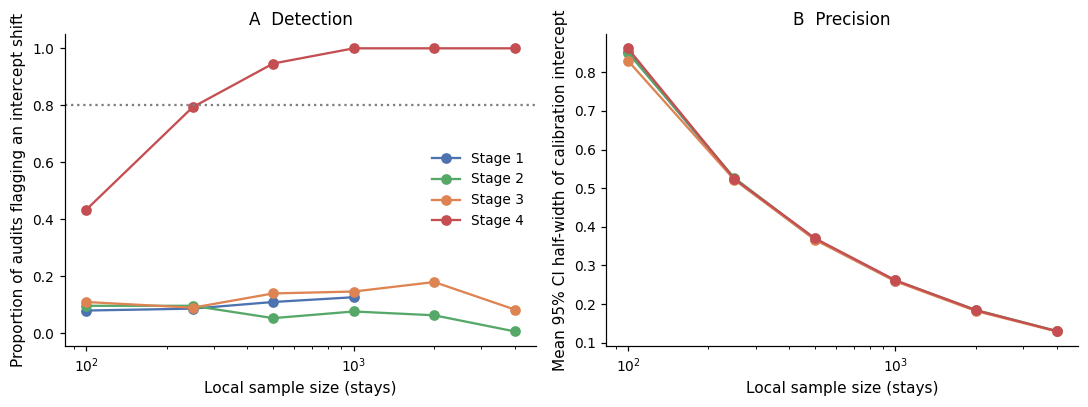

In [94]:

# ======================================================================================
# CELL B  (code)  local audit sample size
# ======================================================================================
# >>> R1+ NEW CELL B: how many local stays does a receiving site need to audit calibration?
# Repeated random subsamples of each stage at local sample sizes n. A site "flags" an intercept shift when the 95% CI
# of the calibration intercept excludes 0 and |intercept| >= 0.20 (a pre-specified, clinically meaningful size).
# Stage 4 is the shifted cohort (true intercept about 0.9); Stage 2 is the control (true intercept about 0), so its
# flag rate is the false-alarm rate.
N_GRID = [100, 250, 500, 1000, 2000, 4000]
B_DRAWS = 300
MIN_ABS_CITL = 0.20
 
def _cal_fit_se(y, p):
    lp = _logit(p)
    a = calibration_intercept(y, p)
    q = _sigmoid(lp + a)
    se_a = 1.0 / np.sqrt(max(np.sum(q * (1 - q)), 1e-9))
    m = LogisticRegression(C=1e10, solver='lbfgs', max_iter=500).fit(lp.reshape(-1, 1), y)
    b0, b1 = float(m.intercept_[0]), float(m.coef_[0, 0])
    q2 = _sigmoid(b0 + b1 * lp); w = q2 * (1 - q2)
    Xd = np.column_stack([np.ones_like(lp), lp])
    try:
        cov = np.linalg.inv(Xd.T @ (Xd * w[:, None]))
        se_b = float(np.sqrt(cov[1, 1]))
    except np.linalg.LinAlgError:
        se_b = np.nan
    return a, se_a, b1, se_b
 
rng_b = np.random.default_rng(RANDOM_STATE)
rows = []
for st in STAGES:
    y_all, p_all = S[st]['y'], S[st]['p_gbm']
    for n in N_GRID:
        if n > len(y_all) // 2:
            continue
        flag, hw_a, hw_b, ev = [], [], [], []
        for _ in range(B_DRAWS):
            j = rng_b.choice(len(y_all), n, replace=False)
            y, p = y_all[j], p_all[j]
            if y.min() == y.max():
                continue
            a, se_a, b1, se_b = _cal_fit_se(y, p)
            flag.append(abs(a) >= MIN_ABS_CITL and abs(a) > 1.96 * se_a)
            hw_a.append(1.96 * se_a); hw_b.append(1.96 * se_b); ev.append(int(y.sum()))
        rows.append({'stage': st, 'n_local': n, 'mean_events': float(np.mean(ev)),
                     'intercept_flag_rate': float(np.mean(flag)),
                     'citl_ci_halfwidth': float(np.mean(hw_a)), 'slope_ci_halfwidth': float(np.nanmean(hw_b)),
                     'true_citl_full_sample': float(calibration_intercept(y_all, p_all))})
R['audit_n'] = pd.DataFrame(rows)
R['audit_n'].to_csv(R1_TABLES / 'S_local_audit_sample_size.csv', index=False)
display(R['audit_n'].round(3))
 
for st in ('Stage 4', 'Stage 2'):
    g = R['audit_n'][R['audit_n']['stage'] == st]
    ok = g[g['intercept_flag_rate'] >= 0.80]
    if st == 'Stage 4':
        print(f"{st} (shifted): smallest local sample with at least 80% detection = "
              f"{int(ok['n_local'].min()) if len(ok) else 'not reached'} stays")
    else:
        print(f"{st} (control): false-alarm rate at n = 500 is "
              f"{g.loc[g['n_local'] == 500, 'intercept_flag_rate'].squeeze():.1%}")
 
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for st, c in zip(STAGES, ['#4c72b0', '#55a868', '#dd8452', '#c44e52']):
    g = R['audit_n'][R['audit_n']['stage'] == st]
    ax[0].plot(g['n_local'], g['intercept_flag_rate'], 'o-', color=c, label=st)
    ax[1].plot(g['n_local'], g['citl_ci_halfwidth'], 'o-', color=c, label=st)
for a_ in ax:
    a_.set_xscale('log'); a_.set_xlabel('Local sample size (stays)'); a_.spines[['top', 'right']].set_visible(False)
ax[0].axhline(0.8, ls=':', c='grey'); ax[0].set_ylabel('Proportion of audits flagging an intercept shift')
ax[1].set_ylabel('Mean 95% CI half-width of calibration intercept'); ax[0].legend(frameon=False)
ax[0].set_title('A  Detection'); ax[1].set_title('B  Precision')
plt.tight_layout()
for ext in ('png', 'pdf'):
    plt.savefig(R1_FIGS / f'FigS3_local_audit_sample_size.{ext}', dpi=300, bbox_inches='tight')
plt.show()

In [95]:
# ======================================================================================
# CELL C  (code)  ICU type and case-mix reweighting
# ======================================================================================
# >>> R1+ NEW CELL C: calibration by ICU type, and a case-mix reweighting check for Stages 3 and 4.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score
 
# ---- C1. calibration by ICU type (first_careunit) ----
_cdm_unit = pd.read_parquet(CFG3.PART1_DIR / 'cdm_unified.parquet', columns=['stay_id', 'first_careunit'])
_cdm_unit['stay_id'] = _cdm_unit['stay_id'].astype(str)
unit_rows = []
for st in ('Stage 3', 'Stage 4'):
    d = S[st]['df']
    if 'first_careunit' in d.columns:
        unit = d['first_careunit'].astype(str).values
    else:
        unit = d[['stay_id']].astype({'stay_id': str}).merge(_cdm_unit, on='stay_id', how='left')['first_careunit'].astype(str).values
    y, p = S[st]['y'], S[st]['p_gbm']
    for u in pd.Series(unit).value_counts().index:
        m = unit == u
        if m.sum() < 300 or y[m].sum() < 20:
            continue
        unit_rows.append({'stage': st, 'unit': u, 'n': int(m.sum()), 'events': int(y[m].sum()),
                          'observed': float(y[m].mean()), 'mean_predicted': float(p[m].mean()),
                          'ece': ece_width(y[m], p[m]),
                          'ece_expected_if_calibrated': null_ece(p[m], max(100, cfg.N_NULL // 2))['null_mean'],
                          'citl': calibration_intercept(y[m], p[m]), 'slope': calibration_slope(y[m], p[m])})
R['by_unit'] = pd.DataFrame(unit_rows)
R['by_unit']['ece_excess'] = R['by_unit']['ece'] - R['by_unit']['ece_expected_if_calibrated']
R['by_unit'].to_csv(R1_TABLES / 'S_calibration_by_icu_type.csv', index=False)
display(R['by_unit'].round(3))
 
# ---- C2. case-mix reweighting: reweight Stage 3 / 4 to the development-site covariate distribution ----
def _wece(y, p, w, n_bins=15):
    idx = np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1]); tot = w.sum(); e = 0.0
    for k in np.unique(idx):
        m = idx == k
        e += w[m].sum() / tot * abs(np.average(p[m], weights=w[m]) - np.average(y[m], weights=w[m]))
    return float(e)
 
def _wcitl(y, p, w):
    lp = _logit(p)
    return float(optimize.brentq(lambda a: np.sum(w * (y - _sigmoid(lp + a))), -15, 15))
 
n_val = len(FEATURE_COLS)
Xref = np.concatenate([design(S[s_]['df'], A['imputer'])[:, :n_val] for s_ in ('Stage 1', 'Stage 2')])
rng_c = np.random.default_rng(RANDOM_STATE)
cm_rows = []
for st in ('Stage 3', 'Stage 4'):
    Xt = design(S[st]['df'], A['imputer'])[:, :n_val]
    ir = rng_c.choice(len(Xref), min(20000, len(Xref)), replace=False)
    it = rng_c.choice(len(Xt), min(20000, len(Xt)), replace=False)
    Xd = np.concatenate([Xref[ir], Xt[it]]); yd = np.r_[np.ones(len(ir)), np.zeros(len(it))]
    sc = StandardScaler().fit(Xd)
    dom = LogisticRegression(C=0.1, max_iter=500)
    p_cv = cross_val_predict(dom, sc.transform(Xd), yd, cv=3, method='predict_proba')[:, 1]
    dom.fit(sc.transform(Xd), yd)
    q = np.clip(dom.predict_proba(sc.transform(Xt))[:, 1], 1e-4, 1 - 1e-4)
    w = q / (1 - q); w = np.minimum(w, np.percentile(w, 99)); w = w / w.mean()
    y, p = S[st]['y'], S[st]['p_gbm']
    cm_rows.append({'stage': st, 'domain_classifier_auroc_cv': float(roc_auc_score(yd, p_cv)),
                    'effective_sample_size': float(w.sum() ** 2 / np.sum(w ** 2)), 'n': len(y),
                    'observed_unweighted': float(y.mean()), 'observed_reweighted': float(np.average(y, weights=w)),
                    'mean_pred_unweighted': float(p.mean()), 'mean_pred_reweighted': float(np.average(p, weights=w)),
                    'ece_unweighted': ece_width(y, p), 'ece_reweighted': _wece(y, p, w),
                    'citl_unweighted': calibration_intercept(y, p), 'citl_reweighted': _wcitl(y, p, w)})
R['casemix'] = pd.DataFrame(cm_rows)
R['casemix'].to_csv(R1_TABLES / 'S_casemix_reweighting.csv', index=False)
display(R['casemix'].round(3).T)
print("Reading: if reweighting to the development-site case-mix leaves ECE and the intercept unchanged, the shift is not "
      "explained by measured case-mix; if both fall towards the internal values, it is.")


,stage,unit,n,events,observed,mean_predicted,ece,ece_expected_if_calibrated,citl,slope,ece_excess
0,Stage 3,Med-Surg ICU,49947,4838,0.097,0.093,0.030,0.003,0.067,0.636,0.027
1,Stage 3,CCU-CTICU,8358,643,0.077,0.078,0.017,0.006,-0.022,0.711,0.011
2,Stage 3,MICU,8104,1012,0.125,0.117,0.038,0.008,0.111,0.624,0.030
3,Stage 3,Neuro ICU,7463,631,0.085,0.056,0.034,0.006,0.578,0.673,0.028
4,Stage 3,Cardiac ICU,6837,744,0.109,0.096,0.029,0.008,0.217,0.676,0.021
5,Stage 3,SICU,6477,505,0.078,0.075,0.028,0.007,0.051,0.628,0.021
6,Stage 3,CTICU,3597,193,0.054,0.064,0.018,0.009,-0.243,0.671,0.010
7,Stage 3,CSICU,2404,208,0.087,0.081,0.024,0.011,0.109,0.708,0.013
8,Stage 4,INID,4132,119,0.029,0.024,0.013,0.005,0.221,0.683,0.009
9,Stage 4,CWIN,3125,454,0.145,0.088,0.064,0.011,0.909,0.557,0.053


,0,1
stage,Stage 3,Stage 4
domain_classifier_auroc_cv,0.972,1.0
effective_sample_size,9485.41,350.831
n,93187,12302
observed_unweighted,0.094,0.095
observed_reweighted,0.088,0.105
mean_pred_unweighted,0.088,0.059
mean_pred_reweighted,0.09,0.083
ece_unweighted,0.027,0.043
ece_reweighted,0.022,0.047


Reading: if reweighting to the development-site case-mix leaves ECE and the intercept unchanged, the shift is not explained by measured case-mix; if both fall towards the internal values, it is.


In [96]:
# >>> R1+ NEW CELL D: patient-level bootstrap CIs for RHR (Reviewer 2, comment 2b).
# Each replicate makes a random stratified 50/50 split, resamples stays with replacement WITHIN each half, fits the
# recalibrator on the resampled fitting half and evaluates it, and the uncalibrated model, on the resampled evaluation
# half. The 2.5th and 97.5th percentiles therefore reflect both sampling and split variability.
from sklearn.model_selection import train_test_split
B_RHR = 200
rng_d = np.random.default_rng(RANDOM_STATE + 7)
rows = []
for st in ('Stage 2', 'Stage 3', 'Stage 4'):
    y_all, p_all = S[st]['y'], S[st]['p_gbm']
    for mname in ('citl', 'logistic', 'isotonic', 'beta', 'temperature', 'platt'):
        rhr, post, pre = [], [], []
        for b in range(B_RHR):
            tr, te = train_test_split(np.arange(len(y_all)), test_size=0.5, stratify=y_all,
                                      random_state=int(rng_d.integers(1_000_000_000)))
            tr = rng_d.choice(tr, len(tr), replace=True); te = rng_d.choice(te, len(te), replace=True)
            if y_all[tr].min() == y_all[tr].max():
                continue
            try:
                q = RECAL_METHODS[mname](p_all[tr], y_all[tr])(p_all[te])
            except Exception:
                continue
            e0 = ece_width(y_all[te], p_all[te]); e1 = ece_width(y_all[te], q)
            rhr.append(1 - e1 / e0); post.append(e1); pre.append(e0)
        rows.append({'stage': st, 'method': mname, 'replicates': len(rhr),
                     'ece_pre_median': np.median(pre), 'ece_post_median': np.median(post),
                     'ece_post_lo': np.percentile(post, 2.5), 'ece_post_hi': np.percentile(post, 97.5),
                     'rhr_median': np.median(rhr), 'rhr_lo': np.percentile(rhr, 2.5), 'rhr_hi': np.percentile(rhr, 97.5)})
R['rhr_boot'] = pd.DataFrame(rows)
R['rhr_boot'].to_csv(R1_TABLES / 'S_rhr_patient_bootstrap.csv', index=False)
display(R['rhr_boot'].round(3))


,stage,method,replicates,ece_pre_median,ece_post_median,ece_post_lo,ece_post_hi,rhr_median,rhr_lo,rhr_hi
0,Stage 2,citl,200,0.028,0.028,0.022,0.034,0.003,-0.060,0.081
1,Stage 2,logistic,200,0.028,0.011,0.007,0.017,0.599,0.401,0.774
2,Stage 2,isotonic,200,0.028,0.012,0.006,0.017,0.586,0.349,0.791
3,Stage 2,beta,200,0.028,0.011,0.006,0.017,0.604,0.377,0.770
4,Stage 2,temperature,200,0.028,0.019,0.014,0.024,0.322,0.066,0.492
5,Stage 2,platt,200,0.027,0.033,0.025,0.040,-0.207,-0.793,0.210
6,Stage 3,citl,200,0.028,0.028,0.025,0.031,-0.022,-0.068,0.042
7,Stage 3,logistic,200,0.027,0.004,0.003,0.007,0.838,0.739,0.902
8,Stage 3,isotonic,200,0.027,0.005,0.003,0.009,0.812,0.692,0.904
9,Stage 3,beta,200,0.027,0.005,0.003,0.007,0.836,0.754,0.902


In [97]:
# >>> R1+ NEW CELL E: local-audit detection at controlled intercept shifts (0.1 to 0.5), to test the 0.2 check
# beyond the single large Stage 4 shift. Stage 2 (intercept close to 0) is used with its predictions shifted on the
# logit scale by -delta after centring, so outcomes and case mix are real and the true intercept equals delta.
DELTAS = [0.0, 0.1, 0.2, 0.3, 0.5]
rng_e = np.random.default_rng(RANDOM_STATE + 11)
y_all, p_all = S['Stage 2']['y'], S['Stage 2']['p_gbm']
a0 = calibration_intercept(y_all, p_all)   # centre Stage 2 so delta = 0 is calibrated in the large exactly
lp0 = _logit(p_all) + a0
rows = []
for delta in DELTAS:
    ps = _sigmoid(lp0 - delta)
    true_a = calibration_intercept(y_all, ps)
    for n in N_GRID:
        if n > len(y_all) // 2:
            continue
        flag, sig, hw = [], [], []
        for _ in range(B_DRAWS):
            j = rng_e.choice(len(y_all), n, replace=False)
            y, p = y_all[j], ps[j]
            if y.min() == y.max():
                continue
            a, se_a, b1, se_b = _cal_fit_se(y, p)
            sig.append(abs(a) > 1.96 * se_a)
            flag.append(abs(a) >= MIN_ABS_CITL and abs(a) > 1.96 * se_a)
            hw.append(1.96 * se_a)
        rows.append({'shift_delta': delta, 'true_intercept': true_a, 'n_local': n,
                     'ci_excludes_0_rate': float(np.mean(sig)), 'flag_rate_ge_0_20': float(np.mean(flag)),
                     'citl_ci_halfwidth': float(np.mean(hw))})
R['audit_shift'] = pd.DataFrame(rows)
R['audit_shift'].to_csv(R1_TABLES / 'S_local_audit_controlled_shifts.csv', index=False)
display(R['audit_shift'].pivot(index='n_local', columns='shift_delta', values='ci_excludes_0_rate').round(2))
display(R['audit_shift'].pivot(index='n_local', columns='shift_delta', values='flag_rate_ge_0_20').round(2))


shift_delta,0.0,0.1,0.2,0.3,0.5
n_local,,,,,
100,0.08,0.11,0.12,0.16,0.22
250,0.08,0.11,0.14,0.23,0.44
500,0.09,0.14,0.22,0.35,0.72
1000,0.09,0.15,0.36,0.59,0.95
2000,0.08,0.19,0.55,0.86,1.00
4000,0.06,0.34,0.87,1.00,1.00


shift_delta,0.0,0.1,0.2,0.3,0.5
n_local,,,,,
100,0.08,0.11,0.12,0.16,0.22
250,0.08,0.11,0.14,0.23,0.44
500,0.09,0.14,0.22,0.35,0.72
1000,0.09,0.15,0.36,0.59,0.95
2000,0.06,0.15,0.48,0.84,1.00
4000,0.00,0.05,0.52,0.96,1.00


In [98]:
# >>> R1 NEW CELL: revised figures (Fig 1, 2B, 3A, 3B, 4, 5; Supplementary Figs S1, S2).
import shutil
_att = {"MIMIC-IV": {"ICU stays (merged)": 73181, "Age >= 18 y": 73181, "First ICU stay per patient": 50920, "ICU LOS >= 24 h": 40167},
        "eICU-CRD": {"Unit stays": 200859, "Age >= 18 y": 200234, "First unit stay per patient": 138868, "ICU LOS >= 24 h": 93187},
        "SICdb":    {"Cases": 27350, "Age >= 18 y": 27223, "First case per patient": 21442, "ICU LOS >= 24 h": 14688}}
# Replace the numbers above if your rerun prints different attrition counts.
fig1_consort(_att, P1['cdm_sha256'], R1_FIGS / 'Fig1_cohort_flow')
_shap = CFG3.PART2_DIR / 'figures' / 'fig5a_shap_top20.png'
if _shap.exists():
    shutil.copy(_shap, R1_FIGS / 'Fig2A_shap_top20.png')
fig2b_hospitals(R['hospitals'], float(R['stage_table'].set_index('stage').loc['Stage 1', 'ece']), R1_FIGS / 'Fig2B_per_hospital_ece')
fig3_missingness(R['missingness'], R['mdl'], R1_FIGS / 'Fig3A_missingness', R1_FIGS / 'Fig3B_mdl_auroc')
fig4_reliability(S, R1_FIGS / 'Fig4_reliability_by_stage')
fig5_summary(R['stage_table'], R['cdh50'], R['subgroup_table'], R['recal'], R1_FIGS / 'Fig5_summary')
figS_dca(R['dca'], R1_FIGS / 'FigS1_decision_curves')
figS_fitsize(R['fit_size'], R1_FIGS / 'FigS2_recalibration_fit_size')
print(sorted(p.name for p in R1_FIGS.glob('*.png')))


['Fig1_cohort_flow.png', 'Fig2A_shap_top20.png', 'Fig2B_per_hospital_ece.png', 'Fig3A_missingness.png', 'Fig3B_mdl_auroc.png', 'Fig4_reliability_by_stage.png', 'Fig5_summary.png', 'FigS1_decision_curves.png', 'FigS2_recalibration_fit_size.png', 'FigS3_local_audit_sample_size.png']


In [102]:
# >>> R1 NEW CELL: numbers for the «KEY» placeholders in the revised manuscript and response letter.
import sklearn, lightgbm
N = build_numbers(R)
N['SKLEARN_VERSION'] = sklearn.__version__; N['LIGHTGBM_VERSION'] = lightgbm.__version__
(R1_DIR / 'revision_numbers.json').write_text(json.dumps(N, indent=1, sort_keys=True))
manifest_r1 = {'created_utc': pd.Timestamp.utcnow().isoformat(),
               'part1_cdm_sha256': P1['cdm_sha256'], 'part2_gbm_sha256': P2['gbm_sha256'],
               'tables_sha256': {p.name: sha256_file(p) for p in sorted(R1_TABLES.glob('*.csv'))},
               'settings': {k: getattr(CFG3, k) for k in ('N_BOOTSTRAP', 'N_REP', 'N_NULL')},
               'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                            'scikit-learn': sklearn.__version__, 'lightgbm': lightgbm.__version__}}
(R1_DIR / 'manifest_r1.json').write_text(json.dumps(manifest_r1, indent=2, default=str))
print(len(N), 'placeholder values written to', R1_DIR / 'revision_numbers.json')


869 placeholder values written to C:\CALA_Output\revision_r1\revision_numbers.json


In [103]:
# >>> R1 NEW CELL: fill the placeholders in the Word files and build the supplement.
# Put ACI_Manuscript_R1_tracked.docx, ACI_Manuscript_R1_clean.docx and Response_to_Reviewers_R1.docx in the
# same folder as this notebook. Each is written as *_FILLED.docx. Turquoise sentences are printed for you
# to re-read; when done, set CLEAR_CHECKS = True and run this cell again.
CLEAR_CHECKS = False
import json
import re
import shutil
import tempfile
import zipfile
from pathlib import Path

W = "http://schemas.openxmlformats.org/wordprocessingml/2006/main"
PH = re.compile(r"«([A-Za-z0-9_]+)»")


def process_xml(xml: str, numbers: dict, clear_checks: bool, missing: set, checks: list) -> str:
    from lxml import etree
    root = etree.fromstring(xml.encode("utf-8"))
    q = lambda t: f"{{{W}}}{t}"
    for p in root.iter(q("p")):
        ts = [t for t in p.iter(q("t"), q("delText"))]
        if not ts:
            continue
        # report turquoise (cyan) sentences
        cyan_txt = []
        for r in p.iter(q("r")):
            hl = r.find(f"{q('rPr')}/{q('highlight')}")
            if hl is not None and hl.get(q("val")) == "cyan":
                cyan_txt.append("".join(t.text or "" for t in r.iter(q("t"))))
                if clear_checks:
                    hl.getparent().remove(hl)
        if cyan_txt and "".join(cyan_txt).strip():
            checks.append("".join(cyan_txt).strip())
        full = "".join(t.text or "" for t in ts)
        if "«" not in full:
            continue
        # character -> (t element index, offset)
        owners = []
        for i, t in enumerate(ts):
            owners += [i] * len(t.text or "")
        new_texts = [list(t.text or "") for t in ts]
        for m in reversed(list(PH.finditer(full))):
            key = m.group(1)
            if key not in numbers:
                missing.add(key)
                continue
            a, b = m.start(), m.end()
            first = owners[a]
            # offset within first element
            off = a - sum(len(ts[j].text or "") for j in range(first))
            # clear placeholder chars across elements
            for c in range(a, b):
                j = owners[c]
                o = c - sum(len(ts[k].text or "") for k in range(j))
                new_texts[j][o] = ""
            new_texts[first][off] = str(numbers[key])
            r = ts[first].getparent()
            hl = r.find(f"{q('rPr')}/{q('highlight')}")
            if hl is not None and hl.get(q("val")) == "yellow":
                hl.getparent().remove(hl)
        for t, chars in zip(ts, new_texts):
            t.text = "".join(chars)
    return etree.tostring(root, xml_declaration=True, encoding="UTF-8", standalone=True).decode("utf-8")


def fill(docx: Path, numbers: dict, clear_checks: bool):
    out = docx.with_name(docx.stem + "_FILLED.docx")
    missing, checks = set(), []
    with zipfile.ZipFile(docx) as zin, zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as zout:
        for item in zin.infolist():
            data = zin.read(item.filename)
            if item.filename.startswith("word/") and item.filename.endswith(".xml") and (
                    b"\xc2\xab" in data or b'w:val="cyan"' in data):
                data = process_xml(data.decode("utf-8"), numbers, clear_checks, missing, checks).encode("utf-8")
            zout.writestr(item, data)
    print(f"\n{docx.name} -> {out.name}")
    if checks:
        print(f"  Re-read these {len(checks)} turquoise passages against the new results:")
        for c in checks:
            print("   -", c[:220])
    if missing:
        print(f"  NOT FILLED ({len(missing)}): {', '.join(sorted(missing))}")
    else:
        print("  All placeholders filled.")



_numbers = json.loads((R1_DIR / 'revision_numbers.json').read_text())
for _f in CFG3.DOCX_TO_FILL:
    if Path(_f).exists():
        fill(Path(_f), _numbers, CLEAR_CHECKS)
    else:
        print('not found (skipped):', _f)



ACI_Manuscript_R1_tracked.docx -> ACI_Manuscript_R1_tracked_FILLED.docx
  Re-read these 12 turquoise passages against the new results:
   - changed on transport to other institutions, most at the Austrian centre
   - missingness patterns carried a small, non-random amount of demographic information, most apparent at the US academic site and consistent with institutional documentation practice as a source of bias,24 rather than strong
   - , so sample-size bias explains little of the external differences
   - , so most of the Stage 4 error reflected a shift in baseline risk
   - Net benefit of recalibrated predictions was at least that of raw predictions across clinically plausible thresholds
   - ; the ordering of stages and the direction of Stage 4 miscalibration were unchanged
   - It changed on transport to other institutions, most at the European centre (ECE  against 0.028 internally)
   - The larger change on transport than over time
   - ; adding age and sex did not remove them


In [ ]:
#!pip install python-docx

In [104]:
# >>> R1 NEW CELL: Supplementary_Material_R1.docx from the revision tables (paste your TRIPOD+AI
#     checklist in as Table S1 afterwards).
import argparse
from pathlib import Path

import pandas as pd
from docx import Document
from docx.enum.section import WD_ORIENT
from docx.shared import Pt, Inches

FONT = "Times New Roman"


def _style(doc):
    st = doc.styles["Normal"]; st.font.name = FONT; st.font.size = Pt(10)
    for s in ("Heading 1", "Heading 2"):
        doc.styles[s].font.name = FONT


def _fmt(v, col):
    if isinstance(v, (bool,)) or str(v) in ("True", "False"):
        return "Yes" if str(v) == "True" else "No"
    if isinstance(v, float):
        if pd.isna(v):
            return "NA"
        if col in ("n", "events", "n_fit", "n_eval", "n_hospitals", "stays_with_data", "n_rows", "deaths",
                   "inhosp_n", "icu_n", "oneyear_n", "reference_id", "n_deaths", "rep"):
            return f"{int(round(v)):,}"
        if any(k in col for k in ("sdii", "rhr", "cdc", "recovery")) or col in ("value",) and abs(v) > 5:
            return f"{v:.2f}"
        if "pct" in col or "rate" in col or col in ("flagged_pct", "sensitivity", "specificity", "ppv"):
            return f"{100 * v:.1f}%" if abs(v) <= 1 else f"{v:.3f}"
        return f"{v:.3f}"
    if isinstance(v, (int,)):
        return f"{v:,}"
    return str(v)


def add_table(doc, title, df, note=None, cols=None, rename=None):
    doc.add_paragraph().add_run(title).bold = True
    if cols:
        df = df[[c for c in cols if c in df.columns]]
    show = df.rename(columns=rename or {})
    t = doc.add_table(rows=1, cols=len(show.columns)); t.style = "Table Grid"
    for i, c in enumerate(show.columns):
        cell = t.rows[0].cells[i]; cell.text = ""; r = cell.paragraphs[0].add_run(str(c)); r.bold = True
        r.font.size = Pt(8.5)
    for _, row in df.iterrows():
        cells = t.add_row().cells
        for i, c in enumerate(df.columns):
            cells[i].text = ""
            r = cells[i].paragraphs[0].add_run(_fmt(row[c], c)); r.font.size = Pt(8.5)
    if note:
        p = doc.add_paragraph(); r = p.add_run(note); r.italic = True; r.font.size = Pt(8.5)
    doc.add_paragraph()


def main(r1: Path, out: Path):
    T = r1 / "tables"; F = r1 / "figures"
    rd = lambda n: pd.read_csv(T / f"{n}.csv")
    doc = Document(); _style(doc)
    sec = doc.sections[0]; sec.orientation = WD_ORIENT.LANDSCAPE
    sec.page_width, sec.page_height = sec.page_height, sec.page_width
    for m in ("left_margin", "right_margin", "top_margin", "bottom_margin"):
        setattr(sec, m, Inches(0.7))
    doc.add_heading("Supplementary Material (revision R1)", 1)
    doc.add_paragraph("Special Topic AI in CDS: A Multi-Database Calibration and Recalibration Audit for Safe "
                      "Deployment of Imported ICU Mortality Models (CALA). ACI-2026-07-RA-0294.R1")

    doc.add_heading("Supplementary Methods", 2)
    for txt in [
        "S-M1. Calibration measures. Calibration intercept (calibration-in-the-large): a in logit P(Y = 1) = a + logit(p), "
        "estimated by maximum likelihood with logit(p) as offset; 0 is ideal, a > 0 indicates under-prediction. Calibration "
        "slope: b in logit P(Y = 1) = a + b·logit(p); 1 is ideal. ECE = Σ_k (n_k/n)·|mean(p)_k − mean(y)_k| over 15 "
        "equal-width bins (primary), 10 or 20 equal-width bins, or 15 equal-mass bins. ICI: mean |s(p_i) − p_i|, where s is a "
        "flexible calibration curve from logistic regression of y on a restricted cubic spline (4 knots at the 5th, 35th, "
        "65th and 95th percentiles) of logit(p); E50 and E90 are the median and 90th percentile of the same differences.",
        "S-M2. ECE expected under perfect calibration. For a set of predictions p_1..p_n, outcomes y*_i ~ Bernoulli(p_i) were "
        "simulated 500 times and the ECE computed each time. Because the predictions are calibrated for the simulated "
        "outcomes by construction, the mean simulated ECE is the ECE that finite-sample binning noise alone produces for that "
        "sample size and prediction distribution; null-corrected (excess) ECE = observed ECE − this mean.",
        "S-M3. Summary measures. ΔECE_s = ECE_s − ECE_1. Temporal trend: ln(ECE_t) = β0 + β1(t − 2009) fitted to four MIMIC-IV "
        "periods (2008-2010, 2011-2013 from the Stage 1 test set; 2014-2016, 2017-2019 from Stage 2) at midpoints 2009, 2012, "
        "2015, 2018; β1 in natural-log ECE per calendar year; CDH-50 = ln 2/β1 if β1 > 0. CDC = ΔECE_4/max(D, ε) with D = "
        "ΔECE_2 (primary), the largest single period minus ECE_1 (original specification) or the largest Stage 2 period minus "
        "ECE_1, and ε ∈ {0.0025, 0.005, 0.01}. SDII_s = range_g(ECE_g,s)/range_g(ECE_g,1) over Female/Male × <65/≥65 years, "
        "using raw ECE, null-corrected ECE or ICI. RHR = 1 − ECE_post/ECE_pre; recovery toward baseline = "
        "(ECE_pre − ECE_post)/(ECE_pre − ECE_1), reported when ECE_pre − ECE_1 > 0.005. Bootstrap CIs (500 replicates) "
        "resample every component (Stage 1, each calendar period, Stage 2 and the comparison stage) independently.",
        "S-M4. Recalibration. Intercept-only: logit(p') = logit(p) + a. Logistic: logit(p') = a + b·logit(p). Platt (as in the "
        "original submission): p' = σ(a + b·p). Isotonic: monotone non-decreasing step function, clipped to [0, 1]. Temperature: "
        "p' = σ(logit(p)/T), T minimizing negative log-likelihood. Beta: p' = σ(a·ln p − b·ln(1 − p) + c). Repeated splits: 200 "
        "stratified 50/50 splits (seeds 42 to 241). Fit-size curve: fixed evaluation half; recalibrators fitted on random "
        "subsamples of 100, 250, 500, 1,000, 2,000 and 4,000 stays of the fitting half (200 draws per size) and on the full half.",
    ]:
        doc.add_paragraph(txt)

    doc.add_paragraph().add_run("Table S1. TRIPOD+AI reporting checklist. [Insert the authors' existing checklist here and "
                                "update section references for the revision.]").bold = True

    st_g = rd("T2_stage_metrics_GBM").assign(model="GBM (frozen, class-weighted)")
    st_w = rd("T2_stage_metrics_LR_weighted").assign(model="Logistic regression (class-weighted, original)")
    frames = [st_g, st_w]
    if (T / "T2_stage_metrics_LR_unweighted.csv").exists():
        frames.append(rd("T2_stage_metrics_LR_unweighted").assign(model="Logistic regression (unweighted)"))
    diag = pd.concat(frames)
    diag["discrimination_lost"] = diag["auroc"] < 0.60
    add_table(doc, "Table S2. Discrimination diagnostic by stage and model.", diag,
              "A stage-model combination with AUROC below 0.60 is flagged as degenerate: a low ECE after recalibration then "
              "reflects prediction of the base rate rather than recovery of a useful model.",
              cols=["model", "stage", "auroc", "ece", "discrimination_lost"],
              rename={"auroc": "AUROC", "ece": "ECE", "discrimination_lost": "AUROC < 0.60 (degenerate)"})
    add_table(doc, "Table S3. Median versus iterative (MICE) imputation, 5,000-stay training subsample, Stage 1 test set.",
              pd.DataFrame({"imputer": ["Median", "Iterative (MICE)"], "auroc": [0.8148, 0.8178],
                            "brier": [0.0804, 0.0790], "ece": [0.0434, 0.0392]}),
              "Unchanged from the original submission; reformatted to three decimals.",
              rename={"auroc": "AUROC", "brier": "Brier", "ece": "ECE"})
    add_table(doc, "Table S4. Hosmer-Lemeshow test at increasing sample sizes (Stage 1, GBM, 50 subsamples per size).",
              pd.DataFrame({"sample_size": [200, 500, 1000, 2000, 3000, 3288],
                            "chi2_mean": [16.022, 23.339, 27.399, 44.533, 61.040, 67.283],
                            "p_value_median": ["0.063", "0.015", "<0.001", "<0.001", "<0.001", "<0.001"],
                            "p_below_001_rate": [0.16, 0.30, 0.52, 0.96, 1.00, 1.00]}),
              "Unchanged from the original submission (formerly Table S5); reformatted.",
              rename={"sample_size": "n", "chi2_mean": "Mean chi-square", "p_value_median": "Median p",
                      "p_below_001_rate": "Share with p < 0.001"})
    add_table(doc, "Table S5. Outcome definitions: SICdb in-hospital death rules evaluated on the full database, and outcome rates by cohort.",
              rd("S_sicdb_outcome_rules"),
              "Published in-hospital mortality of the full SICdb release: 7.9% (Rodemund et al., Sci Data 2024). The selected rule "
              "is used for all analyses. 'Any recorded death' was the definition used in error in the original submission and equals "
              "one-year mortality.", rename={"full_db_rate": "Rate (full database)", "icu_deaths_not_captured": "ICU deaths not captured"})
    add_table(doc, "Table S5 (continued). In-hospital, ICU and one-year mortality by database (analysis cohorts).", rd("T1_outcomes_by_database"))
    add_table(doc, "Table S6a. eICU-CRD vital-sign source tables (revised extraction).", rd("S_eicu_vital_source_tables"))
    add_table(doc, "Table S6b. eICU-CRD median vital-sign observations per stay in 24 h before hourly harmonization.",
              rd("S_eicu_raw_counts_before_hourly"))
    add_table(doc, "Table S6c. SICdb laboratory codes, units and conversions.", rd("S_sicdb_lab_codes_units"))
    add_table(doc, "Table S6d. Unit check: median of each variable's 24-hour mean by database and ratio to MIMIC-IV.",
              rd("S_unit_qc_by_database"), "Ratios outside 0.67 to 1.5 are flagged for review.")
    add_table(doc, "Table S7. Original submission versus corrected extraction (frozen GBM).", rd("S_original_vs_corrected"),
              "Original: SICdb outcome = any recorded death (one-year), SICdb urea not converted, eICU-CRD without non-invasive "
              "pressure or nurse-charted temperature and with 5-minute counts.")
    add_table(doc, "Table S8. Calibration by stage under alternative ECE specifications and binning-free measures (GBM).",
              rd("T2_stage_metrics_GBM"),
              cols=["stage", "n", "events", "ece", "ece_w10", "ece_w20", "ece_mass15", "ece_null_mean", "ece_excess",
                    "ici", "e50", "e90", "citl", "slope", "mce"],
              rename={"ece": "ECE 15 equal-width", "ece_w10": "ECE 10", "ece_w20": "ECE 20", "ece_mass15": "ECE 15 equal-mass",
                      "ece_null_mean": "ECE expected if calibrated", "ece_excess": "Excess ECE", "ici": "ICI", "citl": "Intercept",
                      "slope": "Slope", "mce": "MCE"})
    add_table(doc, "Table S9. Continental Drift Coefficient: denominator definitions, floors and the absolute difference (full joint bootstrap).",
              rd("T4_cdc_sensitivity"),
              cols=["metric", "denominator", "floor", "statistic", "value", "lo", "hi", "numerator", "denominator_value",
                    "denominator_lo", "denominator_hi", "share_of_boots_at_floor"])
    add_table(doc, "Table S10a. SDII and subgroup ECE range with bootstrap 95% CIs (raw ECE, null-corrected ECE, ICI).", rd("T4_sdii_bootstrap"))
    add_table(doc, "Table S10b. Change in subgroup ECE/ICI from Stage 1 with bootstrap 95% CIs.", rd("T5_subgroup_delta_bootstrap"))
    rec = rd("T6_recalibration_repeated_splits").assign(model="GBM")
    extra = [rd(n).assign(model=m) for n, m in (("S_recalibration_LR_unweighted", "LR unweighted"),
                                                ("S_recalibration_LR_weighted", "LR weighted")) if (T / f"{n}.csv").exists()]
    add_table(doc, "Table S11. Recalibration over 200 repeated 50/50 splits, all models.", pd.concat([rec] + extra),
              cols=["model", "stage", "method", "ece_pre", "ece_post", "ece_post_lo", "ece_post_hi", "ece_mass_post",
                    "ici_post", "rhr", "rhr_lo", "rhr_hi", "recovery_to_baseline", "auroc_post"])
    add_table(doc, "Table S12. Recalibration fitted on smaller local samples (fixed evaluation half; 200 draws per size).",
              rd("S_recalibration_fit_size"))
    add_table(doc, "Table S13. Subgroup calibration after global recalibration (mean over repeated splits).",
              rd("S_recalibration_by_subgroup"))
    add_table(doc, "Table S14. Threshold-based analysis at 10%, 20% and 30% risk (evaluation half for Stages 2 to 4).",
              rd("S_threshold_analysis"))
    add_table(doc, "Table S15. Sensitivity models retrained on the same partition (frozen primary model unchanged).",
              rd("S_sensitivity_models"),
              cols=["model", "stage", "auroc", "auroc_lo", "auroc_hi", "ece", "ece_lo", "ece_hi", "ici", "citl", "slope",
                    "delta_ece_vs_stage1", "sdii"])
    hs = pd.read_csv(T / "S_per_hospital_summary.csv").T.reset_index()
    hs.columns = ["measure", "value"]
    add_table(doc, "Table S16. Per-hospital calibration within eICU-CRD and single-centre benchmark for SICdb.", hs)
    add_table(doc, "Table S17. MDL-AUROC with permutation null.", rd("T3_mdl_auroc_permutation"))
    for fig, cap in (("FigS1_decision_curves.png", "Figure S1. Decision curves for raw and recalibrated predictions by stage."),
                     ("FigS2_recalibration_fit_size.png", "Figure S2. Recalibration performance by local fitting sample size.")):
        if (F / fig).exists():
            doc.add_paragraph().add_run(cap).bold = True
            doc.add_picture(str(F / fig), width=Inches(9.0))
    doc.save(out)
    print("written", out)



main(R1_DIR, R1_DIR / 'Supplementary_Material_R1.docx')


written C:\CALA_Output\revision_r1\Supplementary_Material_R1.docx


## 3.15 Persist Artifacts and Extended Hash Chain

We persist the four metric tables, all figures, and a `manifest_part3.json` that closes the chain (Part 1 CDM hash → Part 2 GBM hash → Part 3 results hash).

In [105]:
def persist_part3(cfg: CALA3Config, chain_p1: dict, chain_p2: dict,
                  cala_metrics: dict) -> dict:
    """Save Part 3 manifest with closed hash chain."""
    log_section("Persisting Part 3 artifacts")

    # Hash Part 3's main results table (Table 2) as the chain anchor
    t2_path = cfg.TABLES_DIR / 'table2_publication.csv'
    t3_path = cfg.TABLES_DIR / 'table3_cala_metrics.csv'
    h2 = sha256_file(t2_path)
    h3 = sha256_file(t3_path)

    manifest3 = {
        'created_utc': pd.Timestamp.utcnow().isoformat(),
        'chain': {
            'part1_cdm_sha256': chain_p1['cdm_sha256'],
            'part2_gbm_sha256': chain_p2['gbm_sha256'],
            'part3_table2_sha256': h2,
            'part3_table3_sha256': h3,
        },
        'baseline_ece_gbm':      cala_metrics['baseline_ece'],
        'temporal_max_ece_gbm':  cala_metrics['temporal_max_ece'],
        'continental_ece_gbm':   cala_metrics['continental_ece'],
        'cdh50_years':           cala_metrics['cdh50'],
        'cdh50_ci':              cala_metrics['cdh50_ci'],
        'cdc':                   cala_metrics['cdc'],
        'cdc_ci':                cala_metrics['cdc_ci'],
        'sdii_by_stage':         cala_metrics['sdii_by_stage'],
        'best_rhr_per_stage':    cala_metrics['best_rhr_per_stage'],
        'stage_n': {
            'stage1_dev_test':       int(scores['stage1_dev_test']['n']),
            'stage2_t_temporal':     int(scores['stage2_t_temporal']['n']),
            'stage3_t_site':         int(scores['stage3_t_site']['n']),
            'stage4_t_continental':  int(scores['stage4_t_continental']['n']),
        },
        'n_recalibration_methods': len(cfg.RECAL_METHODS),
        'random_state': RANDOM_STATE,
    }
    with open(cfg.PART3_DIR / 'manifest_part3.json', 'w') as f:
        json.dump(manifest3, f, indent=2, default=str)

    logger.info(f"  Part 3 artifacts at: {cfg.PART3_DIR}")
    logger.info(f"  Table 2 SHA-256:    {h2[:16]}...")
    logger.info(f"  Table 3 SHA-256:    {h3[:16]}...")
    return manifest3

# Build the CALA metrics dict.
# CDH-50 fields collapse to the "stable" string when no decay is detected
# (slope <= 0 in the log-ECE regression). This makes the manifest readable
# and prevents the astronomical bootstrap upper bound (~20,000 years) from
# appearing as if it were a meaningful clinical estimate.
cdh_decayed = np.isfinite(cdh_fit['cdh50_years']) and cdh_fit['slope'] > 0


cala_metrics = {
    'baseline_ece':     float(ece_baseline),
    'temporal_max_ece': float(ece_temporal_max),
    'continental_ece': float(ece_continental),
    'cdh50':            (float(cdh_fit['cdh50_years']) if cdh_decayed
                         else "stable (>100 years)"),
    'cdh50_ci':         ([float(cdh_lo), float(cdh_hi)] if cdh_decayed
                         else "stable (>100 years)"),
    'cdh50_slope':      float(cdh_fit['slope']),
    'cdh50_r_squared':  float(cdh_fit['r_squared']),
    'cdc':              float(cdc_point),
    'cdc_ci':           [float(cdc_lo), float(cdc_hi)],
    'cdc_denominator_floor': 0.005,
    'sdii_by_stage':    dict(zip(sdii_df['stage'].tolist(),
                                  sdii_df['sdii'].tolist())),
    'best_rhr_per_stage': {
        stage: {'method': rhr_pivot.loc[(stage, 'GBM')].idxmax(),
                'rhr':    float(rhr_pivot.loc[(stage, 'GBM')].max())}
        for stage in rhr_pivot.index.get_level_values(0).unique()
        if (stage, 'GBM') in rhr_pivot.index
    },
}

manifest3 = persist_part3(CFG3, P1, P2, cala_metrics)

print("\n" + "=" * 74)
print(" CALA Part 3 complete -- manuscript-grade results are ready.")
print("=" * 74)
print(f"\n Baseline (Stage 1) ECE  : {ece_baseline:.4f}")
print(f" Stage 4 (continental)   : {ece_continental:.4f}")
print(f" Stage 4 / Stage 1 ratio : {ece_continental / max(ece_baseline, 1e-10):.1f}x")
print()
if cdh_decayed:
    print(f" CDH-50: {cdh_fit['cdh50_years']:.1f} yr  [{cdh_lo:.1f}, {cdh_hi:.1f}]")
else:
    print(f" CDH-50: stable (>100 yr)  -- slope = {cdh_fit['slope']:+.4f}/yr")
print(f" CDC   : {cdc_point:.2f}  [{cdc_lo:.2f}, {cdc_hi:.2f}]")
for stage in ['Stage 2', 'Stage 3', 'Stage 4']:
    sdii_val = sdii_df.loc[sdii_df['stage'] == stage, 'sdii'].iloc[0]
    print(f" SDII {stage}: {sdii_val:.2f}")
print()
print(f" Best RHR at Stage 4 (continental):")
best_method = rhr_pivot.loc[('Stage 4: Continental', 'GBM')].idxmax()
best_rhr    = rhr_pivot.loc[('Stage 4: Continental', 'GBM')].max()
print(f"   {best_method:<12s} RHR = {best_rhr:.2f}")
print()
print(f" Full hash chain:")
print(f"   Part 1 CDM SHA-256:  {P1['cdm_sha256'][:32]}...")
print(f"   Part 2 GBM SHA-256:  {P2['gbm_sha256'][:32]}...")
print(f"   Part 3 Table 2 hash: {manifest3['chain']['part3_table2_sha256'][:32]}...")
print(f"   Part 3 Table 3 hash: {manifest3['chain']['part3_table3_sha256'][:32]}...")
print()
print(f" Manuscript artifacts:")
print(f"   Tables : {CFG3.TABLES_DIR}")
print(f"   Figures: {CFG3.FIGURES_DIR}")
print(f"   Manifest: {CFG3.PART3_DIR / 'manifest_part3.json'}")
print("=" * 74)

01:43:12 | INFO    | ==========================================================================
01:43:12 | INFO    | PERSISTING PART 3 ARTIFACTS
01:43:12 | INFO    | ==========================================================================
01:43:12 | INFO    |   Part 3 artifacts at: C:\CALA_Output\part3_artifacts
01:43:12 | INFO    |   Table 2 SHA-256:    a7836aab715891b9...
01:43:12 | INFO    |   Table 3 SHA-256:    596197b3c944c084...



 CALA Part 3 complete -- manuscript-grade results are ready.

 Baseline (Stage 1) ECE  : 0.0276
 Stage 4 (continental)   : 0.0431
 Stage 4 / Stage 1 ratio : 1.6x

 CDH-50: stable (>100 yr)  -- slope = -0.0336/yr
 CDC   : 1.92  [0.59, 3.09]
 SDII Stage 2: 0.60
 SDII Stage 3: 0.83
 SDII Stage 4: 1.35

 Best RHR at Stage 4 (continental):
   isotonic     RHR = 0.76

 Full hash chain:
   Part 1 CDM SHA-256:  9f4e362835235be3e9ae728e7f72d94f...
   Part 2 GBM SHA-256:  885cb2f8fb6fcf37a3be7ce83ddd3d51...
   Part 3 Table 2 hash: a7836aab715891b9aa7884dba572ad9f...
   Part 3 Table 3 hash: 596197b3c944c0845a2b22b48c2db103...

 Manuscript artifacts:
   Tables : C:\CALA_Output\part3_artifacts\tables
   Figures: C:\CALA_Output\part3_artifacts\figures
   Manifest: C:\CALA_Output\part3_artifacts\manifest_part3.json
